## CELL 1: library import

In [1]:
# ============================================
# CELL 1: IMPORTS 100%
# ============================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os
import json
import joblib
warnings.filterwarnings('ignore')

# ML
from sklearn.preprocessing import (
    LabelEncoder, StandardScaler,
    OrdinalEncoder
)
from sklearn.model_selection import (
    train_test_split, StratifiedKFold
)
from sklearn.metrics import (
    roc_auc_score, f1_score,
    classification_report,
    confusion_matrix,
    precision_score, recall_score,
    roc_curve, precision_recall_curve,
    brier_score_loss, average_precision_score
)
from sklearn.calibration import calibration_curve
from sklearn.feature_selection import SelectFromModel
from sklearn.decomposition import PCA

# Imbalanced
from imblearn.over_sampling import SMOTE

# Models
import lightgbm as lgb
import xgboost as xgb
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier, IsolationForest
)

# Deep Learning
import tensorflow as tf
from tensorflow.keras.models import (
    Sequential, Model
)
from tensorflow.keras.layers import (
    Dense, Dropout, BatchNormalization, Input
)
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau,
    ModelCheckpoint
)

# Explainability
import shap

# Optimization
import optuna
optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

# Visualization
import plotly.express as px
import plotly.graph_objects as go

# Settings
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:.4f}'.format)
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11
np.random.seed(42)
tf.random.set_seed(42)

print("✅ All libraries imported!")
print(f"  pandas:      {pd.__version__}")
print(f"  numpy:       {np.__version__}")
print(f"  lightgbm:    {lgb.__version__}")
print(f"  xgboost:     {xgb.__version__}")
print(f"  tensorflow:  {tf.__version__}")
print(f"  shap:        {shap.__version__}")
print(f"  optuna:      {optuna.__version__}")

✅ All libraries imported!
  pandas:      2.3.3
  numpy:       2.3.5
  lightgbm:    4.6.0
  xgboost:     3.2.0
  tensorflow:  2.21.0
  shap:        0.51.0
  optuna:      4.9.0


## CELL 2: Download data

In [2]:
# ============================================
# CELL 2: CHARGEMENT 100%
# ============================================
print("="*60)
print("ÉTAPE 1: Chargement des données")
print("="*60)

train_transaction = pd.read_csv(
    'C:/Users/hamza/OneDrive/Bureau/Nouveau dossier'
    '/train_transaction.csv'
)
train_identity = pd.read_csv(
    'C:/Users/hamza/OneDrive/Bureau/Nouveau dossier'
    '/train_identity.csv'
)

# to merge
df = train_transaction.merge(
    train_identity,
    on='TransactionID',
    how='left'
)

# Column classification
C_cols  = [f'C{i}'  for i in range(1,15)
           if f'C{i}'  in df.columns]
D_cols  = [f'D{i}'  for i in range(1,16)
           if f'D{i}'  in df.columns]
M_cols  = [f'M{i}'  for i in range(1,10)
           if f'M{i}'  in df.columns]
V_cols  = [c for c in df.columns
           if c.startswith('V')]
id_cols = [c for c in df.columns
           if c.startswith('id_')]

# ===== Additional check=====
# 1. TransactionID duplication
dup = train_transaction[
    'TransactionID'
].duplicated().sum()
print(f"✅ TransactionID redundant: {dup}")

# 2. Data Types
print(f"\n📊 Data Types:")
print(df.dtypes.value_counts())

# 3. Basic Statistics
print(f"\n📊 Basic Statistics:")
print(f"  Shape:       {df.shape}")
print(f"  Fraud Rate: {df['isFraud'].mean():.4%}")
print(f"  Memory:     "
      f"{df.memory_usage().sum()/1024**3:.2f} GB")
print(f"  PPeriod:     "
      f"{df['TransactionDT'].min():,} → "
      f"{df['TransactionDT'].max():,}")

# 4. isFraud distribution
print(f"\n📊 Distribution isFraud:")
print(df['isFraud'].value_counts())

# 5. Save original copy
df_original = df.copy()
print(f"\n✅ df_original saved: {df_original.shape}")

print(f"\n📊 Features:")
print(f"  C: {len(C_cols)}, D: {len(D_cols)}, "
      f"M: {len(M_cols)}, V: {len(V_cols)}, "
      f"id: {len(id_cols)}")

ÉTAPE 1: Chargement des données
✅ TransactionID redundant: 0

📊 Data Types:
float64    399
object      31
int64        4
Name: count, dtype: int64

📊 Basic Statistics:
  Shape:       (590540, 434)
  Fraud Rate: 3.4990%
  Memory:     1.91 GB
  PPeriod:     86,400 → 15,811,131

📊 Distribution isFraud:
isFraud
0    569877
1     20663
Name: count, dtype: int64

✅ df_original saved: (590540, 434)

📊 Features:
  C: 14, D: 15, M: 9, V: 339, id: 38


## CELL 3: EDA - empty values

ÉTAPE 2: Analyse NaN 100%


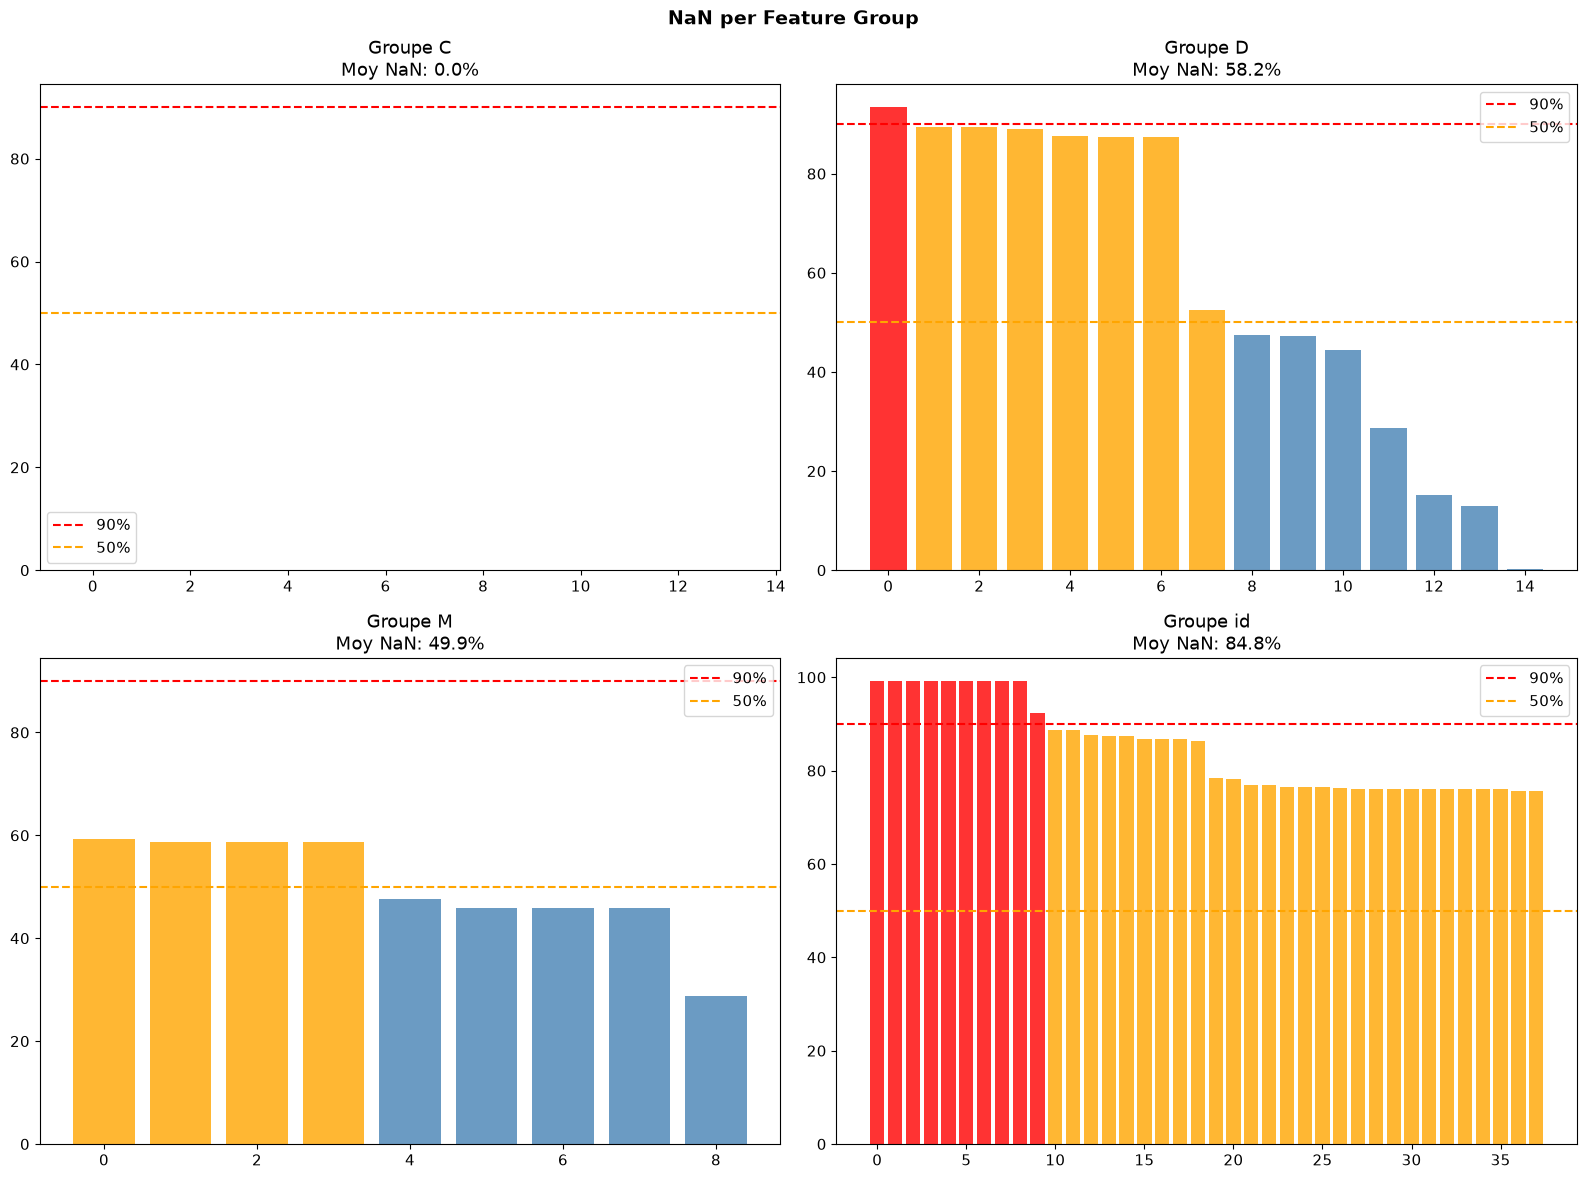


🔍 Does NaN = information?

Features where NaN is informative:
Feature  NaN_pct  Fraud_NaN  Fraud_notNaN  Difference
   V299   0.0020    16.6667        3.4987     13.1679
   V302   0.0020    16.6667        3.4987     13.1679
   V292   0.0020    16.6667        3.4987     13.1679
   V303   0.0020    16.6667        3.4987     13.1679
   V304   0.0020    16.6667        3.4987     13.1679
   V306   0.0020    16.6667        3.4987     13.1679
   V305   0.0020    16.6667        3.4987     13.1679
   V308   0.0020    16.6667        3.4987     13.1679
   V309   0.0020    16.6667        3.4987     13.1679
   V310   0.0020    16.6667        3.4987     13.1679
   V307   0.0020    16.6667        3.4987     13.1679
   V311   0.0020    16.6667        3.4987     13.1679
   V312   0.0020    16.6667        3.4987     13.1679
   V317   0.0020    16.6667        3.4987     13.1679
   V316   0.0020    16.6667        3.4987     13.1679


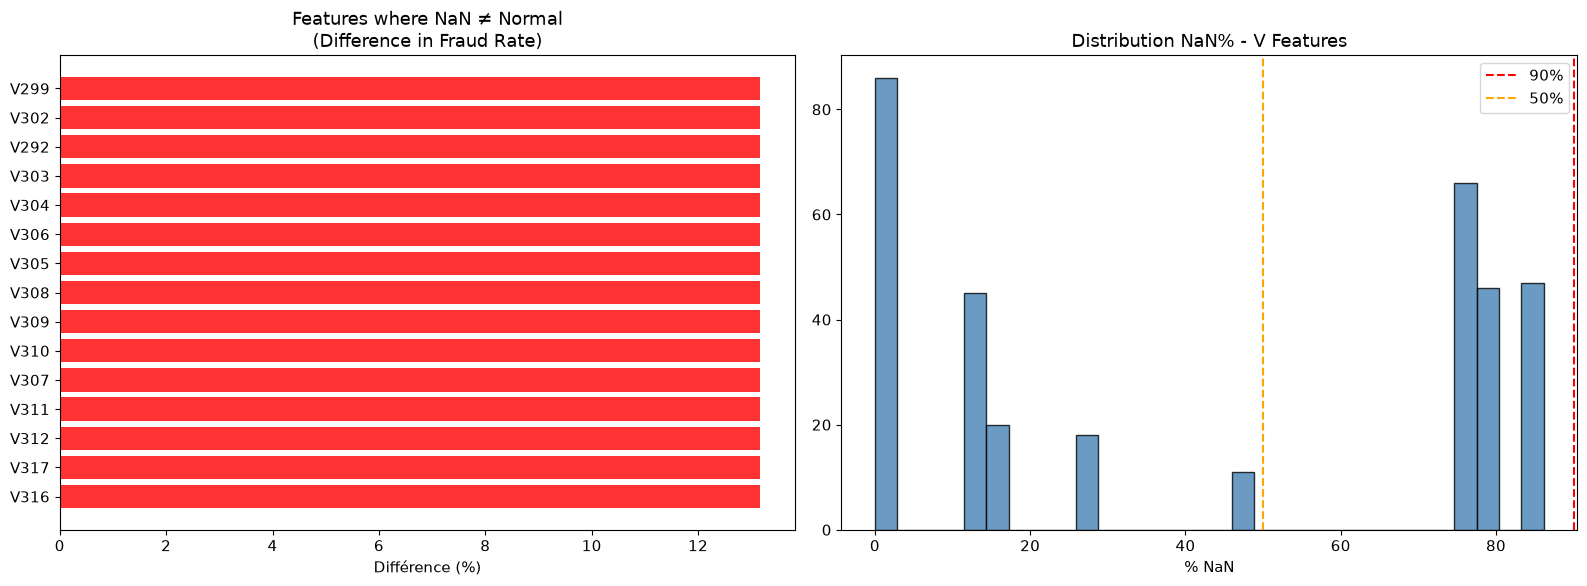


⚠️ Columns will be deleted(NaN>90%): 12
['dist2', 'D7', 'id_07', 'id_08', 'id_18', 'id_21', 'id_22', 'id_23', 'id_24', 'id_25', 'id_26', 'id_27']

✅ Features NaN useful(diff>1%): 379


In [3]:
# ============================================
# CELL 3: NaN ANALYSIS 100%
# ============================================
print("="*60)
print("ÉTAPE 2: Analyse NaN 100%")
print("="*60)

# ===== 1. NaN by group =====
groups = {
    'C': C_cols, 'D': D_cols,
    'M': M_cols, 'id': id_cols
}

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for idx, (name, cols) in enumerate(groups.items()):
    missing = df[cols].isnull().mean() * 100
    missing = missing.sort_values(ascending=False)
    colors = [
        'red'       if x > 90 else
        'orange'    if x > 50 else
        'steelblue' for x in missing.values
    ]
    axes[idx].bar(
        range(len(missing)),
        missing.values,
        color=colors, alpha=0.8
    )
    axes[idx].axhline(y=90, color='red',
        linestyle='--', label='90%')
    axes[idx].axhline(y=50, color='orange',
        linestyle='--', label='50%')
    axes[idx].set_title(
        f'Groupe {name}\nMoy NaN: '
        f'{missing.mean():.1f}%'
    )
    axes[idx].legend()

plt.suptitle('NaN per Feature Group',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ===== 2. Is NaN linked to fraud? =====
print("\n🔍 Does NaN = information?")
print("="*50)

nan_fraud_analysis = []
for col in df.columns:
    if df[col].isnull().sum() > 0:
        nan_mask    = df[col].isnull()
        fraud_nan   = df[nan_mask]['isFraud'].mean()
        fraud_notnan= df[~nan_mask]['isFraud'].mean()
        diff = abs(fraud_nan - fraud_notnan)
        nan_fraud_analysis.append({
            'Feature':      col,
            'NaN_pct':      df[col].isnull().mean()*100,
            'Fraud_NaN':    fraud_nan*100,
            'Fraud_notNaN': fraud_notnan*100,
            'Difference':   diff*100
        })

nan_fraud_df = pd.DataFrame(
    nan_fraud_analysis
).sort_values('Difference', ascending=False)

# Top 15 features where NaN is informative
top_nan_fraud = nan_fraud_df.head(15)
print("\nFeatures where NaN is informative:")
print(top_nan_fraud[[
    'Feature','NaN_pct',
    'Fraud_NaN','Fraud_notNaN','Difference'
]].to_string(index=False))

# drawing
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].barh(
    top_nan_fraud['Feature'],
    top_nan_fraud['Difference'],
    color='red', alpha=0.8
)
axes[0].set_title(
    'Features where NaN ≠ Normal\n'
    '(Difference in Fraud Rate)'
)
axes[0].set_xlabel('Différence (%)')
axes[0].invert_yaxis()

# V features NaN stats
v_nan = df[V_cols].isnull().mean() * 100
axes[1].hist(
    v_nan.values, bins=30,
    color='steelblue', alpha=0.8,
    edgecolor='black'
)
axes[1].axvline(x=90, color='red',
    linestyle='--', label='90%')
axes[1].axvline(x=50, color='orange',
    linestyle='--', label='50%')
axes[1].set_title('Distribution NaN% - V Features')
axes[1].set_xlabel('% NaN')
axes[1].legend()

plt.tight_layout()
plt.show()

# ===== 3. Missing Pattern =====
# Columns will be deleted
cols_to_drop = df.columns[
    df.isnull().mean() > 0.9
].tolist()
print(f"\n⚠️ Columns will be deleted(NaN>90%): "
      f"{len(cols_to_drop)}")
print(cols_to_drop)

# NaN columns are useful
informative_nan = nan_fraud_df[
    nan_fraud_df['Difference'] > 1.0
]['Feature'].tolist()
print(f"\n✅ Features NaN useful(diff>1%): "
      f"{len(informative_nan)}")

## CELL 4: EDA - fraud distribution

STEP 3: Distribution of the fraud


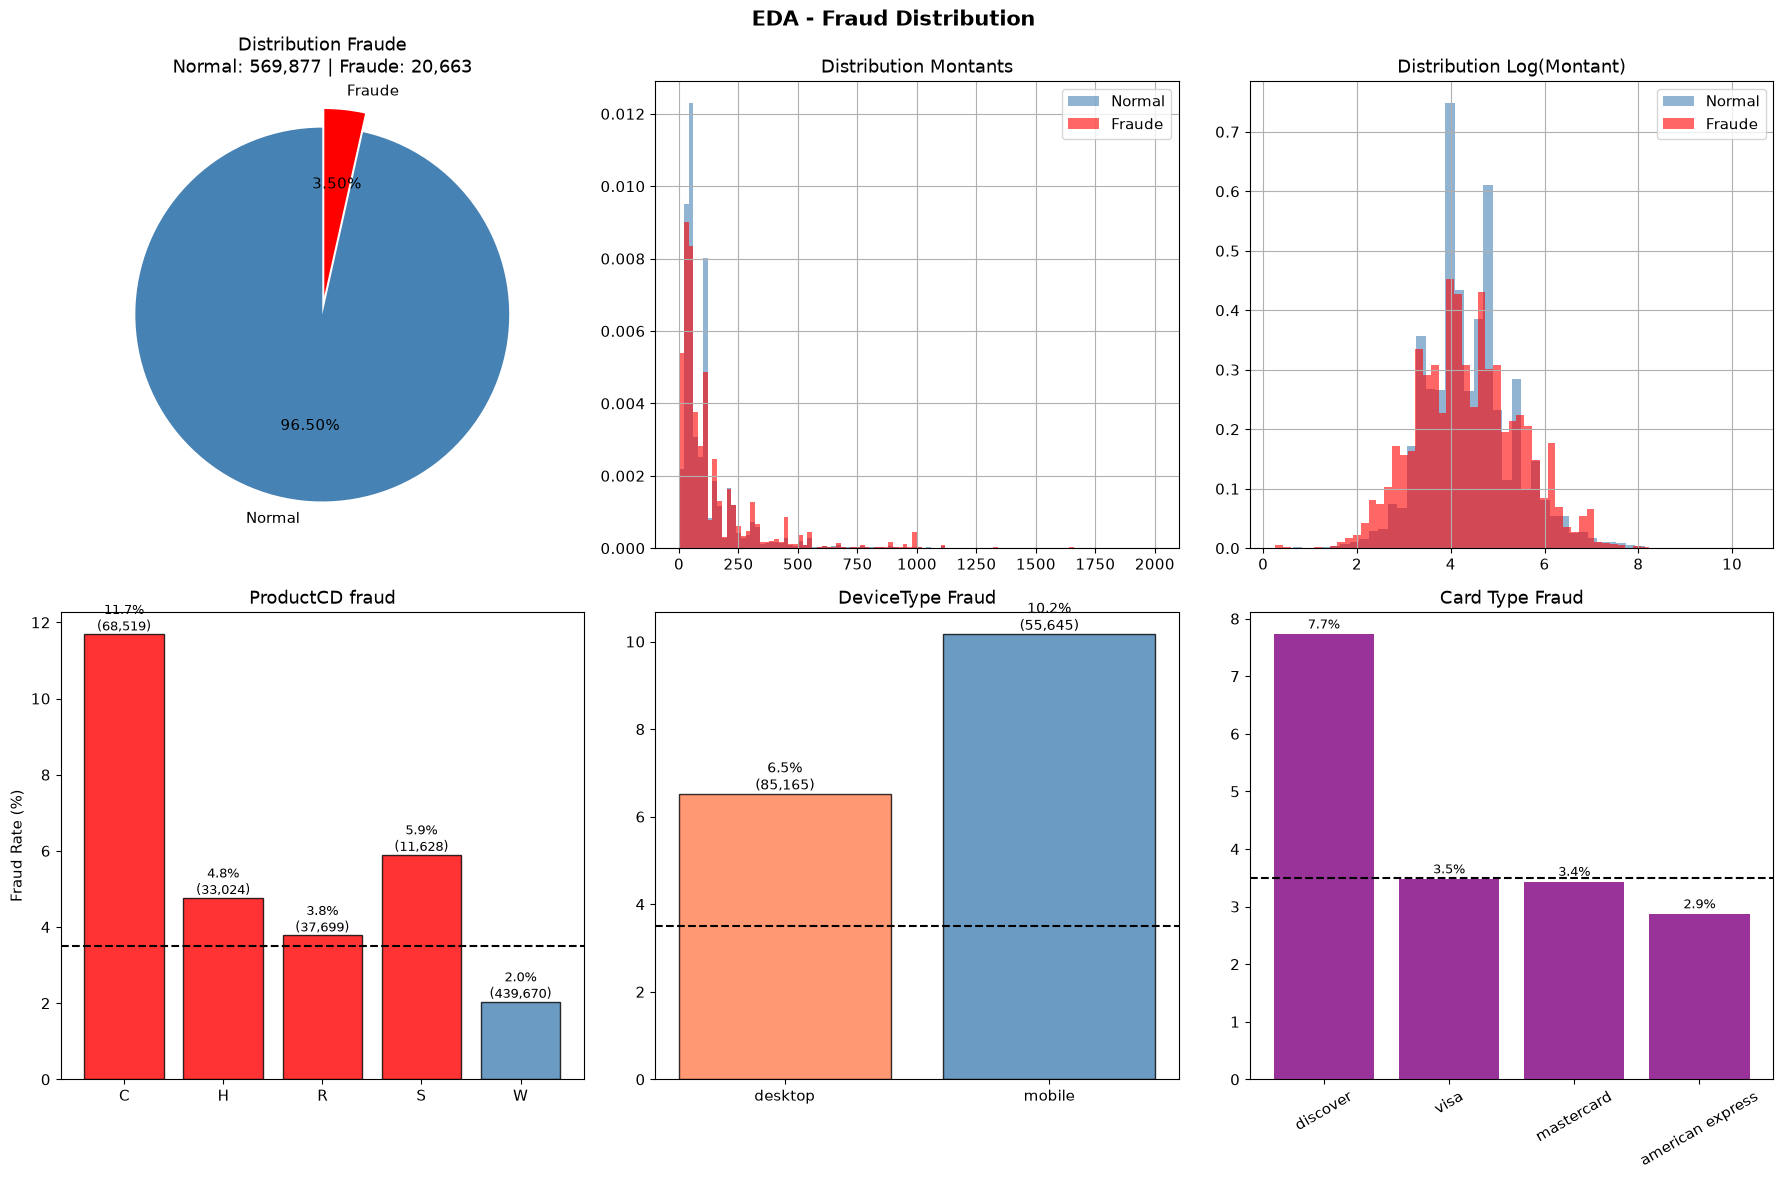


Statistics on Transaction Amounts:
Normal  - Mean: $134.51
Fraud  - Mean: $149.24
Maximum: $31937.39


In [4]:
# ============================================
# ÉTAPE 3: EDA - DISTRIBUTION FRAUDE
# ============================================
print("="*60)
print("STEP 3: Distribution of the fraud")
print("="*60)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# 1. isFraud distribution
fraud_counts = df['isFraud'].value_counts()
axes[0,0].pie(
    fraud_counts.values,
    labels=['Normal', 'Fraude'],
    colors=['steelblue', 'red'],
    autopct='%1.2f%%',
    startangle=90,
    explode=(0, 0.1)
)
axes[0,0].set_title(
    f'Distribution Fraude\n'
    f'Normal: {fraud_counts[0]:,} | '
    f'Fraude: {fraud_counts[1]:,}'
)

# 2. Distribution of funds
df[df['isFraud']==0]['TransactionAmt'].hist(
    bins=100, color='steelblue',
    alpha=0.6, label='Normal',
    ax=axes[0,1], range=(0,2000),
    density=True
)
df[df['isFraud']==1]['TransactionAmt'].hist(
    bins=100, color='red',
    alpha=0.6, label='Fraude',
    ax=axes[0,1], range=(0,2000),
    density=True
)
axes[0,1].set_title('Distribution Montants')
axes[0,1].legend()

# 3. Log Amount
df['Amt_log_temp'] = np.log1p(df['TransactionAmt'])
df[df['isFraud']==0]['Amt_log_temp'].hist(
    bins=50, color='steelblue',
    alpha=0.6, label='Normal',
    ax=axes[0,2], density=True
)
df[df['isFraud']==1]['Amt_log_temp'].hist(
    bins=50, color='red',
    alpha=0.6, label='Fraude',
    ax=axes[0,2], density=True
)
axes[0,2].set_title('Distribution Log(Montant)')
axes[0,2].legend()
df.drop('Amt_log_temp', axis=1, inplace=True)

# 4. ProductCD Fraud
product_fraud = df.groupby('ProductCD')['isFraud'].agg(
    ['mean', 'count']
).reset_index()
bars = axes[1,0].bar(
    product_fraud['ProductCD'],
    product_fraud['mean']*100,
    color=['red' if x > df['isFraud'].mean()*100
           else 'steelblue'
           for x in product_fraud['mean']*100],
    alpha=0.8, edgecolor='black'
)
for bar, rate, count in zip(
    bars, product_fraud['mean'],
    product_fraud['count']
):
    axes[1,0].text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.1,
        f'{rate*100:.1f}%\n({count:,})',
        ha='center', fontsize=9
    )
axes[1,0].axhline(
    y=df['isFraud'].mean()*100,
    color='black', linestyle='--'
)
axes[1,0].set_title('ProductCD fraud')
axes[1,0].set_ylabel('Fraud Rate (%)')

# 5.DeviceType Fraud
if 'DeviceType' in df.columns:
    dev_fraud = df.groupby(
        'DeviceType'
    )['isFraud'].agg(['mean','count']).reset_index()
    bars = axes[1,1].bar(
        dev_fraud['DeviceType'],
        dev_fraud['mean']*100,
        color=['coral','steelblue'],
        alpha=0.8, edgecolor='black'
    )
    for bar, rate, count in zip(
        bars, dev_fraud['mean'], dev_fraud['count']
    ):
        axes[1,1].text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.1,
            f'{rate*100:.1f}%\n({count:,})',
            ha='center', fontsize=10
        )
    axes[1,1].axhline(
        y=df['isFraud'].mean()*100,
        color='black', linestyle='--'
    )
    axes[1,1].set_title('DeviceType Fraud')

# 6. Card fraud
if 'card4' in df.columns:
    card4_fraud = df.groupby('card4')['isFraud'].agg(
        ['mean','count']
    ).reset_index()
    card4_fraud = card4_fraud[
        card4_fraud['count'] > 100
    ].sort_values('mean', ascending=False)
    bars = axes[1,2].bar(
        card4_fraud['card4'],
        card4_fraud['mean']*100,
        color='purple', alpha=0.8
    )
    for bar, rate in zip(
        bars, card4_fraud['mean']
    ):
        axes[1,2].text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.1,
            f'{rate*100:.1f}%',
            ha='center', fontsize=9
        )
    axes[1,2].axhline(
        y=df['isFraud'].mean()*100,
        color='black', linestyle='--'
    )
    axes[1,2].set_title('Card Type Fraud')
    plt.setp(
        axes[1,2].xaxis.get_majorticklabels(),
        rotation=30
    )

plt.suptitle(
    'EDA - Fraud Distribution',
    fontsize=15, fontweight='bold'
)
plt.tight_layout()
plt.show()

print("\nStatistics on Transaction Amounts:")
print(f"Normal  - Mean: "
      f"${df[df['isFraud']==0]['TransactionAmt'].mean():.2f}")
print(f"Fraud  - Mean: "
      f"${df[df['isFraud']==1]['TransactionAmt'].mean():.2f}")
print(f"Maximum: ${df['TransactionAmt'].max():.2f}")

## CELL 5: EDA - V FEATURES 

STEP 4: Analysis of V-features


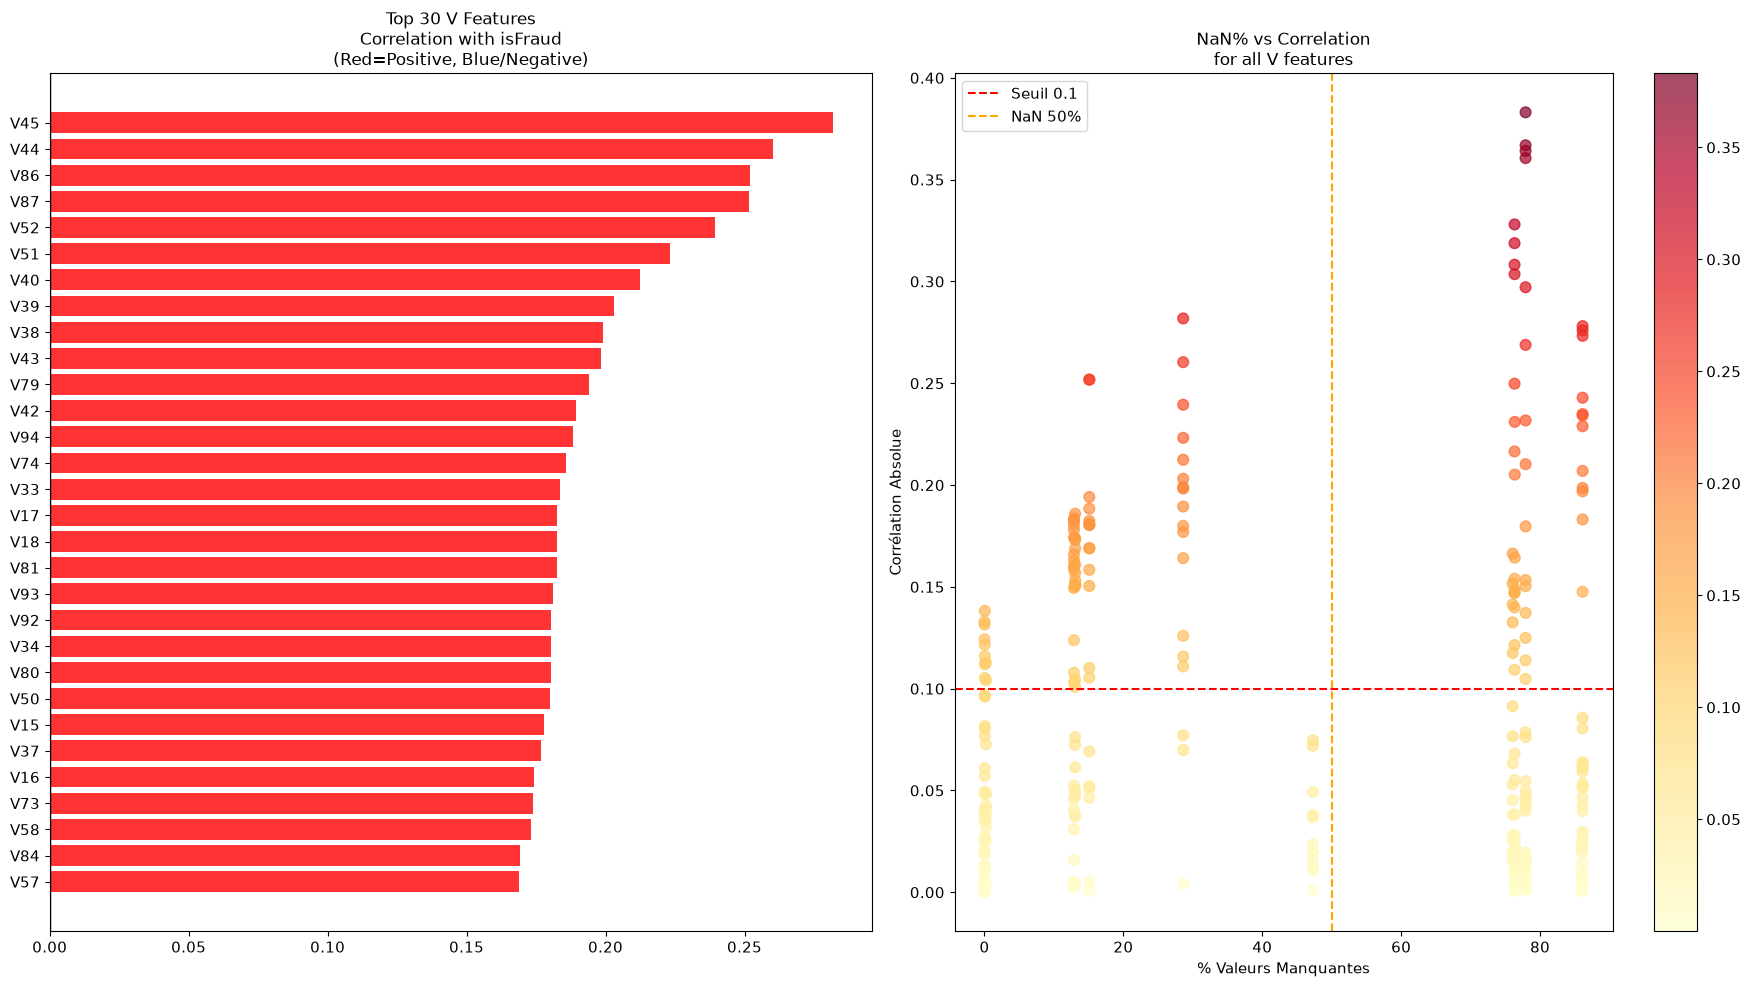

✅ V features importante (corr>0.1, NaN<50%):
   Nombre: 65
   ['V45', 'V44', 'V86', 'V87', 'V52', 'V51', 'V40', 'V39', 'V38', 'V43', 'V79', 'V42', 'V94', 'V74', 'V33', 'V17', 'V18', 'V81', 'V93', 'V92', 'V34', 'V80', 'V50', 'V15', 'V37', 'V16', 'V73', 'V58', 'V84', 'V57', 'V85', 'V21', 'V47', 'V31', 'V72', 'V32', 'V22', 'V77', 'V71', 'V63', 'V59', 'V60', 'V78', 'V64', 'V23', 'V123', 'V302', 'V304', 'V46', 'V303', 'V24', 'V111', 'V113', 'V48', 'V283', 'V125', 'V49', 'V90', 'V29', 'V91', 'V112', 'V69', 'V282', 'V30', 'V70']

Top 10 V features:
Feature  NaN_pct  Correlation
   V257  77.9134       0.3831
   V246  77.9134       0.3669
   V244  77.9134       0.3641
   V242  77.9134       0.3606
   V201  76.3235       0.3280
   V200  76.3235       0.3188
   V189  76.3235       0.3082
   V188  76.3235       0.3036
   V258  77.9134       0.2972
    V45  28.6126       0.2818


In [5]:
# ============================================
# ÉTAPE 4: EDA - V FEATURES(Most importantly!)
# ============================================
print("="*60)
print("STEP 4: Analysis of V-features")
print("="*60)

# Correlation of each V with isFraud
v_stats = []
for col in V_cols:
    nan_pct  = df[col].isnull().mean() * 100
    corr     = df[col].corr(df['isFraud'])
    v_stats.append({
        'Feature':     col,
        'NaN_pct':     nan_pct,
        'Correlation': corr,
        'Abs_Corr':    abs(corr)
    })

v_stats_df = pd.DataFrame(v_stats).sort_values(
    'Abs_Corr', ascending=False
)

# Top 30
top_30_v = v_stats_df[
    v_stats_df['NaN_pct'] < 50
].head(30)

fig, axes = plt.subplots(1, 2, figsize=(18, 10))

# Correlation plot
colors = [
    'red'  if x > 0 else 'blue'
    for x in top_30_v['Correlation']
]
axes[0].barh(
    top_30_v['Feature'],
    top_30_v['Correlation'],
    color=colors, alpha=0.8
)
axes[0].set_title(
    'Top 30 V Features\n'
    'Correlation with isFraud\n'
    '(Red=Positive, Blue/Negative)',
    fontsize=12
)
axes[0].axvline(x=0, color='black', linewidth=1)
axes[0].invert_yaxis()

# NaN vs Correlation scatter
scatter = axes[1].scatter(
    v_stats_df['NaN_pct'],
    v_stats_df['Abs_Corr'],
    c=v_stats_df['Abs_Corr'],
    cmap='YlOrRd',
    alpha=0.7, s=60
)
plt.colorbar(scatter, ax=axes[1])
axes[1].set_title(
    'NaN% vs Correlation\n'
    'for all V features',
    fontsize=12
)
axes[1].set_xlabel('% Valeurs Manquantes')
axes[1].set_ylabel('Corrélation Absolue')
axes[1].axhline(
    y=0.1, color='red',
    linestyle='--', label='Seuil 0.1'
)
axes[1].axvline(
    x=50, color='orange',
    linestyle='--', label='NaN 50%'
)
axes[1].legend()

plt.tight_layout()
plt.show()

#Save the most important V features
important_v_features = v_stats_df[
    (v_stats_df['Abs_Corr'] > 0.1) &
    (v_stats_df['NaN_pct'] < 50)
]['Feature'].tolist()

print(f"✅ V features importante (corr>0.1, NaN<50%):")
print(f"   Nombre: {len(important_v_features)}")
print(f"   {important_v_features}")
print(f"\nTop 10 V features:")
print(v_stats_df.head(10)[
    ['Feature','NaN_pct','Correlation']
].to_string(index=False))

## CELL 6: EDA - ANALYSE TEMPORELLE

STEP 5: Time Analysis


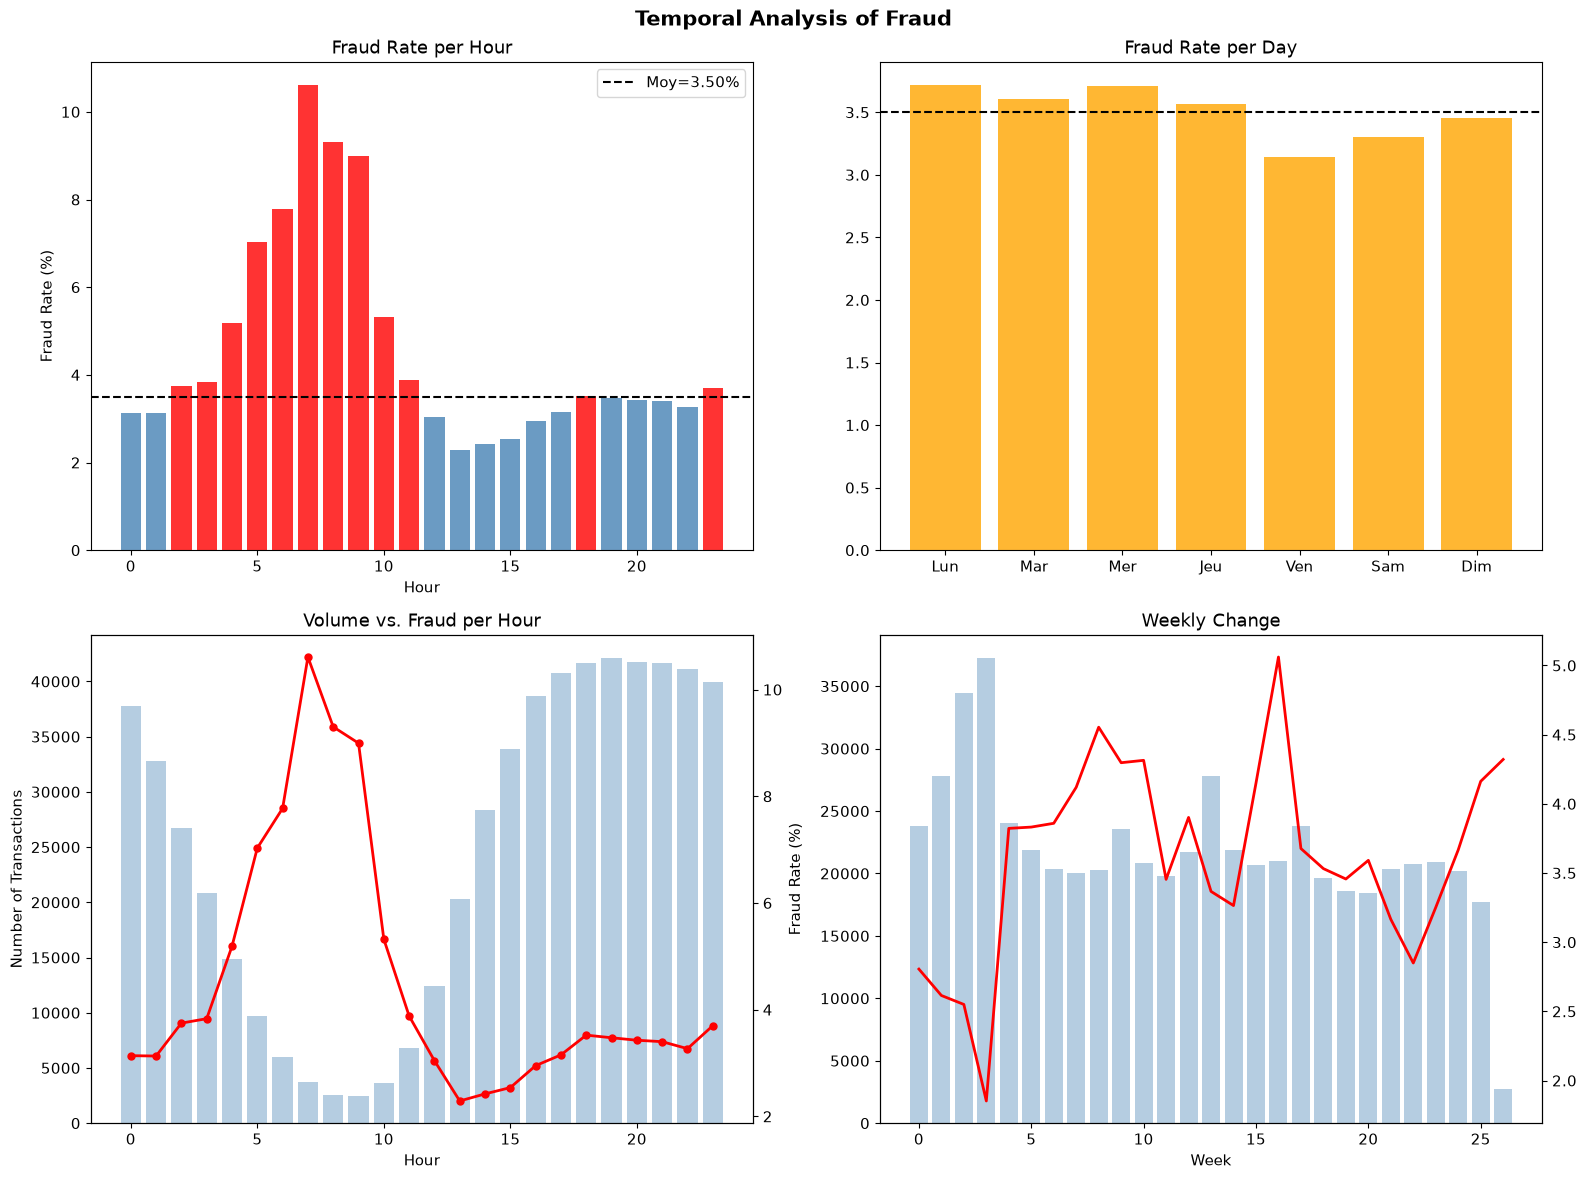

Time statistics:
the most dangerous hour: 7h (10.61%)
safest hour:  13h (2.29%)

✅ the time analysis was successfully completed!


In [6]:
# ============================================
# STEP 5: EDA - TEMPORAL ANALYSIS
# ============================================
print("="*60)
print("STEP 5: Time Analysis")
print("="*60)

# Temporary extraction for analysis
df['_hour'] = df['TransactionDT'] % 86400 // 3600
df['_day']  = df['TransactionDT'] // 86400 % 7
df['_week'] = df['TransactionDT'] // 86400 // 7

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Fraud by hour
hour_stats = df.groupby('_hour')['isFraud'].agg(
    ['mean','count','sum']
).reset_index()

colors = [
    'red' if x > df['isFraud'].mean()*100
    else 'steelblue'
    for x in hour_stats['mean']*100
]
axes[0,0].bar(
    hour_stats['_hour'],
    hour_stats['mean']*100,
    color=colors, alpha=0.8
)
axes[0,0].axhline(
    y=df['isFraud'].mean()*100,
    color='black', linestyle='--',
    label=f"Moy={df['isFraud'].mean()*100:.2f}%"
)
axes[0,0].set_title('Fraud Rate per Hour')
axes[0,0].set_xlabel('Hour')
axes[0,0].set_ylabel('Fraud Rate (%)')
axes[0,0].legend()

# 2.Scam by day
day_names = ['Lun','Mar','Mer','Jeu',
             'Ven','Sam','Dim']
day_stats = df.groupby('_day')['isFraud'].mean()
axes[0,1].bar(
    day_names[:len(day_stats)],
    day_stats.values*100,
    color='orange', alpha=0.8
)
axes[0,1].axhline(
    y=df['isFraud'].mean()*100,
    color='black', linestyle='--'
)
axes[0,1].set_title('Fraud Rate per Day')

# 3. Volume vs Fraude par heure
ax3_twin = axes[1,0].twinx()
axes[1,0].bar(
    hour_stats['_hour'],
    hour_stats['count'],
    color='steelblue', alpha=0.4,
    label='Nb Transactions'
)
ax3_twin.plot(
    hour_stats['_hour'],
    hour_stats['mean']*100,
    color='red', linewidth=2,
    marker='o', markersize=5,
    label='Fraud Rate'
)
axes[1,0].set_title('Volume vs. Fraud per Hour')
axes[1,0].set_xlabel('Hour')
axes[1,0].set_ylabel('Number of Transactions')
ax3_twin.set_ylabel('Fraud Rate (%)')

# 4. Évolution hebdomadaire
week_stats = df.groupby('_week')['isFraud'].agg(
    ['mean','count']
).reset_index()
ax4_twin = axes[1,1].twinx()
axes[1,1].bar(
    week_stats['_week'],
    week_stats['count'],
    color='steelblue', alpha=0.4
)
ax4_twin.plot(
    week_stats['_week'],
    week_stats['mean']*100,
    color='red', linewidth=2
)
axes[1,1].set_title('Weekly Change')
axes[1,1].set_xlabel('Week')

plt.suptitle(
    'Temporal Analysis of Fraud',
    fontsize=15, fontweight='bold'
)
plt.tight_layout()
plt.show()

#Important statistics
print("="*40)
print("Time statistics:")
print("="*40)
best_hour  = hour_stats.loc[
    hour_stats['mean'].idxmax(), '_hour'
]
worst_hour = hour_stats.loc[
    hour_stats['mean'].idxmin(), '_hour'
]
print(f"the most dangerous hour: {best_hour}h "
      f"({hour_stats['mean'].max()*100:.2f}%)")
print(f"safest hour:  {worst_hour}h "
      f"({hour_stats['mean'].min()*100:.2f}%)")

# delete temporary columns
df.drop(['_hour','_day','_week'], axis=1, inplace=True)
print("\n✅ the time analysis was successfully completed!")

## CELL 6B: EDA - M FEATURES

EDA - M Features Analysis
M features available: ['M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9']


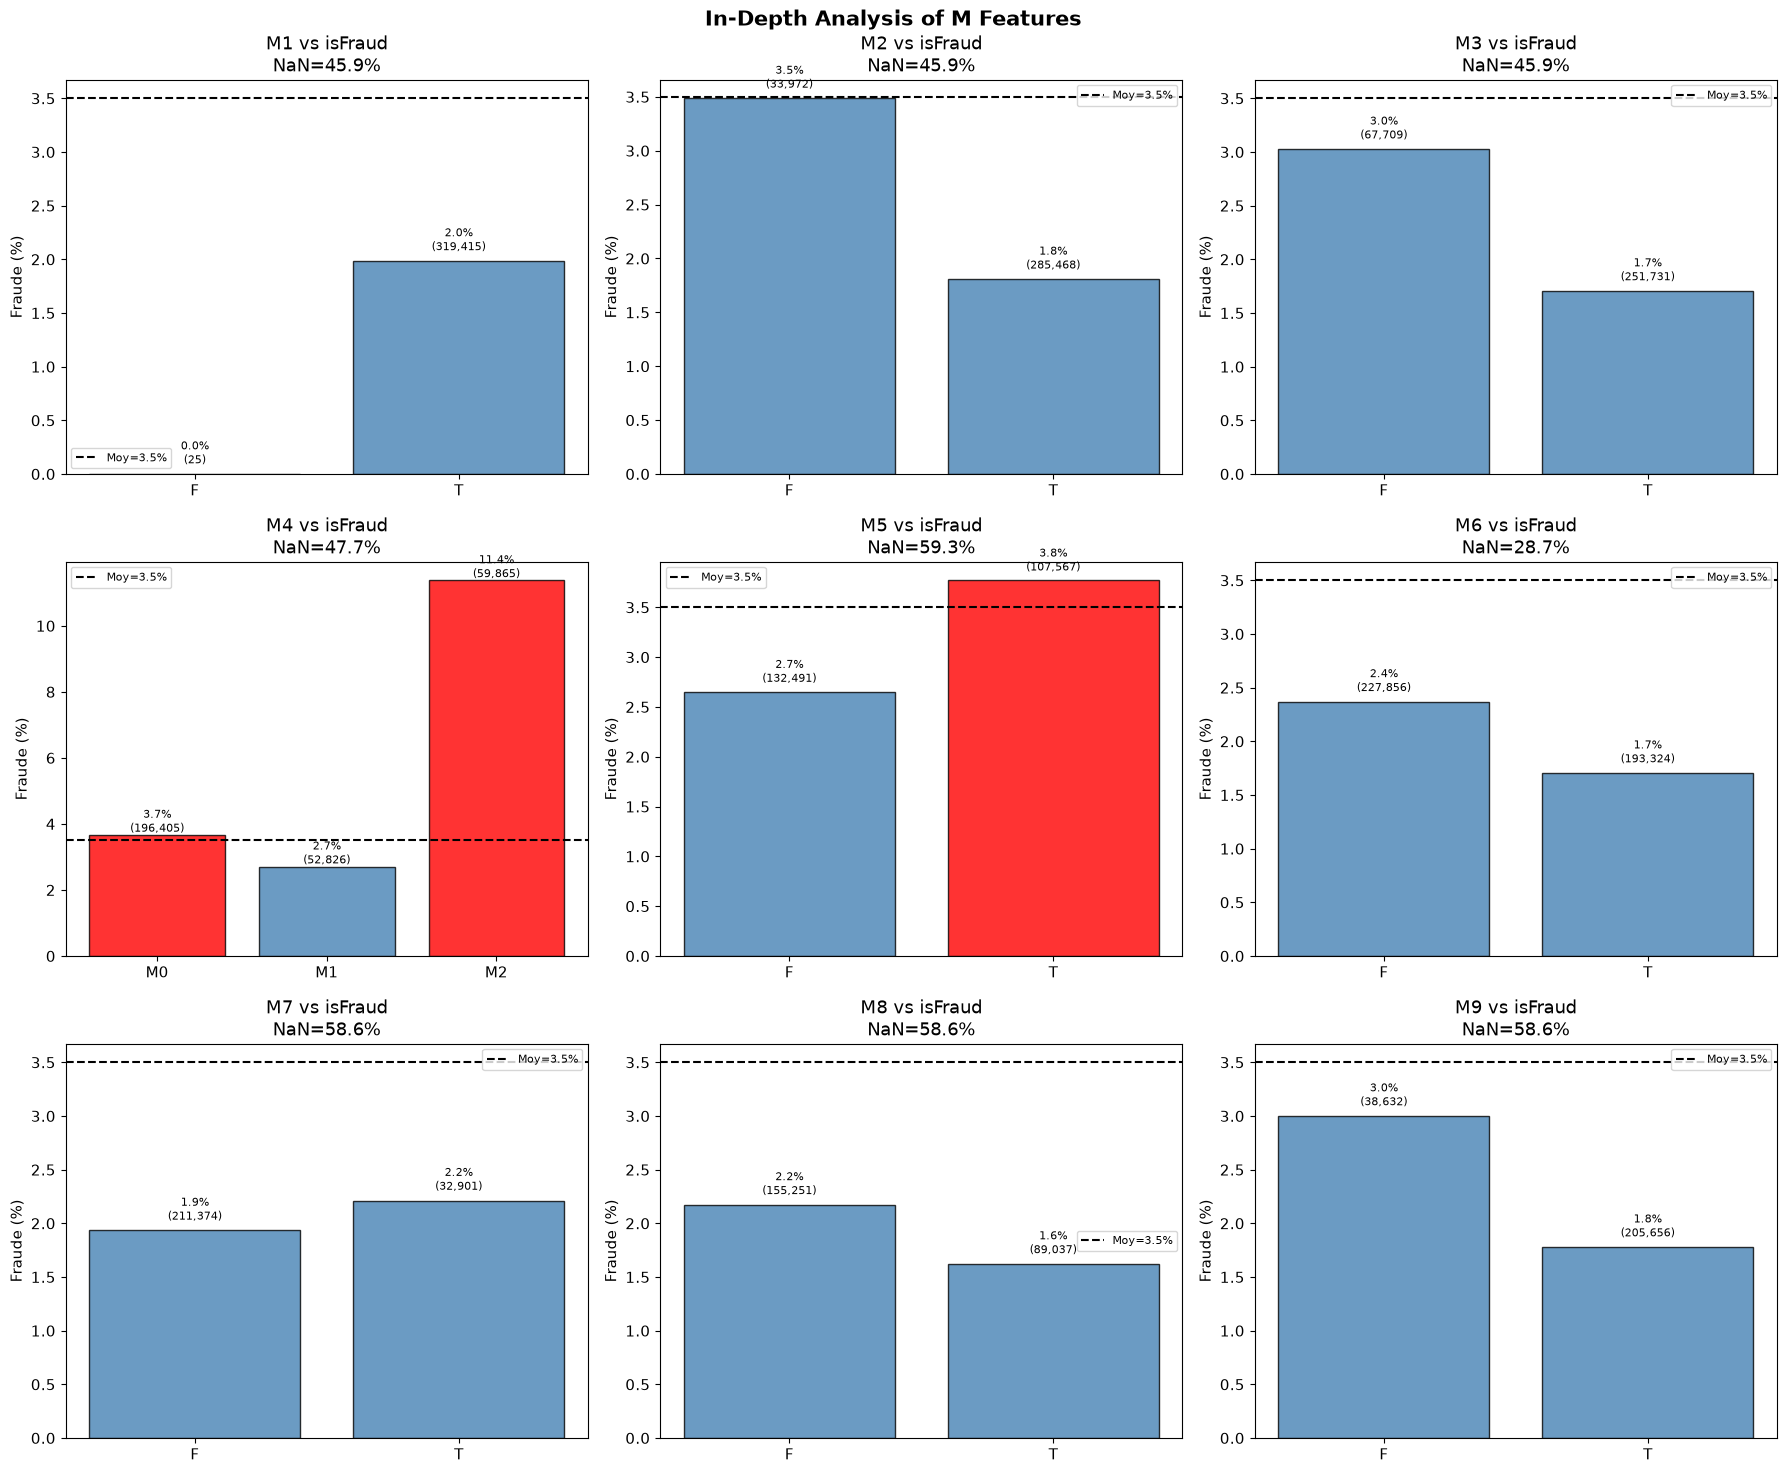

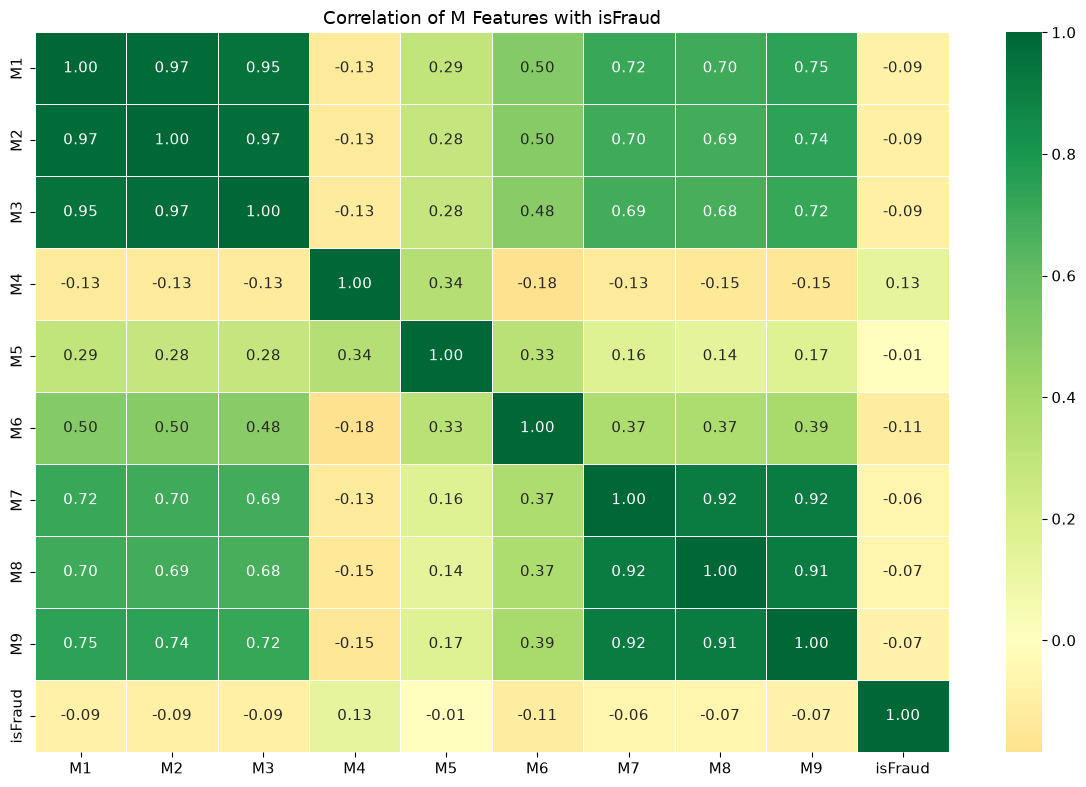


Statistics for M Features:

M1:
  the most dangerous value: T (1.99%)
  NaN: 45.9%
M1
F   0.0000
T   1.9900

M2:
  the most dangerous value: F (3.49%)
  NaN: 45.9%
M2
F   3.4900
T   1.8100

M3:
  the most dangerous value: F (3.03%)
  NaN: 45.9%
M3
F   3.0300
T   1.7100

M4:
  the most dangerous value: M2 (11.37%)
  NaN: 47.7%
M4
M0    3.6600
M1    2.7100
M2   11.3700

M5:
  the most dangerous value: T (3.77%)
  NaN: 59.3%
M5
F   2.6500
T   3.7700

M6:
  the most dangerous value: F (2.37%)
  NaN: 28.7%
M6
F   2.3700
T   1.7000

M7:
  the most dangerous value: T (2.21%)
  NaN: 58.6%
M7
F   1.9300
T   2.2100

M8:
  the most dangerous value: F (2.17%)
  NaN: 58.6%
M8
F   2.1700
T   1.6200

M9:
  the most dangerous value: F (3.00%)
  NaN: 58.6%
M9
F   3.0000
T   1.7800


In [7]:
# ============================================
# CELL 6B: EDA - M FEATURES in depth
# ============================================
print("="*60)
print("EDA - M Features Analysis")
print("="*60)

M_cols_available = [
    c for c in M_cols if c in df.columns
]
print(f"M features available: {M_cols_available}")

fig, axes = plt.subplots(3, 3, figsize=(18, 15))
axes = axes.flatten()

for idx, col in enumerate(M_cols_available):
    if idx < 9:
        fraud_rate = df.groupby(col)['isFraud'].agg(
            ['mean', 'count', 'sum']
        ).reset_index()

        bars = axes[idx].bar(
            fraud_rate[col].astype(str),
            fraud_rate['mean'] * 100,
            color=[
                'red' if x > df['isFraud'].mean()*100
                else 'steelblue'
                for x in fraud_rate['mean']*100
            ],
            alpha=0.8, edgecolor='black'
        )
        for bar, rate, count in zip(
            bars,
            fraud_rate['mean'],
            fraud_rate['count']
        ):
            axes[idx].text(
                bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.1,
                f'{rate*100:.1f}%\n({count:,})',
                ha='center', fontsize=8
            )
        axes[idx].axhline(
            y=df['isFraud'].mean()*100,
            color='black', linestyle='--',
            label=f"Moy={df['isFraud'].mean()*100:.1f}%"
        )
        axes[idx].set_title(
            f'{col} vs isFraud\n'
            f'NaN={df[col].isnull().mean()*100:.1f}%'
        )
        axes[idx].set_ylabel('Fraude (%)')
        axes[idx].legend(fontsize=8)

plt.suptitle(
    'In-Depth Analysis of M Features',
    fontsize=15, fontweight='bold'
)
plt.tight_layout()
plt.show()

# Correlation M features
m_numeric = pd.DataFrame()
for col in M_cols_available:
    m_numeric[col] = pd.Categorical(
        df[col]
    ).codes
m_numeric['isFraud'] = df['isFraud'].values

plt.figure(figsize=(12, 8))
sns.heatmap(
    m_numeric.corr(),
    annot=True, fmt='.2f',
    cmap='RdYlGn', center=0,
    linewidths=0.5
)
plt.title(
    'Correlation of M Features with isFraud'
)
plt.tight_layout()
plt.show()

# Statistics
print("\n" + "="*50)
print("Statistics for M Features:")
print("="*50)
for col in M_cols_available:
    fraud_by_val = df.groupby(
        col
    )['isFraud'].mean() * 100
    max_val = fraud_by_val.idxmax()
    print(f"\n{col}:")
    print(f"  the most dangerous value: {max_val} "
          f"({fraud_by_val[max_val]:.2f}%)")
    print(f"  NaN: "
          f"{df[col].isnull().mean()*100:.1f}%")
    print(fraud_by_val.round(2).to_string())

## CELL 6C: ID FEATURES 100%

EDA - ID Features 100%
Total id features: 38

NaN per id feature:
id_01   75.5761
id_12   75.5761
id_15   76.1261
id_36   76.1261
id_37   76.1261
id_38   76.1261
id_35   76.1261
id_11   76.1273
id_28   76.1273
id_29   76.1273
id_02   76.1452
id_31   76.2451
id_17   76.3997
id_19   76.4084
id_20   76.4180
id_06   76.8238
id_05   76.8238
id_16   78.0980
id_13   78.4401
id_14   86.4456
id_34   86.8248
id_32   86.8619
id_30   86.8654
id_10   87.3123
id_09   87.3123
id_33   87.5895
id_04   88.7689
id_03   88.7689
id_18   92.3607
id_22   99.1247
id_23   99.1247
id_27   99.1247
id_26   99.1257
id_21   99.1264
id_08   99.1271
id_07   99.1271
id_25   99.1310
id_24   99.1962

id features with NaN<70%: 0
[]


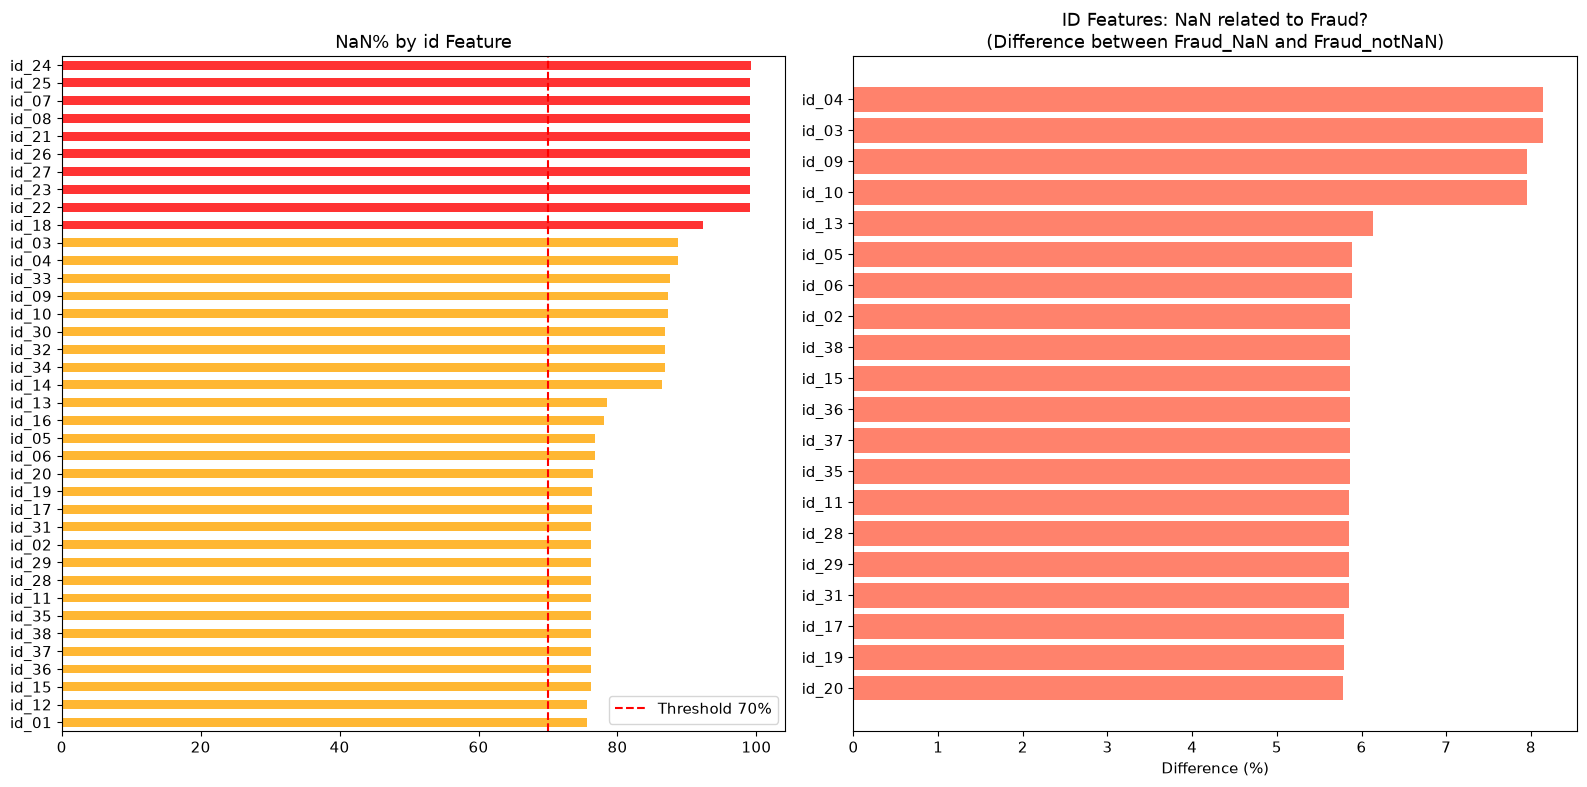


Top 10 id features informatifs:
Feature  NaN_pct  Fraud_NaN  Fraud_notNaN   Diff
  id_04  88.7689     2.5850       10.7231 8.1381
  id_03  88.7689     2.5850       10.7231 8.1381
  id_09  87.3123     2.4895       10.4463 7.9568
  id_10  87.3123     2.4895       10.4463 7.9568
  id_13  78.4401     2.1750        8.3161 6.1411
  id_05  76.8238     2.1339        8.0240 5.8901
  id_06  76.8238     2.1339        8.0240 5.8901
  id_02  76.1452     2.0995        7.9661 5.8665
  id_38  76.1261     2.1001        7.9597 5.8596
  id_15  76.1261     2.1001        7.9597 5.8596


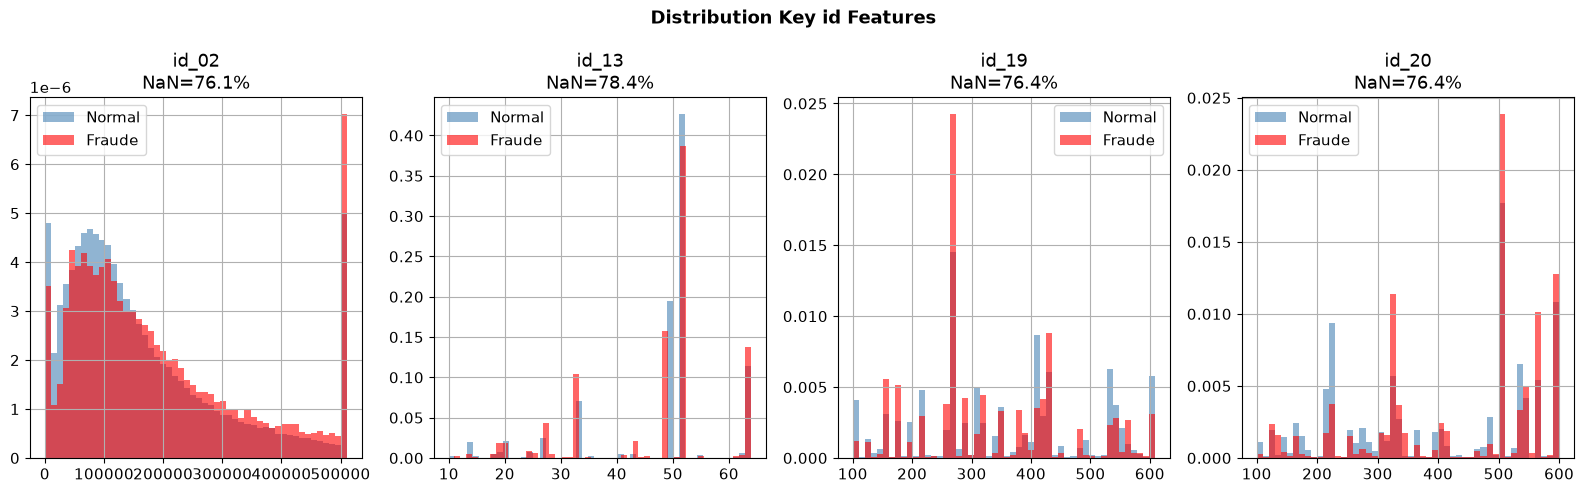


✅Creating NaN Indicators...
id features informatives: ['id_04', 'id_03', 'id_09', 'id_10', 'id_13', 'id_05', 'id_06', 'id_02', 'id_38', 'id_15', 'id_36', 'id_37', 'id_35', 'id_11', 'id_28', 'id_29', 'id_31', 'id_17', 'id_19', 'id_20', 'id_01', 'id_12', 'id_16', 'id_18', 'id_24', 'id_08', 'id_07', 'id_21', 'id_23', 'id_22', 'id_27', 'id_26', 'id_25', 'id_33', 'id_34', 'id_14', 'id_32', 'id_30']

✅ ID Features Analysis 100% finished!


In [8]:
# ============================================
# CELL 6C: ID FEATURES 100%
# ============================================
print("="*60)
print("EDA - ID Features 100%")
print("="*60)

id_cols_avail = [
    c for c in id_cols if c in df.columns
]
print(f"Total id features: {len(id_cols_avail)}")

# ===== 1. NaN Analysis of ID=====
id_nan = df[id_cols_avail].isnull().mean()*100
id_nan_sorted = id_nan.sort_values()

print("\nNaN per id feature:")
print(id_nan_sorted.to_string())

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

id_nan_sorted.plot(
    kind='barh', ax=axes[0],
    color=[
        'red'       if x > 90 else
        'orange'    if x > 50 else
        'steelblue' for x in id_nan_sorted.values
    ],
    alpha=0.8
)
axes[0].axvline(x=70, color='red',
    linestyle='--', label='Threshold 70%')
axes[0].set_title('NaN% by id Feature')
axes[0].legend()

# ===== 2. id features disponibles (NaN<70%) =====
id_avail_70 = [
    c for c in id_cols_avail
    if df[c].isnull().mean() < 0.7
]
print(f"\nid features with NaN<70%: {len(id_avail_70)}")
print(id_avail_70)

# ===== 3. NaN = Information? =====
id_nan_fraud = []
for col in id_cols_avail:
    nan_mask = df[col].isnull()
    if nan_mask.sum() > 0:
        fraud_nan    = df[nan_mask]['isFraud'].mean()*100
        fraud_notnan = df[~nan_mask]['isFraud'].mean()*100
        id_nan_fraud.append({
            'Feature':   col,
            'NaN_pct':   df[col].isnull().mean()*100,
            'Fraud_NaN': fraud_nan,
            'Fraud_notNaN': fraud_notnan,
            'Diff':      abs(fraud_nan-fraud_notnan)
        })

id_nan_fraud_df = pd.DataFrame(
    id_nan_fraud
).sort_values('Diff', ascending=False)

axes[1].barh(
    id_nan_fraud_df['Feature'].head(20),
    id_nan_fraud_df['Diff'].head(20),
    color='tomato', alpha=0.8
)
axes[1].set_title(
    'ID Features: NaN related to Fraud?\n'
    '(Difference between Fraud_NaN and Fraud_notNaN)'
)
axes[1].set_xlabel('Difference (%)')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

print("\nTop 10 id features informatifs:")
print(id_nan_fraud_df.head(10)[[
    'Feature','NaN_pct',
    'Fraud_NaN','Fraud_notNaN','Diff'
]].to_string(index=False))

# ===== 4. Analyser id_02, id_13, id_19 =====
key_id_features = ['id_02','id_13','id_19','id_20']
key_id_features = [
    f for f in key_id_features
    if f in df.columns
]

if key_id_features:
    fig, axes = plt.subplots(
        1, len(key_id_features),
        figsize=(16, 5)
    )
    if len(key_id_features) == 1:
        axes = [axes]

    for idx, col in enumerate(key_id_features):
        if df[col].dtype in ['float64','int64']:
            p95 = df[col].quantile(0.95)
            df[df['isFraud']==0][col].clip(
                upper=p95
            ).hist(
                bins=50, ax=axes[idx],
                color='steelblue',
                alpha=0.6, label='Normal',
                density=True
            )
            df[df['isFraud']==1][col].clip(
                upper=p95
            ).hist(
                bins=50, ax=axes[idx],
                color='red',
                alpha=0.6, label='Fraude',
                density=True
            )
            axes[idx].set_title(
                f'{col}\n'
                f'NaN={df[col].isnull().mean()*100:.1f}%'
            )
            axes[idx].legend()

    plt.suptitle(
        'Distribution Key id Features',
        fontsize=13, fontweight='bold'
    )
    plt.tight_layout()
    plt.show()

# ===== 5. create NaN Indicator Features =====
print("\n✅Creating NaN Indicators...")
informative_id = id_nan_fraud_df[
    id_nan_fraud_df['Diff'] > 1.0
]['Feature'].tolist()

print(f"id features informatives: {informative_id}")
# classification indicators in CELL 8

print("\n✅ ID Features Analysis 100% finished!")

## CELL 6D: MULTIVARIATE ANALYSIS

EDA - Multivariate Analysis


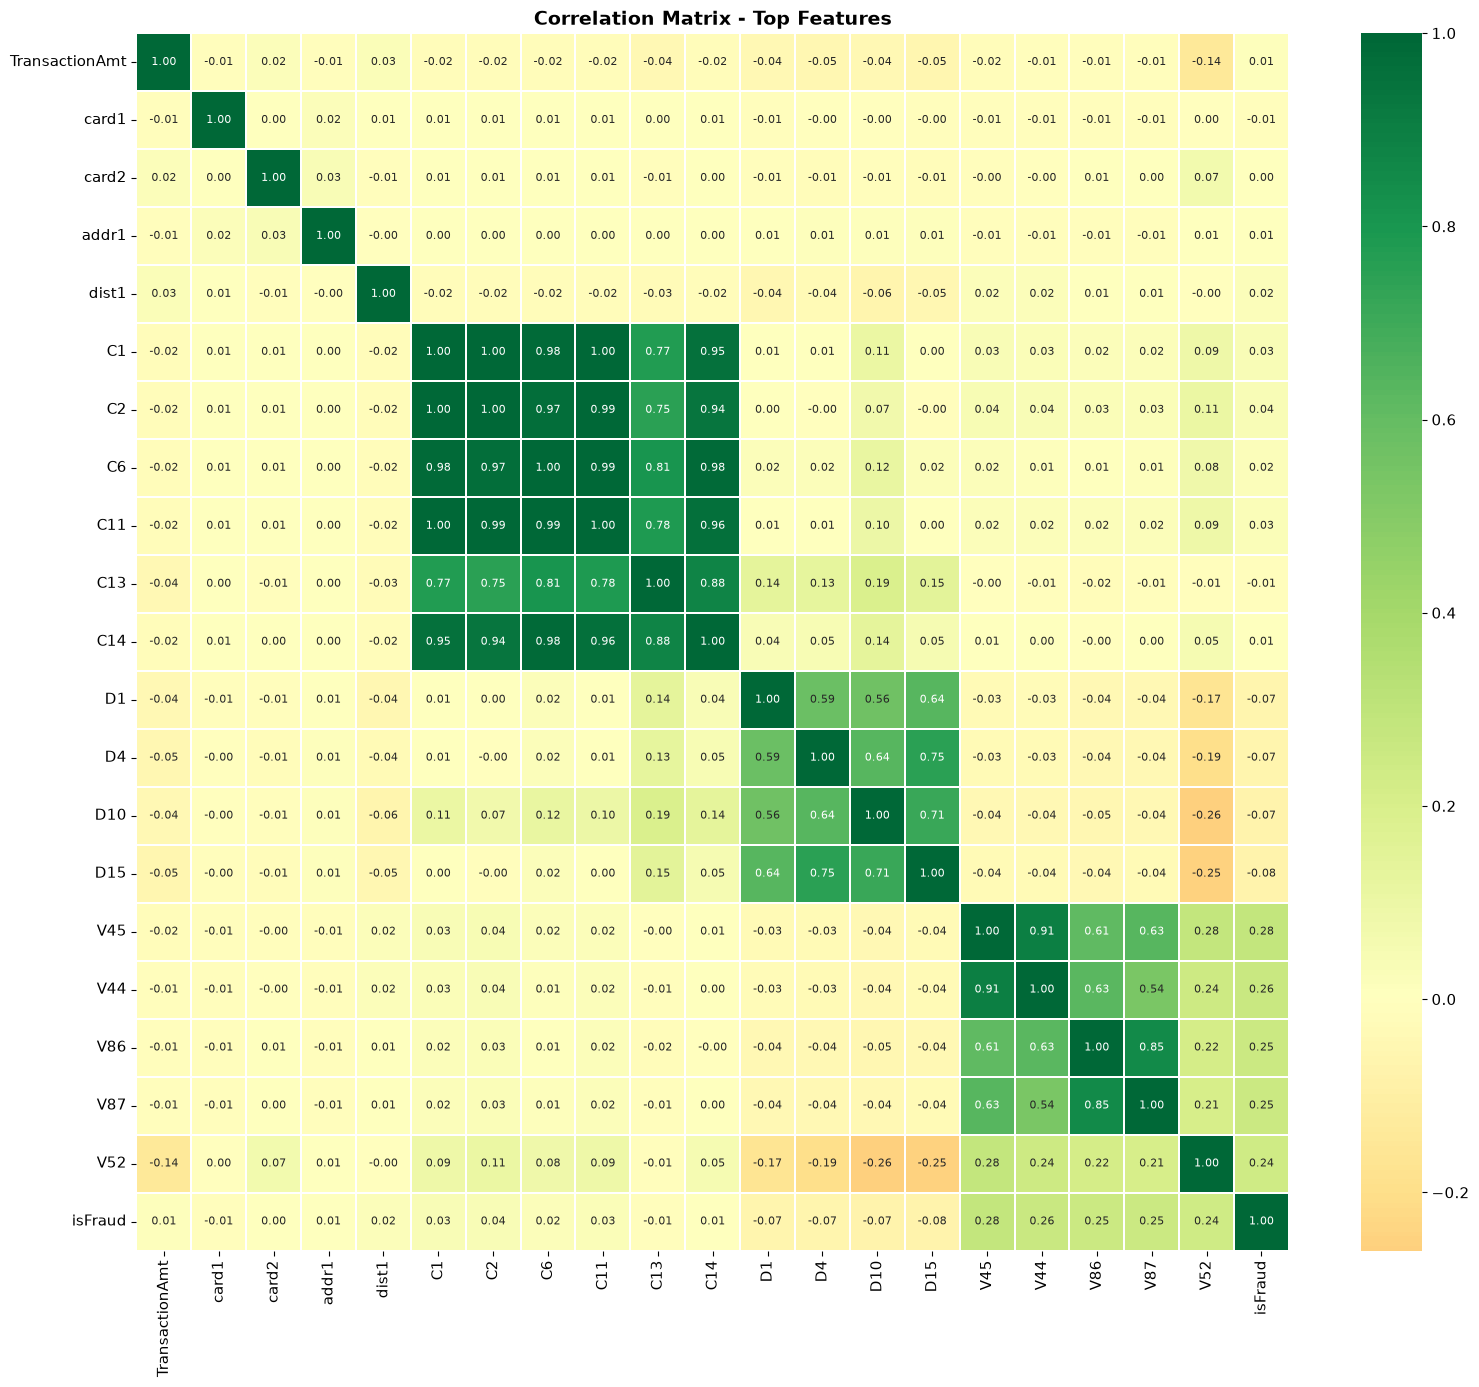

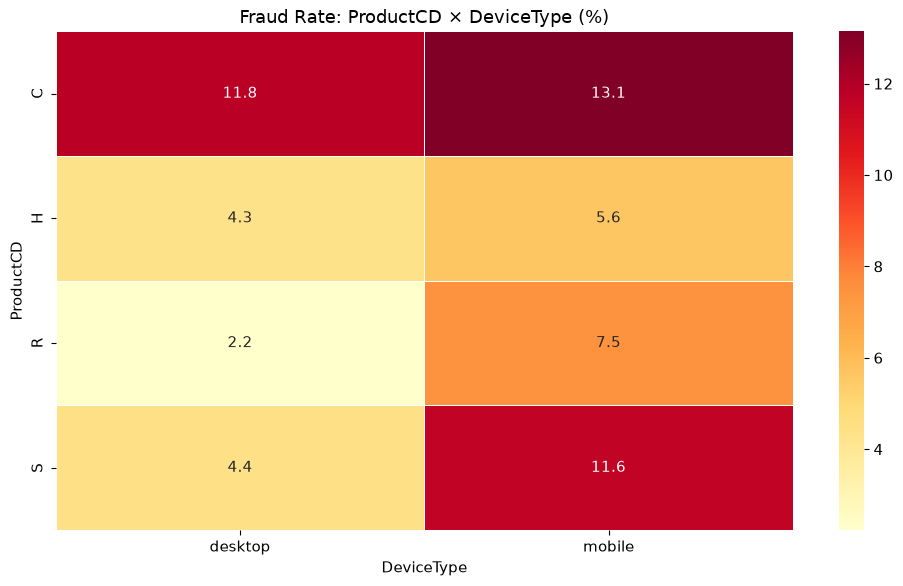


ProductCD × DeviceType:
DeviceType  desktop  mobile
ProductCD                  
C           11.8100 13.1400
H            4.3400  5.6300
R            2.2300  7.4700
S            4.4400 11.6200


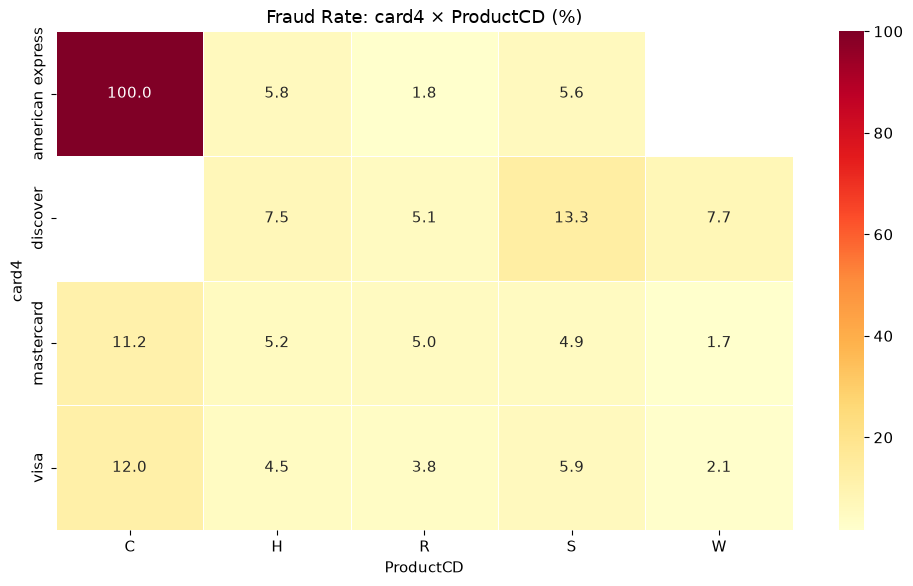

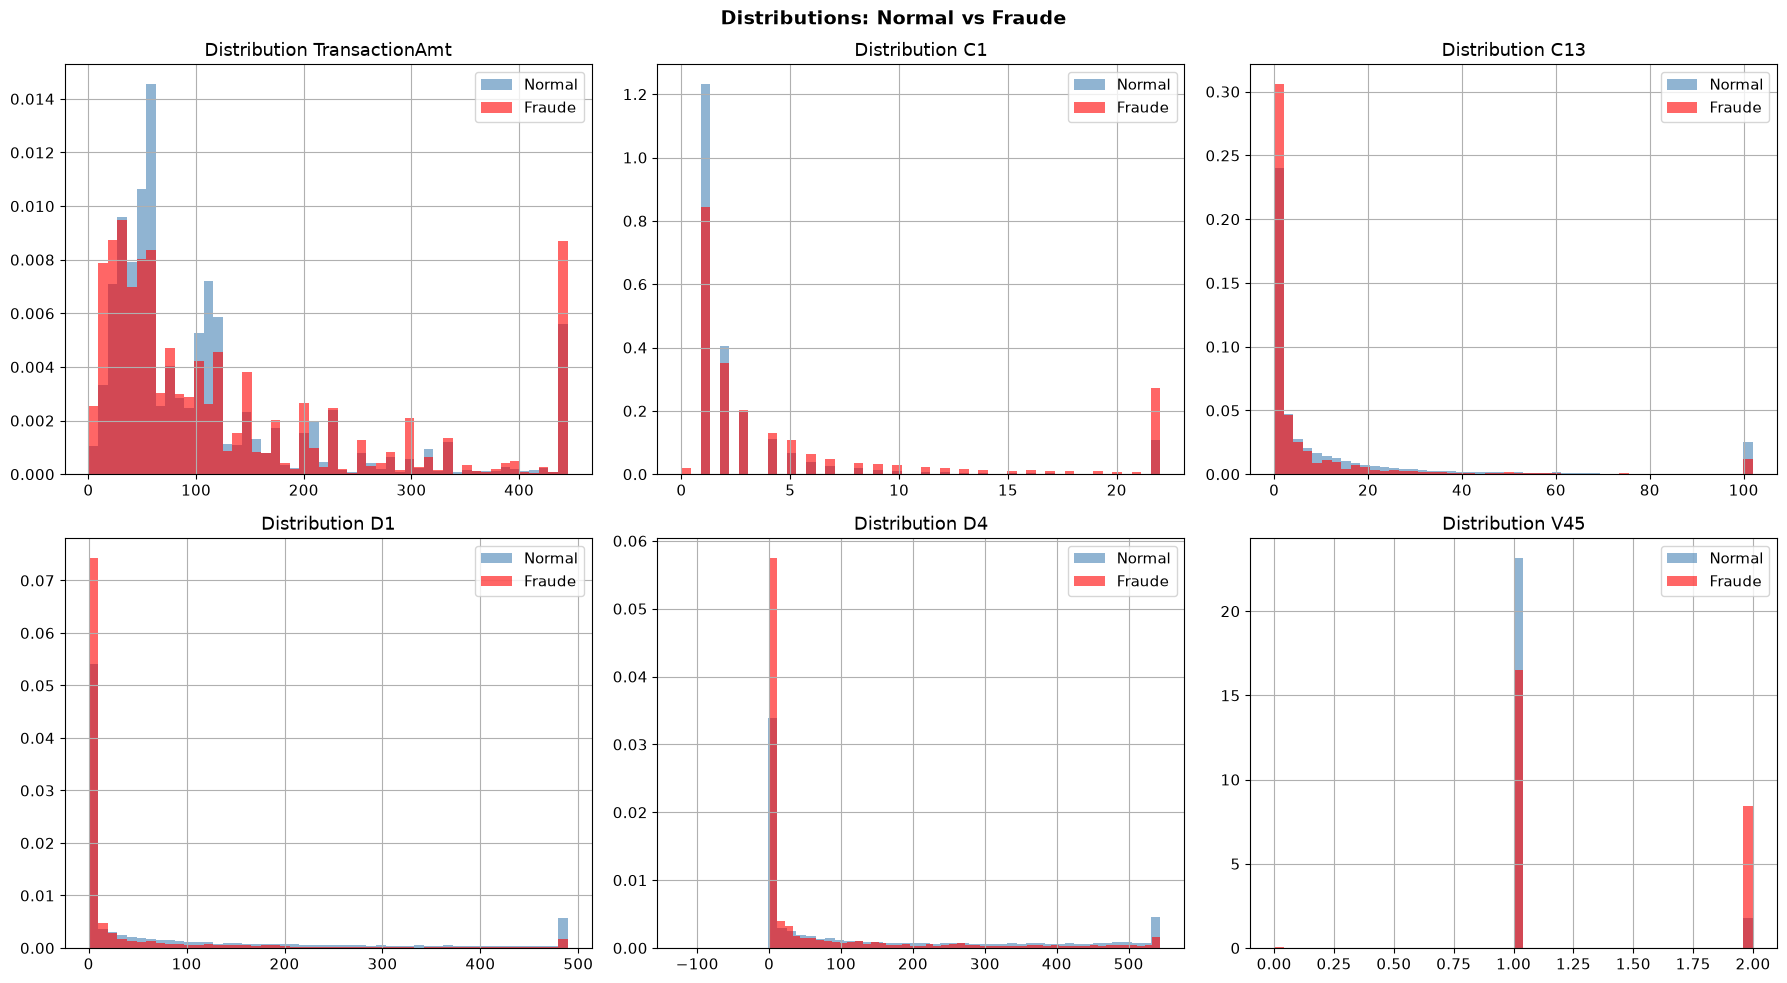

✅ Multivariate Analysis finished!


In [9]:
# ============================================
# CELL 6D: MULTIVARIATE ANALYSIS
# ============================================
print("="*60)
print("EDA - Multivariate Analysis")
print("="*60)

# ===== 1. Correlation Matrix =====
top_features = [
    'TransactionAmt','card1','card2',
    'addr1','dist1','C1','C2','C6',
    'C11','C13','C14','D1','D4',
    'D10','D15','V45','V44','V86',
    'V87','V52','isFraud'
]
top_features = [
    c for c in top_features
    if c in df.columns
]

plt.figure(figsize=(16, 14))
sns.heatmap(
    df[top_features].corr(),
    annot=True, fmt='.2f',
    cmap='RdYlGn', center=0,
    linewidths=0.3,
    annot_kws={'size': 8}
)
plt.title(
    'Correlation Matrix - Top Features',
    fontsize=14, fontweight='bold'
)
plt.tight_layout()
plt.show()

# ===== 2. ProductCD × DeviceType =====
if 'DeviceType' in df.columns:
    cross1 = df.groupby(
        ['ProductCD','DeviceType']
    )['isFraud'].mean().unstack() * 100

    plt.figure(figsize=(10, 6))
    sns.heatmap(
        cross1,
        annot=True, fmt='.1f',
        cmap='YlOrRd',
        linewidths=0.5
    )
    plt.title(
        'Fraud Rate: ProductCD × DeviceType (%)'
    )
    plt.tight_layout()
    plt.show()
    print("\nProductCD × DeviceType:")
    print(cross1.round(2))

# ===== 3. card4 × ProductCD =====
if 'card4' in df.columns:
    cross2 = df.groupby(
        ['card4','ProductCD']
    )['isFraud'].mean().unstack() * 100

    plt.figure(figsize=(10, 6))
    sns.heatmap(
        cross2,
        annot=True, fmt='.1f',
        cmap='YlOrRd',
        linewidths=0.5
    )
    plt.title(
        'Fraud Rate: card4 × ProductCD (%)'
    )
    plt.tight_layout()
    plt.show()

# ===== 4. Distribution comparison=====
compare_feats = [
    'TransactionAmt','C1','C13',
    'D1','D4','V45'
]
compare_feats = [
    c for c in compare_feats
    if c in df.columns
]

fig, axes = plt.subplots(
    2, 3, figsize=(18, 10)
)
axes = axes.flatten()

for idx, feat in enumerate(
    compare_feats[:6]
):
    p95 = df[feat].quantile(0.95)
    df[df['isFraud']==0][feat].clip(
        upper=p95
    ).hist(
        bins=50, ax=axes[idx],
        color='steelblue', alpha=0.6,
        label='Normal', density=True
    )
    df[df['isFraud']==1][feat].clip(
        upper=p95
    ).hist(
        bins=50, ax=axes[idx],
        color='red', alpha=0.6,
        label='Fraude', density=True
    )
    axes[idx].set_title(
        f'Distribution {feat}'
    )
    axes[idx].legend()

plt.suptitle(
    'Distributions: Normal vs Fraude',
    fontsize=14, fontweight='bold'
)
plt.tight_layout()
plt.show()

print("✅ Multivariate Analysis finished!")

## CELL 6E: OUTLIERS + PCA

EDA - Outliers + PCA Analysis
1. Outliers Analysis...


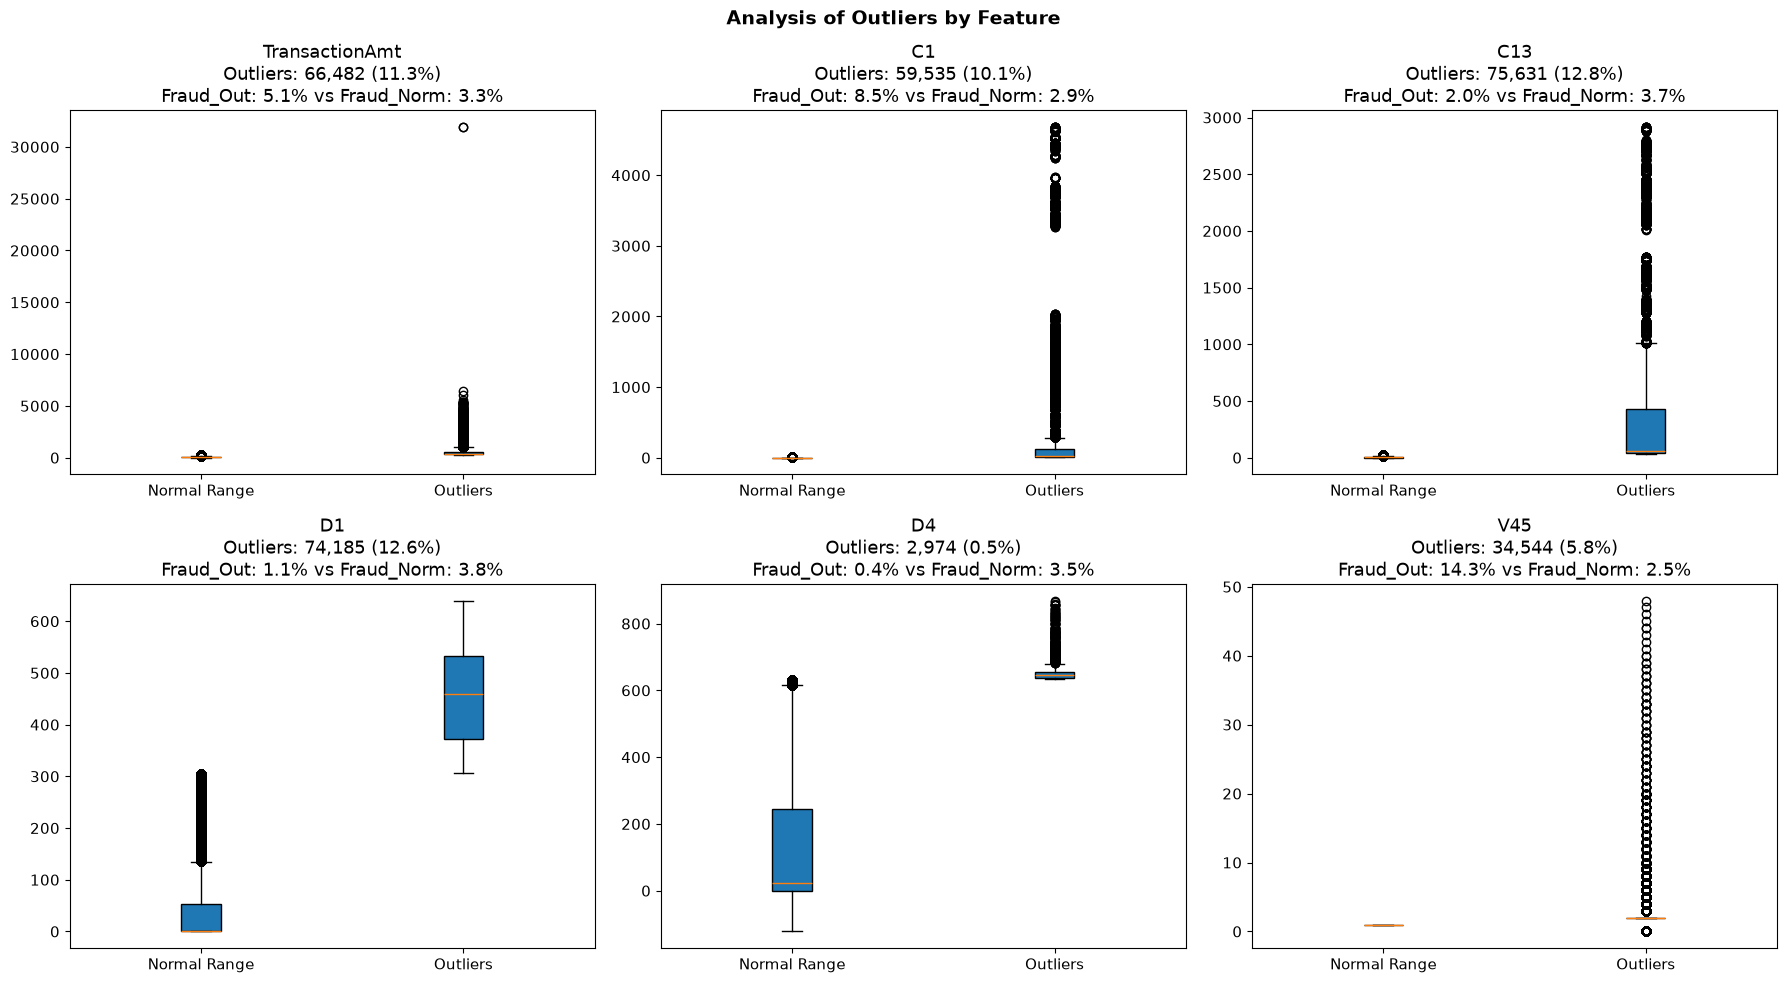


Outliers Statistics:
Feature         %      Fraud_Out  Fraud_Norm
---------------------------------------------
TransactionAmt    11.3%       5.07%       3.30%
C1                10.1%       8.52%       2.94%
C13               12.8%       2.02%       3.72%
D1                12.6%       1.13%       3.84%
D4                 0.5%       0.37%       3.48%
V45                5.8%      14.34%       2.48%

2. PCA Visualization...


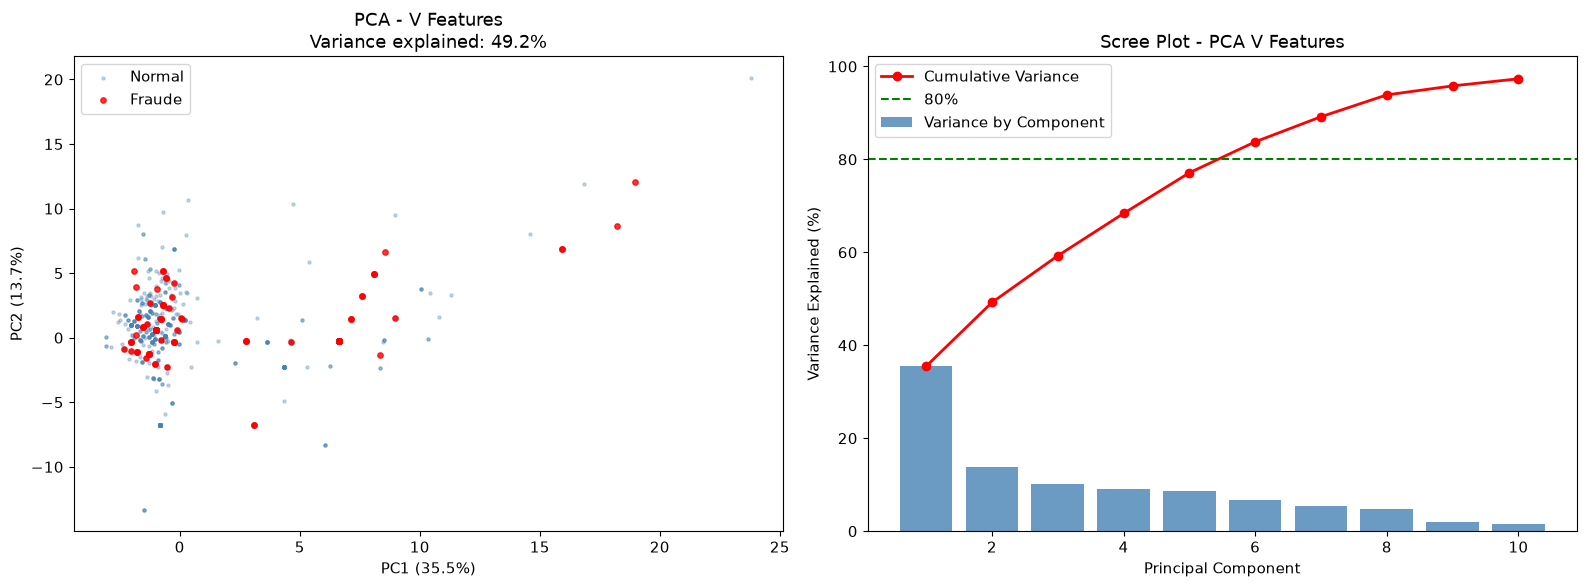

✅ PC1+PC2 explain: 49.2%
✅ Outliers + PCA Complete!


In [10]:
# ============================================
# CELL 6E: OUTLIERS + PCA - FIXED
# ============================================
print("="*60)
print("EDA - Outliers + PCA Analysis")
print("="*60)

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# ===== 1. Outliers Analysis =====
print("1. Outliers Analysis...")

outlier_features = [
    'TransactionAmt','C1','C13',
    'D1','D4','V45'
]
outlier_features = [
    f for f in outlier_features
    if f in df.columns
]

fig, axes = plt.subplots(
    2, 3, figsize=(18, 10)
)
axes = axes.flatten()

outlier_stats = {}
for idx, feat in enumerate(outlier_features[:6]):
    Q1    = df[feat].quantile(0.25)
    Q3    = df[feat].quantile(0.75)
    IQR   = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[feat] < lower) |
        (df[feat] > upper)
    ]
    normal_r = df[
        (df[feat] >= lower) &
        (df[feat] <= upper)
    ]

    outlier_stats[feat] = {
        'count':      len(outliers),
        'pct':        len(outliers)/len(df)*100,
        'fraud_out':  outliers['isFraud'].mean()*100,
        'fraud_norm': normal_r['isFraud'].mean()*100
    }

    # ← Reform: without 'labels'
    data_box = [
        normal_r[feat].clip(lower, upper).dropna(),
        outliers[feat].dropna()
    ]
    bp = axes[idx].boxplot(
        data_box,
        patch_artist=True
    )
    # ← Adding labels manually:
    axes[idx].set_xticks([1, 2])
    axes[idx].set_xticklabels(
        ['Normal Range', 'Outliers']
    )
    axes[idx].set_title(
        f'{feat}\n'
        f'Outliers: {len(outliers):,} '
        f'({len(outliers)/len(df)*100:.1f}%)\n'
        f'Fraud_Out: '
        f'{outliers["isFraud"].mean()*100:.1f}%'
        f' vs Fraud_Norm: '
        f'{normal_r["isFraud"].mean()*100:.1f}%'
    )

plt.suptitle(
    'Analysis of Outliers by Feature',
    fontsize=14, fontweight='bold'
)
plt.tight_layout()
plt.show()

# count:
print("\nOutliers Statistics:")
print(
    f"{'Feature':15} {'%':6} "
    f"{'Fraud_Out':10} {'Fraud_Norm':10}"
)
print("-"*45)
for feat, s in outlier_stats.items():
    print(
        f"{feat:15} {s['pct']:6.1f}% "
        f"{s['fraud_out']:10.2f}% "
        f"{s['fraud_norm']:10.2f}%"
    )

# ===== 2. PCA Visualization =====
print("\n2. PCA Visualization...")

v_for_pca = [
    c for c in V_cols
    if c in df.columns
    and df[c].isnull().mean() < 0.3
][:20]

if len(v_for_pca) >= 2:
    pca_sample = df[
        v_for_pca + ['isFraud']
    ].dropna().sample(
        n=min(5000, len(df)),
        random_state=42
    )

    sc_pca = StandardScaler()
    X_pca  = sc_pca.fit_transform(
        pca_sample[v_for_pca]
    )

    pca   = PCA(n_components=2)
    X_2d  = pca.fit_transform(X_pca)

    fig, axes = plt.subplots(
        1, 2, figsize=(16, 6)
    )

    normal_m = pca_sample['isFraud'] == 0
    fraud_m  = pca_sample['isFraud'] == 1

    axes[0].scatter(
        X_2d[normal_m, 0],
        X_2d[normal_m, 1],
        c='steelblue', alpha=0.3,
        s=5, label='Normal'
    )
    axes[0].scatter(
        X_2d[fraud_m, 0],
        X_2d[fraud_m, 1],
        c='red', alpha=0.8,
        s=15, label='Fraude'
    )
    axes[0].set_title(
        f'PCA - V Features\n'
        f'Variance explained: '
        f'{pca.explained_variance_ratio_.sum()*100:.1f}%'
    )
    axes[0].set_xlabel(
        f'PC1 '
        f'({pca.explained_variance_ratio_[0]*100:.1f}%)'
    )
    axes[0].set_ylabel(
        f'PC2 '
        f'({pca.explained_variance_ratio_[1]*100:.1f}%)'
    )
    axes[0].legend()

    # Scree Plot
    pca_full = PCA(
        n_components=min(10, len(v_for_pca))
    )
    pca_full.fit(X_pca)
    cum_var = np.cumsum(
        pca_full.explained_variance_ratio_
    ) * 100

    axes[1].bar(
        range(1, len(cum_var)+1),
        pca_full.explained_variance_ratio_*100,
        color='steelblue', alpha=0.8,
        label='Variance by Component'
    )
    axes[1].plot(
        range(1, len(cum_var)+1),
        cum_var,
        color='red', linewidth=2,
        marker='o', label='Cumulative Variance'
    )
    axes[1].axhline(
        y=80, color='green',
        linestyle='--', label='80%'
    )
    axes[1].set_title('Scree Plot - PCA V Features')
    axes[1].set_xlabel('Principal Component')
    axes[1].set_ylabel('Variance Explained (%)')
    axes[1].legend()

    plt.tight_layout()
    plt.show()

    print(
        f"✅ PC1+PC2 explain: "
        f"{pca.explained_variance_ratio_.sum()*100:.1f}%"
    )

print("✅ Outliers + PCA Complete!")

## CELL 7: DATA CLEANING

In [11]:
# ============================================
# ÉTAPE 6: DATA CLEANING
# ============================================
print("="*60)
print("STEP 6: Cleaning")
print("="*60)

# 1. Delete the empty columns >90%
cols_to_drop = df.columns[
    df.isnull().mean() > 0.9
].tolist()
df = df.drop(columns=cols_to_drop)
print(f"✅ deleted columns (NaN>90%): {len(cols_to_drop)}")
print(f"✅ Shape: {df.shape}")

# update the feature lists after dropping columns
C_cols  = [c for c in C_cols  if c in df.columns]
D_cols  = [c for c in D_cols  if c in df.columns]
M_cols  = [c for c in M_cols  if c in df.columns]
V_cols  = [c for c in V_cols  if c in df.columns]
id_cols = [c for c in id_cols if c in df.columns]

print(f"\n📊 After cleaning:")
print(f"  C: {len(C_cols)}, D: {len(D_cols)}, "
      f"M: {len(M_cols)}, V: {len(V_cols)}, "
      f"id: {len(id_cols)}")

STEP 6: Cleaning
✅ deleted columns (NaN>90%): 12
✅ Shape: (590540, 422)

📊 After cleaning:
  C: 14, D: 14, M: 9, V: 339, id: 28


## CELL 7B: UID Reconstruction (Magic Feature)

In [12]:
# ============================================
# CELL 7B: UID RECONSTRUCTION
# ============================================

print("=" * 60)
print("STEP 6B: Reconstructing the UID (client pseudonym)")
print("=" * 60)


# ============================================================
# 1. TRANSACTION DAY
# ============================================================

print("1. Creating transaction day...")

df['DT_day'] = (
    df['TransactionDT'] // (24 * 60 * 60)
)


# ============================================================
# 2. NORMALIZE D FEATURES
# ============================================================

print("2. Normalizing D features...")

for d_col in ['D1', 'D2', 'D3', 'D4', 'D10', 'D15']:

    if d_col in df.columns:

        df[f'{d_col}_norm'] = (
            df[d_col] - df['DT_day']
        )

print("   ✅ D features normalized")


# ============================================================
# 3. BUILD UID
# ============================================================

print("3. Building UID...")


uid_base_cols = [
    'card1',
    'card2',
    'card3',
    'card5',
    'addr1',
    'addr2'
]


uid_parts = []

for col in uid_base_cols:

    if col in df.columns:

        uid_parts.append(
            df[col]
            .fillna(-999)
            .astype(str)
        )


# Add normalized D1
if 'D1_norm' in df.columns:

    uid_parts.append(
        df['D1_norm']
        .round(0)
        .fillna(-999)
        .astype(str)
    )


# Safety check
if len(uid_parts) == 0:

    raise ValueError(
        "❌ No columns available to construct UID."
    )


# Construct UID
df['uid'] = uid_parts[0]

for part in uid_parts[1:]:

    df['uid'] = (
        df['uid'] + '_' + part
    )


print("   ✅ UID successfully constructed")


# ============================================================
# 4. UID QUALITY CHECK
# ============================================================

print("\n4. UID Quality Check...")


n_uid = df['uid'].nunique()


avg_transactions_per_uid = (
    len(df) / n_uid
)


print(
    f"   ✅ Unique UID number: "
    f"{n_uid:,}"
)


print(
    f"   ✅ Average transactions per UID: "
    f"{avg_transactions_per_uid:.2f}"
)


# ============================================================
# 5. UID FRAUD CONSISTENCY
# ============================================================

uid_fraud_stats = (
    df.groupby('uid')['isFraud']
      .agg(['mean', 'count'])
)


uid_pure = (
    uid_fraud_stats['mean']
    .isin([0, 1])
    .mean()
)


print(
    f"   ✅ UID percentage with consistent behavior "
    f"(0% or 100% fraud): "
    f"{uid_pure * 100:.1f}%"
)


# ============================================================
# 6. UID DISTRIBUTION
# ============================================================

uid_size_stats = (
    df['uid']
    .value_counts()
)


print(
    f"   ✅ Largest UID group: "
    f"{uid_size_stats.max():,} transactions"
)


print(
    f"   ✅ UIDs with ≥2 transactions: "
    f"{(uid_size_stats >= 2).sum():,}"
)


print(
    f"   ✅ UIDs with ≥5 transactions: "
    f"{(uid_size_stats >= 5).sum():,}"
)


# ============================================================
# FINAL
# ============================================================

print("\n" + "=" * 60)

print("✅ CELL 7B COMPLETED")

print(
    f"UIDs: {n_uid:,} | "
    f"Avg transactions/UID: "
    f"{avg_transactions_per_uid:.2f} | "
    f"Consistency: {uid_pure * 100:.1f}%"
)

print("=" * 60)

STEP 6B: Reconstructing the UID (client pseudonym)
1. Creating transaction day...
2. Normalizing D features...
   ✅ D features normalized
3. Building UID...
   ✅ UID successfully constructed

4. UID Quality Check...
   ✅ Unique UID number: 222,477
   ✅ Average transactions per UID: 2.65
   ✅ UID percentage with consistent behavior (0% or 100% fraud): 98.6%
   ✅ Largest UID group: 1,414 transactions
   ✅ UIDs with ≥2 transactions: 93,504
   ✅ UIDs with ≥5 transactions: 29,213

✅ CELL 7B COMPLETED
UIDs: 222,477 | Avg transactions/UID: 2.65 | Consistency: 98.6%


## CELL 8: FEATURE ENGINEERING APPROFONDI

In [13]:
# ============================================
# CELL 8: FEATURE ENGINEERING APPROFONDI
# TEMPORAL-SAFE VERSION
# ============================================

print("=" * 60)
print("CELL 8: Feature Engineering - Temporal Safe")
print("=" * 60)


# ============================================================
# 0. SORT DATA CHRONOLOGICALLY
# ============================================================

print("0. Sorting data chronologically...")

if 'TransactionDT' not in df.columns:
    raise ValueError("❌ TransactionDT is required.")

df = df.sort_values(
    'TransactionDT',
    kind='mergesort'
).reset_index(drop=True)

print("   ✅ Data sorted chronologically")
print(f"   Chronological order: {df['TransactionDT'].is_monotonic_increasing}")


# ============================================================
# 1. TIME FEATURES
# ============================================================

print("\n1. Time Features...")

df['hour'] = (
    df['TransactionDT'] % 86400 // 3600
)

df['day'] = (
    df['TransactionDT'] // 86400 % 7
)

df['week'] = (
    df['TransactionDT'] // 86400 // 7
)

df['is_night'] = (
    df['hour'].between(0, 6)
).astype(int)

df['is_morning'] = (
    df['hour'].between(4, 11)
).astype(int)

df['is_weekend'] = (
    df['day'].isin([5, 6])
).astype(int)

print("   ✅ hour")
print("   ✅ day")
print("   ✅ week")
print("   ✅ is_night")
print("   ✅ is_morning")
print("   ✅ is_weekend")


# ============================================================
# 2. AMOUNT FEATURES
# ============================================================

print("\n2. Amount Features...")

df['Amt_log'] = np.log1p(
    df['TransactionAmt']
)

df['Amt_sqrt'] = np.sqrt(
    df['TransactionAmt']
)

df['Amt_is_round'] = (
    df['TransactionAmt'] % 1 == 0
).astype(int)

df['Amt_cents'] = (
    df['TransactionAmt'] % 1
)

print("   ✅ Amt_log")
print("   ✅ Amt_sqrt")
print("   ✅ Amt_is_round")
print("   ✅ Amt_cents")


# ============================================================
# 3. TEMPORAL-SAFE CARD1 AMOUNT STATISTICS
# ============================================================

print("\n3. Temporal-safe Card1 amount statistics...")

if 'card1' in df.columns:

    # --------------------------------------------------------
    # Number of PREVIOUS transactions for each card1
    # --------------------------------------------------------

    df['card1_freq'] = (
        df.groupby('card1')
          .cumcount()
    )

    # --------------------------------------------------------
    # Previous amount statistics
    # --------------------------------------------------------

    card1_group = df.groupby('card1')['TransactionAmt']

    previous_count = (
        df.groupby('card1')
          .cumcount()
    )

    cumulative_sum = (
        card1_group.cumsum()
        - df['TransactionAmt']
    )

    cumulative_sum_sq = (
        df['TransactionAmt'].pow(2)
          .groupby(df['card1'])
          .cumsum()
        - df['TransactionAmt'].pow(2)
    )

    # Mean of previous transactions
    previous_mean = (
        cumulative_sum /
        previous_count.replace(0, np.nan)
    )

    # Variance of previous transactions
    previous_variance = (
        (
            cumulative_sum_sq
            -
            (
                previous_count *
                previous_mean.pow(2)
            )
        )
        /
        (previous_count - 1).replace(0, np.nan)
    )

    previous_std = np.sqrt(
        previous_variance.clip(lower=0)
    )

    # Fill first transaction of a card
    # with current amount / std = 0
    previous_mean = previous_mean.fillna(
        df['TransactionAmt']
    )

    previous_std = previous_std.fillna(0)

    df['Amt_vs_card1_mean'] = (
        df['TransactionAmt'] /
        (previous_mean + 1e-6)
    )

    df['Amt_vs_card1_std'] = (
        df['TransactionAmt'] /
        (previous_std + 1)
    )

    print("   ✅ card1_freq (past only)")
    print("   ✅ Amt_vs_card1_mean (past only)")
    print("   ✅ Amt_vs_card1_std (past only)")


# ============================================================
# 4. TEMPORAL-SAFE FREQUENCY ENCODING
# ============================================================

print("\n4. Temporal-safe Frequency Encoding...")

freq_cols = [
    'card2',
    'addr1',
    'P_emaildomain',
    'R_emaildomain'
]

for col in freq_cols:

    if col in df.columns:

        # cumcount = number of previous
        # observations for the same value
        df[f'{col}_freq'] = (
            df.groupby(col)
              .cumcount()
        )

        print(f"   ✅ {col}_freq (past only)")


# ============================================================
# 5. TARGET ENCODING
# ============================================================

print("\n5. Target Encoding...")

print(
    "   ℹ️ Target Encoding is NOT created in CELL 8."
)

print(
    "   ℹ️ It will be created later using "
    "fold-specific / leakage-free encoding."
)

print(
    "   ✅ No target leakage introduced here."
)


# ============================================================
# 6. TEMPORAL-SAFE AGGREGATION FEATURES
# ============================================================

print("\n6. Temporal-safe Aggregation Features...")


# ------------------------------------------------------------
# CARD1 COUNT
# ------------------------------------------------------------

if 'card1' in df.columns:

    df['card1_count'] = (
        df.groupby('card1')
          .cumcount()
    )

    print("   ✅ card1_count (past only)")


# ------------------------------------------------------------
# CARD2 COUNT
# ------------------------------------------------------------

if 'card2' in df.columns:

    df['card2_count'] = (
        df.groupby('card2')
          .cumcount()
    )

    print("   ✅ card2_count (past only)")


# ------------------------------------------------------------
# ADDR1 COUNT
# ------------------------------------------------------------

if 'addr1' in df.columns:

    df['addr1_count'] = (
        df.groupby('addr1')
          .cumcount()
    )

    print("   ✅ addr1_count (past only)")


# ------------------------------------------------------------
# EMAIL HISTORICAL STATISTICS
# ------------------------------------------------------------

if 'P_emaildomain' in df.columns:

    email_group = df.groupby(
        'P_emaildomain'
    )['TransactionAmt']

    email_previous_count = (
        df.groupby('P_emaildomain')
          .cumcount()
    )

    email_cumulative_sum = (
        email_group.cumsum()
        - df['TransactionAmt']
    )

    df['email_count'] = (
        email_previous_count
    )

    df['email_amt_mean'] = (
        email_cumulative_sum /
        email_previous_count.replace(0, np.nan)
    )

    # For first occurrence:
    # use current transaction amount
    df['email_amt_mean'] = (
        df['email_amt_mean']
        .fillna(df['TransactionAmt'])
    )

    print("   ✅ email_count (past only)")
    print("   ✅ email_amt_mean (past only)")


# ============================================================
# 7. V FEATURES
# ============================================================

print("\n7. V Features Collected...")

top_v = [
    'V257',
    'V246',
    'V244',
    'V242',
    'V201',
    'V200',
    'V189',
    'V188',
    'V258',
    'V45'
]

top_v_exist = [
    v for v in top_v
    if v in df.columns
]

if top_v_exist:

    df['V_top_sum'] = (
        df[top_v_exist].sum(axis=1)
    )

    df['V_top_mean'] = (
        df[top_v_exist].mean(axis=1)
    )

    df['V_top_std'] = (
        df[top_v_exist].std(axis=1)
    )

    df['V_top_max'] = (
        df[top_v_exist].max(axis=1)
    )

    df['V_top_min'] = (
        df[top_v_exist].min(axis=1)
    )

    weights = [
        0.383,
        0.367,
        0.364,
        0.361,
        0.328,
        0.319,
        0.308,
        0.304,
        0.297,
        0.282
    ]

    # Use only weights corresponding to
    # available V features
    available_weights = weights[:len(top_v_exist)]

    df['V_weighted_score'] = sum(
        df[v] * w
        for v, w in zip(
            top_v_exist,
            available_weights
        )
    )

    print(
        f"   ✅ V features created: "
        f"{len(top_v_exist)}"
    )

else:

    print("   ⚠️ No top V features found.")


# ============================================================
# 8. BINARY RISK FEATURES
# ============================================================

print("\n8. Binary Risk Features...")


df['is_risky_hour'] = (
    df['hour'].between(4, 11)
).astype(int)


if 'ProductCD' in df.columns:

    df['is_risky_product'] = (
        df['ProductCD'].isin(['C', 'S'])
    ).astype(int)


if 'DeviceType' in df.columns:

    df['is_mobile'] = (
        df['DeviceType'] == 'mobile'
    ).astype(int)


if 'card4' in df.columns:

    df['is_discover'] = (
        df['card4'] == 'discover'
    ).astype(int)


if 'P_emaildomain' in df.columns:

    df['is_risky_email'] = (
        df['P_emaildomain'].isin(
            [
                'outlook.com',
                'hotmail.com',
                'gmail.com'
            ]
        )
    ).astype(int)


print("   ✅ Binary risk features created")


# ============================================================
# 9. TEMPORAL-SAFE UID AGGREGATIONS
# ============================================================

print("\n9. Temporal-safe UID Aggregations...")

if 'uid' in df.columns:

    # --------------------------------------------------------
    # Previous UID frequency
    # --------------------------------------------------------

    df['uid_freq'] = (
        df.groupby('uid')
          .cumcount()
    )

    df['uid_count'] = (
        df.groupby('uid')
          .cumcount()
    )

    # --------------------------------------------------------
    # Previous UID amount mean
    # --------------------------------------------------------

    uid_group = df.groupby('uid')['TransactionAmt']

    uid_previous_count = (
        df.groupby('uid')
          .cumcount()
    )

    uid_cumulative_sum = (
        uid_group.cumsum()
        - df['TransactionAmt']
    )

    df['uid_amt_mean'] = (
        uid_cumulative_sum /
        uid_previous_count.replace(0, np.nan)
    )

    # First UID transaction:
    # use current amount
    df['uid_amt_mean'] = (
        df['uid_amt_mean']
        .fillna(df['TransactionAmt'])
    )

    # --------------------------------------------------------
    # Previous UID standard deviation
    # --------------------------------------------------------

    uid_cumulative_sum_sq = (
        df['TransactionAmt'].pow(2)
          .groupby(df['uid'])
          .cumsum()
        - df['TransactionAmt'].pow(2)
    )

    uid_variance = (
        (
            uid_cumulative_sum_sq
            -
            (
                uid_previous_count *
                df['uid_amt_mean'].pow(2)
            )
        )
        /
        (uid_previous_count - 1).replace(0, np.nan)
    )

    df['uid_amt_std'] = np.sqrt(
        uid_variance.clip(lower=0)
    )

    df['uid_amt_std'] = (
        df['uid_amt_std']
        .fillna(0)
    )

    # --------------------------------------------------------
    # Amount compared with historical UID mean
    # --------------------------------------------------------

    df['Amt_vs_uid_mean'] = (
        df['TransactionAmt'] /
        (df['uid_amt_mean'] + 1e-6)
    )

    print("   ✅ uid_freq (past only)")
    print("   ✅ uid_count (past only)")
    print("   ✅ uid_amt_mean (past only)")
    print("   ✅ uid_amt_std (past only)")
    print("   ✅ Amt_vs_uid_mean (past only)")

else:

    print(
        "   ⚠️ uid not found. "
        "Make sure CELL 7B was executed first."
    )


# ============================================================
# 10. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 60)
print("CELL 8 VERIFICATION")
print("=" * 60)

# Chronological verification
is_chronological = (
    df['TransactionDT']
    .is_monotonic_increasing
)

print(
    f"✅ Chronological order: "
    f"{is_chronological}"
)


# List features created by CELL 8
cell8_features = [
    'hour',
    'day',
    'week',
    'is_night',
    'is_morning',
    'is_weekend',

    'Amt_log',
    'Amt_sqrt',
    'Amt_is_round',
    'Amt_cents',

    'card1_freq',
    'Amt_vs_card1_mean',
    'Amt_vs_card1_std',

    'card2_freq',
    'addr1_freq',
    'P_emaildomain_freq',
    'R_emaildomain_freq',

    'card1_count',
    'card2_count',
    'addr1_count',
    'email_count',
    'email_amt_mean',

    'V_top_sum',
    'V_top_mean',
    'V_top_std',
    'V_top_max',
    'V_top_min',
    'V_weighted_score',

    'is_risky_hour',
    'is_risky_product',
    'is_mobile',
    'is_discover',
    'is_risky_email',

    'uid_freq',
    'uid_count',
    'uid_amt_mean',
    'uid_amt_std',
    'Amt_vs_uid_mean'
]

existing_cell8_features = [
    f for f in cell8_features
    if f in df.columns
]

print(
    f"\n✅ Features created by CELL 8: "
    f"{len(existing_cell8_features)}"
)

for f in existing_cell8_features:
    print(f"   ✓ {f}")


# Check NaN / Inf
numeric_cell8 = df[
    existing_cell8_features
].select_dtypes(
    include=[np.number]
)

nan_count = numeric_cell8.isna().sum().sum()

inf_count = np.isinf(
    numeric_cell8.to_numpy()
).sum()

print(
    f"\nNaN in CELL 8 numeric features: "
    f"{nan_count:,}"
)

print(
    f"Inf in CELL 8 numeric features: "
    f"{inf_count:,}"
)

print(
    f"\n✅ Shape after CELL 8: {df.shape}"
)

print("\n✅ CELL 8 completed successfully.")
print("=" * 60)

CELL 8: Feature Engineering - Temporal Safe
0. Sorting data chronologically...
   ✅ Data sorted chronologically
   Chronological order: True

1. Time Features...
   ✅ hour
   ✅ day
   ✅ week
   ✅ is_night
   ✅ is_morning
   ✅ is_weekend

2. Amount Features...
   ✅ Amt_log
   ✅ Amt_sqrt
   ✅ Amt_is_round
   ✅ Amt_cents

3. Temporal-safe Card1 amount statistics...
   ✅ card1_freq (past only)
   ✅ Amt_vs_card1_mean (past only)
   ✅ Amt_vs_card1_std (past only)

4. Temporal-safe Frequency Encoding...
   ✅ card2_freq (past only)
   ✅ addr1_freq (past only)
   ✅ P_emaildomain_freq (past only)
   ✅ R_emaildomain_freq (past only)

5. Target Encoding...
   ℹ️ Target Encoding is NOT created in CELL 8.
   ℹ️ It will be created later using fold-specific / leakage-free encoding.
   ✅ No target leakage introduced here.

6. Temporal-safe Aggregation Features...
   ✅ card1_count (past only)
   ✅ card2_count (past only)
   ✅ addr1_count (past only)
   ✅ email_count (past only)
   ✅ email_amt_mean (past

## CELL 8B: LAG + ROLLING + INTERACTION

In [14]:
# ============================================
# CELL 8B: LAG + ROLLING + INTERACTION
# TEMPORAL-SAFE VERSION
# ============================================

print("=" * 60)
print("CELL 8B: Lag + Rolling + Interaction")
print("=" * 60)


# ============================================================
# 0. SORT TEMPORALLY
# ============================================================

print("0. Sorting data by TransactionDT...")

df = df.sort_values(
    'TransactionDT',
    kind='mergesort'
).reset_index(drop=True)

print("   ✅ Data sorted chronologically")


# ============================================================
# 1. LAG FEATURES
# ============================================================

print("\n1. Lag Features...")

df['card1_prev_amt'] = (
    df.groupby('card1', sort=False)['TransactionAmt']
      .transform(lambda x: x.shift(1))
)

df['card1_prev_amt'] = (
    df['card1_prev_amt']
    .fillna(df['TransactionAmt'])
)

df['card1_time_diff'] = (
    df.groupby('card1', sort=False)['TransactionDT']
      .transform(lambda x: x.diff())
)

df['card1_time_diff'] = (
    df['card1_time_diff']
    .fillna(0)
)

df['amt_vs_prev'] = (
    df['TransactionAmt'] /
    (df['card1_prev_amt'] + 1)
)

print("   ✅ Lag features created")


# ============================================================
# 2. PAST-ONLY ROLLING STATISTICS
# ============================================================

print("\n2. Past-only Rolling Statistics...")

df['card1_roll_mean'] = (
    df.groupby('card1', sort=False)['TransactionAmt']
      .transform(
          lambda x:
          x.shift(1)
           .rolling(5, min_periods=1)
           .mean()
      )
)

df['card1_roll_std'] = (
    df.groupby('card1', sort=False)['TransactionAmt']
      .transform(
          lambda x:
          x.shift(1)
           .rolling(5, min_periods=1)
           .std()
      )
)

df['card1_roll_mean'] = (
    df['card1_roll_mean']
    .fillna(df['TransactionAmt'])
)

df['card1_roll_std'] = (
    df['card1_roll_std']
    .fillna(0)
)

df['amt_zscore_roll'] = (
    (df['TransactionAmt'] -
     df['card1_roll_mean'])
    /
    (df['card1_roll_std'] + 1)
)

print("   ✅ Past-only rolling statistics created")


# ============================================================
# 3. INTERACTION FEATURES
# ============================================================

print("\n3. Interaction Features...")

if 'is_risky_product' in df.columns:

    df['hour_x_product'] = (
        df['hour'] *
        df['is_risky_product']
    )

if 'is_mobile' in df.columns:

    df['amt_x_mobile'] = (
        df['TransactionAmt'] *
        df['is_mobile']
    )

if 'card1_freq' in df.columns:

    df['card1_freq_x_amt'] = (
        df['card1_freq'] *
        df['TransactionAmt']
    )

if 'is_risky_email' in df.columns:

    df['email_risk_x_amt'] = (
        df['is_risky_email'] *
        df['TransactionAmt']
    )


print("   ✅ Interaction features created")


# ============================================================
# 4. TEMPORAL-SAFE ADVANCED AGGREGATIONS
# ============================================================

print("\n4. Temporal-safe Advanced Aggregations...")


# ------------------------------------------------------------
# 4.1 Number of UNIQUE addresses seen BEFORE current transaction
# ------------------------------------------------------------

addr_tmp = (
    df['addr1']
    .fillna(-999)
)

df['_tmp_addr1'] = addr_tmp

pair_first_addr = (
    ~df.duplicated(
        subset=['card1', '_tmp_addr1']
    )
)

addr_first_numeric = (
    pair_first_addr.astype(int)
)

df['card1_unique_addr'] = (
    addr_first_numeric
    .groupby(df['card1'], sort=False)
    .cumsum()
    -
    addr_first_numeric
)

df.drop(
    columns=['_tmp_addr1'],
    inplace=True
)

print("   ✓ card1_unique_addr")


# ------------------------------------------------------------
# 4.2 Number of UNIQUE emails seen BEFORE current transaction
# ------------------------------------------------------------

if 'P_emaildomain' in df.columns:

    email_tmp = (
        df['P_emaildomain']
        .fillna('__MISSING_EMAIL__')
    )

    df['_tmp_email_domain'] = email_tmp

    pair_first_email = (
        ~df.duplicated(
            subset=['card1', '_tmp_email_domain']
        )
    )

    email_first_numeric = (
        pair_first_email.astype(int)
    )

    df['card1_unique_email'] = (
        email_first_numeric
        .groupby(df['card1'], sort=False)
        .cumsum()
        -
        email_first_numeric
    )

    df.drop(
        columns=['_tmp_email_domain'],
        inplace=True
    )

    print("   ✓ card1_unique_email")


# ------------------------------------------------------------
# 4.3 Historical night ratio
# ------------------------------------------------------------

df['card1_night_ratio'] = (
    df.groupby('card1', sort=False)['is_night']
      .transform(
          lambda x:
          x.shift(1)
           .expanding()
           .mean()
      )
)

df['card1_night_ratio'] = (
    df['card1_night_ratio']
    .fillna(0)
)

print("   ✓ card1_night_ratio")


# ============================================================
# 5. FINAL FEATURE CHECK
# ============================================================

new_feats = [

    'card1_prev_amt',
    'card1_time_diff',
    'amt_vs_prev',

    'card1_roll_mean',
    'card1_roll_std',
    'amt_zscore_roll',

    'hour_x_product',
    'amt_x_mobile',
    'card1_freq_x_amt',
    'email_risk_x_amt',

    'card1_unique_addr',
    'card1_unique_email',
    'card1_night_ratio'
]

existing = [
    f for f in new_feats
    if f in df.columns
]


print("\n" + "=" * 60)
print("CELL 8B VERIFICATION")
print("=" * 60)

print(f"✅ Features added: {len(existing)}")

for f in existing:
    print(f"   ✓ {f}") 

print(f"\n✅ Shape: {df.shape}")

print(
    f"✅ Chronological order: "
    f"{df['TransactionDT'].is_monotonic_increasing}"
)

print(
    f"✅ NaN in new features: "
    f"{df[existing].isna().sum().sum():,}"
)

print("\n✅ CELL 8B completed successfully.")

CELL 8B: Lag + Rolling + Interaction
0. Sorting data by TransactionDT...
   ✅ Data sorted chronologically

1. Lag Features...
   ✅ Lag features created

2. Past-only Rolling Statistics...
   ✅ Past-only rolling statistics created

3. Interaction Features...
   ✅ Interaction features created

4. Temporal-safe Advanced Aggregations...
   ✓ card1_unique_addr
   ✓ card1_unique_email
   ✓ card1_night_ratio

CELL 8B VERIFICATION
✅ Features added: 13
   ✓ card1_prev_amt
   ✓ card1_time_diff
   ✓ amt_vs_prev
   ✓ card1_roll_mean
   ✓ card1_roll_std
   ✓ amt_zscore_roll
   ✓ hour_x_product
   ✓ amt_x_mobile
   ✓ card1_freq_x_amt
   ✓ email_risk_x_amt
   ✓ card1_unique_addr
   ✓ card1_unique_email
   ✓ card1_night_ratio

✅ Shape: (590540, 481)
✅ Chronological order: True
✅ NaN in new features: 0

✅ CELL 8B completed successfully.


In [15]:
# ============================================
# CHECK CELL 8B NaN DISTRIBUTION
# ============================================

check_cols = [
    'card1_prev_amt',
    'card1_time_diff',
    'amt_vs_prev',
    'card1_roll_mean',
    'card1_roll_std',
    'amt_zscore_roll',
    'hour_x_product',
    'amt_x_mobile',
    'card1_freq_x_amt',
    'email_risk_x_amt',
    'card1_unique_addr',
    'card1_unique_email',
    'card1_night_ratio'
]

check_cols = [c for c in check_cols if c in df.columns]

nan_check = pd.DataFrame({
    'NaN_count': df[check_cols].isna().sum(),
    'NaN_%': df[check_cols].isna().mean() * 100
})

print("=" * 60)
print("CELL 8B - NaN DISTRIBUTION CHECK")
print("=" * 60)

print(nan_check.sort_values('NaN_count', ascending=False))

print("\nTotal NaN:")
print(df[check_cols].isna().sum().sum())

CELL 8B - NaN DISTRIBUTION CHECK
                    NaN_count  NaN_%
card1_prev_amt              0 0.0000
card1_time_diff             0 0.0000
amt_vs_prev                 0 0.0000
card1_roll_mean             0 0.0000
card1_roll_std              0 0.0000
amt_zscore_roll             0 0.0000
hour_x_product              0 0.0000
amt_x_mobile                0 0.0000
card1_freq_x_amt            0 0.0000
email_risk_x_amt            0 0.0000
card1_unique_addr           0 0.0000
card1_unique_email          0 0.0000
card1_night_ratio           0 0.0000

Total NaN:
0


## CELL 8C: FEATURES

In [16]:
# ============================================
# CELL 8C: ADDITIONAL FEATURES
# TEMPORAL-SAFE VERSION
# ============================================

print("=" * 60)
print("CELL 8C: Additional Features - Temporal Safe")
print("=" * 60)


# ============================================================
# 1. M4 Binary Features
# ============================================================

print("\n1. M4 Features...")

if 'M4' in df.columns:

    df['M4_is_M2'] = (
        df['M4'] == 'M2'
    ).astype(int)

    df['M4_is_M0'] = (
        df['M4'] == 'M0'
    ).astype(int)

    # EDA verification only
    if 'isFraud' in df.columns:

        m4_fraud_rate = (
            df.groupby('M4_is_M2')['isFraud']
              .mean()
              .to_dict()
        )

        print("   M4=M2 fraud rate:")
        print(f"   {m4_fraud_rate}")

    print("   ✅ M4_is_M2")
    print("   ✅ M4_is_M0")

else:

    print("   ⚠️ M4 not found.")


# ============================================================
# 2. ProductCD × DeviceType
# ============================================================

print("\n2. ProductCD × DeviceType...")

if (
    'ProductCD' in df.columns
    and 'DeviceType' in df.columns
):

    df['C_and_mobile'] = (
        (df['ProductCD'] == 'C') &
        (df['DeviceType'] == 'mobile')
    ).astype(int)

    df['S_and_mobile'] = (
        (df['ProductCD'] == 'S') &
        (df['DeviceType'] == 'mobile')
    ).astype(int)

    df['R_and_mobile'] = (
        (df['ProductCD'] == 'R') &
        (df['DeviceType'] == 'mobile')
    ).astype(int)

    # EDA verification only
    if 'isFraud' in df.columns:

        c_mobile_rate = (
            df.loc[
                df['C_and_mobile'] == 1,
                'isFraud'
            ].mean()
        )

        s_mobile_rate = (
            df.loc[
                df['S_and_mobile'] == 1,
                'isFraud'
            ].mean()
        )

        r_mobile_rate = (
            df.loc[
                df['R_and_mobile'] == 1,
                'isFraud'
            ].mean()
        )

        print(
            f"   C+Mobile fraud: "
            f"{c_mobile_rate * 100:.2f}%"
        )

        print(
            f"   S+Mobile fraud: "
            f"{s_mobile_rate * 100:.2f}%"
        )

        print(
            f"   R+Mobile fraud: "
            f"{r_mobile_rate * 100:.2f}%"
        )

    print("   ✅ C_and_mobile")
    print("   ✅ S_and_mobile")
    print("   ✅ R_and_mobile")

else:

    print(
        "   ⚠️ ProductCD or DeviceType not found."
    )


# ============================================================
# 3. card4 × ProductCD
# ============================================================

print("\n3. card4 × ProductCD...")

if (
    'card4' in df.columns
    and 'ProductCD' in df.columns
):

    df['discover_and_S'] = (
        (df['card4'] == 'discover') &
        (df['ProductCD'] == 'S')
    ).astype(int)

    df['amex_and_C'] = (
        (df['card4'] == 'american express') &
        (df['ProductCD'] == 'C')
    ).astype(int)

    df['visa_and_C'] = (
        (df['card4'] == 'visa') &
        (df['ProductCD'] == 'C')
    ).astype(int)

    # EDA verification only
    if 'isFraud' in df.columns:

        discover_s_rate = (
            df.loc[
                df['discover_and_S'] == 1,
                'isFraud'
            ].mean()
        )

        amex_c_rate = (
            df.loc[
                df['amex_and_C'] == 1,
                'isFraud'
            ].mean()
        )

        visa_c_rate = (
            df.loc[
                df['visa_and_C'] == 1,
                'isFraud'
            ].mean()
        )

        print(
            f"   Discover+S fraud: "
            f"{discover_s_rate * 100:.2f}%"
        )

        print(
            f"   AmEx+C fraud: "
            f"{amex_c_rate * 100:.2f}%"
        )

        print(
            f"   Visa+C fraud: "
            f"{visa_c_rate * 100:.2f}%"
        )

    print("   ✅ discover_and_S")
    print("   ✅ amex_and_C")
    print("   ✅ visa_and_C")

else:

    print(
        "   ⚠️ card4 or ProductCD not found."
    )


# ============================================================
# 4. C Features Grouped
# ============================================================

print("\n4. C Features Grouped...")

c_high = [
    'C1',
    'C2',
    'C6',
    'C11'
]

c_high = [
    c for c in c_high
    if c in df.columns
]

if c_high:

    df['C_high_sum'] = (
        df[c_high].sum(axis=1)
    )

    df['C_high_mean'] = (
        df[c_high].mean(axis=1)
    )

    print(
        f"   ✅ C_high_sum "
        f"({len(c_high)} C features)"
    )

    print(
        "   ✅ C_high_mean"
    )

else:

    print("   ⚠️ No C features available.")


# ============================================================
# 5. C13 HIGH - TEMPORAL SAFE
# ============================================================

print("\n5. C13 High Feature...")

if 'C13' in df.columns:

    # --------------------------------------------------------
    # IMPORTANT:
    # Calculate P75 only from the first 70% chronologically.
    # This prevents using future validation/test information.
    # --------------------------------------------------------

    train_cutoff = int(len(df) * 0.70)

    c13_training = (
        df['C13']
        .iloc[:train_cutoff]
    )

    c13_p75 = (
        c13_training
        .quantile(0.75)
    )

    df['C13_high'] = (
        df['C13'] > c13_p75
    ).astype(int)

    print(
        f"   Training-period C13 P75: "
        f"{c13_p75:.4f}"
    )

    # EDA verification only
    if 'isFraud' in df.columns:

        c13_high_rows = (
            df['C13_high'] == 1
        )

        if c13_high_rows.sum() > 0:

            c13_fraud_rate = (
                df.loc[
                    c13_high_rows,
                    'isFraud'
                ].mean()
            )

            print(
                f"   C13>P75 fraud: "
                f"{c13_fraud_rate * 100:.2f}%"
            )

    print(
        "   ✅ C13_high "
        "(threshold from training period only)"
    )

else:

    print("   ⚠️ C13 not found.")


# ============================================================
# 6. D Features Grouped
# ============================================================

print("\n6. D Features Grouped...")

d_cols = [
    'D1',
    'D4',
    'D10',
    'D15'
]

d_cols = [
    c for c in d_cols
    if c in df.columns
]

if d_cols:

    df['D_sum'] = (
        df[d_cols].sum(axis=1)
    )

    df['D_mean'] = (
        df[d_cols].mean(axis=1)
    )

    print(
        f"   ✅ D_sum "
        f"({len(d_cols)} D features)"
    )

    print("   ✅ D_mean")

else:

    print("   ⚠️ No D features available.")


# ============================================================
# 7. Total Risk Score
# ============================================================

print("\n7. Total Risk Score...")

risk_cols = []

for c in [
    'is_risky_hour',
    'is_risky_product',
    'is_mobile',
    'is_discover',
    'is_risky_email',
    'M4_is_M2',
    'C_and_mobile',
    'S_and_mobile'
]:

    if c in df.columns:
        risk_cols.append(c)


if risk_cols:

    df['total_risk_score'] = (
        df[risk_cols].sum(axis=1)
    )

    print(
        f"   Risk components used: "
        f"{len(risk_cols)}"
    )

    for c in risk_cols:
        print(f"      ✓ {c}")

    # --------------------------------------------------------
    # EDA verification only
    # This does NOT create the feature.
    # --------------------------------------------------------

    if 'isFraud' in df.columns:

        risk_fraud = (
            df.groupby('total_risk_score')['isFraud']
              .mean()
              .mul(100)
        )

        print("\n   Risk Score vs Fraud:")
        print(
            risk_fraud
            .round(2)
            .to_dict()
        )

    print("   ✅ total_risk_score")

else:

    print(
        "   ⚠️ No risk features available."
    )


# ============================================================
# 8. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 60)
print("CELL 8C VERIFICATION")
print("=" * 60)


new_feats_8c = [
    'M4_is_M2',
    'M4_is_M0',

    'C_and_mobile',
    'S_and_mobile',
    'R_and_mobile',

    'discover_and_S',
    'amex_and_C',
    'visa_and_C',

    'C_high_sum',
    'C_high_mean',
    'C13_high',

    'D_sum',
    'D_mean',

    'total_risk_score'
]


added = [
    f for f in new_feats_8c
    if f in df.columns
]


print(
    f"✅ Features added by CELL 8C: "
    f"{len(added)}"
)

for f in added:
    print(f"   ✓ {f}")


# Check NaN in newly created features
numeric_new_features = (
    df[added]
    .select_dtypes(include=[np.number])
)

nan_count_8c = (
    numeric_new_features
    .isna()
    .sum()
    .sum()
)

inf_count_8c = np.isinf(
    numeric_new_features.to_numpy()
).sum()


print(
    f"\nNaN in CELL 8C features: "
    f"{nan_count_8c:,}"
)

print(
    f"Inf in CELL 8C features: "
    f"{inf_count_8c:,}"
)


# Chronological verification
if 'TransactionDT' in df.columns:

    print(
        f"\nChronological order: "
        f"{df['TransactionDT'].is_monotonic_increasing}"
    )


print(
    f"\n✅ Shape after CELL 8C: "
    f"{df.shape}"
)

print("\n✅ CELL 8C completed successfully.")
print("=" * 60)

CELL 8C: Additional Features - Temporal Safe

1. M4 Features...
   M4=M2 fraud rate:
   {0: 0.026106373957695387, 1: 0.11373924663826944}
   ✅ M4_is_M2
   ✅ M4_is_M0

2. ProductCD × DeviceType...
   C+Mobile fraud: 13.14%
   S+Mobile fraud: 11.62%
   R+Mobile fraud: 7.47%
   ✅ C_and_mobile
   ✅ S_and_mobile
   ✅ R_and_mobile

3. card4 × ProductCD...
   Discover+S fraud: 13.28%
   AmEx+C fraud: 100.00%
   Visa+C fraud: 12.02%
   ✅ discover_and_S
   ✅ amex_and_C
   ✅ visa_and_C

4. C Features Grouped...
   ✅ C_high_sum (4 C features)
   ✅ C_high_mean

5. C13 High Feature...
   Training-period C13 P75: 11.0000
   C13>P75 fraud: 2.18%
   ✅ C13_high (threshold from training period only)

6. D Features Grouped...
   ✅ D_sum (4 D features)
   ✅ D_mean

7. Total Risk Score...
   Risk components used: 8
      ✓ is_risky_hour
      ✓ is_risky_product
      ✓ is_mobile
      ✓ is_discover
      ✓ is_risky_email
      ✓ M4_is_M2
      ✓ C_and_mobile
      ✓ S_and_mobile

   Risk Score vs Fraud:
{0

## CELL 9: ENCODING + DIVISION TEMPORELLE

CELL 9: Encoding + Temporal Split

0. Vérification ordre temporel...
   Chronological order: True
   ✅ Data already sorted chronologically

1. Adding NaN Indicators...
   ✅ NaN Indicators created: 20
   Features selected:
      ✓ D13
      ✓ D14
      ✓ D12
      ✓ id_03
      ✓ id_04
      ✓ D6
      ✓ id_33
      ✓ D8
      ✓ D9
      ✓ id_09
      ✓ id_10
      ✓ id_30
      ✓ id_32
      ✓ id_34
      ✓ id_14
      ✓ V138
      ✓ V139
      ✓ V140
      ✓ V141
      ✓ V142

2. Temporal Split...
   Train: (413378, 514)
   Val:   (59054, 514)
   Test:  (118108, 514)

3. Temporal Split Verification...
   Train max DT: 10437996
   Val min DT:   10438003
   Val max DT:   12192842
   Test min DT:  12192900
   ✅ No temporal overlap between splits.

4. Removing identifiers...
   ✅ Removed: ['TransactionID', 'TransactionDT']

5. Label Encoding...
   Categorical columns: 30
   ✓ ProductCD: 5 categories | Unknown Val=0.00% | Unknown Test=0.00%
   ✓ card4: 5 categories | Unknown Val=0.00% | Un

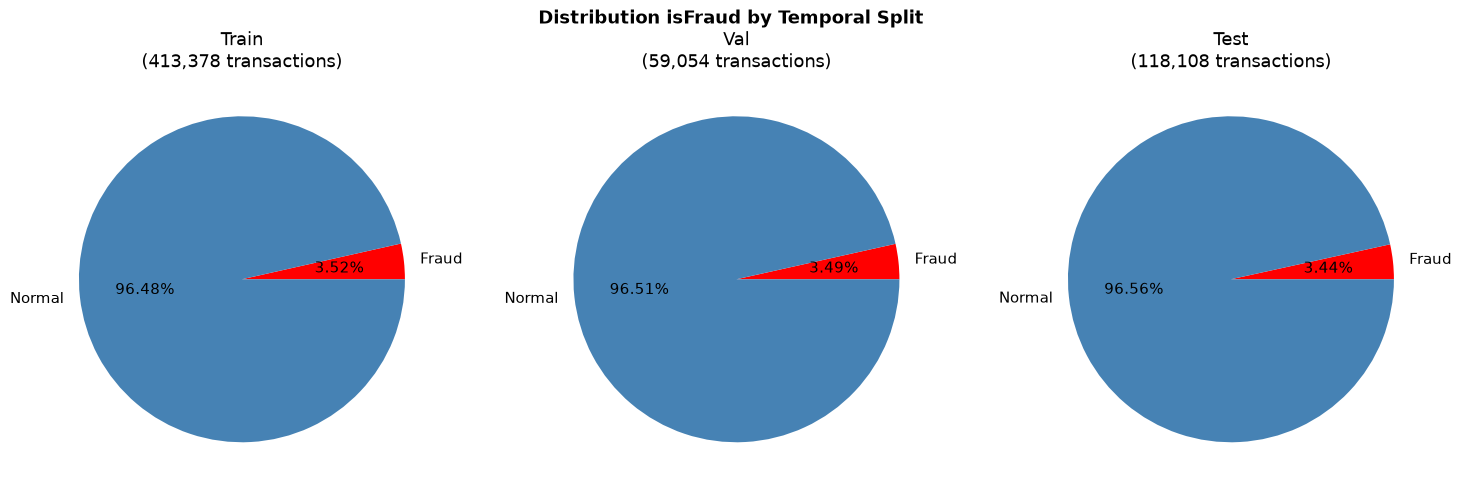


CELL 9 VERIFICATION
✅ Train: 413,378
✅ Val:   59,054
✅ Test:  118,108
✅ Train fraud rate: 3.5169%
✅ Val fraud rate:   3.4900%
✅ Test fraud rate:  3.4409%
✅ Categorical columns encoded: 30
✅ NaN indicators: 20
✅ Final X_train shape: (413378, 512)
✅ Final X_val shape:   (59054, 512)
✅ Final X_test shape:  (118108, 512)

✅ CELL 9 completed successfully!


In [17]:
# ============================================
# CELL 9: ENCODING + DIVISION TEMPORELLE
# LEAKAGE-SAFE VERSION
# ============================================

print("=" * 60)
print("CELL 9: Encoding + Temporal Split")
print("=" * 60)


# =========================================================
# 0. VERIFY CHRONOLOGICAL ORDER
# =========================================================

print("\n0. Vérification ordre temporel...")

if 'TransactionDT' not in df.columns:
    raise ValueError("❌ TransactionDT is required.")

is_sorted = df['TransactionDT'].is_monotonic_increasing

print(f"   Chronological order: {is_sorted}")

if not is_sorted:
    print("⚠️ Data is not sorted. Sorting now...")
    df = df.sort_values(
        'TransactionDT',
        kind='mergesort'
    ).reset_index(drop=True)
else:
    print("   ✅ Data already sorted chronologically")


# =========================================================
# 1. ADD NaN INDICATORS
# =========================================================

print("\n1. Adding NaN Indicators...")

excluded_nan_cols = [
    'isFraud',
    'TransactionID',
    'TransactionDT'
]

# Candidate columns with meaningful missingness
nan_candidates = []

for c in df.columns:

    if c in excluded_nan_cols:
        continue

    nan_rate = df[c].isnull().mean()

    if 0 < nan_rate < 0.90:
        nan_candidates.append(
            (c, df[c].isnull().sum(), nan_rate)
        )

# Sort by missingness
nan_candidates = sorted(
    nan_candidates,
    key=lambda x: x[2],
    reverse=True
)

# Keep the 20 most relevant
informative_cols = [
    x[0] for x in nan_candidates[:20]
]

for col in informative_cols:

    flag_name = f'{col}_nan_flag'

    # Avoid recreating existing columns
    if flag_name not in df.columns:

        df[flag_name] = (
            df[col].isnull()
        ).astype(int)

print(f"   ✅ NaN Indicators created: {len(informative_cols)}")

if informative_cols:
    print("   Features selected:")
    for col in informative_cols:
        print(f"      ✓ {col}")


# =========================================================
# 2. TEMPORAL SPLIT BEFORE ENCODING
# =========================================================

print("\n2. Temporal Split...")

if 'isFraud' not in df.columns:
    raise ValueError("❌ isFraud target is missing.")

X = df.drop('isFraud', axis=1)
y = df['isFraud']

train_size = int(len(X) * 0.70)
val_size = int(len(X) * 0.10)

train_end = train_size
val_end = train_size + val_size

X_train = X.iloc[:train_end].copy()
y_train = y.iloc[:train_end].copy()

X_val = X.iloc[train_end:val_end].copy()
y_val = y.iloc[train_end:val_end].copy()

X_test = X.iloc[val_end:].copy()
y_test = y.iloc[val_end:].copy()

print(f"   Train: {X_train.shape}")
print(f"   Val:   {X_val.shape}")
print(f"   Test:  {X_test.shape}")


# =========================================================
# 3. VERIFY TEMPORAL SPLIT
# =========================================================

print("\n3. Temporal Split Verification...")

if 'TransactionDT' in X_train.columns:

    train_max_dt = X_train['TransactionDT'].max()
    val_min_dt = X_val['TransactionDT'].min()
    val_max_dt = X_val['TransactionDT'].max()
    test_min_dt = X_test['TransactionDT'].min()

    print(f"   Train max DT: {train_max_dt}")
    print(f"   Val min DT:   {val_min_dt}")
    print(f"   Val max DT:   {val_max_dt}")
    print(f"   Test min DT:  {test_min_dt}")

    assert train_max_dt <= val_min_dt
    assert val_max_dt <= test_min_dt

    print("   ✅ No temporal overlap between splits.")


# =========================================================
# 4. REMOVE IDENTIFIERS / TIME FROM MODEL INPUT
# =========================================================

print("\n4. Removing identifiers...")

drop_cols = [
    'TransactionID',
    'TransactionDT'
]

drop_cols_existing = [
    c for c in drop_cols
    if c in X_train.columns
]

X_train = X_train.drop(
    columns=drop_cols_existing
)

X_val = X_val.drop(
    columns=drop_cols_existing
)

X_test = X_test.drop(
    columns=drop_cols_existing
)

print(f"   ✅ Removed: {drop_cols_existing}")


# =========================================================
# 5. LABEL ENCODING - TRAIN ONLY
# =========================================================

print("\n5. Label Encoding...")

cat_cols = X_train.select_dtypes(
    include=['object']
).columns.tolist()

print(f"   Categorical columns: {len(cat_cols)}")

# Dictionary to keep mappings
label_mappings = {}

for col in cat_cols:

    # Convert everything to string
    train_values = (
        X_train[col]
        .fillna('__MISSING__')
        .astype(str)
    )

    val_values = (
        X_val[col]
        .fillna('__MISSING__')
        .astype(str)
    )

    test_values = (
        X_test[col]
        .fillna('__MISSING__')
        .astype(str)
    )

    # Categories learned ONLY from training
    categories = sorted(
        train_values.unique()
    )

    mapping = {
        value: idx
        for idx, value in enumerate(categories)
    }

    label_mappings[col] = mapping

    # Unknown categories -> -1
    X_train[col] = train_values.map(mapping).fillna(-1).astype(int)

    X_val[col] = val_values.map(mapping).fillna(-1).astype(int)

    X_test[col] = test_values.map(mapping).fillna(-1).astype(int)

    unknown_val = (
        X_val[col] == -1
    ).mean()

    unknown_test = (
        X_test[col] == -1
    ).mean()

    print(
        f"   ✓ {col}: "
        f"{len(categories)} categories | "
        f"Unknown Val={unknown_val:.2%} | "
        f"Unknown Test={unknown_test:.2%}"
    )

print("   ✅ Label Encoding completed using Train only.")


# =========================================================
# 6. SPLIT ANALYSIS
# =========================================================

print("\n6. Analyse des splits:")

for name, X_s, y_s in [
    ('Train', X_train, y_train),
    ('Val', X_val, y_val),
    ('Test', X_test, y_test)
]:

    print(f"\n{name}:")
    print(f"   Shape: {X_s.shape}")
    print(
        f"   Fraud: {y_s.mean():.4%} "
        f"({y_s.sum():,} transactions)"
    )


# =========================================================
# 7. DATA LEAKAGE CHECK
# =========================================================

print("\n7. Data Leakage Verification...")

assert 'TransactionDT' not in X_train.columns
assert 'TransactionDT' not in X_val.columns
assert 'TransactionDT' not in X_test.columns

assert 'TransactionID' not in X_train.columns
assert 'TransactionID' not in X_val.columns
assert 'TransactionID' not in X_test.columns

print("   ✅ TransactionDT absent from model inputs")
print("   ✅ TransactionID absent from model inputs")


# =========================================================
# 8. INDEX ALIGNMENT
# =========================================================

print("\n8. Index Verification...")

assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

assert X_train.index.equals(y_train.index)
assert X_val.index.equals(y_val.index)
assert X_test.index.equals(y_test.index)

print("   ✅ X/y alignment correct")


# =========================================================
# 9. DISTRIBUTION VISUALIZATION
# =========================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5)
)

for idx, (name, y_s) in enumerate([
    ('Train', y_train),
    ('Val', y_val),
    ('Test', y_test)
]):

    axes[idx].pie(
        [
            y_s.sum(),
            (y_s == 0).sum()
        ],
        labels=['Fraud', 'Normal'],
        colors=['red', 'steelblue'],
        autopct='%1.2f%%'
    )

    axes[idx].set_title(
        f'{name}\n({len(y_s):,} transactions)'
    )

plt.suptitle(
    'Distribution isFraud by Temporal Split',
    fontsize=13,
    fontweight='bold'
)

plt.tight_layout()
plt.show()


# =========================================================
# FINAL SUMMARY
# =========================================================

print("\n" + "=" * 60)
print("CELL 9 VERIFICATION")
print("=" * 60)

print(f"✅ Train: {len(X_train):,}")
print(f"✅ Val:   {len(X_val):,}")
print(f"✅ Test:  {len(X_test):,}")

print(
    f"✅ Train fraud rate: {y_train.mean():.4%}"
)

print(
    f"✅ Val fraud rate:   {y_val.mean():.4%}"
)

print(
    f"✅ Test fraud rate:  {y_test.mean():.4%}"
)

print(
    f"✅ Categorical columns encoded: {len(cat_cols)}"
)

print(
    f"✅ NaN indicators: {len(informative_cols)}"
)

print(
    f"✅ Final X_train shape: {X_train.shape}"
)

print(
    f"✅ Final X_val shape:   {X_val.shape}"
)

print(
    f"✅ Final X_test shape:  {X_test.shape}"
)

print("\n✅ CELL 9 completed successfully!")
print("=" * 60)

## CELL 10: TARGET ENCODING + NaN PROCESSING

In [18]:
# ============================================
# CELL 10: PREPROCESSING + NaN PROCESSING
# TARGET ENCODING WILL BE DONE IN CELL 13B
# ============================================

print("=" * 60)
print("CELL 10: Preprocessing + NaN Processing")
print("=" * 60)


# =========================================================
# 1. SAVE UID KEYS FOR LATER TEMPORAL TARGET ENCODING
# =========================================================

print("\n1. Saving UID keys for later CV...")

if 'uid' in X_train.columns:

    uid_raw_train = X_train['uid'].copy()
    uid_raw_val = X_val['uid'].copy()
    uid_raw_test = X_test['uid'].copy()

    print("   ✅ UID key saved")
    print(
        f"   Train unique UID: "
        f"{uid_raw_train.nunique():,}"
    )
    print(
        f"   Val unique UID:   "
        f"{uid_raw_val.nunique():,}"
    )
    print(
        f"   Test unique UID:  "
        f"{uid_raw_test.nunique():,}"
    )

elif (
    'uid_raw_train' in globals()
    and 'uid_raw_val' in globals()
    and 'uid_raw_test' in globals()
):

    print(
        "   ℹ️ UID backup already exists."
    )

    print(
        f"   Train unique UID: "
        f"{uid_raw_train.nunique():,}"
    )
    print(
        f"   Val unique UID:   "
        f"{uid_raw_val.nunique():,}"
    )
    print(
        f"   Test unique UID:  "
        f"{uid_raw_test.nunique():,}"
    )

else:

    uid_raw_train = None
    uid_raw_val = None
    uid_raw_test = None

    print(
        "   ⚠️ UID column not found and "
        "no backup exists."
    )


# =========================================================
# 2. TARGET ENCODING CONFIGURATION
# =========================================================

print("\n2. Target Encoding configuration...")

# card4 / ProductCD (<=5 categories) are NOT target-encoded:
# trees handle the label codes directly and TE adds nothing there.
TE_COLS = [
    'card1',
    'card2',
    'addr1',
    'P_emaildomain'
]

TE_COLS = [
    c for c in TE_COLS
    if c in X_train.columns
]

print(
    "   Target Encoding columns reserved "
    "for CELL 13B:"
)

for col in TE_COLS:
    print(f"      ✓ {col}")

if uid_raw_train is not None:
    print("      ✓ uid")


# =========================================================
# 3. REMOVE RAW UID FROM MODEL INPUT
# =========================================================

print("\n3. Removing raw UID from model input...")

if 'uid' in X_train.columns:

    X_train = X_train.drop(
        columns=['uid']
    )

    X_val = X_val.drop(
        columns=['uid']
    )

    X_test = X_test.drop(
        columns=['uid']
    )

    print(
        "   ✅ Original UID removed from "
        "X_train/X_val/X_test"
    )

else:

    print(
        "   ℹ️ UID already removed."
    )


# =========================================================
# 4. FIND ALL COLUMNS WITH NaN
# =========================================================

print("\n4. Detecting NaN values...")

# We look for NaN in ANY split.
nan_cols_all = sorted(set(
    X_train.columns[
        X_train.isnull().any()
    ].tolist()
    +
    X_val.columns[
        X_val.isnull().any()
    ].tolist()
    +
    X_test.columns[
        X_test.isnull().any()
    ].tolist()
))

print(
    f"   Columns with NaN in at least one split: "
    f"{len(nan_cols_all)}"
)


# =========================================================
# 5. FILL NaN USING TRAIN-ONLY MEDIANS
# =========================================================

print("\n5. Applying Train-only median imputation...")

train_medians = {}

for col in nan_cols_all:

    # Median MUST come only from training data
    median_val = X_train[col].median()

    # If entire training column is NaN
    if pd.isna(median_val):
        median_val = 0

    train_medians[col] = median_val

    # Apply same Train-derived value
    # to all three splits
    X_train[col] = X_train[col].fillna(
        median_val
    )

    X_val[col] = X_val[col].fillna(
        median_val
    )

    X_test[col] = X_test[col].fillna(
        median_val
    )

print(
    "   ✅ Median imputation completed."
)
print(
    "   ℹ️ All medians were calculated "
    "from X_train only."
)


# =========================================================
# 6. NaN VERIFICATION
# =========================================================

print("\n6. NaN / Inf Verification...")

train_nan = X_train.isnull().sum().sum()
val_nan = X_val.isnull().sum().sum()
test_nan = X_test.isnull().sum().sum()

numeric_train = X_train.select_dtypes(
    include=np.number
)

numeric_val = X_val.select_dtypes(
    include=np.number
)

numeric_test = X_test.select_dtypes(
    include=np.number
)

train_inf = np.isinf(
    numeric_train
).sum().sum()

val_inf = np.isinf(
    numeric_val
).sum().sum()

test_inf = np.isinf(
    numeric_test
).sum().sum()


print(
    f"   Train NaN: {train_nan:,}"
)

print(
    f"   Val NaN:   {val_nan:,}"
)

print(
    f"   Test NaN:  {test_nan:,}"
)

print(
    f"   Train Inf: {train_inf:,}"
)

print(
    f"   Val Inf:   {val_inf:,}"
)

print(
    f"   Test Inf:  {test_inf:,}"
)


assert train_nan == 0
assert val_nan == 0
assert test_nan == 0

assert train_inf == 0
assert val_inf == 0
assert test_inf == 0

print(
    "   ✅ No NaN remaining."
)

print(
    "   ✅ No Inf remaining."
)


# =========================================================
# 7. INDEX ALIGNMENT
# =========================================================

print("\n7. Index Alignment...")

assert X_train.index.equals(
    y_train.index
)

assert X_val.index.equals(
    y_val.index
)

assert X_test.index.equals(
    y_test.index
)

print(
    "   ✅ X/y alignment correct."
)


# =========================================================
# 8. TARGET ENCODING LEAKAGE CHECK
# =========================================================

print("\n8. Target Encoding Leakage Check...")

existing_te = [
    c for c in X_train.columns
    if c.endswith('_target_enc')
]

if existing_te:

    print(
        "   ⚠️ Existing Target Encoding columns:"
    )

    for col in existing_te:
        print(f"      - {col}")

    raise ValueError(
        "❌ Target Encoding must not exist "
        "before CELL 13B."
    )

else:

    print(
        "   ✅ No Target Encoding columns "
        "exist yet."
    )

print(
    "   ℹ️ Target Encoding will be created "
    "inside temporal CV in CELL 13B."
)


# =========================================================
# 9. FINAL SHAPES
# =========================================================

print("\n9. Final Shapes...")

print(
    f"   X_train: {X_train.shape}"
)

print(
    f"   X_val:   {X_val.shape}"
)

print(
    f"   X_test:  {X_test.shape}"
)


# =========================================================
# FINAL SUMMARY
# =========================================================

print("\n" + "=" * 60)
print("CELL 10 VERIFICATION")
print("=" * 60)

print(
    f"✅ Train: {len(X_train):,}"
)

print(
    f"✅ Val:   {len(X_val):,}"
)

print(
    f"✅ Test:  {len(X_test):,}"
)

print(
    f"✅ NaN columns processed: "
    f"{len(nan_cols_all)}"
)

print(
    f"✅ TE columns reserved: "
    f"{len(TE_COLS)}"
)

print(
    f"✅ UID backup available: "
    f"{uid_raw_train is not None}"
)

print(
    f"✅ Final X_train shape: "
    f"{X_train.shape}"
)

print(
    f"✅ Final X_val shape:   "
    f"{X_val.shape}"
)

print(
    f"✅ Final X_test shape:  "
    f"{X_test.shape}"
)

print(
    "\n✅ CELL 10 completed successfully!"
)

print("=" * 60)

CELL 10: Preprocessing + NaN Processing

1. Saving UID keys for later CV...
   ✅ UID key saved
   Train unique UID: 168,122
   Val unique UID:   15,906
   Test unique UID:  18,159

2. Target Encoding configuration...
   Target Encoding columns reserved for CELL 13B:
      ✓ card1
      ✓ card2
      ✓ addr1
      ✓ P_emaildomain
      ✓ uid

3. Removing raw UID from model input...
   ✅ Original UID removed from X_train/X_val/X_test

4. Detecting NaN values...
   Columns with NaN in at least one split: 393

5. Applying Train-only median imputation...
   ✅ Median imputation completed.
   ℹ️ All medians were calculated from X_train only.

6. NaN / Inf Verification...
   Train NaN: 0
   Val NaN:   0
   Test NaN:  0
   Train Inf: 0
   Val Inf:   0
   Test Inf:  0
   ✅ No NaN remaining.
   ✅ No Inf remaining.

7. Index Alignment...
   ✅ X/y alignment correct.

8. Target Encoding Leakage Check...
   ✅ No Target Encoding columns exist yet.
   ℹ️ Target Encoding will be created inside temporal 

## CELL 10D: Baseline - Logistic Regression

In [19]:
# ============================================
# CELL 10D: Baseline - Logistic Regression
# ============================================

if 'results' not in dir():
    results = {}
if 'scale_weight' not in dir():
    fraud_count = y_train.sum()
    normal_count = len(y_train) - fraud_count
    scale_weight = normal_count / fraud_count
    print(f"✅ scale_weight calculated locally: {scale_weight:.2f}")
print("="*60)
print("Baseline: Logistics Regression")
print("="*60)

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# Logistic regression requires normalized features
scaler_baseline = StandardScaler()
X_train_scaled = scaler_baseline.fit_transform(
    X_train.fillna(0)
)
X_val_scaled = scaler_baseline.transform(X_val.fillna(0))
X_test_scaled = scaler_baseline.transform(X_test.fillna(0))

model_baseline = LogisticRegression(
    class_weight='balanced',  # equivalent to scale_pos_weight
    max_iter=1000,
    random_state=42,
)
model_baseline.fit(X_train_scaled, y_train)

y_pred_proba_baseline = model_baseline.predict_proba(
    X_test_scaled
)[:, 1]
auc_baseline = roc_auc_score(y_test, y_pred_proba_baseline)

# Threshold selected on VALIDATION (never on test)
y_val_proba_baseline = model_baseline.predict_proba(X_val_scaled)[:, 1]
thresholds = np.arange(0.1, 0.9, 0.01)
f1_baseline = [
    f1_score(y_val, (y_val_proba_baseline > t).astype(int))
    for t in thresholds
]
best_thresh_baseline = thresholds[np.argmax(f1_baseline)]
y_pred_baseline = (
    y_pred_proba_baseline > best_thresh_baseline
).astype(int)

print(f"\n🎯 AUC-ROC Baseline (Logistic Regression): "
      f"{auc_baseline:.4f}")
print(classification_report(
    y_test, y_pred_baseline, target_names=['Normal', 'Fraud']
))

results['Baseline_LogisticRegression'] = {
    'AUC': auc_baseline,
    'Recall': recall_score(y_test, y_pred_baseline),
    'Precision': precision_score(y_test, y_pred_baseline),
    'F1': f1_score(y_test, y_pred_baseline),
}

print(f"\n📊 Gain provided by advanced models (to be compared)"
      f"after CatBoost):")
print(f"   Baseline AUC: {auc_baseline:.4f}")
print("   → Compare this figure to CatBoost (≈0.90) in the"
      "final table (CELL 18)")
print("✅ Baseline 100% complete!")

✅ scale_weight calculated locally: 27.43
Baseline: Logistics Regression

🎯 AUC-ROC Baseline (Logistic Regression): 0.8274
              precision    recall  f1-score   support

      Normal       0.98      0.95      0.96    114044
       Fraud       0.24      0.45      0.31      4064

    accuracy                           0.93    118108
   macro avg       0.61      0.70      0.64    118108
weighted avg       0.95      0.93      0.94    118108


📊 Gain provided by advanced models (to be compared)after CatBoost):
   Baseline AUC: 0.8274
   → Compare this figure to CatBoost (≈0.90) in thefinal table (CELL 18)
✅ Baseline 100% complete!


## CELL 10E: Comparison of Imbalance Strategies

In [20]:
# ============================================
# CELL 10E: Comparison of Imbalance Strategies
# ============================================
print("="*60)
print("Comparaison: scale_pos_weight vs SMOTE vs Undersampling")
print("="*60)

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
import time

if 'results' not in dir():
    results = {}

# Local calculation of scale_weight (this cell can be executed
# before CELL 11, which calculates it normally — therefore we cannot
# depend on its presence in memory)
if 'scale_weight' not in dir():
    fraud_count = y_train.sum()
    normal_count = len(y_train) - fraud_count
    scale_weight = normal_count / fraud_count
    print(f"✅ scale_weight calculated locally: {scale_weight:.2f}")

# Hyperparamètres fixes (identiques pour les 3 stratégies,
# comparaison équitable — pas d'Optuna ici pour rester rapide)
fixed_lgb_params = {
    'objective': 'binary', 'metric': 'auc',
    'n_estimators': 500, 'learning_rate': 0.05,
    'num_leaves': 64, 'random_state': 42, 'verbose': -1,
}


def train_eval(X_tr, y_tr, label, extra_params=None):
    t0 = time.time()
    params = {**fixed_lgb_params, **(extra_params or {})}
    model = lgb.LGBMClassifier(**params)
    model.fit(X_tr, y_tr)

    proba = model.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, proba)

    # Threshold selected on VALIDATION (never on test)
    proba_val = model.predict_proba(X_val)[:, 1]
    thresholds = np.arange(0.1, 0.9, 0.01)
    f1s = [f1_score(y_val, (proba_val > t).astype(int))
           for t in thresholds]
    best_t = thresholds[np.argmax(f1s)]
    pred = (proba > best_t).astype(int)

    elapsed = time.time() - t0
    print(f"\n--- {label} ---")
    print(f"Train size: {len(X_tr):,} rows "
          f"({y_tr.mean()*100:.1f}% fraud)")
    print(f"Training time: {elapsed:.1f}s")
    print(f"AUC: {auc:.4f} | F1: {f1_score(y_test, pred):.4f} | "
          f"Precision: {precision_score(y_test, pred):.4f} | "
          f"Recall: {recall_score(y_test, pred):.4f}")

    results[f'Imbalance_{label}'] = {
        'AUC': auc,
        'Recall': recall_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'F1': f1_score(y_test, pred),
    }
    return auc


# ===== 1. Class weighting (current project approach) =====
auc_weighted = train_eval(
    X_train, y_train, "ClassWeight",
    extra_params={'scale_pos_weight': scale_weight}
)

# ===== 2. SMOTE (synthetic minority oversampling technique) =====
# sampling_strategy=0.3 : the minority class reaches 30% of the
# majority class (not 100%, to remain realistic in terms of computation time)
print("\nApplication of SMOTE (may take a few minutes)...")
smote = SMOTE(sampling_strategy=0.3, random_state=42, k_neighbors=5)
X_train_smote, y_train_smote = smote.fit_resample(
    X_train.fillna(0), y_train
)
auc_smote = train_eval(X_train_smote, y_train_smote, "SMOTE")

# ===== 3. Random Undersampling =====
under = RandomUnderSampler(sampling_strategy=0.3, random_state=42)
X_train_under, y_train_under = under.fit_resample(
    X_train.fillna(0), y_train
)
auc_under = train_eval(X_train_under, y_train_under, "Undersampling")

# ===== Synthesis =====
print("\n" + "="*60)
print("SYNTHESIS")
print("="*60)
summary = pd.DataFrame({
    'Stratégie': ['ClassWeight (actuel)', 'SMOTE', 'Undersampling'],
    'AUC': [auc_weighted, auc_smote, auc_under],
    'Taille Train': [len(X_train), len(X_train_smote),
                      len(X_train_under)],
})
print(summary.to_string(index=False))
print("\n✅ Comparison completed!")

Comparaison: scale_pos_weight vs SMOTE vs Undersampling

--- ClassWeight ---
Train size: 413,378 rows (3.5% fraud)
Training time: 53.9s
AUC: 0.8962 | F1: 0.5035 | Precision: 0.6023 | Recall: 0.4326

Application of SMOTE (may take a few minutes)...

--- SMOTE ---
Train size: 518,492 rows (23.1% fraud)
Training time: 121.6s
AUC: 0.9039 | F1: 0.4940 | Precision: 0.5090 | Recall: 0.4798

--- Undersampling ---
Train size: 62,998 rows (23.1% fraud)
Training time: 20.2s
AUC: 0.9097 | F1: 0.4967 | Precision: 0.5325 | Recall: 0.4653

SYNTHESIS
           Stratégie    AUC  Taille Train
ClassWeight (actuel) 0.8962        413378
               SMOTE 0.9039        518492
       Undersampling 0.9097         62998

✅ Comparison completed!


## CELL 11: LIGHTGBM + OPTUNA TUNING

In [21]:
# ============================================
# CELL 11: LIGHTGBM + OPTUNA TUNING
# ============================================
print("="*60)
print("ÉTAPE 10: LightGBM + Optuna")
print("="*60)

# Install Optuna
import subprocess
subprocess.run(['pip', 'install', 'optuna', '-q'])
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

fraud_count  = y_train.sum()
normal_count = len(y_train) - fraud_count
scale_weight = normal_count / fraud_count
print(f"Scale Weight: {scale_weight:.2f}")

# ===== Optuna Objective =====
def objective(trial):
    params = {
        'objective':         'binary',
        'metric':            'auc',
        'verbosity':         -1,
        'random_state':      42,
        'scale_pos_weight':  scale_weight,
        'learning_rate':     trial.suggest_float(
            'learning_rate', 0.01, 0.1, log=True
        ),
        'num_leaves':        trial.suggest_int(
            'num_leaves', 31, 256
        ),
        'max_depth':         trial.suggest_int(
            'max_depth', 4, 12
        ),
        'min_child_samples': trial.suggest_int(
            'min_child_samples', 20, 100
        ),
        'feature_fraction':  trial.suggest_float(
            'feature_fraction', 0.5, 1.0
        ),
        'bagging_fraction':  trial.suggest_float(
            'bagging_fraction', 0.5, 1.0
        ),
        'bagging_freq':      trial.suggest_int(
            'bagging_freq', 1, 7
        ),
        'reg_alpha':         trial.suggest_float(
            'reg_alpha', 0.0, 2.0
        ),
        'reg_lambda':        trial.suggest_float(
            'reg_lambda', 0.0, 2.0
        ),
    }

    model = lgb.LGBMClassifier(
        **params, n_estimators=500
    )
    model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        callbacks=[
            lgb.early_stopping(30, verbose=False),
            lgb.log_evaluation(-1)
        ]
    )

    y_pred = model.predict_proba(X_val)[:, 1]
    return roc_auc_score(y_val, y_pred)

# ===== Optuna operation=====
print("Running Optuna (50 trials)...")
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=50, show_progress_bar=True)

print(f"\n✅ Best AUC: {study.best_value:.4f}")
print(f"✅ Best Parameters:")
for k, v in study.best_params.items():
    print(f"   {k}: {v}")

# ===== train the final model =====
best_params = study.best_params
best_params.update({
    'objective':        'binary',
    'metric':           'auc',
    'verbosity':        -1,
    'random_state':     42,
    'scale_pos_weight': scale_weight
})

print("\ntrain the final model...")
model_lgb_final = lgb.LGBMClassifier(
    **best_params,
    n_estimators=2000
)
model_lgb_final.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    callbacks=[
        lgb.early_stopping(100, verbose=True),
        lgb.log_evaluation(200)
    ]
)

print(f"\n✅ Best iteration: "
      f"{model_lgb_final.best_iteration_}")

# Used by CELL 13B (no early stopping on the OOF fold there)
lgb_best_n_estimators = int(model_lgb_final.best_iteration_)

ÉTAPE 10: LightGBM + Optuna
Scale Weight: 27.43
Running Optuna (50 trials)...


Best trial: 38. Best value: 0.94114: 100%|██████████| 50/50 [1:12:38<00:00, 87.16s/it] 



✅ Best AUC: 0.9411
✅ Best Parameters:
   learning_rate: 0.040942137325423594
   num_leaves: 156
   max_depth: 12
   min_child_samples: 57
   feature_fraction: 0.8605114822997655
   bagging_fraction: 0.8168576150514825
   bagging_freq: 4
   reg_alpha: 1.0106488779484715
   reg_lambda: 1.8409657262921024

train the final model...
Training until validation scores don't improve for 100 rounds
[200]	valid_0's auc: 0.93361
[400]	valid_0's auc: 0.939366
[600]	valid_0's auc: 0.941331
Early stopping, best iteration is:
[547]	valid_0's auc: 0.941612

✅ Best iteration: 547


## CELL 12: LIGHTGBM EVALUATION

ÉTAPE 11: LightGBM Evaluation
🎯 AUC-ROC LightGBM: 0.9057
🎯 Best Threshold:   0.59
              precision    recall  f1-score   support

      Normal       0.98      0.99      0.99    114044
      Fraude       0.62      0.45      0.52      4064

    accuracy                           0.97    118108
   macro avg       0.80      0.72      0.75    118108
weighted avg       0.97      0.97      0.97    118108



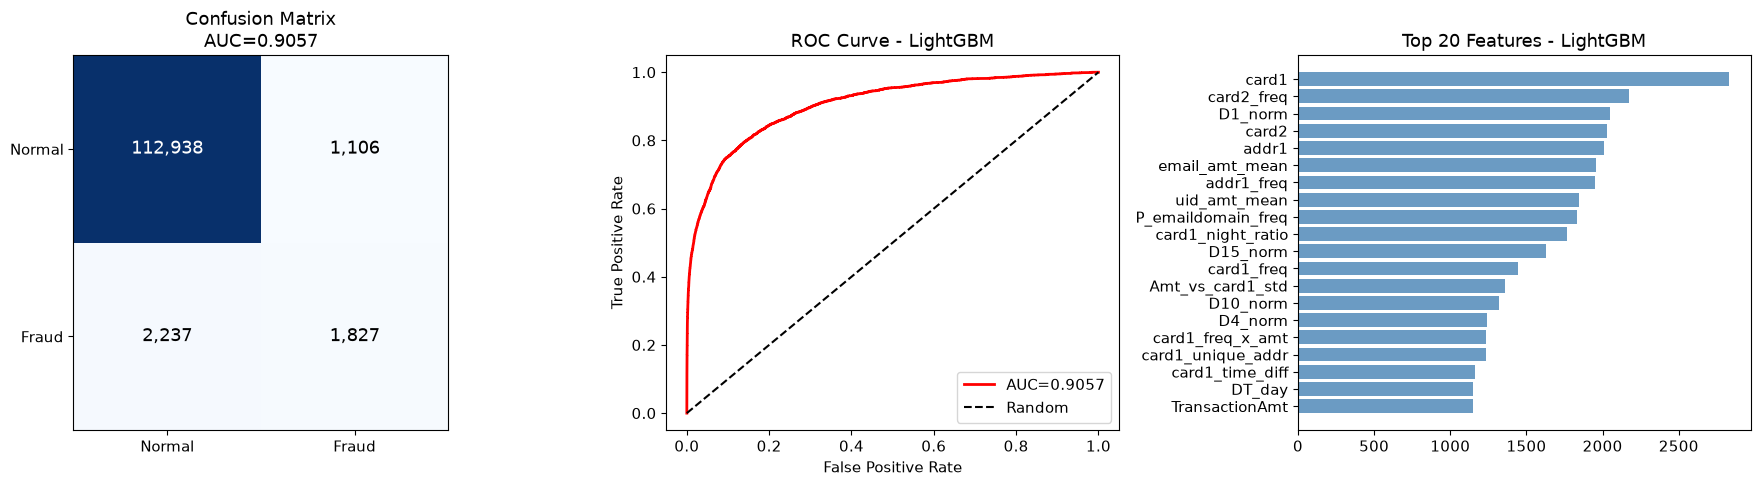


✅ result the LightGBM saved!


In [22]:
# ============================================
# CELL 12: LIGHTGBM EVALUATION
# ============================================
print("="*60)
print("ÉTAPE 11: LightGBM Evaluation")
print("="*60)

y_pred_proba_lgb = model_lgb_final.predict_proba(
    X_test
)[:, 1]
auc_lgb = roc_auc_score(y_test, y_pred_proba_lgb)

# best threshold
# Threshold selected on VALIDATION (never on test)
y_val_proba_lgb = model_lgb_final.predict_proba(X_val)[:, 1]
thresholds  = np.arange(0.1, 0.9, 0.01)
f1_scores_t = [
    f1_score(
        y_val,
        (y_val_proba_lgb > t).astype(int)
    )
    for t in thresholds
]
best_thresh_lgb = thresholds[np.argmax(f1_scores_t)]
y_pred_lgb = (
    y_pred_proba_lgb > best_thresh_lgb
).astype(int)

print(f"🎯 AUC-ROC LightGBM: {auc_lgb:.4f}")
print(f"🎯 Best Threshold:   {best_thresh_lgb:.2f}")
print(classification_report(
    y_test, y_pred_lgb,
    target_names=['Normal','Fraude']
))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_lgb)
axes[0].imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        axes[0].text(
            j, i, f'{cm[i,j]:,}',
            ha='center', va='center',
            fontsize=13,
            color='white'
            if cm[i,j] > cm.max()/2
            else 'black'
        )
axes[0].set_xticks([0,1])
axes[0].set_yticks([0,1])
axes[0].set_xticklabels(['Normal','Fraud'])
axes[0].set_yticklabels(['Normal','Fraud'])
axes[0].set_title(
    f'Confusion Matrix\nAUC={auc_lgb:.4f}'
)

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_pred_proba_lgb)
axes[1].plot(
    fpr, tpr, color='red',
    linewidth=2, label=f'AUC={auc_lgb:.4f}'
)
axes[1].plot(
    [0,1],[0,1], 'k--', label='Random'
)
axes[1].set_title('ROC Curve - LightGBM')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend()

# Feature Importance
feat_imp = pd.DataFrame({
    'Feature':    X_train.columns,
    'Importance': model_lgb_final.feature_importances_
}).sort_values('Importance', ascending=False).head(20)

axes[2].barh(
    feat_imp['Feature'],
    feat_imp['Importance'],
    color='steelblue', alpha=0.8
)
axes[2].set_title('Top 20 Features - LightGBM')
axes[2].invert_yaxis()

plt.tight_layout()
plt.show()

# save the model 
# Do NOT reset `results` (it already holds Baseline / Imbalance rows)
if 'results' not in dir():
    results = {}
results['LightGBM'] = {
    'AUC':       auc_lgb,
    'Recall':    recall_score(y_test, y_pred_lgb),
    'Precision': precision_score(y_test, y_pred_lgb),
    'F1':        f1_score(y_test, y_pred_lgb)
}
print("\n✅ result the LightGBM saved!")

## CELL 13: XGBoost - FIXED

STEP 12: XGBoost 100%
XGBoost version: 3.2.0
Optuna for XGBoost (30 trials)...


Best trial: 26. Best value: 0.938954: 100%|██████████| 30/30 [1:07:54<00:00, 135.83s/it]



✅ Best XGB AUC: 0.9390
✅ Best params:
   n_estimators: 478
   learning_rate: 0.08007561325888642
   max_depth: 9
   min_child_weight: 28
   subsample: 0.9648266781035157
   colsample_bytree: 0.9523076648223744
   reg_alpha: 0.9389147830483295
   reg_lambda: 0.7992437296380062
[0]	validation_0-auc:0.84916
[200]	validation_0-auc:0.93530
[400]	validation_0-auc:0.93826
[423]	validation_0-auc:0.93779

🎯 AUC-ROC XGBoost: 0.8982
🎯 Threshold: 0.64
              precision    recall  f1-score   support

      Normal       0.98      0.99      0.98    114044
      Fraude       0.59      0.44      0.50      4064

    accuracy                           0.97    118108
   macro avg       0.78      0.72      0.74    118108
weighted avg       0.97      0.97      0.97    118108



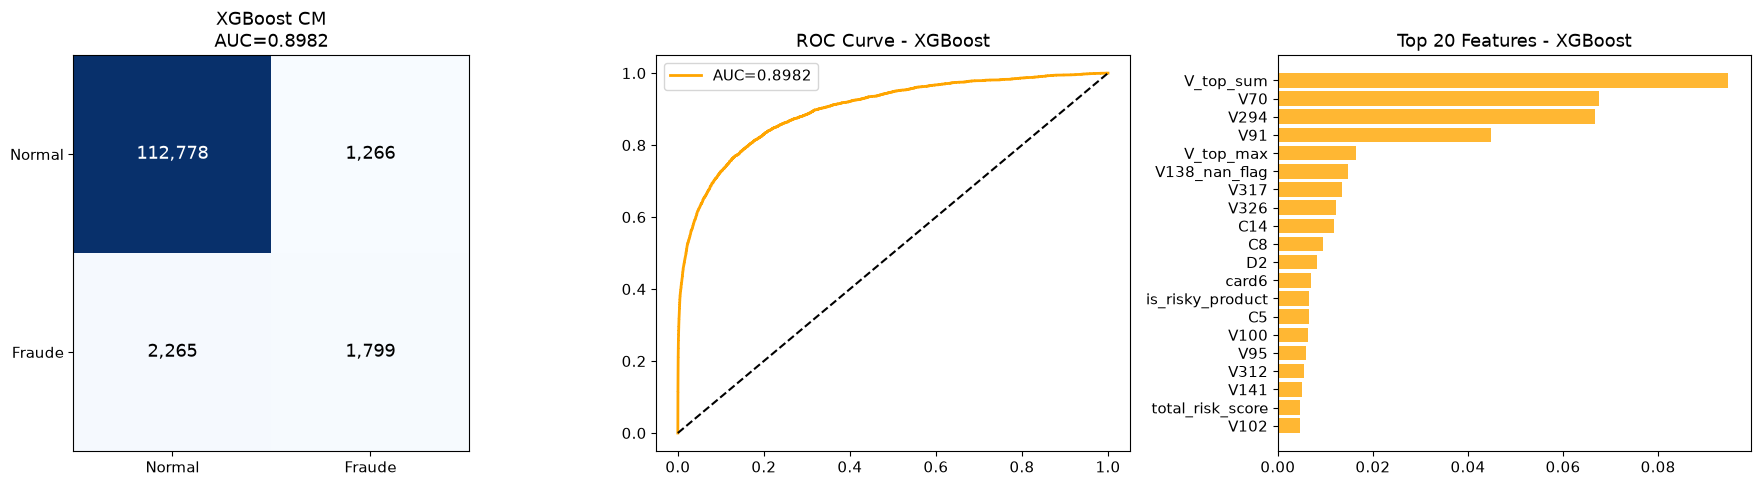

✅ XGBoost 100% complete!


In [23]:
# ============================================
# CELL 13: XGBOOST 100%
# ============================================
print("="*60)
print("STEP 12: XGBoost 100%")
print("="*60)

import xgboost as xgb
print(f"XGBoost version: {xgb.__version__}")

# ===== 1. Optuna forـ XGBoost =====
print("Optuna for XGBoost (30 trials)...")

fraud_count  = y_train.sum()
normal_count = len(y_train) - fraud_count
scale_w      = normal_count / fraud_count

def objective_xgb(trial):
    params = {
        'n_estimators':     trial.suggest_int(
            'n_estimators', 200, 1000
        ),
        'learning_rate':    trial.suggest_float(
            'learning_rate', 0.01, 0.3, log=True
        ),
        'max_depth':        trial.suggest_int(
            'max_depth', 3, 10
        ),
        'min_child_weight': trial.suggest_int(
            'min_child_weight', 10, 100
        ),
        'subsample':        trial.suggest_float(
            'subsample', 0.5, 1.0
        ),
        'colsample_bytree': trial.suggest_float(
            'colsample_bytree', 0.5, 1.0
        ),
        'reg_alpha':        trial.suggest_float(
            'reg_alpha', 0.0, 2.0
        ),
        'reg_lambda':       trial.suggest_float(
            'reg_lambda', 0.0, 2.0
        ),
        'scale_pos_weight': scale_w,
        'eval_metric':      'auc',
        'random_state':     42,
        'verbosity':        0,
        'early_stopping_rounds': 30
    }

    model = xgb.XGBClassifier(**params)
    model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        verbose=False
    )
    y_pred = model.predict_proba(X_val)[:,1]
    return roc_auc_score(y_val, y_pred)

study_xgb = optuna.create_study(
    direction='maximize'
)
study_xgb.optimize(
    objective_xgb,
    n_trials=30,
    show_progress_bar=True
)

print(f"\n✅ Best XGB AUC: {study_xgb.best_value:.4f}")
print(f"✅ Best params:")
for k, v in study_xgb.best_params.items():
    print(f"   {k}: {v}")

# ===== 2. train the last model&=====
best_xgb_params = study_xgb.best_params
best_xgb_params.update({
    'scale_pos_weight': scale_w,
    'eval_metric':      'auc',
    'random_state':     42,
    'verbosity':        0,
    'early_stopping_rounds': 50
})

model_xgb = xgb.XGBClassifier(**best_xgb_params)
model_xgb.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=200
)

# ===== 3. evaluation=====
y_pred_proba_xgb = model_xgb.predict_proba(
    X_test
)[:,1]
auc_xgb = roc_auc_score(y_test, y_pred_proba_xgb)

# Used by CELL 13B (no early stopping on the OOF fold there)
xgb_best_n_estimators = int(model_xgb.best_iteration) + 1

# Threshold selected on VALIDATION (never on test)
y_val_proba_xgb = model_xgb.predict_proba(X_val)[:, 1]
thresholds = np.arange(0.1, 0.9, 0.01)
f1_xgb = [
    f1_score(
        y_val,
        (y_val_proba_xgb>t).astype(int)
    )
    for t in thresholds
]
best_thresh_xgb = thresholds[np.argmax(f1_xgb)]
y_pred_xgb = (
    y_pred_proba_xgb > best_thresh_xgb
).astype(int)

print(f"\n🎯 AUC-ROC XGBoost: {auc_xgb:.4f}")
print(f"🎯 Threshold: {best_thresh_xgb:.2f}")
print(classification_report(
    y_test, y_pred_xgb,
    target_names=['Normal','Fraude']
))

# ===== 4. in-depth analysis=====
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Confusion Matrix
cm_xgb = confusion_matrix(y_test, y_pred_xgb)
axes[0].imshow(cm_xgb, cmap='Blues')
for i in range(2):
    for j in range(2):
        axes[0].text(
            j, i, f'{cm_xgb[i,j]:,}',
            ha='center', va='center',
            fontsize=13,
            color='white'
            if cm_xgb[i,j]>cm_xgb.max()/2
            else 'black'
        )
axes[0].set_xticks([0,1])
axes[0].set_yticks([0,1])
axes[0].set_xticklabels(['Normal','Fraude'])
axes[0].set_yticklabels(['Normal','Fraude'])
axes[0].set_title(
    f'XGBoost CM\nAUC={auc_xgb:.4f}'
)

# ROC Curve
fpr, tpr, _ = roc_curve(
    y_test, y_pred_proba_xgb
)
axes[1].plot(fpr, tpr, color='orange',
             linewidth=2,
             label=f'AUC={auc_xgb:.4f}')
axes[1].plot([0,1],[0,1],'k--')
axes[1].set_title('ROC Curve - XGBoost')
axes[1].legend()

# Feature Importance
xgb_imp = pd.DataFrame({
    'Feature':    X_train.columns,
    'Importance': model_xgb.feature_importances_
}).sort_values('Importance', ascending=False)

axes[2].barh(
    xgb_imp['Feature'].head(20),
    xgb_imp['Importance'].head(20),
    color='orange', alpha=0.8
)
axes[2].set_title('Top 20 Features - XGBoost')
axes[2].invert_yaxis()

plt.tight_layout()
plt.show()

results['XGBoost'] = {
    'AUC':       auc_xgb,
    'Recall':    recall_score(y_test, y_pred_xgb),
    'Precision': precision_score(y_test, y_pred_xgb),
    'F1':        f1_score(y_test, y_pred_xgb)
}
print("✅ XGBoost 100% complete!")

## CELL 13C: Catboost

STEP 12B: CatBoost
CatBoost version: 1.2.10
Optuna for CatBoost (30 trials)...


Best trial: 26. Best value: 0.938917: 100%|██████████| 30/30 [2:17:03<00:00, 274.12s/it] 



✅ Best CatBoost AUC: 0.9389
✅ Best params:
   iterations: 999
   learning_rate: 0.03693995765181412
   depth: 8
   l2_leaf_reg: 8.943172366309451
   border_count: 204
0:	test: 0.8418846	best: 0.8418846 (0)	total: 358ms	remaining: 5m 57s
200:	test: 0.9023486	best: 0.9023486 (200)	total: 1m 7s	remaining: 4m 29s
400:	test: 0.9199029	best: 0.9199029 (400)	total: 2m 10s	remaining: 3m 14s
600:	test: 0.9325527	best: 0.9325527 (600)	total: 3m 16s	remaining: 2m 9s
800:	test: 0.9373165	best: 0.9373879 (798)	total: 4m 20s	remaining: 1m 4s
998:	test: 0.9389172	best: 0.9389172 (998)	total: 5m 29s	remaining: 0us

bestTest = 0.9389172413
bestIteration = 998


🎯 AUC-ROC CatBoost: 0.9045
🎯 Threshold: 0.76
              precision    recall  f1-score   support

      Normal       0.98      0.99      0.98    114044
       Fraud       0.55      0.44      0.49      4064

    accuracy                           0.97    118108
   macro avg       0.76      0.71      0.74    118108
weighted avg       0.97      

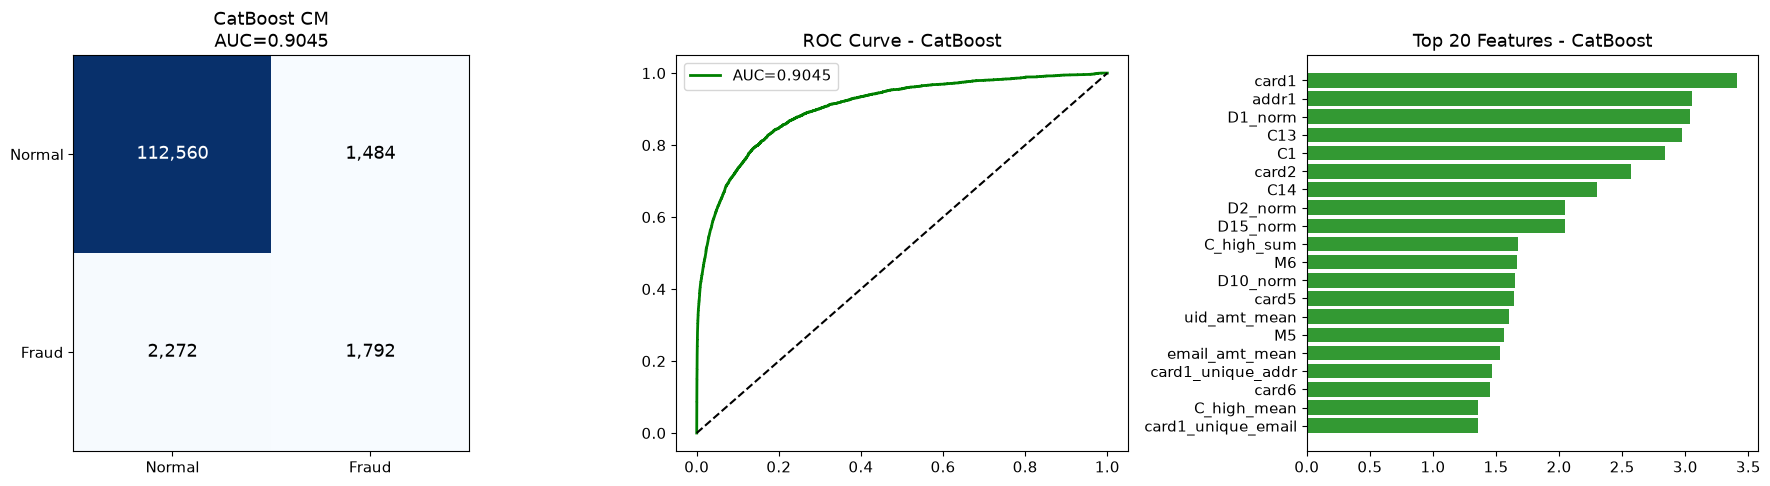

✅ CatBoost 100% complete!


In [24]:
# ============================================
# CELL 13C: CATBOOST
# ============================================
print("="*60)
print("STEP 12B: CatBoost")
print("="*60)

from catboost import CatBoostClassifier
import catboost
print(f"CatBoost version: {catboost.__version__}")

fraud_count  = y_train.sum()
normal_count = len(y_train) - fraud_count
scale_w_cb   = normal_count / fraud_count

# ===== 1. Optuna for CatBoost =====
print("Optuna for CatBoost (30 trials)...")

def objective_cb(trial):
    params = {
        'iterations':        trial.suggest_int(
            'iterations', 300, 1200
        ),
        'learning_rate':     trial.suggest_float(
            'learning_rate', 0.01, 0.3, log=True
        ),
        'depth':              trial.suggest_int(
            'depth', 4, 10
        ),
        'l2_leaf_reg':        trial.suggest_float(
            'l2_leaf_reg', 1.0, 10.0
        ),
        'border_count':       trial.suggest_int(
            'border_count', 32, 255
        ),
        'scale_pos_weight':   scale_w_cb,
        'eval_metric':        'AUC',
        'random_state':       42,
        'verbose':            False,
        'early_stopping_rounds': 30
    }

    model = CatBoostClassifier(**params)
    model.fit(
        X_train, y_train,
        eval_set=(X_val, y_val),
        verbose=False
    )
    y_pred = model.predict_proba(X_val)[:,1]
    return roc_auc_score(y_val, y_pred)

study_cb = optuna.create_study(direction='maximize')
study_cb.optimize(
    objective_cb, n_trials=30, show_progress_bar=True
)

print(f"\n✅ Best CatBoost AUC: {study_cb.best_value:.4f}")
print(f"✅ Best params:")
for k, v in study_cb.best_params.items():
    print(f"   {k}: {v}")

# ===== 2. Final model training=====
best_cb_params = study_cb.best_params
best_cb_params.update({
    'scale_pos_weight': scale_w_cb,
    'eval_metric':      'AUC',
    'random_state':     42,
    'verbose':          False,
    'early_stopping_rounds': 50
})

model_cb = CatBoostClassifier(**best_cb_params)
model_cb.fit(
    X_train, y_train,
    eval_set=(X_val, y_val),
    verbose=200
)

# ===== 3. evaluation=====
y_pred_proba_cb = model_cb.predict_proba(X_test)[:,1]
auc_cb = roc_auc_score(y_test, y_pred_proba_cb)

# Used by CELL 13B (no early stopping on the OOF fold there)
cb_best_n_iterations = int(model_cb.get_best_iteration()) + 1
# CELL 13B replaces model_cb with the full TE model; keep this one too
model_cb_13c = model_cb

# Threshold selected on VALIDATION (never on test)
y_val_proba_cb = model_cb.predict_proba(X_val)[:, 1]
thresholds = np.arange(0.1, 0.9, 0.01)
f1_cb = [
    f1_score(y_val, (y_val_proba_cb>t).astype(int))
    for t in thresholds
]
best_thresh_cb = thresholds[np.argmax(f1_cb)]
y_pred_cb = (y_pred_proba_cb > best_thresh_cb).astype(int)

print(f"\n🎯 AUC-ROC CatBoost: {auc_cb:.4f}")
print(f"🎯 Threshold: {best_thresh_cb:.2f}")
print(classification_report(
    y_test, y_pred_cb, target_names=['Normal','Fraud']
))

# ===== 4. in-depth analysis=====
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

cm_cb = confusion_matrix(y_test, y_pred_cb)
axes[0].imshow(cm_cb, cmap='Blues')
for i in range(2):
    for j in range(2):
        axes[0].text(
            j, i, f'{cm_cb[i,j]:,}',
            ha='center', va='center', fontsize=13,
            color='white' if cm_cb[i,j]>cm_cb.max()/2 else 'black'
        )
axes[0].set_xticks([0,1]); axes[0].set_yticks([0,1])
axes[0].set_xticklabels(['Normal','Fraud'])
axes[0].set_yticklabels(['Normal','Fraud'])
axes[0].set_title(f'CatBoost CM\nAUC={auc_cb:.4f}')

fpr, tpr, _ = roc_curve(y_test, y_pred_proba_cb)
axes[1].plot(fpr, tpr, color='green', linewidth=2,
             label=f'AUC={auc_cb:.4f}')
axes[1].plot([0,1],[0,1],'k--')
axes[1].set_title('ROC Curve - CatBoost')
axes[1].legend()

cb_imp = pd.DataFrame({
    'Feature':    X_train.columns,
    'Importance': model_cb.feature_importances_
}).sort_values('Importance', ascending=False)

axes[2].barh(
    cb_imp['Feature'].head(20),
    cb_imp['Importance'].head(20),
    color='green', alpha=0.8
)
axes[2].set_title('Top 20 Features - CatBoost')
axes[2].invert_yaxis()

plt.tight_layout()
plt.show()

results['CatBoost'] = {
    'AUC':       auc_cb,
    'Recall':    recall_score(y_test, y_pred_cb),
    'Precision': precision_score(y_test, y_pred_cb),
    'F1':        f1_score(y_test, y_pred_cb)
}
print("✅ CatBoost 100% complete!")

In [123]:
print(X_train.shape, 'study_cb' in dir(), 'cb_best_n_iterations' in dir())

(413378, 511) True True


## CELL 13B - MEMORY-SAFE STRICT TEMPORAL CV + STACKING

In [90]:
# ============================================================
# CELL 13B
# STRICT TEMPORAL CV + LEAKAGE-SAFE TARGET ENCODING + STACKING
# ============================================================

import gc
import warnings
import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

from sklearn.linear_model import LogisticRegression

from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")


print("=" * 60)
print("CELL 13B - STRICT TEMPORAL CV + SAFE TARGET ENCODING")
print("=" * 60)


# ============================================================
# 0. MEMORY CONFIGURATION
# ============================================================

print("\n--- 0. MEMORY CONFIGURATION ---")

try:
    pd.options.mode.copy_on_write = True
    print("✅ Pandas Copy-on-Write enabled")
except Exception:
    print("⚠️ Copy-on-Write could not be enabled")


# ============================================================
# 1. BASIC CHECKS
# ============================================================

print("\n--- 1. BASIC CHECKS ---")

required_vars = [
    "X_train",
    "y_train",
    "X_test",
    "y_test",
    "study",
    "study_xgb",
    "study_cb"
]

missing_vars = [
    v for v in required_vars
    if v not in globals()
]

if missing_vars:
    raise NameError(
        f"❌ Missing required variables: {missing_vars}"
    )

print("✅ X_train")
print("✅ y_train")
print("✅ X_test")
print("✅ y_test")
print("✅ study")
print("✅ study_cb")


# ------------------------------------------------------------
# Convert targets to Series
# ------------------------------------------------------------

if not isinstance(y_train, pd.Series):

    y_train = pd.Series(
        np.asarray(y_train),
        index=X_train.index
    )

if not isinstance(y_test, pd.Series):

    y_test = pd.Series(
        np.asarray(y_test),
        index=X_test.index
    )


n_samples = len(X_train)

print(
    f"\nX_train shape : {X_train.shape}"
)

print(
    f"X_test shape  : {X_test.shape}"
)

print(
    f"y_train size  : {len(y_train)}"
)

print(
    f"y_test size   : {len(y_test)}"
)


assert len(X_train) == len(y_train)
assert len(X_test) == len(y_test)


# ============================================================
# 2. TARGET ENCODING CONFIGURATION
# ============================================================

print("\n--- 2. TARGET ENCODING CONFIGURATION ---")


# These columns are already label-encoded in CELL 9.
# We will temporarily replace their values with
# leakage-safe target-encoded values inside each fold.

# card4 / ProductCD (<=5 categories) are intentionally NOT
# target-encoded: with so few categories the encoding adds no
# information, and it was the main channel of label leakage.
TE_COLS = [
    c for c in [
        "card1",
        "card2",
        "addr1",
        "P_emaildomain"
    ]
    if c in X_train.columns
]


print("Standard TE columns:")

for col in TE_COLS:
    print(f"   ✓ {col}")


# ------------------------------------------------------------
# UID availability
# ------------------------------------------------------------

uid_available = (
    "uid_raw_train" in globals()
    and "uid_raw_test" in globals()
)


if uid_available:

    assert len(uid_raw_train) == len(X_train)
    assert len(uid_raw_test) == len(X_test)

    print("   ✓ uid")

    print(
        f"\nUID Train unique: "
        f"{uid_raw_train.nunique():,}"
    )

    print(
        f"UID Test unique:  "
        f"{uid_raw_test.nunique():,}"
    )

else:

    print(
        "\n⚠️ UID backup not available."
    )

    print(
        "   UID Target Encoding will be skipped."
    )


# ============================================================
# 3. LEAKAGE-SAFE TARGET ENCODING FUNCTIONS
# ============================================================

print("\n--- 3. TARGET ENCODING FUNCTIONS ---")


def fit_te_statistics(
    keys,
    y,
    global_mean=None
):
    """
    Calculate target-encoding statistics.

    IMPORTANT:
    This function only receives the training portion
    of a temporal fold.

    No validation/test labels are used.
    """

    keys = pd.Series(
        keys
    ).reset_index(drop=True)

    y_arr = np.asarray(
        y,
        dtype=np.float64
    )

    if global_mean is None:
        global_mean = float(
            y_arr.mean()
        )

    stats = pd.DataFrame({
        "_key": keys,
        "_target": y_arr
    })

    grouped = (
        stats
        .groupby(
            "_key",
            dropna=False,
            sort=False
        )["_target"]
        .agg(
            ["sum", "count"]
        )
    )

    del stats

    return (
        grouped["sum"],
        grouped["count"],
        global_mean
    )


# Smoothing strength (pseudo-count toward the global mean)
TE_SMOOTHING = 20.0


def transform_te_train_past(
    keys,
    y,
    encoder
):
    """
    Ordered (past-only) Target Encoding for TRAINING rows.

    Rows are in chronological order (X_train is sorted by
    TransactionDT). For row i only EARLIER rows with the same
    key are used:

    TE_i =
        (prior_sum + m * global_mean)
        /
        (prior_count + m)

    Unlike Leave-One-Out, TE_i does not depend on y_i, so the
    encoded value cannot reveal the row's own label.
    (LOO gave fraud and non-fraud rows of the same category two
    different values -> perfect separation in training, collapse
    on validation/test.)
    """

    _, _, global_mean = encoder

    keys = pd.Series(
        keys
    ).reset_index(drop=True)

    y_s = pd.Series(
        np.asarray(y, dtype=np.float64)
    )

    grouped = y_s.groupby(
        keys.to_numpy(),
        dropna=False,
        sort=False
    )

    prior_sum = (
        grouped.cumsum() - y_s
    ).to_numpy(dtype=np.float64)

    prior_count = (
        grouped.cumcount()
    ).to_numpy(dtype=np.float64)

    encoded = (
        (prior_sum + TE_SMOOTHING * global_mean)
        /
        (prior_count + TE_SMOOTHING)
    )

    return encoded.astype(np.float32)


def transform_te(
    keys,
    encoder
):
    """
    Target Encoding for validation/test.

    ONLY statistics learned from the
    training portion are used.
    """

    sums, counts, global_mean = encoder

    keys = pd.Series(
        keys
    ).reset_index(drop=True)

    mapped_sum = keys.map(sums)
    mapped_count = keys.map(counts)

    encoded = (
        (mapped_sum + TE_SMOOTHING * global_mean)
        /
        (mapped_count + TE_SMOOTHING)
    )

    encoded = (
        encoded
        .fillna(global_mean)
        .astype(np.float32)
        .to_numpy()
    )

    return encoded


# ============================================================
# 4. MODEL PARAMETERS
# ============================================================

print("\n--- 4. MODEL PARAMETERS ---")


# ------------------------------------------------------------
# Calculate class weights safely
# ------------------------------------------------------------

normal_count = int(
    (y_train == 0).sum()
)

fraud_count = int(
    (y_train == 1).sum()
)

scale_weight_local = (
    normal_count / fraud_count
)

print(
    f"Class weight: "
    f"{scale_weight_local:.6f}"
)


# ------------------------------------------------------------
# LightGBM
# ------------------------------------------------------------

lgb_params = dict(
    study.best_params
)

lgb_params.pop(
    "n_estimators",
    None
)

lgb_params.pop(
    "scale_pos_weight",
    None
)

lgb_params["objective"] = "binary"
lgb_params["n_estimators"] = int(
    globals().get("lgb_best_n_estimators")
    or getattr(globals().get("model_lgb_final"), "best_iteration_", None)
    or 1000
)
lgb_params["scale_pos_weight"] = scale_weight_local
lgb_params["verbosity"] = -1


print("✅ LightGBM parameters ready")


# ------------------------------------------------------------
# XGBoost
# ------------------------------------------------------------

# BUGFIX: previously `study` (the LightGBM study) was used here
xgb_params = dict(
    study_xgb.best_params
)

xgb_params.pop(
    "n_estimators",
    None
)

xgb_params.pop(
    "scale_pos_weight",
    None
)

xgb_params["objective"] = "binary:logistic"
xgb_params["n_estimators"] = int(
    globals().get("xgb_best_n_estimators")
    or 1000
)
xgb_params["scale_pos_weight"] = scale_weight_local
xgb_params["eval_metric"] = "auc"


print("✅ XGBoost parameters ready")


# ------------------------------------------------------------
# CatBoost
# ------------------------------------------------------------

scale_weight_cb_local = (
    normal_count / fraud_count
)

cb_params = dict(
    study_cb.best_params
)

cb_params.pop(
    "iterations",
    None
)

cb_params.pop(
    "scale_pos_weight",
    None
)

cb_params["loss_function"] = "Logloss"
cb_params["eval_metric"] = "AUC"
cb_params["iterations"] = int(
    globals().get("cb_best_n_iterations")
    or study_cb.best_params.get("iterations", 1000)
)
# eval_set is the OOF fold: it must NOT choose the best iteration,
# otherwise the OOF predictions use the fold's own labels.
cb_params["use_best_model"] = False
cb_params["scale_pos_weight"] = scale_weight_cb_local
cb_params["verbose"] = False
cb_params["allow_writing_files"] = False


print("✅ CatBoost parameters ready")

print(
    f"Trees -> LGB: {lgb_params['n_estimators']} | "
    f"XGB: {xgb_params['n_estimators']} | "
    f"CB: {cb_params['iterations']}"
)


# ============================================================
# 5. STRICT FORWARD TEMPORAL CV DESIGN
# ============================================================

print("\n" + "=" * 60)
print("STRICT FORWARD TEMPORAL CV DESIGN")
print("=" * 60)


n_splits = 5


# One initial training block
# + five validation blocks

initial_train_size = (
    n_samples //
    (n_splits + 1)
)

remaining_samples = (
    n_samples -
    initial_train_size
)

base_val_size = (
    remaining_samples //
    n_splits
)

remainder = (
    remaining_samples %
    n_splits
)


print(
    f"Total samples       : "
    f"{n_samples:,}"
)

print(
    f"CV folds            : "
    f"{n_splits}"
)

print(
    f"Initial train       : "
    f"{initial_train_size:,}"
)

print(
    f"Remaining           : "
    f"{remaining_samples:,}"
)

print(
    f"Base validation     : "
    f"{base_val_size:,}"
)

print(
    f"Remainder           : "
    f"{remainder}"
)


# ============================================================
# 6. INITIALIZE OOF ARRAYS
# ============================================================

print("\n--- 6. INITIALIZING OOF ARRAYS ---")


# NaN = no OOF prediction exists
# We NEVER use zero for missing OOF.

lgb_oof = np.full(
    n_samples,
    np.nan,
    dtype=np.float32
)

xgb_oof = np.full(
    n_samples,
    np.nan,
    dtype=np.float32
)

cb_oof = np.full(
    n_samples,
    np.nan,
    dtype=np.float32
)


# ------------------------------------------------------------
# Test predictions from each temporal fold
#
# These are used later for a CV-fold ensemble on Test.
# ------------------------------------------------------------

lgb_test_folds = []
xgb_test_folds = []
cb_test_folds = []


# ------------------------------------------------------------
# Fold information
# ------------------------------------------------------------

lgb_fold_auc = []
xgb_fold_auc = []
cb_fold_auc = []

fold_information = []


print("✅ OOF arrays initialized with NaN")


# ============================================================
# 7. STRICT TEMPORAL CROSS-VALIDATION
# ============================================================

print("\n" + "=" * 60)
print("STARTING STRICT TEMPORAL CROSS-VALIDATION")
print("=" * 60)


for fold in range(n_splits):


    print("\n" + "-" * 60)

    print(
        f"FOLD {fold + 1}/{n_splits}"
    )

    print("-" * 60)


    # --------------------------------------------------------
    # Validation boundaries
    # --------------------------------------------------------

    val_start = (
        initial_train_size
        +
        fold * base_val_size
        +
        min(fold, remainder)
    )

    val_size = (
        base_val_size
        +
        (1 if fold < remainder else 0)
    )

    val_end = (
        val_start +
        val_size
    )

    train_start = 0
    train_end = val_start


    print(
        f"Training indices   : "
        f"{train_start} → {train_end - 1}"
    )

    print(
        f"Validation indices : "
        f"{val_start} → {val_end - 1}"
    )

    print(
        f"Training size      : "
        f"{train_end - train_start:,}"
    )

    print(
        f"Validation size    : "
        f"{val_end - val_start:,}"
    )


    # --------------------------------------------------------
    # Temporal assertions
    # --------------------------------------------------------

    assert train_end == val_start
    assert val_end <= n_samples
    assert train_end > train_start
    assert val_end > val_start


    # --------------------------------------------------------
    # Extract data
    # --------------------------------------------------------

    X_tr = X_train.iloc[
        train_start:train_end
    ].copy(deep=False)

    X_vl = X_train.iloc[
        val_start:val_end
    ].copy(deep=False)

    y_tr = y_train.iloc[
        train_start:train_end
    ].copy()

    y_vl = y_train.iloc[
        val_start:val_end
    ].copy()


    print(
        f"Fraud rate - train : "
        f"{float(y_tr.mean()):.6f}"
    )

    print(
        f"Fraud rate - valid : "
        f"{float(y_vl.mean()):.6f}"
    )


    # ========================================================
    # TARGET ENCODING
    # ========================================================

    print("\nTarget Encoding...")


    fold_encoders = {}


    # --------------------------------------------------------
    # Standard TE columns
    # --------------------------------------------------------

    for col in TE_COLS:

        encoder = fit_te_statistics(
            X_tr[col],
            y_tr
        )

        fold_encoders[col] = encoder


        # Past-only TE for training
        X_tr[col] = (
            transform_te_train_past(
                X_tr[col],
                y_tr,
                encoder
            )
        )


        # Training-only statistics for validation
        X_vl[col] = (
            transform_te(
                X_vl[col],
                encoder
            )
        )


    # --------------------------------------------------------
    # UID Target Encoding
    # --------------------------------------------------------

    if uid_available:

        uid_tr = uid_raw_train.iloc[
            train_start:train_end
        ].reset_index(drop=True)

        uid_vl = uid_raw_train.iloc[
            val_start:val_end
        ].reset_index(drop=True)


        uid_encoder = fit_te_statistics(
            uid_tr,
            y_tr
        )

        fold_encoders["uid"] = uid_encoder


        # Past-only TE for UID training rows
        uid_te_train = (
            transform_te_train_past(
                uid_tr,
                y_tr,
                uid_encoder
            )
        )


        # Train UID column does not exist anymore,
        # so add uid_target_enc explicitly.
        X_tr["uid_target_enc"] = (
            uid_te_train
        )


        # Validation UID TE
        X_vl["uid_target_enc"] = (
            transform_te(
                uid_vl,
                uid_encoder
            )
        )


    else:

        print(
            "⚠️ UID TE skipped for this fold."
        )


    print(
        "✅ Fold-specific target encoding completed"
    )


    # --------------------------------------------------------
    # TE verification
    # --------------------------------------------------------

    te_feature_names = [
        f"{c}_target_enc"
        for c in TE_COLS
    ]

    if uid_available:
        te_feature_names.append(
            "uid_target_enc"
        )


    # Standard TE columns replaced original columns.
    # UID is an additional feature.

    for feature in te_feature_names:

        if feature in X_tr.columns:

            assert np.isfinite(
                X_tr[feature].to_numpy()
            ).all()

        if feature in X_vl.columns:

            assert np.isfinite(
                X_vl[feature].to_numpy()
            ).all()


    # ========================================================
    # LIGHTGBM
    # ========================================================

    print("\nTraining LightGBM...")


    lgb_model = LGBMClassifier(
        **lgb_params
    )


    lgb_model.fit(
        X_tr,
        y_tr,
        eval_set=[
            (X_vl, y_vl)
        ],
        callbacks=[]
    )


    lgb_val_pred = np.asarray(
        lgb_model.predict_proba(
            X_vl
        )[:, 1],
        dtype=np.float32
    )


    lgb_auc = roc_auc_score(
        y_vl,
        lgb_val_pred
    )


    lgb_fold_auc.append(
        lgb_auc
    )


    lgb_oof[
        val_start:val_end
    ] = lgb_val_pred


    # Test prediction using SAME fold encoder
    X_test_fold = X_test.copy(
        deep=False
    )


    for col in TE_COLS:

        X_test_fold[col] = (
            transform_te(
                X_test[col],
                fold_encoders[col]
            )
        )


    if uid_available:

        uid_test = (
            uid_raw_test
            .reset_index(drop=True)
        )

        X_test_fold["uid_target_enc"] = (
            transform_te(
                uid_test,
                fold_encoders["uid"]
            )
        )


    lgb_test_pred_fold = np.asarray(
        lgb_model.predict_proba(
            X_test_fold
        )[:, 1],
        dtype=np.float32
    )


    lgb_test_folds.append(
        lgb_test_pred_fold
    )


    print(
        f"LightGBM AUC : "
        f"{lgb_auc:.6f}"
    )


    # Free LightGBM
    del lgb_model
    del X_test_fold
    gc.collect()


    # ========================================================
    # XGBOOST
    # ========================================================

    print("\nTraining XGBoost...")


    xgb_model = XGBClassifier(
        **xgb_params
    )


    xgb_model.fit(
        X_tr,
        y_tr,
        eval_set=[
            (X_vl, y_vl)
        ],
        verbose=False
    )


    xgb_val_pred = np.asarray(
        xgb_model.predict_proba(
            X_vl
        )[:, 1],
        dtype=np.float32
    )


    xgb_auc = roc_auc_score(
        y_vl,
        xgb_val_pred
    )


    xgb_fold_auc.append(
        xgb_auc
    )


    xgb_oof[
        val_start:val_end
    ] = xgb_val_pred


    # Test prediction with fold-specific TE
    X_test_fold = X_test.copy(
        deep=False
    )


    for col in TE_COLS:

        X_test_fold[col] = (
            transform_te(
                X_test[col],
                fold_encoders[col]
            )
        )


    if uid_available:

        X_test_fold["uid_target_enc"] = (
            transform_te(
                uid_raw_test.reset_index(drop=True),
                fold_encoders["uid"]
            )
        )


    xgb_test_pred_fold = np.asarray(
        xgb_model.predict_proba(
            X_test_fold
        )[:, 1],
        dtype=np.float32
    )


    xgb_test_folds.append(
        xgb_test_pred_fold
    )


    print(
        f"XGBoost AUC : "
        f"{xgb_auc:.6f}"
    )


    del xgb_model
    del X_test_fold
    gc.collect()


    # ========================================================
    # CATBOOST
    # ========================================================

    print("\nTraining CatBoost...")


    cb_model = CatBoostClassifier(
        **cb_params
    )


    cb_model.fit(
        X_tr,
        y_tr,
        eval_set=(
            X_vl,
            y_vl
        ),
        verbose=False
    )


    cb_val_pred = np.asarray(
        cb_model.predict_proba(
            X_vl
        )[:, 1],
        dtype=np.float32
    )


    cb_auc = roc_auc_score(
        y_vl,
        cb_val_pred
    )


    cb_fold_auc.append(
        cb_auc
    )


    cb_oof[
        val_start:val_end
    ] = cb_val_pred


    # Test prediction with fold-specific TE
    X_test_fold = X_test.copy(
        deep=False
    )


    for col in TE_COLS:

        X_test_fold[col] = (
            transform_te(
                X_test[col],
                fold_encoders[col]
            )
        )


    if uid_available:

        X_test_fold["uid_target_enc"] = (
            transform_te(
                uid_raw_test.reset_index(drop=True),
                fold_encoders["uid"]
            )
        )


    cb_test_pred_fold = np.asarray(
        cb_model.predict_proba(
            X_test_fold
        )[:, 1],
        dtype=np.float32
    )


    cb_test_folds.append(
        cb_test_pred_fold
    )


    print(
        f"CatBoost AUC : "
        f"{cb_auc:.6f}"
    )


    # ========================================================
    # STORE FOLD INFORMATION
    # ========================================================

    fold_information.append({

        "fold": fold + 1,

        "train_start": train_start,
        "train_end": train_end,

        "val_start": val_start,
        "val_end": val_end,

        "train_size": (
            train_end -
            train_start
        ),

        "val_size": (
            val_end -
            val_start
        ),

        "train_fraud_rate": float(
            y_tr.mean()
        ),

        "val_fraud_rate": float(
            y_vl.mean()
        ),

        "lgb_auc": float(
            lgb_auc
        ),

        "xgb_auc": float(
            xgb_auc
        ),

        "cb_auc": float(
            cb_auc
        )
    })


    # --------------------------------------------------------
    # Cleanup fold objects
    # --------------------------------------------------------

    del X_tr
    del X_vl
    del y_tr
    del y_vl
    del fold_encoders
    del cb_model

    gc.collect()


# ============================================================
# 8. OOF COVERAGE
# ============================================================

print("\n" + "=" * 60)
print("OOF COVERAGE VERIFICATION")
print("=" * 60)


common_valid_mask = (
    np.isfinite(lgb_oof)
    &
    np.isfinite(xgb_oof)
    &
    np.isfinite(cb_oof)
)


valid_oof_count = int(
    common_valid_mask.sum()
)

missing_oof_count = int(
    (~common_valid_mask).sum()
)

oof_coverage = (
    valid_oof_count /
    n_samples
)


print(
    f"Valid OOF samples   : "
    f"{valid_oof_count:,}"
)

print(
    f"Missing OOF samples : "
    f"{missing_oof_count:,}"
)

print(
    f"OOF coverage        : "
    f"{oof_coverage:.2%}"
)


assert valid_oof_count == (
    n_samples -
    initial_train_size
)

assert missing_oof_count == (
    initial_train_size
)

assert np.isnan(
    lgb_oof[:initial_train_size]
).all()

assert np.isnan(
    xgb_oof[:initial_train_size]
).all()

assert np.isnan(
    cb_oof[:initial_train_size]
).all()


print(
    "✅ OOF coverage is correct."
)


# ============================================================
# 9. OOF BASE MODEL PERFORMANCE
# ============================================================

print("\n" + "=" * 60)
print("OOF BASE MODEL PERFORMANCE")
print("=" * 60)


y_meta_train = (
    y_train.iloc[
        common_valid_mask
    ].to_numpy()
)


lgb_oof_valid = (
    lgb_oof[
        common_valid_mask
    ]
)

xgb_oof_valid = (
    xgb_oof[
        common_valid_mask
    ]
)

cb_oof_valid = (
    cb_oof[
        common_valid_mask
    ]
)


lgb_oof_auc = roc_auc_score(
    y_meta_train,
    lgb_oof_valid
)

xgb_oof_auc = roc_auc_score(
    y_meta_train,
    xgb_oof_valid
)

cb_oof_auc = roc_auc_score(
    y_meta_train,
    cb_oof_valid
)


print(
    f"LightGBM OOF AUC : "
    f"{lgb_oof_auc:.6f}"
)

print(
    f"XGBoost OOF AUC  : "
    f"{xgb_oof_auc:.6f}"
)

print(
    f"CatBoost OOF AUC : "
    f"{cb_oof_auc:.6f}"
)


# ============================================================
# 10. BUILD META-LEARNER DATA
# ============================================================

print("\n" + "=" * 60)
print("BUILDING META-LEARNER DATA")
print("=" * 60)


meta_X_train = np.column_stack([

    lgb_oof_valid,

    xgb_oof_valid,

    cb_oof_valid

]).astype(
    np.float32,
    copy=False
)


print(
    f"Meta_X_train shape : "
    f"{meta_X_train.shape}"
)

print(
    f"Meta_y_train size  : "
    f"{len(y_meta_train):,}"
)


assert meta_X_train.shape == (
    valid_oof_count,
    3
)

assert len(y_meta_train) == (
    valid_oof_count
)

assert np.isfinite(
    meta_X_train
).all()


print(
    "✅ Meta training matrix is valid."
)


# ============================================================
# 11. TRAIN LOGISTIC REGRESSION META-LEARNER
# ============================================================

print("\n" + "=" * 60)
print("TRAINING LOGISTIC REGRESSION META-LEARNER")
print("=" * 60)


meta_model = LogisticRegression(
    max_iter=1000,
    solver="lbfgs"
)


meta_model.fit(
    meta_X_train,
    y_meta_train
)


print(
    "✅ Meta-learner trained successfully."
)


# ============================================================
# 12. OOF STACKING PREDICTIONS
# ============================================================

print("\n" + "=" * 60)
print("OOF STACKING PREDICTIONS")
print("=" * 60)


final_stack = np.asarray(

    meta_model.predict_proba(
        meta_X_train
    )[:, 1],

    dtype=np.float32
)


y_pred_stack_oof = (
    final_stack.copy()
)


stacking_oof_auc = roc_auc_score(
    y_meta_train,
    final_stack
)


stacking_oof_pr_auc = (
    average_precision_score(
        y_meta_train,
        final_stack
    )
)


print(
    f"Stacking OOF AUC : "
    f"{stacking_oof_auc:.6f}"
)

print(
    f"Stacking OOF PR-AUC : "
    f"{stacking_oof_pr_auc:.6f}"
)

print(
    f"Mean : "
    f"{final_stack.mean():.6f}"
)

print(
    f"Std  : "
    f"{final_stack.std():.6f}"
)

print(
    f"Min  : "
    f"{final_stack.min():.6f}"
)

print(
    f"Max  : "
    f"{final_stack.max():.6f}"
)


# ============================================================
# 13. META MODEL COEFFICIENTS
# ============================================================

print("\n--- META MODEL COEFFICIENTS ---")


print(
    f"LightGBM coefficient : "
    f"{meta_model.coef_[0][0]:.6f}"
)

print(
    f"XGBoost coefficient  : "
    f"{meta_model.coef_[0][1]:.6f}"
)

print(
    f"CatBoost coefficient : "
    f"{meta_model.coef_[0][2]:.6f}"
)

print(
    f"Intercept            : "
    f"{meta_model.intercept_[0]:.6f}"
)


# ============================================================
# 14. CV-FOLD ENSEMBLE TEST PREDICTIONS
# ============================================================

print("\n" + "=" * 60)
print("CV-FOLD ENSEMBLE TEST PREDICTIONS")
print("=" * 60)


# Each fold model predicted the SAME final Test set,
# but using only information available up to that fold.
#
# We average the predictions across the 5 folds.
#
# This is intentionally used as the PRIMARY stacking test
# evaluation because it is closer to the OOF training regime
# of the meta-learner.

lgb_test_cv = np.mean(
    np.column_stack(
        lgb_test_folds
    ),
    axis=1
).astype(
    np.float32
)

xgb_test_cv = np.mean(
    np.column_stack(
        xgb_test_folds
    ),
    axis=1
).astype(
    np.float32
)

cb_test_cv = np.mean(
    np.column_stack(
        cb_test_folds
    ),
    axis=1
).astype(
    np.float32
)


meta_X_test_cv = np.column_stack([

    lgb_test_cv,

    xgb_test_cv,

    cb_test_cv

]).astype(
    np.float32,
    copy=False
)


assert meta_X_test_cv.shape == (
    len(X_test),
    3
)

assert np.isfinite(
    meta_X_test_cv
).all()


final_stack_cv_test = np.asarray(

    meta_model.predict_proba(
        meta_X_test_cv
    )[:, 1],

    dtype=np.float32
)


cv_stacking_test_auc = roc_auc_score(
    y_test,
    final_stack_cv_test
)


cv_stacking_test_pr_auc = (
    average_precision_score(
        y_test,
        final_stack_cv_test
    )
)


print(
    f"meta_X_test_cv shape : "
    f"{meta_X_test_cv.shape}"
)

print(
    f"CV-fold Stacking Test AUC : "
    f"{cv_stacking_test_auc:.6f}"
)

print(
    f"CV-fold Stacking Test PR-AUC : "
    f"{cv_stacking_test_pr_auc:.6f}"
)


# ============================================================
# 15. OOF VS CV-TEST DISTRIBUTION
# ============================================================

print("\n" + "=" * 60)
print("OOF VS CV-TEST STACKING DISTRIBUTION")
print("=" * 60)


print("\nOOF stacking:")

print(
    f"Mean : "
    f"{final_stack.mean():.6f}"
)

print(
    f"Std  : "
    f"{final_stack.std():.6f}"
)

print(
    f"Median : "
    f"{np.median(final_stack):.6f}"
)


print("\nCV-fold Test stacking:")

print(
    f"Mean : "
    f"{final_stack_cv_test.mean():.6f}"
)

print(
    f"Std  : "
    f"{final_stack_cv_test.std():.6f}"
)

print(
    f"Median : "
    f"{np.median(final_stack_cv_test):.6f}"
)


# ============================================================
# 16. BASE MODEL OOF VS CV-TEST DISTRIBUTIONS
# ============================================================

print("\n" + "=" * 60)
print("BASE MODEL DISTRIBUTION CHECK")
print("=" * 60)


distribution_table = pd.DataFrame({

    "Model": [
        "LightGBM",
        "XGBoost",
        "CatBoost"
    ],

    "OOF_Mean": [
        float(lgb_oof_valid.mean()),
        float(xgb_oof_valid.mean()),
        float(cb_oof_valid.mean())
    ],

    "CV_Test_Mean": [
        float(lgb_test_cv.mean()),
        float(xgb_test_cv.mean()),
        float(cb_test_cv.mean())
    ],

    "OOF_Median": [
        float(np.median(lgb_oof_valid)),
        float(np.median(xgb_oof_valid)),
        float(np.median(cb_oof_valid))
    ],

    "CV_Test_Median": [
        float(np.median(lgb_test_cv)),
        float(np.median(xgb_test_cv)),
        float(np.median(cb_test_cv))
    ]

})


distribution_table["Mean_Shift"] = (
    distribution_table["CV_Test_Mean"]
    -
    distribution_table["OOF_Mean"]
).abs()


distribution_table["Median_Shift"] = (
    distribution_table["CV_Test_Median"]
    -
    distribution_table["OOF_Median"]
).abs()


print(
    distribution_table.to_string(
        index=False
    )
)


# ============================================================
# 17. OOF THRESHOLD OPTIMIZATION
# ============================================================

print("\n" + "=" * 60)
print("OOF THRESHOLD OPTIMIZATION")
print("=" * 60)


# IMPORTANT:
# y_test is NOT used here.
#
# Threshold is selected ONLY from OOF predictions.

threshold_grid = np.linspace(
    0.01,
    0.99,
    197
)


oof_f1_scores = []


for threshold in threshold_grid:

    pred_binary = (
        final_stack >= threshold
    ).astype(int)

    score = f1_score(
        y_meta_train,
        pred_binary,
        zero_division=0
    )

    oof_f1_scores.append(
        score
    )


best_idx = int(
    np.argmax(
        oof_f1_scores
    )
)

production_threshold = float(
    threshold_grid[best_idx]
)

best_oof_f1 = float(
    oof_f1_scores[best_idx]
)


print(
    f"Best OOF threshold : "
    f"{production_threshold:.4f}"
)

print(
    f"Best OOF F1        : "
    f"{best_oof_f1:.6f}"
)


# ============================================================
# 18. APPLY OOF THRESHOLD TO CV-TEST STACKING
# ============================================================

print("\n" + "=" * 60)
print("FINAL TEST EVALUATION - CV-FOLD STACKING")
print("=" * 60)


y_pred_stack_cv = (
    final_stack_cv_test
    >= production_threshold
).astype(int)


precision_stack_cv = precision_score(
    y_test,
    y_pred_stack_cv,
    zero_division=0
)

recall_stack_cv = recall_score(
    y_test,
    y_pred_stack_cv,
    zero_division=0
)

f1_stack_cv = f1_score(
    y_test,
    y_pred_stack_cv,
    zero_division=0
)


tn_cv, fp_cv, fn_cv, tp_cv = (
    confusion_matrix(
        y_test,
        y_pred_stack_cv,
        labels=[0, 1]
    ).ravel()
)


alerts_cv = int(
    y_pred_stack_cv.sum()
)

alert_rate_cv = (
    alerts_cv /
    len(y_test)
)


print(
    f"Threshold : "
    f"{production_threshold:.4f}"
)

print(
    f"Precision : "
    f"{precision_stack_cv:.6f}"
)

print(
    f"Recall    : "
    f"{recall_stack_cv:.6f}"
)

print(
    f"F1        : "
    f"{f1_stack_cv:.6f}"
)

print(
    f"Alert rate: "
    f"{alert_rate_cv:.2%}"
)


print(
    "\n--- CONFUSION MATRIX COUNTS ---"
)

print(
    f"TP : {tp_cv}"
)

print(
    f"TN : {tn_cv}"
)

print(
    f"FP : {fp_cv}"
)

print(
    f"FN : {fn_cv}"
)

print(
    f"Alerts : {alerts_cv}"
)


# ============================================================
# 19. FULL MODEL TRAINING
# ============================================================

print("\n" + "=" * 60)
print("FULL MODEL TRAINING")
print("=" * 60)

print(
    "Training final models on ALL X_train..."
)


# ------------------------------------------------------------
# IMPORTANT
#
# This section is kept for compatibility with later cells.
#
# The CV-fold ensemble above is the PRIMARY stacking test
# evaluation.
#
# Full-model stacking is reported separately because the
# meta-learner was trained on OOF predictions from smaller
# temporal training windows.
# ------------------------------------------------------------

X_full = X_train.copy(
    deep=False
)

X_test_full = X_test.copy(
    deep=False
)


# ------------------------------------------------------------
# FULL TARGET ENCODING
# ------------------------------------------------------------

full_encoders = {}


for col in TE_COLS:

    encoder = fit_te_statistics(
        X_full[col],
        y_train
    )

    full_encoders[col] = encoder


    X_full[col] = (
        transform_te_train_past(
            X_full[col],
            y_train,
            encoder
        )
    )


    X_test_full[col] = (
        transform_te(
            X_test[col],
            encoder
        )
    )


# ------------------------------------------------------------
# FULL UID TARGET ENCODING
# ------------------------------------------------------------

if uid_available:

    full_uid_encoder = (
        fit_te_statistics(
            uid_raw_train,
            y_train
        )
    )


    X_full["uid_target_enc"] = (
        transform_te_train_past(
            uid_raw_train,
            y_train,
            full_uid_encoder
        )
    )


    X_test_full["uid_target_enc"] = (
        transform_te(
            uid_raw_test,
            full_uid_encoder
        )
    )


    full_encoders["uid"] = (
        full_uid_encoder
    )


# Validation set encoded with the SAME full-train encoders.
# X_val is not used to train the full models, so their validation
# predictions can be used to choose production thresholds.
X_val_full = X_val.copy(deep=False)

for col in TE_COLS:
    X_val_full[col] = transform_te(
        X_val[col],
        full_encoders[col]
    )

if uid_available:
    X_val_full["uid_target_enc"] = transform_te(
        uid_raw_val,
        full_encoders["uid"]
    )

assert list(X_val_full.columns) == list(X_full.columns)


print(
    "✅ Full-data leakage-safe TE completed."
)


# ============================================================
# 20. FINAL FULL LIGHTGBM
# ============================================================

print("\nTraining FINAL LightGBM...")


final_lgb_model = LGBMClassifier(
    **lgb_params
)


final_lgb_model.fit(
    X_full,
    y_train,
    callbacks=[]
)


y_pred_proba_lgb_full = np.asarray(

    final_lgb_model.predict_proba(
        X_test_full
    )[:, 1],

    dtype=np.float32
)

y_val_proba_lgb_full = np.asarray(

    final_lgb_model.predict_proba(
        X_val_full
    )[:, 1],

    dtype=np.float32
)


print(
    "✅ Full LightGBM predictions generated."
)


# Kept in memory: base model of the deployable stacking (CELL 18)
gc.collect()


# ============================================================
# 21. FINAL FULL XGBOOST
# ============================================================

print("\nTraining FINAL XGBoost...")


final_xgb_model = XGBClassifier(
    **xgb_params
)


final_xgb_model.fit(
    X_full,
    y_train,
    verbose=False
)


y_pred_proba_xgb_full = np.asarray(

    final_xgb_model.predict_proba(
        X_test_full
    )[:, 1],

    dtype=np.float32
)

y_val_proba_xgb_full = np.asarray(

    final_xgb_model.predict_proba(
        X_val_full
    )[:, 1],

    dtype=np.float32
)


print(
    "✅ Full XGBoost predictions generated."
)


# Kept in memory: base model of the deployable stacking (CELL 18)
gc.collect()


# ============================================================
# 22. FINAL FULL CATBOOST
# ============================================================

print("\nTraining FINAL CatBoost...")


final_cb_model = CatBoostClassifier(
    **cb_params
)


final_cb_model.fit(
    X_full,
    y_train,
    verbose=False
)


y_pred_proba_cb_full = np.asarray(

    final_cb_model.predict_proba(
        X_test_full
    )[:, 1],

    dtype=np.float32
)

y_val_proba_cb_full = np.asarray(

    final_cb_model.predict_proba(
        X_val_full
    )[:, 1],

    dtype=np.float32
)


print(
    "✅ Full CatBoost predictions generated."
)


# Keep CatBoost model available for later cells
# (SHAP + export in CELL 18). This is the production model:
# it expects TE_COLS target-encoded + uid_target_enc,
# built with `full_encoders` (kept in memory, saved in CELL 18).
# The CELL 13C model stays available as `model_cb_13c`.

model_cb = final_cb_model


# ============================================================
# 23. FULL MODEL STACKING - DIAGNOSTIC ONLY
# ============================================================

print("\n" + "=" * 60)
print("FULL MODEL STACKING - DIAGNOSTIC ONLY")
print("=" * 60)


meta_X_test_full = np.column_stack([

    y_pred_proba_lgb_full,

    y_pred_proba_xgb_full,

    y_pred_proba_cb_full

]).astype(
    np.float32,
    copy=False
)


assert meta_X_test_full.shape == (
    len(y_test),
    3
)


assert np.isfinite(
    meta_X_test_full
).all()


final_stack_full = np.asarray(

    meta_model.predict_proba(
        meta_X_test_full
    )[:, 1],

    dtype=np.float32
)


# Validation scores of the full stacking (for threshold choice)
final_stack_full_val = np.asarray(

    meta_model.predict_proba(
        np.column_stack([
            y_val_proba_lgb_full,
            y_val_proba_xgb_full,
            y_val_proba_cb_full
        ]).astype(np.float32)
    )[:, 1],

    dtype=np.float32
)


full_stacking_auc = roc_auc_score(
    y_test,
    final_stack_full
)


full_stacking_pr_auc = (
    average_precision_score(
        y_test,
        final_stack_full
    )
)


print(
    f"Full Stacking Test AUC : "
    f"{full_stacking_auc:.6f}"
)

print(
    f"Full Stacking Test PR-AUC : "
    f"{full_stacking_pr_auc:.6f}"
)

print(
    "\n⚠️ IMPORTANT:"
)

print(
    "Full-model stacking is diagnostic only."
)

print(
    "Primary stacking evaluation = CV-fold ensemble."
)


# ============================================================
# 23B. DEPLOYABLE STACKING (V2)
# ============================================================
# The meta-learner above was fitted on OOF predictions of the
# FOLD models (trained on smaller windows). Applied to the FULL
# models it sees a different score distribution.
#
# V2 fits a new meta-learner on the FULL models' predictions on
# X_val (never used to train them), with a chronological split:
#   - first half of X_val  -> fit the meta-learner
#   - second half of X_val -> choose the threshold (CELL 15G)
# Test is only used for reporting.

print("\n" + "=" * 60)
print("DEPLOYABLE STACKING (V2) - META-LEARNER ON FULL MODELS")
print("=" * 60)

meta_X_val_full = np.column_stack([
    y_val_proba_lgb_full,
    y_val_proba_xgb_full,
    y_val_proba_cb_full
]).astype(np.float64)

y_val_arr_13b = np.asarray(y_val)
n_val_meta = len(y_val_arr_13b) // 2   # X_val is in chronological order

meta_model_full = LogisticRegression(
    max_iter=1000,
    solver="lbfgs"
)
meta_model_full.fit(
    meta_X_val_full[:n_val_meta],
    y_val_arr_13b[:n_val_meta]
)

final_stack_v2_val = meta_model_full.predict_proba(
    meta_X_val_full
)[:, 1].astype(np.float32)

final_stack_v2_test = meta_model_full.predict_proba(
    meta_X_test_full.astype(np.float64)
)[:, 1].astype(np.float32)

stack_v2_val2_auc = roc_auc_score(
    y_val_arr_13b[n_val_meta:],
    final_stack_v2_val[n_val_meta:]
)
stack_v2_test_auc = roc_auc_score(y_test, final_stack_v2_test)
stack_v2_test_pr_auc = average_precision_score(y_test, final_stack_v2_test)

print(f"Meta fit rows (val 1st half) : {n_val_meta:,} "
      f"({int(y_val_arr_13b[:n_val_meta].sum()):,} frauds)")
print(f"Threshold rows (val 2nd half): {len(y_val_arr_13b) - n_val_meta:,} "
      f"({int(y_val_arr_13b[n_val_meta:].sum()):,} frauds)")
print(f"LightGBM coefficient : {meta_model_full.coef_[0][0]:.6f}")
print(f"XGBoost coefficient  : {meta_model_full.coef_[0][1]:.6f}")
print(f"CatBoost coefficient : {meta_model_full.coef_[0][2]:.6f}")
print(f"Intercept            : {meta_model_full.intercept_[0]:.6f}")
print(f"Stacking V2 AUC (val 2nd half): {stack_v2_val2_auc:.6f}")
print(f"Stacking V2 Test AUC          : {stack_v2_test_auc:.6f}")
print(f"Stacking V2 Test PR-AUC       : {stack_v2_test_pr_auc:.6f}")
print(f"(Full stacking with OOF meta  : AUC {full_stacking_auc:.6f})")

assert np.isfinite(final_stack_v2_val).all()
assert np.isfinite(final_stack_v2_test).all()


# ============================================================
# 24. FULL STACKING DISTRIBUTION CHECK
# ============================================================

print("\n" + "=" * 60)
print("OOF vs FULL STACKING DISTRIBUTION")
print("=" * 60)


print("\nOOF stacking:")

print(
    f"Mean   : "
    f"{final_stack.mean():.6f}"
)

print(
    f"Std    : "
    f"{final_stack.std():.6f}"
)

print(
    f"Median : "
    f"{np.median(final_stack):.6f}"
)


print("\nCV-fold Test stacking:")

print(
    f"Mean   : "
    f"{final_stack_cv_test.mean():.6f}"
)

print(
    f"Std    : "
    f"{final_stack_cv_test.std():.6f}"
)

print(
    f"Median : "
    f"{np.median(final_stack_cv_test):.6f}"
)


print("\nFULL Test stacking:")

print(
    f"Mean   : "
    f"{final_stack_full.mean():.6f}"
)

print(
    f"Std    : "
    f"{final_stack_full.std():.6f}"
)

print(
    f"Median : "
    f"{np.median(final_stack_full):.6f}"
)


# ============================================================
# 25. FINAL RESULTS DICTIONARY
# ============================================================

print("\n" + "=" * 60)
print("UPDATING RESULTS")
print("=" * 60)


if "results" not in globals():

    results = {}


# ------------------------------------------------------------
# CV Stacking
# ------------------------------------------------------------

results["Stacking_CV"] = {

    "OOF_AUC": float(
        stacking_oof_auc
    ),

    "OOF_PR_AUC": float(
        stacking_oof_pr_auc
    ),

    "LGB_OOF_AUC": float(
        lgb_oof_auc
    ),

    "XGB_OOF_AUC": float(
        xgb_oof_auc
    ),

    "CB_OOF_AUC": float(
        cb_oof_auc
    ),

    "CV_Test_AUC": float(
        cv_stacking_test_auc
    ),

    "CV_Test_PR_AUC": float(
        cv_stacking_test_pr_auc
    ),

    "Threshold": float(
        production_threshold
    ),

    "OOF_F1": float(
        best_oof_f1
    ),

    "Test_Precision": float(
        precision_stack_cv
    ),

    "Test_Recall": float(
        recall_stack_cv
    ),

    "Test_F1": float(
        f1_stack_cv
    ),

    "Alert_Rate": float(
        alert_rate_cv
    )
}


# ------------------------------------------------------------
# Full stacking diagnostic
# ------------------------------------------------------------

results["Stacking_V2"] = {

    "AUC": float(
        stack_v2_test_auc
    ),

    "PR_AUC": float(
        stack_v2_test_pr_auc
    )
}


results["Stacking_Full_Diagnostic"] = {

    "AUC": float(
        full_stacking_auc
    ),

    "PR_AUC": float(
        full_stacking_pr_auc
    ),

    "Threshold_from_OOF": float(
        production_threshold
    )
}


# ============================================================
# 26. FINAL INTEGRITY CHECK
# ============================================================

print("\n" + "=" * 60)
print("FINAL CELL 13B INTEGRITY CHECK")
print("=" * 60)


# ------------------------------------------------------------
# OOF arrays
# ------------------------------------------------------------

assert len(lgb_oof) == n_samples
assert len(xgb_oof) == n_samples
assert len(cb_oof) == n_samples

print(
    "✅ OOF arrays: OK"
)


# ------------------------------------------------------------
# OOF coverage
# ------------------------------------------------------------

assert valid_oof_count == (
    n_samples -
    initial_train_size
)

assert missing_oof_count == (
    initial_train_size
)

print(
    "✅ OOF coverage: OK"
)


# ------------------------------------------------------------
# Meta matrix
# ------------------------------------------------------------

assert meta_X_train.shape == (
    valid_oof_count,
    3
)

assert len(y_meta_train) == (
    valid_oof_count
)

assert np.isfinite(
    meta_X_train
).all()

print(
    "✅ Meta training matrix: OK"
)


# ------------------------------------------------------------
# OOF stacking
# ------------------------------------------------------------

assert len(final_stack) == (
    valid_oof_count
)

assert np.isfinite(
    final_stack
).all()

print(
    "✅ OOF stacking predictions: OK"
)


# ------------------------------------------------------------
# CV Test stacking
# ------------------------------------------------------------

assert len(final_stack_cv_test) == (
    len(y_test)
)

assert np.isfinite(
    final_stack_cv_test
).all()

print(
    "✅ CV-fold Test stacking predictions: OK"
)


# ------------------------------------------------------------
# Full stacking
# ------------------------------------------------------------

assert len(final_stack_full) == (
    len(y_test)
)

assert np.isfinite(
    final_stack_full
).all()

print(
    "✅ Full stacking diagnostic predictions: OK"
)


# ------------------------------------------------------------
# Threshold
# ------------------------------------------------------------

assert (
    0.0
    <
    production_threshold
    <
    1.0
)

print(
    "✅ Threshold selected from OOF only: OK"
)


# ------------------------------------------------------------
# Test evaluation
# ------------------------------------------------------------

assert len(
    y_pred_stack_cv
) == len(y_test)

print(
    "✅ Final CV-fold Test evaluation completed."
)


# ============================================================
# 27. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("CELL 13B FINAL SUMMARY")
print("=" * 60)


print(
    f"X_train                  : "
    f"{n_samples:,}"
)

print(
    f"Initial temporal window  : "
    f"{initial_train_size:,}"
)

print(
    f"Valid OOF samples        : "
    f"{valid_oof_count:,}"
)

print(
    f"Missing OOF samples      : "
    f"{missing_oof_count:,}"
)

print(
    f"OOF coverage             : "
    f"{oof_coverage:.2%}"
)

print(
    f"Meta_X_train             : "
    f"{meta_X_train.shape}"
)

print(
    f"LightGBM OOF AUC         : "
    f"{lgb_oof_auc:.6f}"
)

print(
    f"XGBoost OOF AUC          : "
    f"{xgb_oof_auc:.6f}"
)

print(
    f"CatBoost OOF AUC         : "
    f"{cb_oof_auc:.6f}"
)

print(
    f"Stacking OOF AUC         : "
    f"{stacking_oof_auc:.6f}"
)

print(
    f"CV-fold Stacking Test AUC: "
    f"{cv_stacking_test_auc:.6f}"
)

print(
    f"Full Stacking Test AUC   : "
    f"{full_stacking_auc:.6f}"
)

print(
    f"Selected OOF threshold   : "
    f"{production_threshold:.4f}"
)

print(
    f"OOF F1                  : "
    f"{best_oof_f1:.6f}"
)

print(
    f"Test Precision          : "
    f"{precision_stack_cv:.6f}"
)

print(
    f"Test Recall             : "
    f"{recall_stack_cv:.6f}"
)

print(
    f"Test F1                 : "
    f"{f1_stack_cv:.6f}"
)

print(
    f"Test Alert Rate         : "
    f"{alert_rate_cv:.2%}"
)


print("\n" + "=" * 60)

print(
    "PRIMARY STACKING TEST = "
    "CV-FOLD ENSEMBLE"
)

print(
    "FULL STACKING = "
    "DIAGNOSTIC ONLY"
)

print(
    "✅ CELL 13B COMPLETED SUCCESSFULLY"
)

print("=" * 60)


# ============================================================
# 28. MEMORY CLEANUP
# ============================================================

try:
    del X_full
except Exception:
    pass

try:
    del X_test_full
except Exception:
    pass

try:
    del X_val_full
except Exception:
    pass

try:
    del lgb_test_folds
except Exception:
    pass

try:
    del xgb_test_folds
except Exception:
    pass

try:
    del cb_test_folds
except Exception:
    pass

try:
    del meta_X_train
except Exception:
    pass

try:
    del meta_X_test_cv
except Exception:
    pass

gc.collect()

print(
    "✅ Final temporary-memory cleanup completed."
)

CELL 13B - STRICT TEMPORAL CV + SAFE TARGET ENCODING

--- 0. MEMORY CONFIGURATION ---
✅ Pandas Copy-on-Write enabled

--- 1. BASIC CHECKS ---
✅ X_train
✅ y_train
✅ X_test
✅ y_test
✅ study
✅ study_cb

X_train shape : (413378, 511)
X_test shape  : (118108, 511)
y_train size  : 413378
y_test size   : 118108

--- 2. TARGET ENCODING CONFIGURATION ---
Standard TE columns:
   ✓ card1
   ✓ card2
   ✓ addr1
   ✓ P_emaildomain
   ✓ uid

UID Train unique: 168,122
UID Test unique:  18,159

--- 3. TARGET ENCODING FUNCTIONS ---

--- 4. MODEL PARAMETERS ---
Class weight: 27.434310
✅ LightGBM parameters ready
✅ XGBoost parameters ready
✅ CatBoost parameters ready
Trees -> LGB: 547 | XGB: 374 | CB: 999

STRICT FORWARD TEMPORAL CV DESIGN
Total samples       : 413,378
CV folds            : 5
Initial train       : 68,896
Remaining           : 344,482
Base validation     : 68,896
Remainder           : 2

--- 6. INITIALIZING OOF ARRAYS ---
✅ OOF arrays initialized with NaN

STARTING STRICT TEMPORAL CROSS-VA

### Diagnosis the cell 13B

In [91]:
# ============================================================
# CELL 13B-DIAG-2: STACKING DISTRIBUTION
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("CELL 13B-DIAG-2: STACKING DISTRIBUTION")
print("=" * 70)

# ------------------------------------------------------------
# 1. BASIC SHAPES
# ------------------------------------------------------------

print("\n--- SHAPES ---")

print(f"lgb_oof             : {len(lgb_oof):,}")
print(f"xgb_oof             : {len(xgb_oof):,}")
print(f"cb_oof              : {len(cb_oof):,}")
print(f"final_stack         : {len(final_stack):,}")

print(f"lgb_test_cv         : {len(lgb_test_cv):,}")
print(f"xgb_test_cv         : {len(xgb_test_cv):,}")
print(f"cb_test_cv          : {len(cb_test_cv):,}")
print(f"final_stack_cv_test : {len(final_stack_cv_test):,}")

# ------------------------------------------------------------
# 2. EXPECTED OOF COVERAGE
# ------------------------------------------------------------

common_valid_mask = (
    np.isfinite(lgb_oof)
    & np.isfinite(xgb_oof)
    & np.isfinite(cb_oof)
)

valid_indices = np.where(common_valid_mask)[0]

print("\n--- OOF COVERAGE ---")

print(f"Valid OOF samples : {len(valid_indices):,}")
print(f"Expected          : {len(final_stack):,}")

if len(valid_indices) == len(final_stack):
    print("✅ final_stack length matches valid OOF samples")
else:
    print("❌ final_stack length DOES NOT match valid OOF samples")

# ------------------------------------------------------------
# 3. STACKING DISTRIBUTION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STACKING DISTRIBUTION")
print("=" * 70)

stack_oof = np.asarray(final_stack, dtype=np.float64)
stack_test = np.asarray(final_stack_cv_test, dtype=np.float64)

print("\nOOF STACK:")
print(f"Mean   : {np.mean(stack_oof):.8f}")
print(f"Std    : {np.std(stack_oof):.8f}")
print(f"Min    : {np.min(stack_oof):.8f}")
print(f"Q25    : {np.quantile(stack_oof, .25):.8f}")
print(f"Median : {np.median(stack_oof):.8f}")
print(f"Q75    : {np.quantile(stack_oof, .75):.8f}")
print(f"Q90    : {np.quantile(stack_oof, .90):.8f}")
print(f"Q95    : {np.quantile(stack_oof, .95):.8f}")
print(f"Q99    : {np.quantile(stack_oof, .99):.8f}")
print(f"Max    : {np.max(stack_oof):.8f}")

print("\nTEST STACK:")
print(f"Mean   : {np.mean(stack_test):.8f}")
print(f"Std    : {np.std(stack_test):.8f}")
print(f"Min    : {np.min(stack_test):.8f}")
print(f"Q25    : {np.quantile(stack_test, .25):.8f}")
print(f"Median : {np.median(stack_test):.8f}")
print(f"Q75    : {np.quantile(stack_test, .75):.8f}")
print(f"Q90    : {np.quantile(stack_test, .90):.8f}")
print(f"Q95    : {np.quantile(stack_test, .95):.8f}")
print(f"Q99    : {np.quantile(stack_test, .99):.8f}")
print(f"Max    : {np.max(stack_test):.8f}")

# ------------------------------------------------------------
# 4. ALERT RATE COMPARISON
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ALERT RATE COMPARISON")
print("=" * 70)

thresholds = [
    0.001,
    0.002,
    0.003,
    0.005,
    0.010,
    0.020,
    0.030,
    0.040,
    0.050,
    0.060
]

rows = []

for threshold in thresholds:

    oof_alert = (stack_oof >= threshold).mean() * 100
    test_alert = (stack_test >= threshold).mean() * 100

    rows.append({
        "Threshold": threshold,
        "OOF_Alert_%": oof_alert,
        "Test_Alert_%": test_alert
    })

alert_df = pd.DataFrame(rows)

print(
    alert_df.to_string(
        index=False,
        formatters={
            "OOF_Alert_%": "{:.4f}".format,
            "Test_Alert_%": "{:.4f}".format
        }
    )
)

# ------------------------------------------------------------
# 5. CURRENT THRESHOLD
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CURRENT THRESHOLD")
print("=" * 70)

print(f"Production threshold : {production_threshold:.6f}")

print(
    f"OOF >= threshold : "
    f"{(stack_oof >= production_threshold).sum():,}"
)

print(
    f"TEST >= threshold : "
    f"{(stack_test >= production_threshold).sum():,}"
)

print(
    f"OOF alert rate : "
    f"{(stack_oof >= production_threshold).mean()*100:.4f}%"
)

print(
    f"TEST alert rate : "
    f"{(stack_test >= production_threshold).mean()*100:.4f}%"
)

# ------------------------------------------------------------
# 6. KEY COMPARISON
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("KEY COMPARISON")
print("=" * 70)

print(
    f"Mean shift   : "
    f"{abs(np.mean(stack_test)-np.mean(stack_oof)):.8f}"
)

print(
    f"Median shift : "
    f"{abs(np.median(stack_test)-np.median(stack_oof)):.8f}"
)

print(
    f"Std ratio (TEST / OOF) : "
    f"{np.std(stack_test)/np.std(stack_oof):.6f}"
)

print("\n" + "=" * 70)
print("✅ DIAGNOSTIC COMPLETED")
print("=" * 70)

CELL 13B-DIAG-2: STACKING DISTRIBUTION

--- SHAPES ---
lgb_oof             : 413,378
xgb_oof             : 413,378
cb_oof              : 413,378
final_stack         : 344,482
lgb_test_cv         : 118,108
xgb_test_cv         : 118,108
cb_test_cv          : 118,108
final_stack_cv_test : 118,108

--- OOF COVERAGE ---
Valid OOF samples : 344,482
Expected          : 344,482
✅ final_stack length matches valid OOF samples

STACKING DISTRIBUTION

OOF STACK:
Mean   : 0.03685111
Std    : 0.13170686
Min    : 0.00938205
Q25    : 0.00961227
Median : 0.01028775
Q75    : 0.01330704
Q90    : 0.02607135
Q95    : 0.06582956
Q99    : 0.91696274
Max    : 0.92523390

TEST STACK:
Mean   : 0.02892511
Std    : 0.10404037
Min    : 0.00938771
Q25    : 0.00992575
Median : 0.01096461
Q75    : 0.01369908
Q90    : 0.02154699
Q95    : 0.03965336
Q99    : 0.79333035
Max    : 0.92510074

ALERT RATE COMPARISON
 Threshold OOF_Alert_% Test_Alert_%
    0.0010    100.0000     100.0000
    0.0020    100.0000     100.0000
 

### CELL 13B-DIAG-3: OOF THRESHOLD / ALERT-RATE SANITY CHECK

In [92]:
# ============================================================
# CELL 13B-DIAG-3: OOF THRESHOLD / ALERT-RATE SANITY CHECK
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("CELL 13B-DIAG-3: THRESHOLD / ALERT-RATE SANITY CHECK")
print("=" * 70)

stack_oof = np.asarray(final_stack, dtype=np.float64)
stack_test = np.asarray(final_stack_cv_test, dtype=np.float64)

# ------------------------------------------------------------
# 1. IMPORTANT THRESHOLDS
# ------------------------------------------------------------

thresholds = [
    0.035,
    0.036,
    0.037,
    0.038,
    0.039,
    0.040,
    0.042,
    0.045,
    0.050,
    0.055,
    0.060,
]

rows = []

for t in thresholds:

    oof_alerts = np.sum(stack_oof >= t)
    test_alerts = np.sum(stack_test >= t)

    rows.append({
        "Threshold": t,

        "OOF_Alerts": oof_alerts,
        "OOF_Alert_%": 100 * oof_alerts / len(stack_oof),

        "Test_Alerts": test_alerts,
        "Test_Alert_%": 100 * test_alerts / len(stack_test),
    })

threshold_df = pd.DataFrame(rows)

print("\n")
print(
    threshold_df.to_string(
        index=False,
        formatters={
            "OOF_Alert_%": "{:.4f}".format,
            "Test_Alert_%": "{:.4f}".format,
        }
    )
)

# ------------------------------------------------------------
# 2. THRESHOLD CORRESPONDING TO 5% ALERT RATE
# ------------------------------------------------------------

target_alert_rate = 0.05

oof_threshold_5pct = np.quantile(
    stack_oof,
    1 - target_alert_rate
)

test_threshold_5pct = np.quantile(
    stack_test,
    1 - target_alert_rate
)

print("\n" + "=" * 70)
print("5% ALERT RATE REFERENCE")
print("=" * 70)

print(
    f"OOF threshold for approximately 5% alerts  : "
    f"{oof_threshold_5pct:.8f}"
)

print(
    f"TEST threshold for approximately 5% alerts : "
    f"{test_threshold_5pct:.8f}"
)

# ------------------------------------------------------------
# 3. CURRENT PRODUCTION THRESHOLD
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CURRENT PRODUCTION THRESHOLD")
print("=" * 70)

print(f"Production threshold : {production_threshold:.8f}")

print(
    f"OOF alert rate : "
    f"{100*np.mean(stack_oof >= production_threshold):.4f}%"
)

print(
    f"TEST alert rate : "
    f"{100*np.mean(stack_test >= production_threshold):.4f}%"
)

print("\n" + "=" * 70)
print("✅ DIAGNOSTIC COMPLETED")
print("=" * 70)

CELL 13B-DIAG-3: THRESHOLD / ALERT-RATE SANITY CHECK


 Threshold  OOF_Alerts OOF_Alert_%  Test_Alerts Test_Alert_%
    0.0350       26347      7.6483         6600       5.5881
    0.0360       25793      7.4875         6433       5.4467
    0.0370       25242      7.3275         6277       5.3146
    0.0380       24702      7.1708         6130       5.1902
    0.0390       24214      7.0291         5982       5.0649
    0.0400       23751      6.8947         5860       4.9616
    0.0420       22911      6.6509         5616       4.7550
    0.0450       21854      6.3440         5304       4.4908
    0.0500       20363      5.9112         4894       4.1437
    0.0550       19138      5.5556         4592       3.8880
    0.0600       18166      5.2734         4335       3.6704

5% ALERT RATE REFERENCE
OOF threshold for approximately 5% alerts  : 0.06582956
TEST threshold for approximately 5% alerts : 0.03965336

CURRENT PRODUCTION THRESHOLD
Production threshold : 0.40000000
OOF alert ra

In [93]:
# ============================================
# PREPARE X_TEST_SHAP
# ============================================
# model_cb (full CatBoost from CELL 13B) was trained with TE_COLS
# target-encoded and an extra uid_target_enc column. The SHAP input
# must be built with the SAME full-train encoders (full_encoders),
# otherwise the model sees raw label codes where it expects
# encoded fraud rates.

print("="*60)
print("PREPARING X_TEST_SHAP")
print("="*60)

X_test_shap = X_test.copy()

for col in TE_COLS:
    X_test_shap[col] = transform_te(
        X_test[col],
        full_encoders[col]
    )

X_test_shap["uid_target_enc"] = transform_te(
    uid_raw_test,
    full_encoders["uid"]
)

# Reorder exactly like CatBoost model
X_test_shap = X_test_shap[
    model_cb.feature_names_
]

# Integrity check: same predictions as CELL 13B full CatBoost
shap_pred_check = model_cb.predict_proba(X_test_shap)[:, 1]
max_pred_diff = float(
    np.abs(shap_pred_check - y_pred_proba_cb_full).max()
)

print("Original X_test shape :", X_test.shape)
print("SHAP X_test shape     :", X_test_shap.shape)
print("TE columns encoded    :", TE_COLS + ["uid_target_enc"])
print("NaN in X_test_shap    :", int(X_test_shap.isna().sum().sum()))
print("Features match model  :",
      list(X_test_shap.columns) == list(model_cb.feature_names_))
print(f"Max |pred - 13B pred| : {max_pred_diff:.2e}")

assert list(X_test_shap.columns) == list(model_cb.feature_names_)
assert max_pred_diff < 1e-4, (
    "X_test_shap is not encoded like the model's training data"
)

print("="*60)
print("X_TEST_SHAP READY")
print("="*60)


PREPARING X_TEST_SHAP
Original X_test shape : (118108, 511)
SHAP X_test shape     : (118108, 512)
TE columns encoded    : ['card1', 'card2', 'addr1', 'P_emaildomain', 'uid_target_enc']
NaN in X_test_shap    : 0
Features match model  : True
Max |pred - 13B pred| : 2.98e-08
X_TEST_SHAP READY


In [94]:
# ============================================
# SHAP DIAGNOSTIC - EXACT FAILURE POINT
# ============================================

print("="*60)
print("SHAP EXECUTION DIAGNOSTIC")
print("="*60)

print("\n1. Checking model...")
print("model_cb:", type(model_cb).__name__)
print("Model features:", len(model_cb.feature_names_))

print("\n2. Checking X_test_shap...")
print("Shape:", X_test_shap.shape)
print("Columns match:",
      list(X_test_shap.columns) == list(model_cb.feature_names_))

print("\n3. Creating SHAP explainer...")

try:
    explainer = shap.TreeExplainer(model_cb)
    print("✓ Explainer created successfully")
except Exception as e:
    print("✗ ERROR while creating explainer")
    print(type(e).__name__)
    print(e)
    raise

print("\n4. Creating sample...")

try:
    X_sample = X_test_shap.sample(
        n=500,
        random_state=42
    )
    print("✓ Sample created:", X_sample.shape)
except Exception as e:
    print("✗ ERROR while creating sample")
    print(type(e).__name__)
    print(e)
    raise

print("\n5. Calculating SHAP values...")
print("This may take some time...")

try:
    shap_values = explainer.shap_values(X_sample)
    print("✓ SHAP values calculated successfully")
    print("SHAP shape:", np.asarray(shap_values).shape)
except Exception as e:
    print("✗ ERROR while calculating SHAP")
    print(type(e).__name__)
    print(e)
    raise

print("\n" + "="*60)
print("SHAP DIAGNOSTIC COMPLETED")
print("="*60)

SHAP EXECUTION DIAGNOSTIC

1. Checking model...
model_cb: CatBoostClassifier
Model features: 512

2. Checking X_test_shap...
Shape: (118108, 512)
Columns match: True

3. Creating SHAP explainer...
✓ Explainer created successfully

4. Creating sample...
✓ Sample created: (500, 512)

5. Calculating SHAP values...
This may take some time...
✓ SHAP values calculated successfully
SHAP shape: (500, 512)

SHAP DIAGNOSTIC COMPLETED


## CELL 14: SHAP EXPLAINABILITY

STEP 14: SHAP Explainability - CatBoost
✓ SHAP data compatible with CatBoost model
✓ Features: 512
✓ SHAP explainer created
✓ SHAP sample created: (500, 512)

Calculating SHAP values...
✓ SHAP values calculated successfully
X_sample shape: (500, 512)
SHAP shape: (500, 512)


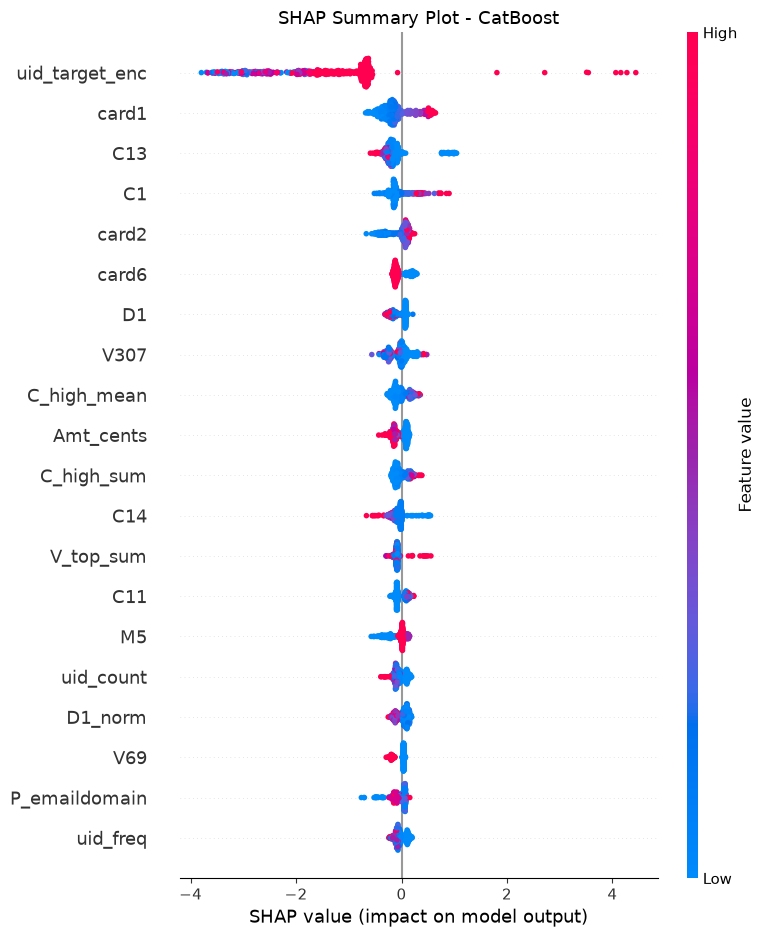

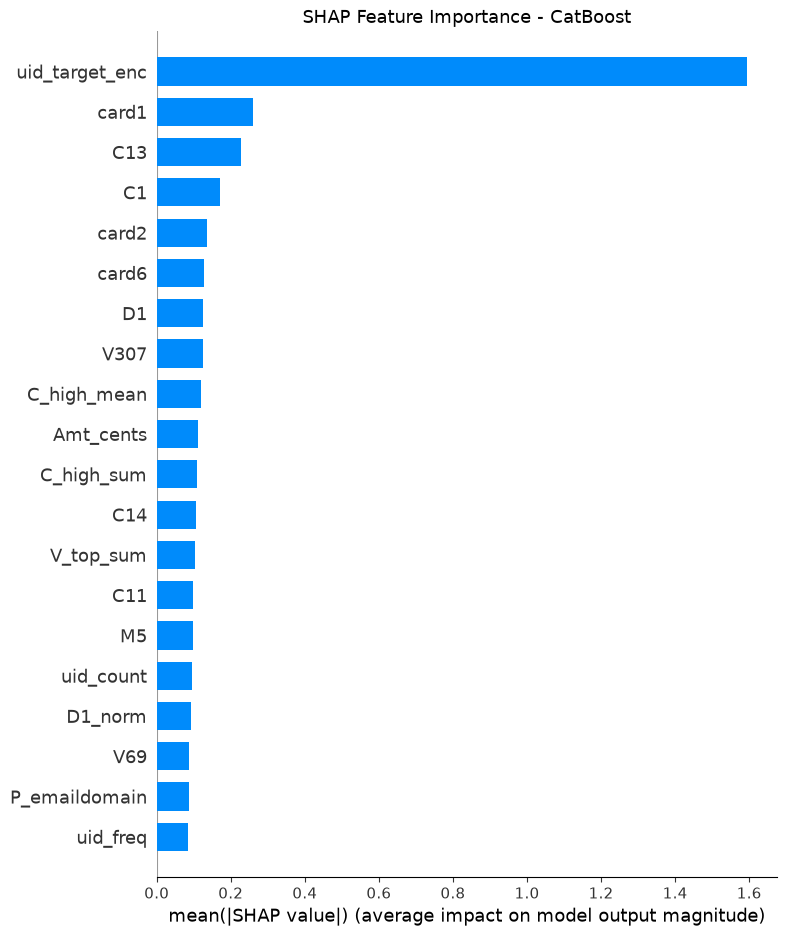


Creating SHAP waterfall for an example fraud transaction...


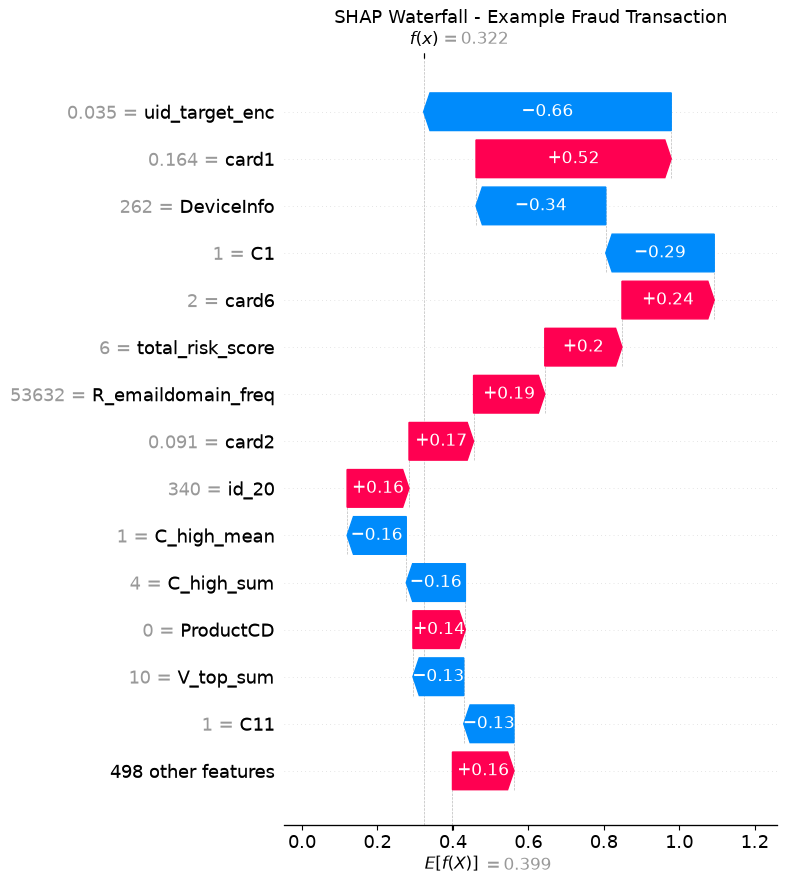


Top 15 features by mean absolute SHAP value:
       Feature  SHAP_mean
uid_target_enc     1.5953
         card1     0.2597
           C13     0.2270
            C1     0.1704
         card2     0.1353
         card6     0.1276
            D1     0.1253
          V307     0.1238
   C_high_mean     0.1206
     Amt_cents     0.1102
    C_high_sum     0.1093
           C14     0.1051
     V_top_sum     0.1043
           C11     0.0975
            M5     0.0973

CELL 14 COMPLETED SUCCESSFULLY


In [95]:
# ============================================
# CELL 14: SHAP EXPLAINABILITY
# ============================================

print("="*60)
print("STEP 14: SHAP Explainability - CatBoost")
print("="*60)

# ------------------------------------------------
# 1. Verify SHAP / model compatibility
# ------------------------------------------------

model_features = model_cb.feature_names_

assert list(X_test_shap.columns) == list(model_features), (
    "X_test_shap features do not match model_cb."
)

print("✓ SHAP data compatible with CatBoost model")
print(f"✓ Features: {X_test_shap.shape[1]}")

# ------------------------------------------------
# 2. Create SHAP explainer
# ------------------------------------------------

explainer = shap.TreeExplainer(model_cb)

print("✓ SHAP explainer created")

# ------------------------------------------------
# 3. Sample test data
# ------------------------------------------------

X_sample = X_test_shap.sample(
    n=500,
    random_state=42
)

print("✓ SHAP sample created:", X_sample.shape)

# ------------------------------------------------
# 4. Calculate SHAP values
# ------------------------------------------------

print("\nCalculating SHAP values...")

shap_values = explainer.shap_values(X_sample)

print("✓ SHAP values calculated successfully")
print("X_sample shape:", X_sample.shape)
print("SHAP shape:", np.asarray(shap_values).shape)

# ------------------------------------------------
# 5. SHAP Summary Plot
# ------------------------------------------------

plt.figure(figsize=(12, 8))

shap.summary_plot(
    shap_values,
    X_sample,
    max_display=20,
    show=False
)

plt.title("SHAP Summary Plot - CatBoost")
plt.tight_layout()
plt.show()

# ------------------------------------------------
# 6. SHAP Feature Importance - Bar Plot
# ------------------------------------------------

plt.figure(figsize=(12, 8))

shap.summary_plot(
    shap_values,
    X_sample,
    max_display=20,
    plot_type="bar",
    show=False
)

plt.title("SHAP Feature Importance - CatBoost")
plt.tight_layout()
plt.show()

# ------------------------------------------------
# 7. SHAP Waterfall - Example Fraud Transaction
# ------------------------------------------------

print("\nCreating SHAP waterfall for an example fraud transaction...")

fraud_mask = (y_test == 1)

fraud_indices = X_test_shap.index[fraud_mask]

fraud_idx = fraud_indices.to_series().sample(
    n=1,
    random_state=42
).index

X_fraud = X_test_shap.loc[[fraud_idx[0]]]

shap_fraud = explainer.shap_values(X_fraud)

fraud_row = X_fraud.iloc[0]

# Make expected value scalar if necessary
base_value = explainer.expected_value

if np.asarray(base_value).ndim > 0:
    base_value = np.asarray(base_value).reshape(-1)[0]

plt.figure(figsize=(14, 8))

shap.waterfall_plot(
    shap.Explanation(
        values=np.asarray(shap_fraud)[0],
        base_values=base_value,
        data=fraud_row.values,
        feature_names=X_fraud.columns.tolist()
    ),
    max_display=15,
    show=False
)

plt.title("SHAP Waterfall - Example Fraud Transaction")
plt.tight_layout()
plt.show()

# ------------------------------------------------
# 8. Global SHAP importance table
# ------------------------------------------------

shap_imp = pd.DataFrame({
    "Feature": X_sample.columns,
    "SHAP_mean": np.abs(
        np.asarray(shap_values)
    ).mean(axis=0)
}).sort_values(
    "SHAP_mean",
    ascending=False
)

print("\nTop 15 features by mean absolute SHAP value:")

print(
    shap_imp.head(15).to_string(index=False)
)

print("\n" + "="*60)
print("CELL 14 COMPLETED SUCCESSFULLY")
print("="*60)

### DIAGNOSTIC - CatBoost / SHAP Feature Alignment

In [96]:
# ============================================
# DIAGNOSTIC - CatBoost / SHAP Feature Alignment
# ============================================

print("="*60)
print("CATBOOST - SHAP FEATURE ALIGNMENT")
print("="*60)

model_features = model_cb.feature_names_
test_features = X_test.columns.tolist()

print(f"Model features : {len(model_features)}")
print(f"X_test features: {len(test_features)}")

missing_in_test = [
    f for f in model_features
    if f not in X_test.columns
]

extra_in_test = [
    f for f in X_test.columns
    if f not in model_features
]

print("\nFeatures in model but missing from X_test:")
print(missing_in_test)

print("\nFeatures in X_test but not in model:")
print(extra_in_test[:30])

print("\nNumber missing:", len(missing_in_test))
print("Number extra:", len(extra_in_test))

# Order check
same_order = (
    len(model_features) == len(test_features)
    and model_features == test_features
)

print("\nSame feature order:", same_order)

if len(missing_in_test) == 0:
    print("\n✓ All model features exist in X_test.")
else:
    print("\n✗ X_test is NOT compatible with model_cb.")

CATBOOST - SHAP FEATURE ALIGNMENT
Model features : 512
X_test features: 511

Features in model but missing from X_test:
['uid_target_enc']

Features in X_test but not in model:
[]

Number missing: 1
Number extra: 0

Same feature order: False

✗ X_test is NOT compatible with model_cb.


### DIAGNOSTIC 2 - Check UID Target Encoding

In [97]:
# ============================================
# DIAGNOSTIC 2 - Check UID Target Encoding
# ============================================

print("="*60)
print("CHECK UID TARGET ENCODING")
print("="*60)

print("\n1. Variables containing 'uid':")

uid_vars = [
    name for name in globals()
    if 'uid' in name.lower()
]

for name in uid_vars:
    try:
        obj = globals()[name]
        if hasattr(obj, "shape"):
            print(f"{name:30s} -> shape={obj.shape}")
        else:
            print(f"{name:30s} -> type={type(obj).__name__}")
    except Exception:
        pass


print("\n2. X_test columns containing 'uid':")

uid_test_cols = [
    c for c in X_test.columns
    if 'uid' in c.lower()
]

print(uid_test_cols)


print("\n3. Model UID-related features:")

model_uid_features = [
    f for f in model_cb.feature_names_
    if 'uid' in f.lower()
]

print(model_uid_features)


print("\n4. Check possible uid_target_enc variables:")

possible_vars = [
    'uid_target_enc',
    'uid_te_test',
    'uid_te_train',
    'uid_te_val',
    'uid_test_te',
    'X_test_uid_te',
    'uid_test_target_enc'
]

for name in possible_vars:
    if name in globals():
        obj = globals()[name]
        print(
            f"{name}: EXISTS | "
            f"type={type(obj).__name__} | "
            f"shape={getattr(obj, 'shape', 'N/A')}"
        )
    else:
        print(f"{name}: not found")

CHECK UID TARGET ENCODING

1. Variables containing 'uid':
uid_base_cols                  -> type=list
uid_parts                      -> type=list
n_uid                          -> type=int
avg_transactions_per_uid       -> type=float
uid_fraud_stats                -> shape=(222477, 2)
uid_pure                       -> shape=()
uid_size_stats                 -> shape=(222477,)
uid_group                      -> type=SeriesGroupBy
uid_previous_count             -> shape=(590540,)
uid_cumulative_sum             -> shape=(590540,)
uid_cumulative_sum_sq          -> shape=(590540,)
uid_variance                   -> shape=(590540,)
uid_raw_train                  -> shape=(413378,)
uid_raw_val                    -> shape=(59054,)
uid_raw_test                   -> shape=(118108,)
uid_available                  -> type=bool
uid_tr                         -> shape=(344482,)
uid_vl                         -> shape=(68896,)
uid_encoder                    -> type=tuple
uid_te_train                   

### DIAGNOSTIC 3 - oInspect Full UID Encder

In [98]:
# ============================================
# DIAGNOSTIC 3 - oInspect Full UID Encder
# ============================================

print("="*60)
print("INSPECT full_uid_encoder")
print("="*60)

print("Type:", type(full_uid_encoder).__name__)
print("Length:", len(full_uid_encoder))

for i, item in enumerate(full_uid_encoder):
    print(f"\nElement {i}")
    print("Type:", type(item).__name__)

    if hasattr(item, "shape"):
        print("Shape:", item.shape)

    if hasattr(item, "head"):
        print(item.head())

    elif isinstance(item, dict):
        print("Dict size:", len(item))
        print("First items:", list(item.items())[:5])

    elif isinstance(item, tuple):
        print("Tuple length:", len(item))

INSPECT full_uid_encoder
Type: tuple
Length: 3

Element 0
Type: Series
Shape: (168122,)
_key
40035    0.0000
96736    0.0000
114256   0.0000
83352    0.0000
112979   0.0000
Name: sum, dtype: float64

Element 1
Type: Series
Shape: (168122,)
_key
40035      1
96736      1
114256     2
83352     84
112979     1
Name: count, dtype: int64

Element 2
Type: float


### DIAGNOSTIC 4 - Verify UID Encoder Mapping

In [99]:
# ============================================
# DIAGNOSTIC 4 - Verify UID Encoder Mapping
# ============================================

print("="*60)
print("VERIFY FULL UID ENCODER MAPPING")
print("="*60)

# ------------------------------------------------
# 1. Basic information
# ------------------------------------------------

print("uid_raw_test shape:", uid_raw_test.shape)
print("uid_raw_train shape:", uid_raw_train.shape)

print("full encoder sum shape:", full_uid_encoder[0].shape)
print("full encoder count shape:", full_uid_encoder[1].shape)

print("\nGlobal mean:", full_uid_encoder[2])

# ------------------------------------------------
# 2. Inspect raw UID values
# ------------------------------------------------

print("\nFirst 10 uid_raw_test values:")
print(uid_raw_test[:10])

print("\nType of uid_raw_test:")
print(type(uid_raw_test))

# ------------------------------------------------
# 3. Inspect encoder index
# ------------------------------------------------

encoder_sum = full_uid_encoder[0]
encoder_count = full_uid_encoder[1]
global_mean = full_uid_encoder[2]

print("\nEncoder index name:", encoder_sum.index.name)

print("First 10 encoder keys:")
print(encoder_sum.index[:10].tolist())

# ------------------------------------------------
# 4. Check overlap
# ------------------------------------------------

test_uid_values = pd.Series(uid_raw_test).astype(str)

encoder_keys = encoder_sum.index.astype(str)

overlap = np.intersect1d(
    test_uid_values.unique(),
    encoder_keys.unique()
)

print("\nUnique test UIDs:", test_uid_values.nunique())
print("Unique encoder keys:", encoder_keys.nunique())
print("Overlap:", len(overlap))

if test_uid_values.nunique() > 0:
    overlap_rate = len(overlap) / test_uid_values.nunique()
else:
    overlap_rate = 0

print("Test UID overlap rate:", overlap_rate)

# ------------------------------------------------
# 5. Show some matching values
# ------------------------------------------------

print("\nFirst matching test UID values:")

matching_examples = overlap[:10]

for key in matching_examples:

    sum_value = encoder_sum.loc[
        encoder_sum.index.astype(str) == key
    ].iloc[0]

    count_value = encoder_count.loc[
        encoder_count.index.astype(str) == key
    ].iloc[0]

    te_value = sum_value / count_value if count_value > 0 else global_mean

    print(
        f"UID={key} | "
        f"sum={sum_value:.4f} | "
        f"count={count_value} | "
        f"TE={te_value:.6f}"
    )

VERIFY FULL UID ENCODER MAPPING
uid_raw_test shape: (118108,)
uid_raw_train shape: (413378,)
full encoder sum shape: (168122,)
full encoder count shape: (168122,)

Global mean: 0.03516878014795175

First 10 uid_raw_test values:
472432        -1
472433        -1
472434        -1
472435        -1
472436        -1
472437    158261
472438    127704
472439     74320
472440     29624
472441        -1
Name: uid, dtype: int64

Type of uid_raw_test:
<class 'pandas.core.series.Series'>

Encoder index name: _key
First 10 encoder keys:
[40035, 96736, 114256, 83352, 112979, 122702, 23059, 29423, 98681, 77275]

Unique test UIDs: 18159
Unique encoder keys: 168122
Overlap: 18158
Test UID overlap rate: 0.9999449308882647

First matching test UID values:
UID=100003 | sum=0.0000 | count=2 | TE=0.000000
UID=100006 | sum=0.0000 | count=3 | TE=0.000000
UID=100010 | sum=0.0000 | count=2 | TE=0.000000
UID=100014 | sum=0.0000 | count=4 | TE=0.000000
UID=100016 | sum=0.0000 | count=1 | TE=0.000000
UID=100019 | 

### SHAP PREPARATION - Add UID Target Encoding

In [100]:
# ============================================
# SHAP PREPARATION - Full Target Encoding
# ============================================
# model_cb (full CatBoost from CELL 13B) was trained with TE_COLS
# target-encoded and an extra uid_target_enc column. The SHAP input
# must be built with the SAME full-train encoders (full_encoders),
# otherwise the model sees raw label codes where it expects
# encoded fraud rates.

print("="*60)
print("PREPARE X_TEST FOR SHAP")
print("="*60)

X_test_shap = X_test.copy()

for col in TE_COLS:
    X_test_shap[col] = transform_te(
        X_test[col],
        full_encoders[col]
    )

X_test_shap["uid_target_enc"] = transform_te(
    uid_raw_test,
    full_encoders["uid"]
)

# Reorder exactly like CatBoost model
X_test_shap = X_test_shap[
    model_cb.feature_names_
]

# Integrity check: same predictions as CELL 13B full CatBoost
shap_pred_check = model_cb.predict_proba(X_test_shap)[:, 1]
max_pred_diff = float(
    np.abs(shap_pred_check - y_pred_proba_cb_full).max()
)

print("Original X_test shape :", X_test.shape)
print("SHAP X_test shape     :", X_test_shap.shape)
print("TE columns encoded    :", TE_COLS + ["uid_target_enc"])
print("NaN in X_test_shap    :", int(X_test_shap.isna().sum().sum()))
print("Features match model  :",
      list(X_test_shap.columns) == list(model_cb.feature_names_))
print(f"Max |pred - 13B pred| : {max_pred_diff:.2e}")

assert list(X_test_shap.columns) == list(model_cb.feature_names_)
assert max_pred_diff < 1e-4, (
    "X_test_shap is not encoded like the model's training data"
)

print("="*60)
print("X_TEST_SHAP READY")
print("="*60)


PREPARE X_TEST FOR SHAP
Original X_test shape : (118108, 511)
SHAP X_test shape     : (118108, 512)
TE columns encoded    : ['card1', 'card2', 'addr1', 'P_emaildomain', 'uid_target_enc']
NaN in X_test_shap    : 0
Features match model  : True
Max |pred - 13B pred| : 2.98e-08
X_TEST_SHAP READY


## CELL 14B: ADVANCED SHAP ANALYSIS

SHAP - Analyse Approfondie 100%
✓ X_test_shap is compatible with CatBoost model
✓ Features: 512

1. Waterfall - Transaction Normale...


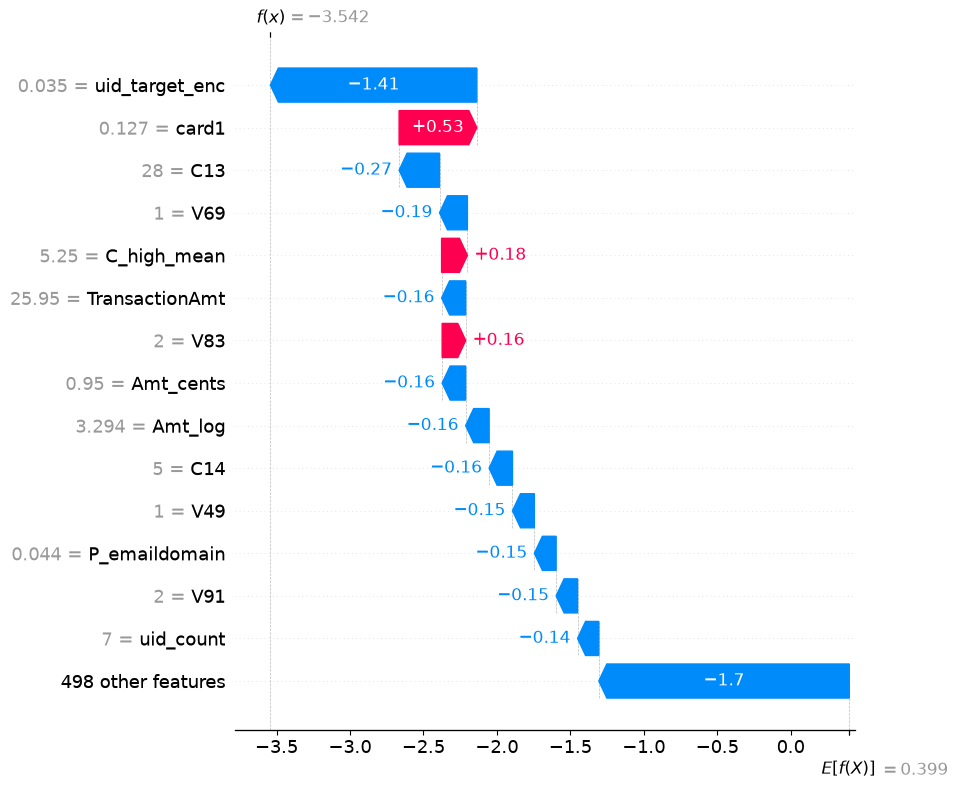

✓ Normal waterfall completed

2. SHAP Dependence Plots...
Available features: ['card1', 'C13', 'week', 'C1']
  → card1


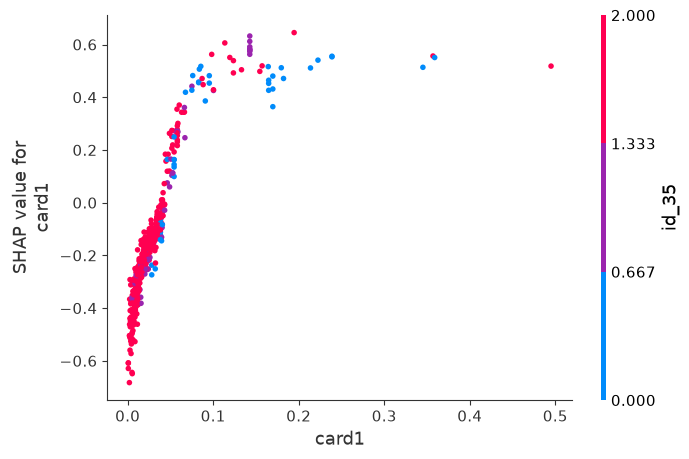

  → C13


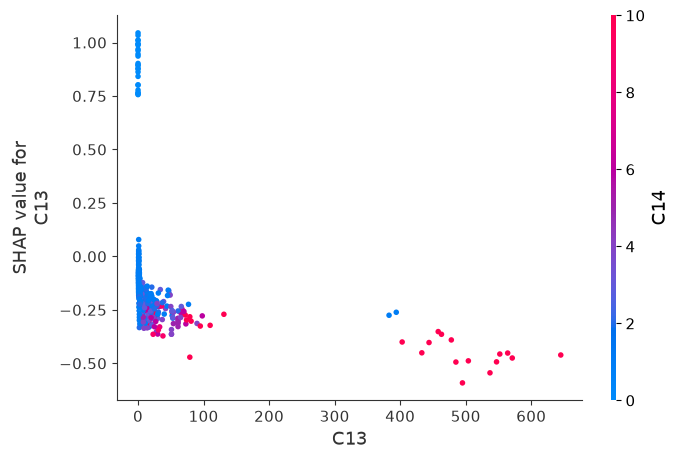

  → week


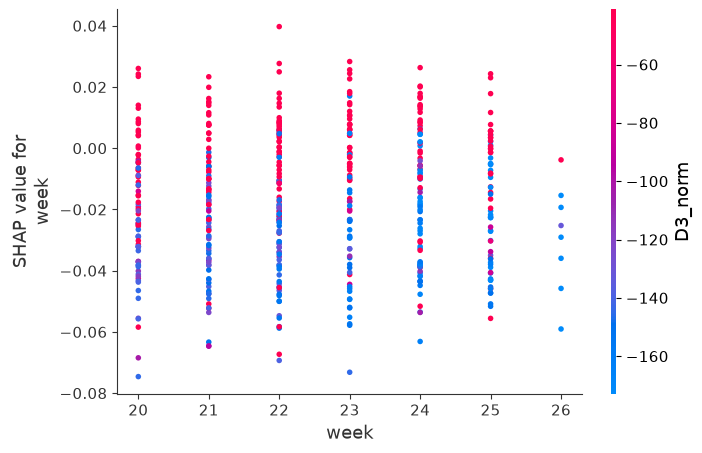

  → C1


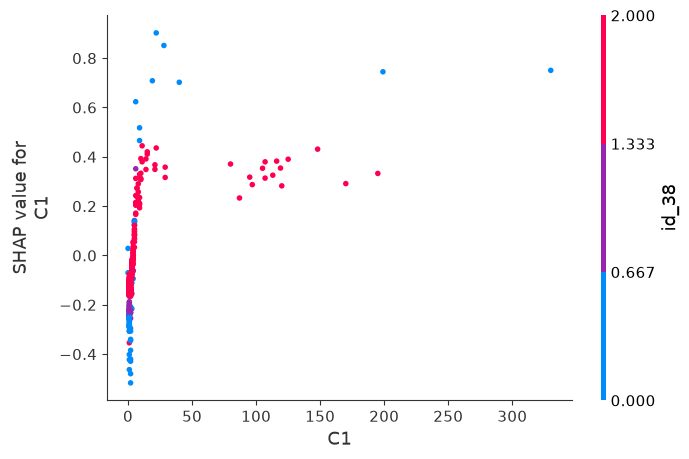


3. SHAP Decision Plot...
Decision SHAP shape: (6, 512)


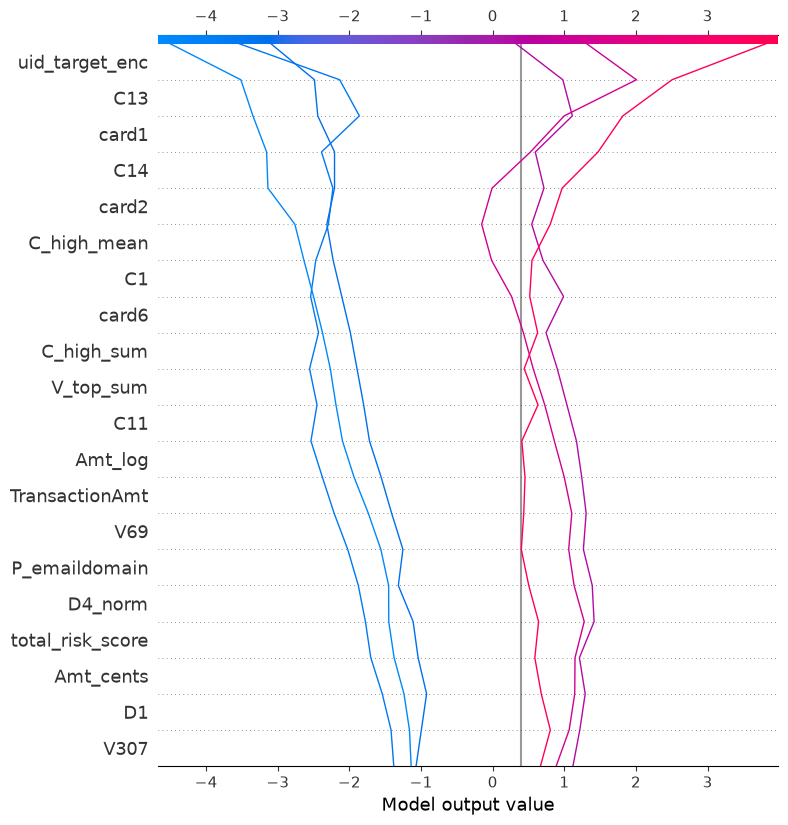

✓ Decision plot completed

4. SHAP Interaction Analysis...
Calculating SHAP interaction values...
Using 100 samples to reduce computation time...
Interaction SHAP shape: (100, 512, 512)
Interaction values shape: (100,)

Creating card1 × C13 interaction plot...


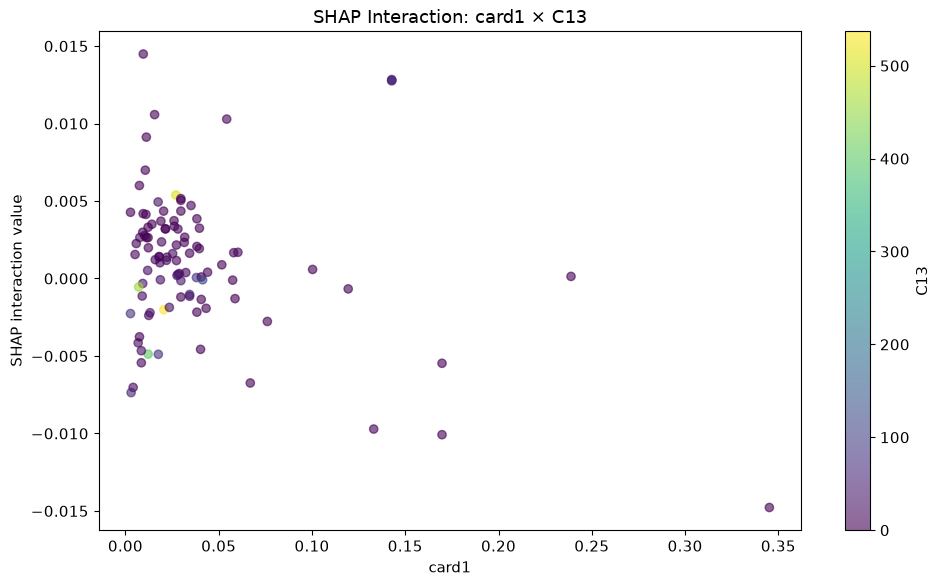

✓ Interaction visualization completed

CELL 14B COMPLETED SUCCESSFULLY


In [101]:
# ============================================
# CELL 14B: ADVANCED SHAP ANALYSIS
# ============================================

print("="*60)
print("SHAP - Analyse Approfondie 100%")
print("="*60)

# ------------------------------------------------
# 0. Verify SHAP dataset
# ------------------------------------------------

assert list(X_test_shap.columns) == list(model_cb.feature_names_)

print("✓ X_test_shap is compatible with CatBoost model")
print(f"✓ Features: {X_test_shap.shape[1]}")


# ------------------------------------------------
# 1. Waterfall - Normal Transaction
# ------------------------------------------------

print("\n1. Waterfall - Transaction Normale...")

normal_indices = X_test_shap.index[y_test == 0]

normal_idx = normal_indices.to_series().sample(
    n=1,
    random_state=42
).index[0]

X_normal = X_test_shap.loc[[normal_idx]]

shap_normal = explainer.shap_values(X_normal)

base_value = explainer.expected_value

if np.asarray(base_value).ndim > 0:
    base_value = np.asarray(base_value).reshape(-1)[0]

shap.waterfall_plot(
    shap.Explanation(
        values=np.asarray(shap_normal)[0],
        base_values=base_value,
        data=X_normal.iloc[0].values,
        feature_names=X_normal.columns.tolist()
    ),
    max_display=15,
    show=True
)

print("✓ Normal waterfall completed")


# ------------------------------------------------
# 2. SHAP Dependence Plots
# ------------------------------------------------

print("\n2. SHAP Dependence Plots...")

dependence_features = [
    "card1",
    "C13",
    "week",
    "C1"
]

available_dependence_features = [
    f for f in dependence_features
    if f in X_sample.columns
]

missing_dependence_features = [
    f for f in dependence_features
    if f not in X_sample.columns
]

print(
    "Available features:",
    available_dependence_features
)

if missing_dependence_features:
    print(
        "Skipped missing features:",
        missing_dependence_features
    )

for feature in available_dependence_features:

    print(f"  → {feature}")

    shap.dependence_plot(
        feature,
        shap_values,
        X_sample,
        interaction_index="auto",
        show=True
    )


# ------------------------------------------------
# 3. SHAP Decision Plot
# ------------------------------------------------

print("\n3. SHAP Decision Plot...")

# Select 3 fraud transactions
fraud_indices = X_test_shap.index[y_test == 1]

fraud_idx = fraud_indices.to_series().sample(
    n=3,
    random_state=42
).index

# Select 3 normal transactions
normal_idx_decision = normal_indices.to_series().sample(
    n=3,
    random_state=42
).index

decision_indices = list(fraud_idx) + list(
    normal_idx_decision
)

X_decision = X_test_shap.loc[
    decision_indices
]

shap_decision = explainer.shap_values(
    X_decision
)

print(
    "Decision SHAP shape:",
    np.asarray(shap_decision).shape
)

# SHAP version compatibility:
# do NOT use max_display here
shap.decision_plot(
    base_value,
    shap_decision,
    X_decision,
    feature_names=X_decision.columns.tolist(),
    show=True
)

print("✓ Decision plot completed")


# ------------------------------------------------
# 4. SHAP Interaction Analysis
# ------------------------------------------------

print("\n4. SHAP Interaction Analysis...")

if (
    "card1" in X_sample.columns
    and
    "C13" in X_sample.columns
):

    print("Calculating SHAP interaction values...")
    print("Using 100 samples to reduce computation time...")

    # Smaller sample because interaction SHAP
    # is computationally expensive
    X_interaction = X_sample.sample(
        n=min(100, len(X_sample)),
        random_state=42
    )

    # Calculate SHAP interaction values
    shap_interaction = (
        explainer.shap_interaction_values(
            X_interaction
        )
    )

    shap_interaction = np.asarray(
        shap_interaction
    )

    print(
        "Interaction SHAP shape:",
        shap_interaction.shape
    )

    # ------------------------------------------------
    # Get feature indices
    # ------------------------------------------------

    card1_idx = X_interaction.columns.get_loc(
        "card1"
    )

    c13_idx = X_interaction.columns.get_loc(
        "C13"
    )

    # ------------------------------------------------
    # Extract card1 × C13 interaction values
    # ------------------------------------------------

    interaction_values = (
        shap_interaction[
            :,
            card1_idx,
            c13_idx
        ]
    )

    print(
        "Interaction values shape:",
        interaction_values.shape
    )

    # ------------------------------------------------
    # Interaction Visualization
    # ------------------------------------------------

    print("\nCreating card1 × C13 interaction plot...")

    plt.figure(figsize=(10, 6))

    scatter = plt.scatter(
        X_interaction["card1"],
        interaction_values,
        c=X_interaction["C13"],
        alpha=0.6
    )

    plt.xlabel("card1")
    plt.ylabel("SHAP interaction value")
    plt.title(
        "SHAP Interaction: card1 × C13"
    )

    # Colorbar represents C13 values
    cbar = plt.colorbar(scatter)
    cbar.set_label("C13")

    plt.tight_layout()
    plt.show()

    print(
        "✓ Interaction visualization completed"
    )

else:

    print(
        "⚠ card1 or C13 not available."
        " Interaction analysis skipped."
    )

# ------------------------------------------------
# 5. Final
# ------------------------------------------------

print("\n" + "="*60)
print("CELL 14B COMPLETED SUCCESSFULLY")
print("="*60)

## CELL 15: FINAL COMPARISON

FINAL RESULTS100%
🏆Complete Comparison:
                               AUC  Recall  Precision     F1  OOF_AUC  \
Stacking_V2                 0.9126     NaN        NaN    NaN      NaN   
Imbalance_Undersampling     0.9097  0.4653     0.5325 0.4967      NaN   
Stacking_Full_Diagnostic    0.9092     NaN        NaN    NaN      NaN   
LightGBM                    0.9057  0.4496     0.6229 0.5222      NaN   
LightGBM_ProfitOptimized    0.9057  0.5775     0.3948 0.4690      NaN   
CatBoost                    0.9045  0.4409     0.5470 0.4883      NaN   
Imbalance_SMOTE             0.9039  0.4798     0.5090 0.4940      NaN   
XGBoost                     0.8982  0.4427     0.5869 0.5047      NaN   
Imbalance_ClassWeight       0.8962  0.4326     0.6023 0.5035      NaN   
CatBoost_ProfitOptimized    0.8885  0.4963     0.5110 0.5036      NaN   
NeuralNetwork               0.8549  0.4104     0.4037 0.4070      NaN   
Baseline_LogisticRegression 0.8274  0.4500     0.2391 0.3123      NaN   
AutoEncoder

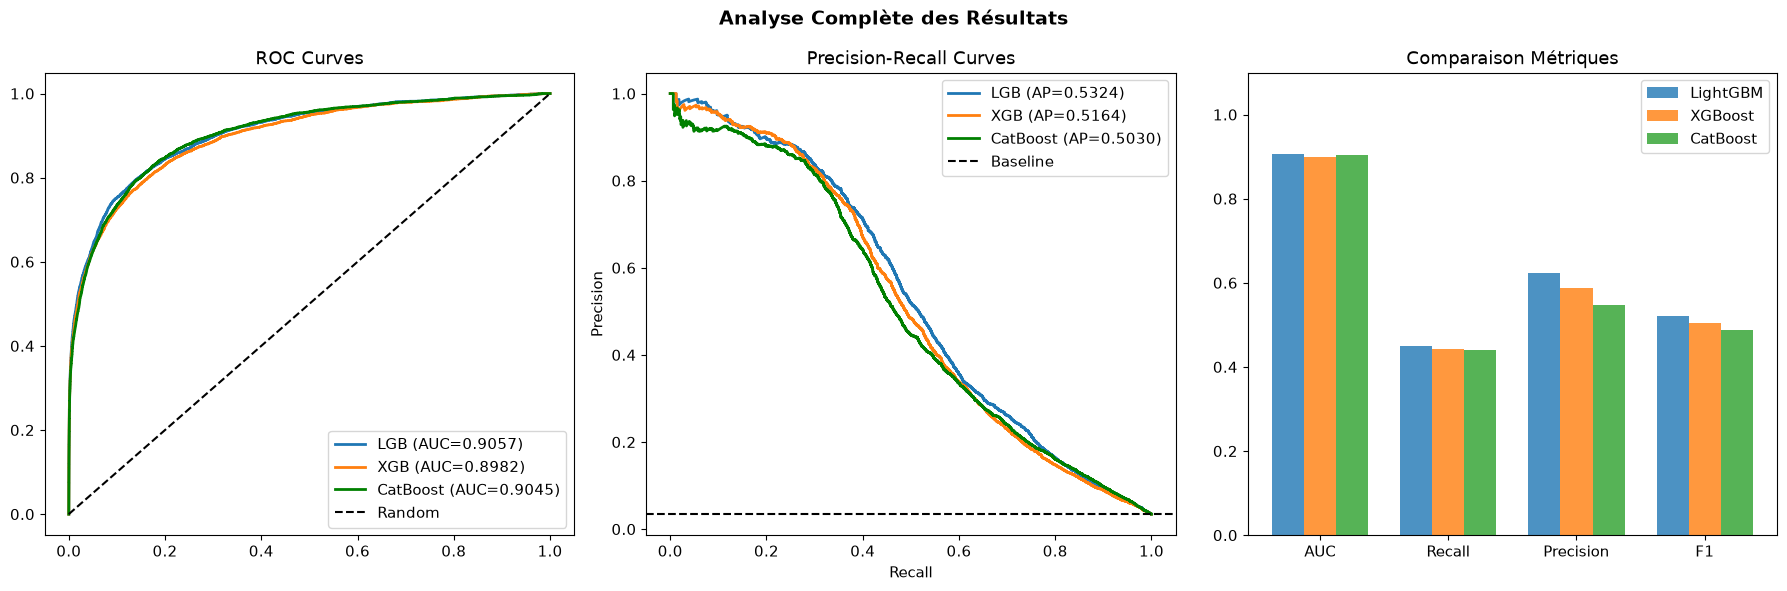


⚠️  PRELIMINARY COST-BENEFIT ANALYSIS (F1, non-economic thresholds)
    For the FINAL ECONOMIC analysis of the production model
    (CatBoost, threshold profit-optimized), see CELL 15D.

--- LightGBM (threshold F1, NON optimisé économiquement) ---
  TP: 1,827 | FN: 2,237 | FP: 1,106
  Bénéfice net (préliminaire): $902,440

--- XGBoost (threshold F1, NON optimisé économiquement) ---
  TP: 1,799 | FN: 2,265 | FP: 1,266
  Bénéfice net (préliminaire): $886,840

--- CatBoost (threshold F1, NON optimisé économiquement) ---
  TP: 1,792 | FN: 2,272 | FP: 1,484
  Bénéfice net (préliminaire): $881,160

📌 REMINDER: these net benefits are PRELIMINARY and MUST NOT
   be cited in the report as the final result. The final
   economic result of the production model (CatBoost with
   profit-optimized threshold + capacity constraint) is
   calculated separately in CELL 15D.

🥇 Best AUC: Stacking_V2 (0.9126)
🥇 Best F1:  LightGBM (0.5222)

✅ FINAL RESULTS 100% finished ! 


In [102]:
# ============================================
# CELL 15: FINAL COMPARISON
# ============================================
print("="*60)
print("FINAL RESULTS100%")
print("="*60)

# ===== 1. Complete comparison table =====
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(
    'AUC', ascending=False
)
print("🏆Complete Comparison:")
print(results_df.round(4))

# ===== 2. Precision-Recall Curves =====
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# ROC Curves
fpr_lgb, tpr_lgb, _ = roc_curve(y_test, y_pred_proba_lgb)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_pred_proba_xgb)
fpr_cb, tpr_cb, _ = roc_curve(y_test, y_pred_proba_cb)

axes[0].plot(fpr_lgb, tpr_lgb, linewidth=2,
    label=f'LGB (AUC={results["LightGBM"]["AUC"]:.4f})'
)
axes[0].plot(fpr_xgb, tpr_xgb, linewidth=2,
    label=f'XGB (AUC={results["XGBoost"]["AUC"]:.4f})'
)
axes[0].plot(fpr_cb, tpr_cb, linewidth=2, color='green',
    label=f'CatBoost (AUC={results["CatBoost"]["AUC"]:.4f})'
)
axes[0].plot([0,1],[0,1],'k--',label='Random')
axes[0].set_title('ROC Curves')
axes[0].legend()

# Precision-Recall Curves
prec_lgb, rec_lgb, _ = precision_recall_curve(y_test, y_pred_proba_lgb)
prec_xgb, rec_xgb, _ = precision_recall_curve(y_test, y_pred_proba_xgb)
prec_cb, rec_cb, _ = precision_recall_curve(y_test, y_pred_proba_cb)

ap_lgb = average_precision_score(y_test, y_pred_proba_lgb)
ap_xgb = average_precision_score(y_test, y_pred_proba_xgb)
ap_cb = average_precision_score(y_test, y_pred_proba_cb)

axes[1].plot(rec_lgb, prec_lgb, linewidth=2,
    label=f'LGB (AP={ap_lgb:.4f})'
)
axes[1].plot(rec_xgb, prec_xgb, linewidth=2,
    label=f'XGB (AP={ap_xgb:.4f})'
)
axes[1].plot(rec_cb, prec_cb, linewidth=2, color='green',
    label=f'CatBoost (AP={ap_cb:.4f})'
)
axes[1].axhline(
    y=y_test.mean(), color='k',
    linestyle='--', label='Baseline'
)
axes[1].set_title('Precision-Recall Curves')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend()

# Metrics Comparison (LightGBM, XGBoost, CatBoost explicitement)
core_models = ['LightGBM', 'XGBoost', 'CatBoost']
metrics = ['AUC','Recall','Precision','F1']
x = np.arange(len(metrics))
w = 0.25

for i, model in enumerate(core_models):
    vals = [results[model][m] for m in metrics]
    axes[2].bar(
        x + i*w, vals, w,
        label=model, alpha=0.8
    )

axes[2].set_xticks(x + w)
axes[2].set_xticklabels(metrics)
axes[2].set_title('Comparaison Métriques')
axes[2].legend()
axes[2].set_ylim(0, 1.1)

plt.suptitle(
    'Analyse Complète des Résultats',
    fontsize=14, fontweight='bold'
)
plt.tight_layout()
plt.show()

# ===== 3.Cost-Benefit Analysis (PRELIMINARY — NON-optimized thresholds) =====
print("\n" + "="*60)
print("⚠️  PRELIMINARY COST-BENEFIT ANALYSIS (F1, non-economic thresholds)")
print("    For the FINAL ECONOMIC analysis of the production model")
print("    (CatBoost, threshold profit-optimized), see CELL 15D.")
print("="*60)

# Assumption:
# Failed fraud (FN) = -$500 loss
# False alarm (FA) = -$10 operating cost
cost_fn = 500
cost_fp = 10

preliminary_preds = {
    'LightGBM': y_pred_lgb,
    'XGBoost':  y_pred_xgb,
    'CatBoost': y_pred_cb,
}

cost_benefit_summary = {}

for model_name, y_pred in preliminary_preds.items():
    cm_tmp = confusion_matrix(y_test, y_pred)
    TP_tmp, FP_tmp, FN_tmp, TN_tmp = (
        cm_tmp[1,1], cm_tmp[0,1], cm_tmp[1,0], cm_tmp[0,0]
    )
    saved_tmp = TP_tmp * cost_fn
    # Net benefit vs. no model: caught frauds - review cost.
    # (FN are not subtracted again: that double-counted frauds.)
    cost_tmp = FP_tmp * cost_fp
    net_tmp = saved_tmp - cost_tmp

    cost_benefit_summary[model_name] = {
        'TP': TP_tmp, 'FN': FN_tmp, 'FP': FP_tmp,
        'Argent sauvé': saved_tmp,
        'Coût total': cost_tmp,
        'Bénéfice net': net_tmp,
    }

    print(f"\n--- {model_name} (threshold F1, NON optimisé économiquement) ---")
    print(f"  TP: {TP_tmp:,} | FN: {FN_tmp:,} | FP: {FP_tmp:,}")
    print(f"  Bénéfice net (préliminaire): ${net_tmp:,}")

print("\n" + "="*60)
print("📌 REMINDER: these net benefits are PRELIMINARY and MUST NOT")
print("   be cited in the report as the final result. The final")
print("   economic result of the production model (CatBoost with")
print("   profit-optimized threshold + capacity constraint) is")
print("   calculated separately in CELL 15D.")
print("="*60)

# ===== 4. Best Model =====
print("\n" + "="*50)
# Some entries (e.g. Stacking_CV) use other metric names
auc_models = [m for m in results if pd.notna(results[m].get('AUC', np.nan))]
f1_models  = [m for m in results if pd.notna(results[m].get('F1', np.nan))]
best_auc = max(auc_models, key=lambda x: results[x]['AUC'])
best_f1  = max(f1_models,  key=lambda x: results[x]['F1'])
print(f"🥇 Best AUC: {best_auc} "
      f"({results[best_auc]['AUC']:.4f})")
print(f"🥇 Best F1:  {best_f1} "
      f"({results[best_f1]['F1']:.4f})")

print("\n✅ FINAL RESULTS 100% finished ! ")

## CELL 15B: Threshold Optimized for Profit (not F1)

Optimization of Threshold according to Real Profit
🎯 Previous threshold (F1-optimized on val): 0.59
🎯 New threshold (Profit-optimized on val):  0.33

📊 TEST result with the frozen threshold:
  TP: 2,347 | FP: 3,598 | FN: 1,717
  Alert rate:    5.03%
  Money saved:   $1,173,500
  Review cost:   $35,980
  Net benefit:   $1,137,520
  Fraud missed:  1,717 ($858,500 not recovered)
              precision    recall  f1-score   support

      Normal       0.98      0.97      0.98    114044
       Fraud       0.39      0.58      0.47      4064

    accuracy                           0.95    118108
   macro avg       0.69      0.77      0.72    118108
weighted avg       0.96      0.95      0.96    118108



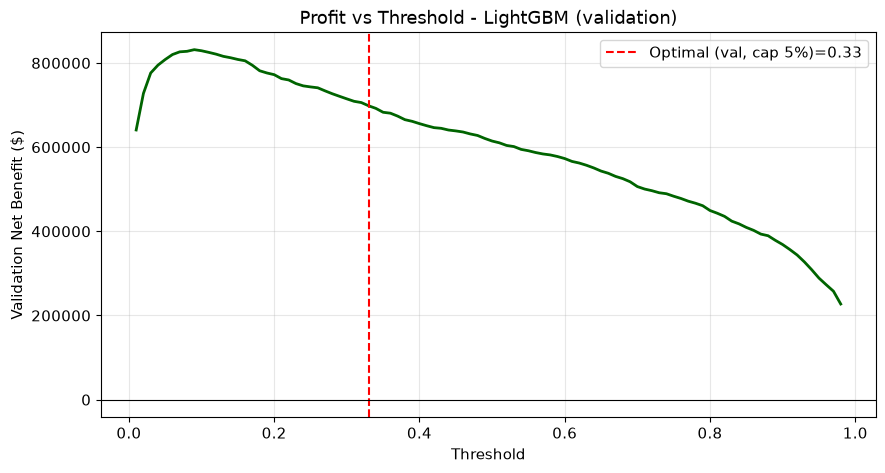

In [103]:
# ============================================
# CELL 15B: Threshold Optimized for Profit (not F1)
# Threshold chosen on VALIDATION, evaluated once on TEST
# ============================================
print("="*60)
print("Optimization of Threshold according to Real Profit")
print("="*60)

cost_fn = 500   # value of a caught fraud (= loss avoided)
cost_fp = 10    # cost of reviewing a false alarm
max_alert_rate = 0.05  # the team can only handle 5% of transactions as alerts.


def net_profit_at(proba, y_true, t):
    """Net benefit vs. no model: TP*cost_fn - FP*cost_fp."""
    pred = (proba > t).astype(int)
    y_arr = np.asarray(y_true)
    tp = int(((pred == 1) & (y_arr == 1)).sum())
    fp = int(((pred == 1) & (y_arr == 0)).sum())
    return tp * cost_fn - fp * cost_fp, pred.mean()


if 'y_val_proba_lgb' not in dir():
    y_val_proba_lgb = model_lgb_final.predict_proba(X_val)[:, 1]

thresholds_profit = np.arange(0.01, 0.99, 0.01)
profits = []          # validation profit (unconstrained)
alert_rates_val = []
for t in thresholds_profit:
    p, a = net_profit_at(y_val_proba_lgb, y_val, t)
    profits.append(p)
    alert_rates_val.append(a)

profits_constrained = [
    p if a <= max_alert_rate else -np.inf
    for p, a in zip(profits, alert_rates_val)
]

best_thresh_profit = thresholds_profit[np.argmax(profits_constrained)]
y_pred_profit = (y_pred_proba_lgb > best_thresh_profit).astype(int)
cm_p = confusion_matrix(y_test, y_pred_profit)
TP_p, FP_p, FN_p, TN_p = cm_p[1,1], cm_p[0,1], cm_p[1,0], cm_p[0,0]

saved_p = TP_p * cost_fn
cost_p  = FP_p * cost_fp
net_p   = saved_p - cost_p

print(f"🎯 Previous threshold (F1-optimized on val): {best_thresh_lgb:.2f}")
print(f"🎯 New threshold (Profit-optimized on val):  {best_thresh_profit:.2f}")
print(f"\n📊 TEST result with the frozen threshold:")
print(f"  TP: {TP_p:,} | FP: {FP_p:,} | FN: {FN_p:,}")
print(f"  Alert rate:    {y_pred_profit.mean()*100:.2f}%")
print(f"  Money saved:   ${saved_p:,}")
print(f"  Review cost:   ${cost_p:,}")
print(f"  Net benefit:   ${net_p:,}")
print(f"  Fraud missed:  {FN_p:,} (${FN_p*cost_fn:,} not recovered)")

print(classification_report(
    y_test, y_pred_profit,
    target_names=['Normal','Fraud']
))

# Profit (validation) versus threshold
plt.figure(figsize=(10,5))
plt.plot(thresholds_profit, profits, color='darkgreen', linewidth=2)
plt.axvline(best_thresh_profit, color='red', linestyle='--',
    label=f'Optimal (val, cap {max_alert_rate:.0%})={best_thresh_profit:.2f}')
plt.axhline(0, color='black', linewidth=0.8)
plt.xlabel('Threshold')
plt.ylabel('Validation Net Benefit ($)')
plt.title('Profit vs Threshold - LightGBM (validation)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

results['LightGBM_ProfitOptimized'] = {
    'AUC': auc_lgb,
    'Recall': recall_score(y_test, y_pred_profit),
    'Precision': precision_score(y_test, y_pred_profit),
    'F1': f1_score(y_test, y_pred_profit)
}


## CELL 15C: Sensitivity Analysis - Profit vs. Review Capacity

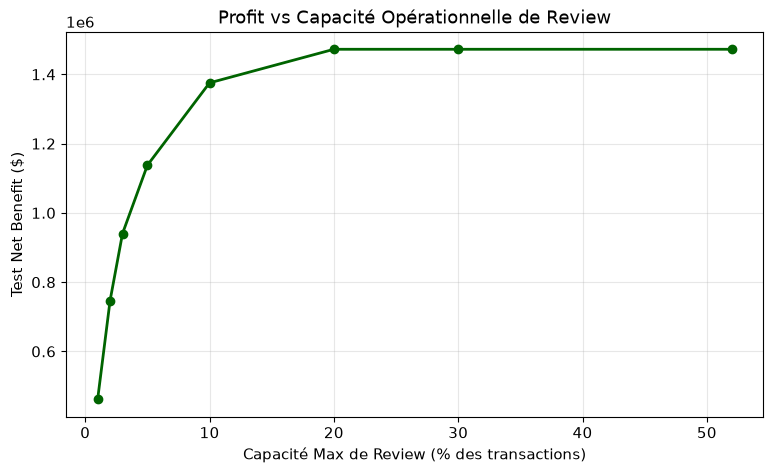

Capacité 1%: threshold(val)=0.96 | Test profit = $461,820
Capacité 2%: threshold(val)=0.75 | Test profit = $746,880
Capacité 3%: threshold(val)=0.54 | Test profit = $940,360
Capacité 5%: threshold(val)=0.33 | Test profit = $1,137,520
Capacité 10%: threshold(val)=0.17 | Test profit = $1,375,450
Capacité 20%: threshold(val)=0.09 | Test profit = $1,472,410
Capacité 30%: threshold(val)=0.09 | Test profit = $1,472,410
Capacité 52%: threshold(val)=0.09 | Test profit = $1,472,410


In [104]:
# ===== Sensitivity Analysis: Profit vs Capacité de Review =====
# For each capacity: threshold chosen on VALIDATION, profit reported on TEST
alert_caps = [0.01, 0.02, 0.03, 0.05, 0.10, 0.20, 0.30, 0.52]
best_profits_by_cap = []
best_thresh_by_cap = []

for cap in alert_caps:
    profits_c = [
        p if a <= cap else -np.inf
        for p, a in zip(profits, alert_rates_val)
    ]
    t_cap = thresholds_profit[int(np.argmax(profits_c))]
    test_profit, _ = net_profit_at(y_pred_proba_lgb, y_test, t_cap)
    best_thresh_by_cap.append(t_cap)
    best_profits_by_cap.append(test_profit)

plt.figure(figsize=(9,5))
plt.plot([c*100 for c in alert_caps], best_profits_by_cap,
         marker='o', color='darkgreen', linewidth=2)
plt.xlabel('Capacité Max de Review (% des transactions)')
plt.ylabel('Test Net Benefit ($)')
plt.title('Profit vs Capacité Opérationnelle de Review')
plt.grid(alpha=0.3)
plt.show()

for cap, t_cap, p in zip(alert_caps, best_thresh_by_cap, best_profits_by_cap):
    print(f"Capacité {cap*100:.0f}%: threshold(val)={t_cap:.2f} | "
          f"Test profit = ${p:,.0f}")


In [105]:
print("="*60)
print("RUN CONSISTENCY CHECK")
print("="*60)

print(f"Test samples: {len(y_test):,}")
print(f"Fraud cases: {np.sum(np.asarray(y_test) == 1):,}")
print(f"Normal cases: {np.sum(np.asarray(y_test) == 0):,}")

print("\nPrediction lengths:")
print(f"CatBoost:      {len(y_pred_proba_cb):,}")
print(f"Stacking_Full: {len(final_stack_full):,}")

print("\nPrediction ranges:")
print(f"CatBoost:      [{y_pred_proba_cb.min():.6f}, {y_pred_proba_cb.max():.6f}]")
print(f"Stacking_Full: [{final_stack_full.min():.6f}, {final_stack_full.max():.6f}]")

print("\nNaN check:")
print("CatBoost:", np.isnan(y_pred_proba_cb).sum())
print("Stacking:", np.isnan(final_stack_full).sum())
print("y_test:", np.isnan(np.asarray(y_test)).sum())

RUN CONSISTENCY CHECK
Test samples: 118,108
Fraud cases: 4,064
Normal cases: 114,044

Prediction lengths:
CatBoost:      118,108
Stacking_Full: 118,108

Prediction ranges:
CatBoost:      [0.000093, 0.999865]
Stacking_Full: [0.009382, 0.925209]

NaN check:
CatBoost: 0
Stacking: 0
y_test: 0


In [106]:
print("="*60)
print("PHASE 1 - INDEX / ALIGNMENT CHECK")
print("="*60)

# 1. Basic length checks
assert len(y_test) == len(y_pred_proba_cb)
assert len(y_test) == len(final_stack_full)

print("✅ Lengths are aligned.")

# 2. Check y_test and X_test index alignment
try:
    print("\nX_test / y_test index:")
    print("X_test index type:", type(X_test.index))
    print("y_test index type:", type(y_test.index))

    print("Same index:",
          X_test.index.equals(y_test.index))

except Exception as e:
    print("⚠️ Could not verify X_test/y_test index:", e)

# 3. Check index uniqueness
try:
    print("\nIndex uniqueness:")
    print("X_test unique:", X_test.index.is_unique)
    print("y_test unique:", y_test.index.is_unique)

except Exception as e:
    print("⚠️ Could not check index uniqueness:", e)

# 4. Basic prediction statistics
print("\nPrediction statistics:")

print("\nCatBoost:")
print(pd.Series(y_pred_proba_cb).describe())

print("\nStacking_Full:")
print(pd.Series(final_stack_full).describe())

print("\ny_test:")
print(pd.Series(y_test).describe())

PHASE 1 - INDEX / ALIGNMENT CHECK
✅ Lengths are aligned.

X_test / y_test index:
X_test index type: <class 'pandas.core.indexes.range.RangeIndex'>
y_test index type: <class 'pandas.core.indexes.range.RangeIndex'>
Same index: True

Index uniqueness:
X_test unique: True
y_test unique: True

Prediction statistics:

CatBoost:
count   118108.0000
mean         0.1547
std          0.1951
min          0.0001
25%          0.0332
50%          0.0803
75%          0.1875
max          0.9999
dtype: float64

Stacking_Full:
count   118108.0000
mean         0.0403
std          0.1314
min          0.0094
25%          0.0096
50%          0.0112
75%          0.0166
max          0.9252
dtype: float64

y_test:
count   118108.0000
mean         0.0344
std          0.1823
min          0.0000
25%          0.0000
50%          0.0000
75%          0.0000
max          1.0000
Name: isFraud, dtype: float64


In [107]:
print("="*60)
print("PHASE 1.5 - PREDICTION INTEGRITY CHECK")
print("="*60)

cb = np.asarray(y_pred_proba_cb)
stack = np.asarray(final_stack_full)
y = np.asarray(y_test)

print("\n--- Exact ranges ---")
print(f"CatBoost:")
print(f"  min = {cb.min():.10f}")
print(f"  max = {cb.max():.10f}")

print(f"\nStacking_Full:")
print(f"  min = {stack.min():.10f}")
print(f"  max = {stack.max():.10f}")

print("\n--- Basic validity ---")
print(f"CatBoost < 0: {(cb < 0).sum()}")
print(f"CatBoost > 1: {(cb > 1).sum()}")

print(f"Stacking < 0: {(stack < 0).sum()}")
print(f"Stacking > 1: {(stack > 1).sum()}")

print("\n--- Unique values ---")
print(f"CatBoost unique: {np.unique(cb).size:,}")
print(f"Stacking unique: {np.unique(stack).size:,}")

print("\n--- NaN / Inf ---")
print(f"CatBoost NaN: {np.isnan(cb).sum()}")
print(f"CatBoost Inf: {np.isinf(cb).sum()}")

print(f"Stacking NaN: {np.isnan(stack).sum()}")
print(f"Stacking Inf: {np.isinf(stack).sum()}")

print("\n--- Threshold-specific alert rates ---")

for t in [0.10, 0.21, 0.37, 0.43]:
    cb_rate = (cb > t).mean()
    stack_rate = (stack > t).mean()

    print(
        f"Threshold {t:.2f} | "
        f"CatBoost: {cb_rate:.2%} | "
        f"Stacking: {stack_rate:.2%}"
    )

PHASE 1.5 - PREDICTION INTEGRITY CHECK

--- Exact ranges ---
CatBoost:
  min = 0.0000925890
  max = 0.9998648563

Stacking_Full:
  min = 0.0093824361
  max = 0.9252094030

--- Basic validity ---
CatBoost < 0: 0
CatBoost > 1: 0
Stacking < 0: 0
Stacking > 1: 0

--- Unique values ---
CatBoost unique: 117,529
Stacking unique: 108,549

--- NaN / Inf ---
CatBoost NaN: 0
CatBoost Inf: 0
Stacking NaN: 0
Stacking Inf: 0

--- Threshold-specific alert rates ---
Threshold 0.10 | CatBoost: 43.27% | Stacking: 5.05%
Threshold 0.21 | CatBoost: 22.22% | Stacking: 3.48%
Threshold 0.37 | CatBoost: 11.35% | Stacking: 2.71%
Threshold 0.43 | CatBoost: 9.14% | Stacking: 2.54%


In [108]:
print("="*60)
print("PHASE 1.6 - REPRODUCIBILITY OF CURRENT PREDICTIONS")
print("="*60)

# Current CatBoost @ 0.43
pred_cb_043 = (y_pred_proba_cb > 0.43).astype(int)

cb_tp = ((pred_cb_043 == 1) & (np.asarray(y_test) == 1)).sum()
cb_fp = ((pred_cb_043 == 1) & (np.asarray(y_test) == 0)).sum()
cb_fn = ((pred_cb_043 == 0) & (np.asarray(y_test) == 1)).sum()

print("\n--- Current CatBoost @ threshold 0.43 ---")
print(f"TP: {cb_tp:,}")
print(f"FP: {cb_fp:,}")
print(f"FN: {cb_fn:,}")
print(f"Alerts: {pred_cb_043.sum():,}")
print(f"Alert rate: {pred_cb_043.mean():.2%}")

# Current Stacking @ 0.10
pred_stack_010 = (final_stack_full > 0.10).astype(int)

stack_tp = ((pred_stack_010 == 1) & (np.asarray(y_test) == 1)).sum()
stack_fp = ((pred_stack_010 == 1) & (np.asarray(y_test) == 0)).sum()
stack_fn = ((pred_stack_010 == 0) & (np.asarray(y_test) == 1)).sum()

print("\n--- Current Stacking_Full @ threshold 0.10 ---")
print(f"TP: {stack_tp:,}")
print(f"FP: {stack_fp:,}")
print(f"FN: {stack_fn:,}")
print(f"Alerts: {pred_stack_010.sum():,}")
print(f"Alert rate: {pred_stack_010.mean():.2%}")

PHASE 1.6 - REPRODUCIBILITY OF CURRENT PREDICTIONS

--- Current CatBoost @ threshold 0.43 ---
TP: 2,777
FP: 8,023
FN: 1,287
Alerts: 10,800
Alert rate: 9.14%

--- Current Stacking_Full @ threshold 0.10 ---
TP: 2,507
FP: 3,460
FN: 1,557
Alerts: 5,967
Alert rate: 5.05%


In [109]:
print("\nPrediction alignment:")
print("Number of samples:", len(y_test))

print("\nFirst 10 observations:")

for i in range(10):
    print(
        f"{i}: "
        f"y={np.asarray(y_test)[i]} | "
        f"CB={y_pred_proba_cb[i]:.6f} | "
        f"Stack={final_stack_full[i]:.6f}"
    )


Prediction alignment:
Number of samples: 118108

First 10 observations:
0: y=1 | CB=0.434985 | Stack=0.039869
1: y=0 | CB=0.035395 | Stack=0.009561
2: y=0 | CB=0.773929 | Stack=0.560943
3: y=0 | CB=0.914923 | Stack=0.701042
4: y=0 | CB=0.016286 | Stack=0.010705
5: y=0 | CB=0.208526 | Stack=0.014582
6: y=0 | CB=0.083631 | Stack=0.009503
7: y=0 | CB=0.209485 | Stack=0.009550
8: y=0 | CB=0.354949 | Stack=0.009615
9: y=0 | CB=0.122141 | Stack=0.018129


## CELL 15D: Profit-Optimized Threshold — CatBoost

In [110]:
# ============================================================
# CELL 15D: CATBOOST - OOF THRESHOLD + FINAL TEST PROFIT
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("=" * 60)
print("CATBOOST - OOF THRESHOLD + FINAL TEST PROFIT")
print("=" * 60)


# ------------------------------------------------------------
# 1. ECONOMIC PARAMETERS
# ------------------------------------------------------------

cost_fn = 500
cost_fp = 10
max_alert_rate = 0.05

print("\nEconomic assumptions:")
print(f"  FN cost           : ${cost_fn}")
print(f"  FP cost           : ${cost_fp}")
print(f"  Maximum alert rate: {max_alert_rate * 100:.1f}%")


# ------------------------------------------------------------
# 2. CHECK REQUIRED VARIABLES
# ------------------------------------------------------------

required_vars = [
    "cb_oof",
    "cb_test_cv",
    "y_train",
    "y_test"
]

missing_vars = [
    var for var in required_vars
    if var not in globals()
]

if missing_vars:
    raise NameError(
        f"Missing required variables: {missing_vars}"
    )

print("\n✓ Required variables found")


# ------------------------------------------------------------
# 3. BASIC ALIGNMENT CHECKS
# ------------------------------------------------------------

cb_oof_array = np.asarray(
    cb_oof,
    dtype=np.float64
)

cb_test_array = np.asarray(
    cb_test_cv,
    dtype=np.float64
)

y_train_array = np.asarray(
    y_train,
    dtype=np.int8
)

y_test_array = np.asarray(
    y_test,
    dtype=np.int8
)

print("\nAlignment checks:")

print(
    f"  cb_oof length   : {len(cb_oof_array):,}"
)

print(
    f"  y_train length  : {len(y_train_array):,}"
)

print(
    f"  cb_test length  : {len(cb_test_array):,}"
)

print(
    f"  y_test length   : {len(y_test_array):,}"
)

if len(cb_oof_array) != len(y_train_array):
    raise ValueError(
        "cb_oof and y_train have different lengths."
    )

if len(cb_test_array) != len(y_test_array):
    raise ValueError(
        "cb_test_cv and y_test have different lengths."
    )

print("✓ Length alignment confirmed")


# ------------------------------------------------------------
# 4. VALID OOF PREDICTIONS
# ------------------------------------------------------------

valid_oof_mask = np.isfinite(
    cb_oof_array
)

cb_oof_valid = cb_oof_array[
    valid_oof_mask
]

y_train_oof = y_train_array[
    valid_oof_mask
]

print("\nOOF information:")
print(
    f"  Valid OOF samples : {len(cb_oof_valid):,}"
)

print(
    f"  Missing OOF       : "
    f"{(~valid_oof_mask).sum():,}"
)

print(
    f"  OOF fraud rate    : "
    f"{y_train_oof.mean() * 100:.4f}%"
)

if len(cb_oof_valid) == 0:
    raise ValueError(
        "No valid OOF predictions available."
    )


# ------------------------------------------------------------
# 5. THRESHOLD SEARCH — OOF ONLY
# ------------------------------------------------------------

thresholds_profit_cb = np.arange(
    0.001,
    0.999,
    0.001
)

profits_cb_oof = []
alert_rates_cb_oof = []

for threshold in thresholds_profit_cb:

    y_pred_oof = (
        cb_oof_valid >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_train_oof,
        y_pred_oof,
        labels=[0, 1]
    ).ravel()

    alert_rate = y_pred_oof.mean()

    net_profit = (
        tp * cost_fn
        - fp * cost_fp
    )

    alert_rates_cb_oof.append(
        alert_rate
    )

    if alert_rate <= max_alert_rate:

        profits_cb_oof.append(
            net_profit
        )

    else:

        profits_cb_oof.append(
            -np.inf
        )


# ------------------------------------------------------------
# 6. CHECK FEASIBLE THRESHOLDS
# ------------------------------------------------------------

feasible_mask = np.isfinite(
    profits_cb_oof
)

if not feasible_mask.any():

    raise ValueError(
        "No threshold satisfies the maximum alert rate."
    )


# ------------------------------------------------------------
# 7. SELECT ECONOMIC THRESHOLD
# ------------------------------------------------------------

best_idx = int(
    np.argmax(profits_cb_oof)
)

best_thresh_profit_cb = float(
    thresholds_profit_cb[best_idx]
)

best_oof_profit_cb = float(
    profits_cb_oof[best_idx]
)

best_oof_alert_rate_cb = float(
    alert_rates_cb_oof[best_idx]
)


print("\n" + "=" * 60)
print("OOF THRESHOLD SELECTION")
print("=" * 60)

print(
    f"Selected threshold : "
    f"{best_thresh_profit_cb:.3f}"
)

print(
    f"OOF alert rate     : "
    f"{best_oof_alert_rate_cb * 100:.4f}%"
)

print(
    f"OOF estimated profit: "
    f"${best_oof_profit_cb:,.0f}"
)


# ------------------------------------------------------------
# 8. APPLY FIXED THRESHOLD TO TEST
# ------------------------------------------------------------

y_pred_profit_cb = (
    cb_test_array >= best_thresh_profit_cb
).astype(int)


# ------------------------------------------------------------
# 9. FINAL TEST CONFUSION MATRIX
# ------------------------------------------------------------

cm_test = confusion_matrix(
    y_test_array,
    y_pred_profit_cb,
    labels=[0, 1]
)

TN_p, FP_p, FN_p, TP_p = (
    cm_test.ravel()
)


# ------------------------------------------------------------
# 10. FINAL TEST ECONOMIC RESULT
# ------------------------------------------------------------

saved_p = TP_p * cost_fn

# Net benefit vs. no model (FN are not subtracted a second time)
cost_p = (
    FP_p * cost_fp
)

net_p = (
    saved_p
    - cost_p
)

alert_rate_test_cb = (
    y_pred_profit_cb.mean()
)


# ------------------------------------------------------------
# 11. TEST AUC
# ------------------------------------------------------------

auc_cb_cv_test = roc_auc_score(
    y_test_array,
    cb_test_array
)


# ------------------------------------------------------------
# 12. FINAL TEST RESULT
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FINAL TEST RESULT - CATBOOST")
print("=" * 60)

print(
    f"Threshold       : "
    f"{best_thresh_profit_cb:.3f}"
)

print(
    f"Alert rate      : "
    f"{alert_rate_test_cb * 100:.4f}%"
)

print(
    f"TP              : {TP_p:,}"
)

print(
    f"FP              : {FP_p:,}"
)

print(
    f"FN              : {FN_p:,}"
)

print(
    f"TN              : {TN_p:,}"
)

print(
    f"Money saved     : ${saved_p:,.0f}"
)

print(
    f"Total cost      : ${cost_p:,.0f}"
)

print(
    f"Net benefit     : ${net_p:,.0f}"
)

print(
    f"CV-Test AUC     : {auc_cb_cv_test:.6f}"
)


# ------------------------------------------------------------
# 13. CLASSIFICATION METRICS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test_array,
        y_pred_profit_cb,
        target_names=[
            "Normal",
            "Fraud"
        ],
        zero_division=0
    )
)


# ------------------------------------------------------------
# 14. SAVE RESULTS
# ------------------------------------------------------------

results[
    "CatBoost_ProfitOptimized"
] = {

    "Threshold":
        best_thresh_profit_cb,

    "Alert_Rate":
        alert_rate_test_cb,

    "AUC":
        auc_cb_cv_test,

    "Recall":
        recall_score(
            y_test_array,
            y_pred_profit_cb,
            zero_division=0
        ),

    "Precision":
        precision_score(
            y_test_array,
            y_pred_profit_cb,
            zero_division=0
        ),

    "F1":
        f1_score(
            y_test_array,
            y_pred_profit_cb,
            zero_division=0
        ),

    "TP": TP_p,
    "FP": FP_p,
    "FN": FN_p,
    "TN": TN_p,

    "Money_Saved":
        saved_p,

    "Total_Cost":
        cost_p,

    "Net_Benefit":
        net_p
}


print("\n" + "=" * 60)
print("CELL 15D COMPLETED SUCCESSFULLY")
print("=" * 60)

CATBOOST - OOF THRESHOLD + FINAL TEST PROFIT

Economic assumptions:
  FN cost           : $500
  FP cost           : $10
  Maximum alert rate: 5.0%

✓ Required variables found

Alignment checks:
  cb_oof length   : 413,378
  y_train length  : 413,378
  cb_test length  : 118,108
  y_test length   : 118,108
✓ Length alignment confirmed

OOF information:
  Valid OOF samples : 344,482
  Missing OOF       : 68,896
  OOF fraud rate    : 3.6841%

OOF THRESHOLD SELECTION
Selected threshold : 0.393
OOF alert rate     : 4.9945%
OOF estimated profit: $3,914,580

FINAL TEST RESULT - CATBOOST
Threshold       : 0.393
Alert rate      : 3.3419%
TP              : 2,017
FP              : 1,930
FN              : 2,047
TN              : 112,114
Money saved     : $1,008,500
Total cost      : $19,300
Net benefit     : $989,200
CV-Test AUC     : 0.888483

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal       0.98      0.98      0.98    114044
       Fraud       0.51 

### DIAGNOSTIC 15D: PROFIT LANDSCAPE

CATBOOST - PROFIT LANDSCAPE DIAGNOSTIC

Threshold analysis:
 Threshold  Alert_Rate_%    TP     FP   FN  Net_Profit
    0.0010       97.1017 12682 321816    9     3122840
    0.0020       92.1050 12651 304634   40     3279160
    0.0030       87.1079 12621 287450   70     3436000
    0.0040       82.7233 12604 272363   87     3578370
    0.0050       78.8477 12583 259033  108     3701170
    0.0060       75.4672 12560 247411  131     3805890
    0.0070       72.5597 12540 237415  151     3895850
    0.0080       69.9947 12529 228590  162     3978600
    0.0090       67.6720 12516 220602  175     4051980
    0.0100       65.6174 12498 213542  193     4113580
    0.0150       57.5969 12405 186006  286     4342440
    0.0200       51.8837 12306 166424  385     4488760
    0.0300       43.6789 12093 138373  598     4662770
    0.0400       37.8156 11860 118408  831     4745920
    0.0500       33.4145 11663 103444 1028     4797060
    0.0600       29.8352 11462  91315 1229     4817850

TOP 

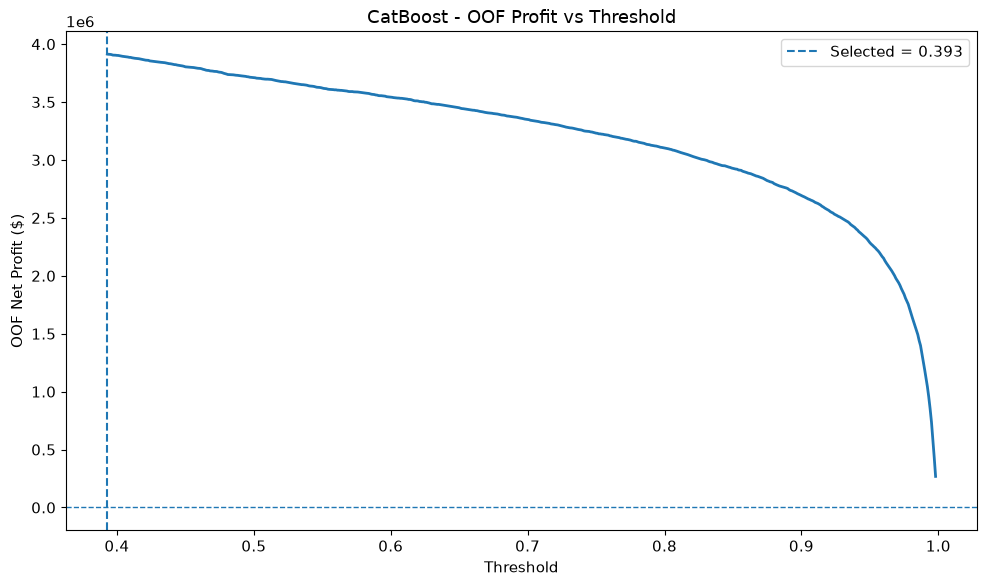


DIAGNOSTIC COMPLETED


In [111]:
# ============================================================
# DIAGNOSTIC 15D: PROFIT LANDSCAPE
# ============================================================

print("=" * 60)
print("CATBOOST - PROFIT LANDSCAPE DIAGNOSTIC")
print("=" * 60)

# ------------------------------------------------------------
# 1. Show thresholds around the selected threshold
# ------------------------------------------------------------

print("\nThreshold analysis:")

diagnostic_thresholds = [
    0.001,
    0.002,
    0.003,
    0.004,
    0.005,
    0.006,
    0.007,
    0.008,
    0.009,
    0.010,
    0.015,
    0.020,
    0.030,
    0.040,
    0.050,
    0.060
]

diagnostic_rows = []

for t in diagnostic_thresholds:

    y_pred_oof = (
        cb_oof_valid >= t
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_train_oof,
        y_pred_oof,
        labels=[0, 1]
    ).ravel()

    alert_rate = y_pred_oof.mean()

    net_profit = (
        tp * cost_fn
        - fp * cost_fp
    )

    diagnostic_rows.append({
        "Threshold": t,
        "Alert_Rate_%": alert_rate * 100,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Net_Profit": net_profit
    })

diagnostic_df = pd.DataFrame(
    diagnostic_rows
)

print(
    diagnostic_df.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 2. Best feasible thresholds
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("TOP FEASIBLE THRESHOLDS")
print("=" * 60)

feasible_rows = []

for t in thresholds_profit_cb:

    y_pred_oof = (
        cb_oof_valid >= t
    ).astype(int)

    alert_rate = y_pred_oof.mean()

    if alert_rate <= max_alert_rate:

        tn, fp, fn, tp = confusion_matrix(
            y_train_oof,
            y_pred_oof,
            labels=[0, 1]
        ).ravel()

        net_profit = (
            tp * cost_fn
            - fp * cost_fp
        )

        feasible_rows.append({
            "Threshold": t,
            "Alert_Rate_%": alert_rate * 100,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "Net_Profit": net_profit
        })

feasible_df = pd.DataFrame(
    feasible_rows
).sort_values(
    "Net_Profit",
    ascending=False
)

print(
    feasible_df.head(15).to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 3. Profit curve
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    thresholds_profit_cb,
    profits_cb_oof,
    linewidth=2
)

plt.axvline(
    best_thresh_profit_cb,
    linestyle="--",
    label=f"Selected = {best_thresh_profit_cb:.3f}"
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.xlabel("Threshold")
plt.ylabel("OOF Net Profit ($)")
plt.title(
    "CatBoost - OOF Profit vs Threshold"
)

plt.legend()
plt.tight_layout()
plt.show()


print("\n" + "=" * 60)
print("DIAGNOSTIC COMPLETED")
print("=" * 60)

### CELL 15D-B — CATBOOST SCORE DISTRIBUTION DIAGNOSTIC

CATBOOST - SCORE DISTRIBUTION DIAGNOSTIC

TEST SCORE DISTRIBUTION
------------------------------------------------------------
Fraud transactions : 4,064
Normal transactions: 114,044

Fraud scores:
count   4064.0000
mean       0.4641
std        0.3562
min        0.0010
1%         0.0095
5%         0.0321
10%        0.0516
25%        0.1127
50%        0.3873
75%        0.8317
90%        0.9638
95%        0.9829
99%        0.9949
max        0.9995
dtype: float64

Normal scores:
count   114044.0000
mean         0.0638
std          0.0948
min          0.0001
1%           0.0012
5%           0.0028
10%          0.0047
25%          0.0124
50%          0.0331
75%          0.0762
90%          0.1480
95%          0.2218
99%          0.5012
max          0.9946
dtype: float64

THRESHOLD SCORE ANALYSIS
------------------------------------------------------------
Threshold Fraud_Detection_% Normal_Alert_%  Fraud_Detected  Normal_Alerts
    0.001            100.00          99.40            4064     

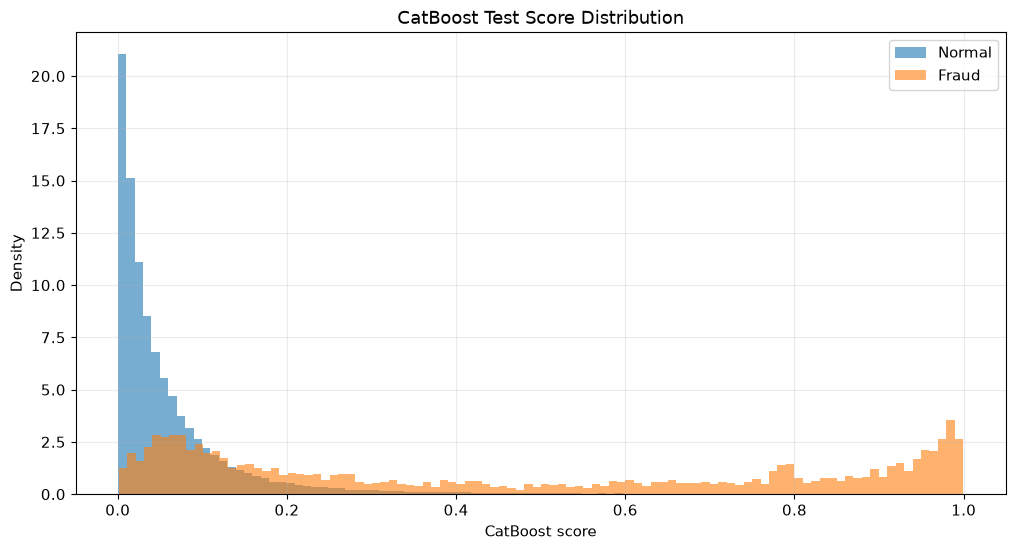


DIAGNOSTIC COMPLETED


In [112]:
# ============================================================
# CELL 15D-B — CATBOOST SCORE DISTRIBUTION DIAGNOSTIC
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 60)
print("CATBOOST - SCORE DISTRIBUTION DIAGNOSTIC")
print("=" * 60)

# ------------------------------------------------------------
# 1. Prepare test scores and labels
# ------------------------------------------------------------

cb_test_arr = np.asarray(cb_test_cv)
y_test_arr = np.asarray(y_test)

assert len(cb_test_arr) == len(y_test_arr)

fraud_scores = cb_test_arr[y_test_arr == 1]
normal_scores = cb_test_arr[y_test_arr == 0]

print("\nTEST SCORE DISTRIBUTION")
print("-" * 60)

print(f"Fraud transactions : {len(fraud_scores):,}")
print(f"Normal transactions: {len(normal_scores):,}")

print("\nFraud scores:")
print(pd.Series(fraud_scores).describe(
    percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
))

print("\nNormal scores:")
print(pd.Series(normal_scores).describe(
    percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
))

# ------------------------------------------------------------
# 2. Detection rate among fraud
# ------------------------------------------------------------

thresholds_check = [
    0.001,
    0.002,
    0.003,
    0.005,
    0.010,
    0.020,
    0.030,
    0.040,
    0.050,
    0.060
]

rows = []

for t in thresholds_check:

    fraud_detected = (fraud_scores >= t).sum()
    normal_alerts = (normal_scores >= t).sum()

    fraud_detection_rate = fraud_detected / len(fraud_scores)
    false_alert_rate = normal_alerts / len(normal_scores)

    rows.append({
        "Threshold": t,
        "Fraud_Detection_%": fraud_detection_rate * 100,
        "Normal_Alert_%": false_alert_rate * 100,
        "Fraud_Detected": fraud_detected,
        "Normal_Alerts": normal_alerts
    })

score_df = pd.DataFrame(rows)

print("\nTHRESHOLD SCORE ANALYSIS")
print("-" * 60)

print(
    score_df.to_string(
        index=False,
        formatters={
            "Threshold": "{:.3f}".format,
            "Fraud_Detection_%": "{:.2f}".format,
            "Normal_Alert_%": "{:.2f}".format
        }
    )
)

# ------------------------------------------------------------
# 3. Score distribution plot
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

plt.hist(
    normal_scores,
    bins=100,
    alpha=0.6,
    density=True,
    label="Normal"
)

plt.hist(
    fraud_scores,
    bins=100,
    alpha=0.6,
    density=True,
    label="Fraud"
)

plt.xlabel("CatBoost score")
plt.ylabel("Density")
plt.title("CatBoost Test Score Distribution")
plt.legend()
plt.grid(alpha=0.25)

plt.show()

print("\n" + "=" * 60)
print("DIAGNOSTIC COMPLETED")
print("=" * 60)

## CELL 15E: Sensitivity Analysis — CatBoost

CATBOOST - SENSITIVITY ANALYSIS BY ALERT CAPACITY
✓ Required variables found

Alignment:
  OOF predictions : 413,378
  y_train         : 413,378
  Test predictions : 118,108
  y_test          : 118,108

OOF coverage:
  Valid OOF   : 344,482
  Missing OOF : 68,896
  Coverage    : 83.33%

CATBOOST SENSITIVITY RESULTS
Capacity_% Threshold OOF_Alert_% OOF_Net_Profit Test_Alert_%  Test_TP  Test_FP  Test_FN  Test_TN Test_Precision Test_Recall Test_F1 Test_Net_Profit
         1     0.981        0.99     $1,639,180         0.21      234       12     3830   114032         0.9512      0.0576  0.1086        $116,880
         2     0.854        2.00     $2,913,640         0.94      955      155     3109   113889         0.8604      0.2350  0.3692        $475,950
         3     0.625        2.99     $3,498,480         1.89     1591      640     2473   113404         0.7131      0.3915  0.5055        $789,100
         5     0.393        4.99     $3,914,580         3.34     2017     1930     2047   1

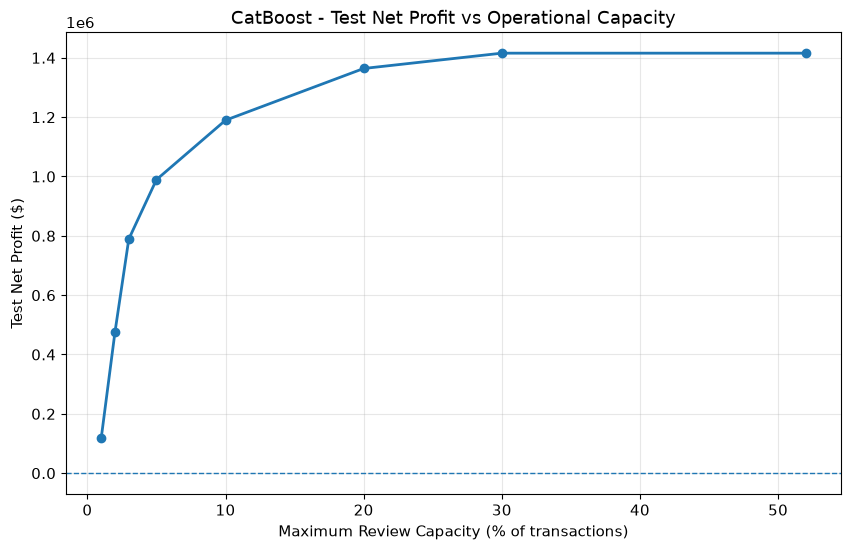

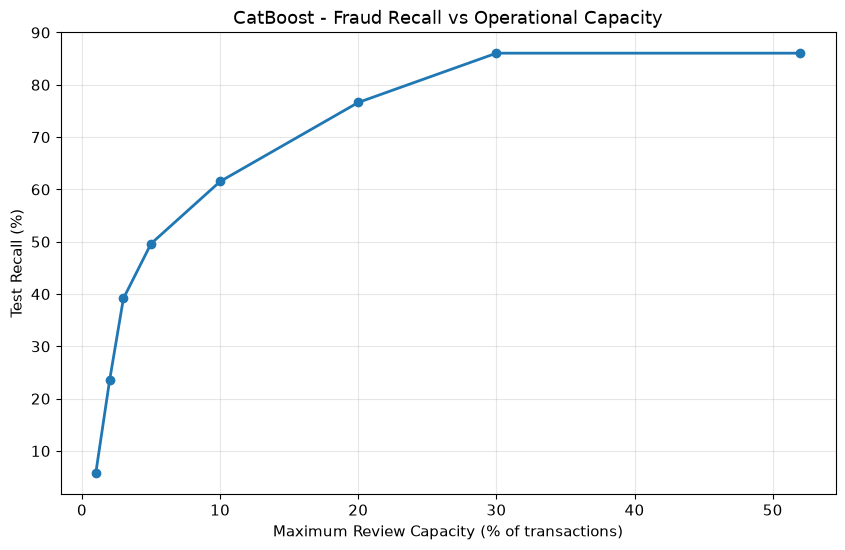


CELL 15E COMPLETED


In [113]:
# ============================================================
# CELL 15E: Sensitivity Analysis - CatBoost
# OOF Threshold Selection -> Frozen Test Evaluation
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 60)
print("CATBOOST - SENSITIVITY ANALYSIS BY ALERT CAPACITY")
print("=" * 60)

# ------------------------------------------------------------
# 1. Economic assumptions
# ------------------------------------------------------------

cost_fn = 500
cost_fp = 10
benefit_tp = 500

alert_caps = [
    0.01,
    0.02,
    0.03,
    0.05,
    0.10,
    0.20,
    0.30,
    0.52
]

# ------------------------------------------------------------
# 2. Required variables
# ------------------------------------------------------------

required_vars = [
    "cb_oof",
    "cb_test_cv",
    "y_train",
    "y_test"
]

missing_vars = [
    v for v in required_vars
    if v not in globals()
]

if missing_vars:
    raise RuntimeError(
        f"Missing required variables: {missing_vars}"
    )

print("✓ Required variables found")

# ------------------------------------------------------------
# 3. Convert to numpy
# ------------------------------------------------------------

cb_oof_arr = np.asarray(cb_oof)
cb_test_arr = np.asarray(cb_test_cv)

y_train_arr = np.asarray(y_train)
y_test_arr = np.asarray(y_test)

# ------------------------------------------------------------
# 4. Alignment checks
# ------------------------------------------------------------

assert len(cb_oof_arr) == len(y_train_arr), (
    "cb_oof and y_train have different lengths"
)

assert len(cb_test_arr) == len(y_test_arr), (
    "cb_test_cv and y_test have different lengths"
)

print("\nAlignment:")
print(f"  OOF predictions : {len(cb_oof_arr):,}")
print(f"  y_train         : {len(y_train_arr):,}")
print(f"  Test predictions : {len(cb_test_arr):,}")
print(f"  y_test          : {len(y_test_arr):,}")

# ------------------------------------------------------------
# 5. Valid OOF samples
# ------------------------------------------------------------

valid_oof_mask = np.isfinite(cb_oof_arr)

cb_oof_valid = cb_oof_arr[valid_oof_mask]
y_train_oof = y_train_arr[valid_oof_mask]

print("\nOOF coverage:")
print(f"  Valid OOF   : {len(cb_oof_valid):,}")
print(f"  Missing OOF : {(~valid_oof_mask).sum():,}")
print(
    f"  Coverage    : "
    f"{len(cb_oof_valid) / len(cb_oof_arr) * 100:.2f}%"
)

# ------------------------------------------------------------
# 6. Threshold grid
# ------------------------------------------------------------

threshold_grid = np.arange(
    0.001,
    0.999,
    0.001
)

# ------------------------------------------------------------
# 7. Optimize threshold on OOF for each capacity
# ------------------------------------------------------------

sensitivity_rows = []

for cap in alert_caps:

    best_threshold = None
    best_oof_profit = -np.inf
    best_oof_alert_rate = None

    # ----------------------------------------
    # OOF threshold selection
    # ----------------------------------------

    for t in threshold_grid:

        y_pred_oof = (
            cb_oof_valid >= t
        ).astype(int)

        alert_rate = y_pred_oof.mean()

        # Respect operational capacity
        if alert_rate > cap:
            continue

        tp = np.sum(
            (y_train_oof == 1) &
            (y_pred_oof == 1)
        )

        fp = np.sum(
            (y_train_oof == 0) &
            (y_pred_oof == 1)
        )

        fn = np.sum(
            (y_train_oof == 1) &
            (y_pred_oof == 0)
        )

        oof_profit = (
            tp * benefit_tp
            - fp * cost_fp
        )

        if oof_profit > best_oof_profit:

            best_oof_profit = oof_profit
            best_threshold = t
            best_oof_alert_rate = alert_rate

    # ----------------------------------------
    # Safety check
    # ----------------------------------------

    if best_threshold is None:

        sensitivity_rows.append({
            "Capacity_%": cap * 100,
            "Threshold": np.nan,
            "OOF_Alert_%": np.nan,
            "Test_Alert_%": np.nan,
            "Test_TP": np.nan,
            "Test_FP": np.nan,
            "Test_FN": np.nan,
            "Test_Precision": np.nan,
            "Test_Recall": np.nan,
            "Test_F1": np.nan,
            "Test_Net_Profit": np.nan
        })

        continue

    # --------------------------------------------------------
    # 8. Freeze threshold
    # --------------------------------------------------------

    y_pred_test = (
        cb_test_arr >= best_threshold
    ).astype(int)

    # --------------------------------------------------------
    # 9. Test confusion matrix
    # --------------------------------------------------------

    tp_test = np.sum(
        (y_test_arr == 1) &
        (y_pred_test == 1)
    )

    fp_test = np.sum(
        (y_test_arr == 0) &
        (y_pred_test == 1)
    )

    fn_test = np.sum(
        (y_test_arr == 1) &
        (y_pred_test == 0)
    )

    tn_test = np.sum(
        (y_test_arr == 0) &
        (y_pred_test == 0)
    )

    # --------------------------------------------------------
    # 10. Test metrics
    # --------------------------------------------------------

    test_alert_rate = y_pred_test.mean()

    precision = (
        tp_test / (tp_test + fp_test)
        if (tp_test + fp_test) > 0
        else 0
    )

    recall = (
        tp_test / (tp_test + fn_test)
        if (tp_test + fn_test) > 0
        else 0
    )

    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0
        else 0
    )

    # --------------------------------------------------------
    # 11. Test economic result
    # --------------------------------------------------------

    test_net_profit = (
        tp_test * benefit_tp
        - fp_test * cost_fp
    )

    # --------------------------------------------------------
    # 12. Save row
    # --------------------------------------------------------

    sensitivity_rows.append({

        "Capacity_%": cap * 100,

        "Threshold": best_threshold,

        "OOF_Alert_%":
            best_oof_alert_rate * 100,

        "OOF_Net_Profit":
            best_oof_profit,

        "Test_Alert_%":
            test_alert_rate * 100,

        "Test_TP":
            tp_test,

        "Test_FP":
            fp_test,

        "Test_FN":
            fn_test,

        "Test_TN":
            tn_test,

        "Test_Precision":
            precision,

        "Test_Recall":
            recall,

        "Test_F1":
            f1,

        "Test_Net_Profit":
            test_net_profit
    })


# ------------------------------------------------------------
# 13. Create result dataframe
# ------------------------------------------------------------

sensitivity_cb_df = pd.DataFrame(
    sensitivity_rows
)

print("\n" + "=" * 60)
print("CATBOOST SENSITIVITY RESULTS")
print("=" * 60)

print(
    sensitivity_cb_df.to_string(
        index=False,
        formatters={
            "Capacity_%": "{:.0f}".format,
            "Threshold": "{:.3f}".format,
            "OOF_Alert_%": "{:.2f}".format,
            "OOF_Net_Profit": "${:,.0f}".format,
            "Test_Alert_%": "{:.2f}".format,
            "Test_Precision": "{:.4f}".format,
            "Test_Recall": "{:.4f}".format,
            "Test_F1": "{:.4f}".format,
            "Test_Net_Profit": "${:,.0f}".format
        }
    )
)

# ------------------------------------------------------------
# 14. Plot Test Net Profit vs capacity
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    sensitivity_cb_df["Capacity_%"],
    sensitivity_cb_df["Test_Net_Profit"],
    marker="o",
    linewidth=2
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.xlabel(
    "Maximum Review Capacity (% of transactions)"
)

plt.ylabel(
    "Test Net Profit ($)"
)

plt.title(
    "CatBoost - Test Net Profit vs Operational Capacity"
)

plt.grid(alpha=0.3)

plt.show()

# ------------------------------------------------------------
# 15. Plot Test Recall vs capacity
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    sensitivity_cb_df["Capacity_%"],
    sensitivity_cb_df["Test_Recall"] * 100,
    marker="o",
    linewidth=2
)

plt.xlabel(
    "Maximum Review Capacity (% of transactions)"
)

plt.ylabel(
    "Test Recall (%)"
)

plt.title(
    "CatBoost - Fraud Recall vs Operational Capacity"
)

plt.grid(alpha=0.3)

plt.show()

print("\n" + "=" * 60)
print("CELL 15E COMPLETED")
print("=" * 60)

In [114]:
# ============================================================
# CHECK: CURRENT STACKING VARIABLES
# ============================================================

print("=" * 60)
print("CHECKING STACKING VARIABLES")
print("=" * 60)

stack_candidates = [
    "stack_oof",
    "stack_test_cv",
    "stacking_oof",
    "stacking_test_cv",
    "y_pred_stack_oof",
    "y_pred_stack_test_cv",
    "Stacking_CV",
    "stack_oof_proba",
    "stack_test_proba",
]

for name in stack_candidates:
    if name in globals():
        obj = globals()[name]

        try:
            print(
                f"✓ {name:<25} "
                f"type={type(obj).__name__:<15} "
                f"shape/len={getattr(obj, 'shape', len(obj) if hasattr(obj, '__len__') else 'N/A')}"
            )
        except Exception:
            print(f"✓ {name}")

print("=" * 60)

CHECKING STACKING VARIABLES
✓ stack_oof                 type=ndarray         shape/len=(344482,)
✓ y_pred_stack_oof          type=ndarray         shape/len=(344482,)


In [115]:
# ============================================================
# CHECK: ALL STACKING / CV TEST VARIABLES
# ============================================================

print("=" * 60)
print("SEARCHING FOR STACKING CV-TEST VARIABLES")
print("=" * 60)

keywords = [
    "stack",
    "Stack",
    "STACK"
]

found = []

# list(...) snapshot: globals() changes while we iterate
for name in list(globals()):

    if any(k in name for k in keywords):

        obj = globals()[name]

        try:
            shape = getattr(obj, "shape", None)

            if shape is not None:
                info = f"shape={shape}"
            elif hasattr(obj, "__len__"):
                info = f"len={len(obj):,}"
            else:
                info = f"type={type(obj).__name__}"

            found.append((name, type(obj).__name__, info))

        except Exception:
            found.append((name, type(obj).__name__, "unable to inspect"))


for name, obj_type, info in sorted(found):

    print(
        f"{name:<35} "
        f"{obj_type:<20} "
        f"{info}"
    )

print("=" * 60)
print(f"Total stacking-related variables found: {len(found)}")
print("=" * 60)

SEARCHING FOR STACKING CV-TEST VARIABLES
best_thresh_profit_stack            float                type=float
cv_stacking_test_auc                float                type=float
cv_stacking_test_pr_auc             float                type=float
f1_stack_cv                         float                type=float
final_stack                         ndarray              shape=(344482,)
final_stack_cv_test                 ndarray              shape=(118108,)
final_stack_full                    ndarray              shape=(118108,)
final_stack_full_val                ndarray              shape=(59054,)
final_stack_v2_test                 ndarray              shape=(118108,)
final_stack_v2_val                  ndarray              shape=(59054,)
full_stacking_auc                   float                type=float
full_stacking_pr_auc                float                type=float
mean_stack                          float64              shape=()
pct_stack_better                    float64      

## CELL 15F: Threshold Optimized for Profit - XGBoost

In [116]:
print("="*60)
print("Optimisation du Threshold (Profit) - XGBoost")
print("Threshold chosen on VALIDATION, evaluated on TEST")
print("="*60)

cost_fn, cost_fp = 500, 10
max_alert_rate = 0.05
thresholds_profit_xgb = np.arange(0.01, 0.99, 0.01)

if 'y_val_proba_xgb' not in dir():
    y_val_proba_xgb = model_xgb.predict_proba(X_val)[:, 1]

profits_xgb_constrained = []
for t in thresholds_profit_xgb:
    pred_v = (y_val_proba_xgb > t).astype(int)
    tp_v = int(((pred_v == 1) & (np.asarray(y_val) == 1)).sum())
    fp_v = int(((pred_v == 1) & (np.asarray(y_val) == 0)).sum())
    profit_v = tp_v*cost_fn - fp_v*cost_fp
    profits_xgb_constrained.append(
        profit_v if pred_v.mean() <= max_alert_rate else -np.inf
    )

best_thresh_profit_xgb = thresholds_profit_xgb[np.argmax(profits_xgb_constrained)]
y_pred_profit_xgb = (y_pred_proba_xgb > best_thresh_profit_xgb).astype(int)
cm_p = confusion_matrix(y_test, y_pred_profit_xgb)
TP_p, FP_p, FN_p, TN_p = cm_p[1,1], cm_p[0,1], cm_p[1,0], cm_p[0,0]

net_p = TP_p*cost_fn - FP_p*cost_fp

print(f"🎯 Threshold (Profit on val, capacité≤5%, XGBoost): {best_thresh_profit_xgb:.2f}")
print(f"   TEST -> TP: {TP_p:,} | FP: {FP_p:,} | FN: {FN_p:,}")
print(f"   Taux d'alerte (test): {y_pred_profit_xgb.mean()*100:.2f}%")
print(f"   Bénéfice net (test): ${net_p:,}")
print(f"\n📊 COMPARAISON FINALE (même contrainte 5% pour les 3):")
print(f"   LightGBM: (voir CELL 15B)")
print(f"   CatBoost: (voir CELL 15D)")
print(f"   XGBoost:  ${net_p:,}")


Optimisation du Threshold (Profit) - XGBoost
Threshold chosen on VALIDATION, evaluated on TEST
🎯 Threshold (Profit on val, capacité≤5%, XGBoost): 0.42
   TEST -> TP: 2,293 | FP: 3,628 | FN: 1,771
   Taux d'alerte (test): 5.01%
   Bénéfice net (test): $1,110,220

📊 COMPARAISON FINALE (même contrainte 5% pour les 3):
   LightGBM: (voir CELL 15B)
   CatBoost: (voir CELL 15D)
   XGBoost:  $1,110,220


## CELL 15G: Threshold Optimized for Profit - Stacking_Full

In [117]:
# ============================================================
# CELL 15G: Threshold Optimized for Profit - Stacking_Full
# Threshold chosen on VALIDATION with the FULL models
# (same scores that are evaluated on test), then frozen.
# ============================================================
print("="*60)
print("Optimisation du Threshold (Profit) - Stacking_Full")
print("Threshold chosen on VALIDATION (full models), evaluated on TEST")
print("="*60)

cost_fn, cost_fp = 500, 10
max_alert_rate = 0.05


def choose_profit_threshold(scores, y_true, cap=max_alert_rate,
                            grid=np.arange(0.001, 0.999, 0.001)):
    """Best TP*cost_fn - FP*cost_fp threshold with alert rate <= cap."""
    scores = np.asarray(scores, dtype=np.float64)
    y_arr = np.asarray(y_true)
    best_t, best_p = None, -np.inf
    for t in grid:
        pred = scores >= t
        if pred.mean() > cap:
            continue
        p = (int((pred & (y_arr == 1)).sum()) * cost_fn
             - int((pred & (y_arr == 0)).sum()) * cost_fp)
        if p > best_p:
            best_t, best_p = float(t), p
    if best_t is None:
        raise ValueError("No threshold satisfies the alert-rate cap.")
    return best_t


def evaluate_at(scores, y_true, t):
    pred = np.asarray(scores) >= t
    y_arr = np.asarray(y_true)
    tp = int((pred & (y_arr == 1)).sum())
    fp = int((pred & (y_arr == 0)).sum())
    fn = int(((~pred) & (y_arr == 1)).sum())
    return {"TP": tp, "FP": fp, "FN": fn,
            "Alert_%": pred.mean() * 100,
            "Net": tp * cost_fn - fp * cost_fp}


required = ["final_stack_v2_val", "final_stack_v2_test", "n_val_meta",
            "y_val_proba_cb_full"]
missing = [v for v in required if v not in globals()]
if missing:
    raise NameError(f"Re-run CELL 13B first (missing: {missing})")

# Deployable stacking (V2, CELL 13B section 23B):
# meta-learner fitted on val 1st half -> threshold on val 2nd half
stack_val_thr_scores = final_stack_v2_val[n_val_meta:]
stack_val_thr_y = np.asarray(y_val)[n_val_meta:]

best_thresh_profit_stack = choose_profit_threshold(stack_val_thr_scores, stack_val_thr_y)
res_stack = evaluate_at(final_stack_v2_test, y_test, best_thresh_profit_stack)
y_pred_profit_stack = (final_stack_v2_test >= best_thresh_profit_stack).astype(int)

print(f"🎯 Threshold (Profit on val 2nd half, capacité≤5%, Stacking V2): "
      f"{best_thresh_profit_stack:.3f}")
print(f"   Val (2nd half) alert rate : "
      f"{(stack_val_thr_scores >= best_thresh_profit_stack).mean()*100:.2f}%")
print(f"   TEST -> TP: {res_stack['TP']:,} | FP: {res_stack['FP']:,} | FN: {res_stack['FN']:,}")
print(f"   Taux d'alerte réel (test): {res_stack['Alert_%']:.2f}%")
print(f"   Bénéfice net (test): ${res_stack['Net']:,}")

print(f"\n📊 COMPARAISON FINALE (même contrainte 5%, seuils choisis sur val/OOF):")
print(f"   LightGBM:      (voir CELL 15B)")
print(f"   XGBoost:       (voir CELL 15F)")
print(f"   CatBoost:      (voir CELL 15D / CELL 18)")
print(f"   Stacking V2:   ${res_stack['Net']:,}")


Optimisation du Threshold (Profit) - Stacking_Full
Threshold chosen on VALIDATION (full models), evaluated on TEST
🎯 Threshold (Profit on val 2nd half, capacité≤5%, Stacking V2): 0.046
   Val (2nd half) alert rate : 4.98%
   TEST -> TP: 2,522 | FP: 3,368 | FN: 1,542
   Taux d'alerte réel (test): 4.99%
   Bénéfice net (test): $1,227,320

📊 COMPARAISON FINALE (même contrainte 5%, seuils choisis sur val/OOF):
   LightGBM:      (voir CELL 15B)
   XGBoost:       (voir CELL 15F)
   CatBoost:      (voir CELL 15D / CELL 18)
   Stacking V2:   $1,227,320


## CELL 15H: Bootstrap Stability Analysis - CatBoost vs Stacking_Full

In [118]:
# ============================================================
# CELL 15H: Bootstrap Stability - CatBoost (production) vs Stacking_Full
# Fair comparison: both are FULL 13B models, both thresholds are
# chosen on VALIDATION with the same 5% alert cap, then frozen.
# Only the test sample is resampled.
# ============================================================
print("="*60)
print("Bootstrap Stability Analysis (n=30 resamples)")
print("CatBoost (production, full) vs Stacking_Full — same 5% cap,")
print("thresholds chosen on validation and frozen.")
print("="*60)

n_bootstrap = 30
cost_fn, cost_fp = 500, 10
max_alert_rate = 0.05

# Production CatBoost threshold (same rule as CELL 18)
best_thresh_profit_cb_full = choose_profit_threshold(y_val_proba_cb_full, y_val)

scores_test = {
    "CatBoost": np.asarray(y_pred_proba_cb_full),
    "Stacking_Full": np.asarray(final_stack_v2_test),   # deployable stacking (V2)
}
frozen_thresholds = {
    "CatBoost": best_thresh_profit_cb_full,
    "Stacking_Full": best_thresh_profit_stack,
}

print("\nFull test set (frozen thresholds):")
for name in scores_test:
    r = evaluate_at(scores_test[name], y_test, frozen_thresholds[name])
    print(f"  {name:14}: threshold={frozen_thresholds[name]:.3f} | "
          f"alerts={r['Alert_%']:.2f}% | TP={r['TP']:,} | FP={r['FP']:,} | "
          f"net=${r['Net']:,}")

y_test_arr = np.asarray(y_test)
rng = np.random.RandomState(42)
n_test = len(y_test_arr)
boot = {name: [] for name in scores_test}

for i in range(n_bootstrap):
    idx = rng.choice(n_test, size=n_test, replace=True)
    y_boot = y_test_arr[idx]
    for name in scores_test:
        pred = scores_test[name][idx] >= frozen_thresholds[name]
        tp = int((pred & (y_boot == 1)).sum())
        fp = int((pred & (y_boot == 0)).sum())
        boot[name].append(tp * cost_fn - fp * cost_fp)
    if (i+1) % 10 == 0:
        print(f"  ... {i+1}/{n_bootstrap} done")

profits_cb_boot = np.array(boot["CatBoost"])
profits_stack_boot = np.array(boot["Stacking_Full"])


def summarize(name, arr):
    ci_low, ci_high = np.percentile(arr, [2.5, 97.5])
    print(f"\n--- {name} ---")
    print(f"  Mean:   ${arr.mean():,.0f}")
    print(f"  Std:    ${arr.std():,.0f}")
    print(f"  Median: ${np.median(arr):,.0f}")
    print(f"  95% CI: [${ci_low:,.0f}, ${ci_high:,.0f}]")
    return arr.mean(), arr.std()


print("\n" + "="*60)
print("RESULTS")
print("="*60)
mean_cb, std_cb = summarize("CatBoost (production)", profits_cb_boot)
mean_stack, std_stack = summarize("Stacking_Full", profits_stack_boot)

diff = profits_stack_boot - profits_cb_boot
pct_stack_better = (diff > 0).mean() * 100
diff_ci = np.percentile(diff, [2.5, 97.5])
print(f"\n--- Difference (Stacking_Full - CatBoost) ---")
print(f"  Mean diff: ${diff.mean():,.0f}")
print(f"  95% CI:    [${diff_ci[0]:,.0f}, ${diff_ci[1]:,.0f}]")
print(f"  % of draws where Stacking_Full > CatBoost: {pct_stack_better:.1f}%")

if diff_ci[0] > 0:
    print("\n✅ CONCLUSION: Stacking_Full is better (CI of the difference > 0)")
elif diff_ci[1] < 0:
    print("\n✅ CONCLUSION: CatBoost is better (CI of the difference < 0)")
else:
    print("\n✅ CONCLUSION: no significant difference (CI contains 0)")
print("   (Both models use the same 5% review capacity.)")


Bootstrap Stability Analysis (n=30 resamples)
CatBoost (production, full) vs Stacking_Full — same 5% cap,
thresholds chosen on validation and frozen.

Full test set (frozen thresholds):
  CatBoost      : threshold=0.494 | alerts=4.56% | TP=2,377 | FP=3,009 | net=$1,158,410
  Stacking_Full : threshold=0.046 | alerts=4.99% | TP=2,522 | FP=3,368 | net=$1,227,320
  ... 10/30 done
  ... 20/30 done
  ... 30/30 done

RESULTS

--- CatBoost (production) ---
  Mean:   $1,160,895
  Std:    $21,138
  Median: $1,163,485
  95% CI: [$1,123,756, $1,194,190]

--- Stacking_Full ---
  Mean:   $1,228,009
  Std:    $23,786
  Median: $1,231,295
  95% CI: [$1,186,412, $1,272,726]

--- Difference (Stacking_Full - CatBoost) ---
  Mean diff: $67,115
  95% CI:    [$52,672, $79,305]
  % of draws where Stacking_Full > CatBoost: 100.0%

✅ CONCLUSION: Stacking_Full is better (CI of the difference > 0)
   (Both models use the same 5% review capacity.)


## CELL 16: NEURAL NETWORK - FIXED

Neural Network - FIXED 100%
fix NaN correctly 100%...
✅ NaN Train: 0
✅ NaN Val:   0
✅ NaN Test:  0

Data normalization...
✅ NaN after Scaler Train: 0
✅ NaN after Scaler Val:   0
✅ NaN after Scaler Test:  0
✅ Shape: (413378, 511)

✅ Class weights: {0: 0.5182253535252231, 1: 14.217155041959003}

✅ Paramètres: 176,129

Training Neural Network...
Epoch 1/30
202/202 ━━━━━━━━━━━━━━━━━━━━ 12s 38ms/step - auc: 0.8271 - loss: 0.5154 - val_auc: 0.8717 - val_loss: 0.4199 - learning_rate: 0.0010
Epoch 2/30
202/202 ━━━━━━━━━━━━━━━━━━━━ 6s 31ms/step - auc: 0.8744 - loss: 0.4408 - val_auc: 0.8778 - val_loss: 0.3897 - learning_rate: 0.0010
Epoch 3/30
202/202 ━━━━━━━━━━━━━━━━━━━━ 7s 32ms/step - auc: 0.8877 - loss: 0.4181 - val_auc: 0.8838 - val_loss: 0.3512 - learning_rate: 0.0010
Epoch 4/30
202/202 ━━━━━━━━━━━━━━━━━━━━ 7s 32ms/step - auc: 0.8954 - loss: 0.4046 - val_auc: 0.8893 - val_loss: 0.3570 - learning_rate: 0.0010
Epoch 5/30
202/202 ━━━━━━━━━━━━━━━━━━━━ 7s 33ms/step - auc: 0.9032 - loss: 0.3899 

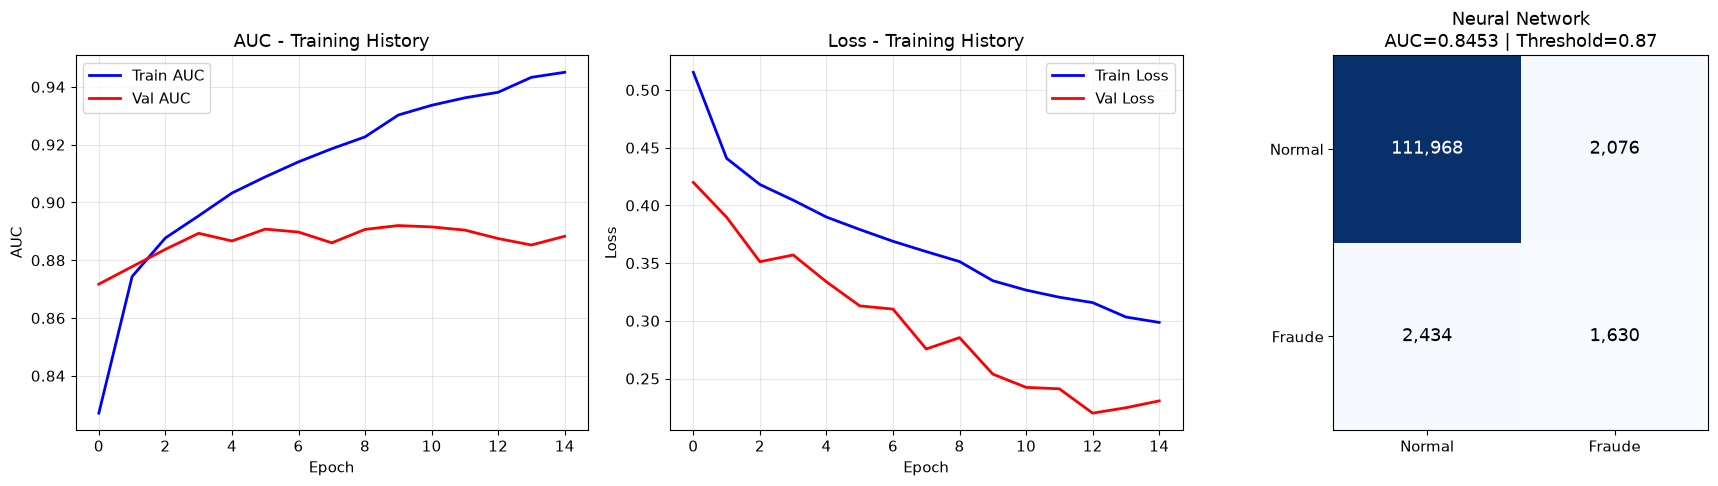

✅ Neural Network 100% finished!

comparison for now :
  Baseline_LogisticRegression: AUC=0.8274 | Recall=0.450 | F1=0.312
  Imbalance_ClassWeight: AUC=0.8962 | Recall=0.433 | F1=0.504
  Imbalance_SMOTE     : AUC=0.9039 | Recall=0.480 | F1=0.494
  Imbalance_Undersampling: AUC=0.9097 | Recall=0.465 | F1=0.497
  LightGBM            : AUC=0.9057 | Recall=0.450 | F1=0.522
  XGBoost             : AUC=0.8982 | Recall=0.443 | F1=0.505
  CatBoost            : AUC=0.9045 | Recall=0.441 | F1=0.488
  LightGBM_ProfitOptimized: AUC=0.9057 | Recall=0.578 | F1=0.469
  CatBoost_ProfitOptimized: AUC=0.8885 | Recall=0.496 | F1=0.504
  NeuralNetwork       : AUC=0.8453 | Recall=0.401 | F1=0.420
  AutoEncoder         : AUC=0.7567 | Recall=0.314 | F1=0.216


In [119]:
# ============================================
# CELL 23 FIXED: Neural Network 100%
# ============================================
print("="*60)
print("Neural Network - FIXED 100%")
print("="*60)

import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import (
    compute_class_weight
)

# ===== 1. fix NaN 100% =====
print("fix NaN correctly 100%...")

X_train_nn = X_train.copy()
X_val_nn   = X_val.copy()
X_test_nn  = X_test.copy()

# ← Main update::
# we calculate medians from Train only
# We apply it to all three, then fill in the rest with 0.
medians = X_train_nn.median()

X_train_nn = X_train_nn.fillna(
    medians
).fillna(0)
X_val_nn   = X_val_nn.fillna(
    medians
).fillna(0)
X_test_nn  = X_test_nn.fillna(
    medians
).fillna(0)

# verification
print(f"✅ NaN Train: "
      f"{X_train_nn.isnull().sum().sum()}")
print(f"✅ NaN Val:   "
      f"{X_val_nn.isnull().sum().sum()}")
print(f"✅ NaN Test:  "
      f"{X_test_nn.isnull().sum().sum()}")

# ===== 2.normalization=====
print("\nData normalization...")
scaler_nn = StandardScaler()
X_train_sc = scaler_nn.fit_transform(X_train_nn)
X_val_sc   = scaler_nn.transform(X_val_nn)
X_test_sc  = scaler_nn.transform(X_test_nn)

# ← Update: nan_to_num after Scaler
X_train_sc = np.nan_to_num(
    X_train_sc,
    nan=0.0, posinf=0.0, neginf=0.0
)
X_val_sc   = np.nan_to_num(
    X_val_sc,
    nan=0.0, posinf=0.0, neginf=0.0
)
X_test_sc  = np.nan_to_num(
    X_test_sc,
    nan=0.0, posinf=0.0, neginf=0.0
)

# Final verification
print(f"✅ NaN after Scaler Train: "
      f"{np.isnan(X_train_sc).sum()}")
print(f"✅ NaN after Scaler Val:   "
      f"{np.isnan(X_val_sc).sum()}")
print(f"✅ NaN after Scaler Test:  "
      f"{np.isnan(X_test_sc).sum()}")
print(f"✅ Shape: {X_train_sc.shape}")

# ===== 3. Class Weight =====
cw = compute_class_weight(
    'balanced',
    classes=np.unique(y_train),
    y=y_train
)
cw_dict = {
    0: float(cw[0]),
    1: float(cw[1])
}
print(f"\n✅ Class weights: {cw_dict}")

# ===== 4.Model building=====
n_feat = X_train_sc.shape[1]

model_nn_final = tf.keras.Sequential([
    tf.keras.layers.Dense(
        256, activation='relu',
        input_shape=(n_feat,)
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(
        128, activation='relu'
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(
        64, activation='relu'
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.2),

    tf.keras.layers.Dense(
        32, activation='relu'
    ),
    tf.keras.layers.Dropout(0.1),

    tf.keras.layers.Dense(
        1, activation='sigmoid'
    )
])

model_nn_final.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss='binary_crossentropy',
    metrics=[
        tf.keras.metrics.AUC(name='auc')
    ]
)

print(f"\n✅ Paramètres: "
      f"{model_nn_final.count_params():,}")

# ===== 5. Callbacks =====
callbacks_nn = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_auc',
        patience=5,
        restore_best_weights=True,
        mode='max', verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_auc',
        factor=0.5, patience=3,
        mode='max', min_lr=1e-6,
        verbose=1
    )
]

# ===== 6. Training =====
print("\nTraining Neural Network...")
history_nn = model_nn_final.fit(
    X_train_sc, y_train,
    validation_data=(X_val_sc, y_val),
    epochs=30,
    batch_size=2048,
    class_weight=cw_dict,
    callbacks=callbacks_nn,
    verbose=1
)

# ===== 7. Evaluation =====
print("\nEvaluating...")
y_pred_proba_nn = model_nn_final.predict(
    X_test_sc, verbose=0
).flatten()

# ← Update: Check for NaN in predictions
nan_count = np.isnan(y_pred_proba_nn).sum()
inf_count = np.isinf(y_pred_proba_nn).sum()
print(f"NaN in predictions:{nan_count}")
print(f"Inf in predictions: {inf_count}")

# Treatment if NaN is found
if nan_count > 0 or inf_count > 0:
    y_pred_proba_nn = np.nan_to_num(
        y_pred_proba_nn,
        nan=0.5, posinf=1.0, neginf=0.0
    )
    print("✅ NaN/Inf to treat")

auc_nn = roc_auc_score(y_test, y_pred_proba_nn)

# Threshold selected on VALIDATION (never on test)
y_val_proba_nn = np.nan_to_num(
    model_nn_final.predict(X_val_sc, verbose=0).flatten(),
    nan=0.5, posinf=1.0, neginf=0.0
)
thresholds = np.arange(0.1, 0.9, 0.01)
f1_nn = [
    f1_score(
        y_val,
        (y_val_proba_nn > t).astype(int)
    )
    for t in thresholds
]
best_thresh_nn = thresholds[np.argmax(f1_nn)]
y_pred_nn = (
    y_pred_proba_nn > best_thresh_nn
).astype(int)

print(f"\n🎯 AUC-ROC Neural Network: {auc_nn:.4f}")
print(f"🎯 Best Threshold: {best_thresh_nn:.2f}")
print(classification_report(
    y_test, y_pred_nn,
    target_names=['Normal','Fraude']
))

results['NeuralNetwork'] = {
    'AUC':       auc_nn,
    'Recall':    recall_score(y_test, y_pred_nn),
    'Precision': precision_score(y_test, y_pred_nn),
    'F1':        f1_score(y_test, y_pred_nn)
}

# ===== 8. drawing ==== 
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Training History
axes[0].plot(
    history_nn.history['auc'],
    label='Train AUC',
    color='blue', linewidth=2
)
axes[0].plot(
    history_nn.history['val_auc'],
    label='Val AUC',
    color='red', linewidth=2
)
axes[0].set_title(
    'AUC - Training History'
)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('AUC')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Loss History
axes[1].plot(
    history_nn.history['loss'],
    label='Train Loss',
    color='blue', linewidth=2
)
axes[1].plot(
    history_nn.history['val_loss'],
    label='Val Loss',
    color='red', linewidth=2
)
axes[1].set_title('Loss - Training History')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Confusion Matrix
cm_nn = confusion_matrix(y_test, y_pred_nn)
axes[2].imshow(cm_nn, cmap='Blues')
for i in range(2):
    for j in range(2):
        axes[2].text(
            j, i, f'{cm_nn[i,j]:,}',
            ha='center', va='center',
            fontsize=13,
            color='white'
            if cm_nn[i,j] > cm_nn.max()/2
            else 'black'
        )
axes[2].set_xticks([0,1])
axes[2].set_yticks([0,1])
axes[2].set_xticklabels(['Normal','Fraude'])
axes[2].set_yticklabels(['Normal','Fraude'])
axes[2].set_title(
    f'Neural Network\n'
    f'AUC={auc_nn:.4f} | '
    f'Threshold={best_thresh_nn:.2f}'
)

plt.tight_layout()
plt.show()

print("✅ Neural Network 100% finished!")
print(f"\ncomparison for now :")
for m, v in results.items():
    # Stacking entries use other metric names (OOF_AUC, CV_Test_AUC, ...)
    if not all(k in v for k in ('AUC', 'Recall', 'F1')):
        continue
    print(
        f"  {m:20}: AUC={v['AUC']:.4f} | "
        f"Recall={v['Recall']:.3f} | "
        f"F1={v['F1']:.3f}"
    )

## CELL 16B: Error Analysis + Calibration + Feature Selection

Error Analysis + Calibration + Selection
1. Error Analysis...

Confusion Analysis:
  True Positives  (TP): 1,827
  False Positives (FP): 1,106
  False Negatives (FN): 2,237
  True Negatives  (TN): 112,938

FN vs TP Analysis:
  TransactionAmt           : FN=171.924 | TP=123.339
  C13                      : FN=21.658 | TP=14.956
  week                     : FN=22.691 | TP=22.851


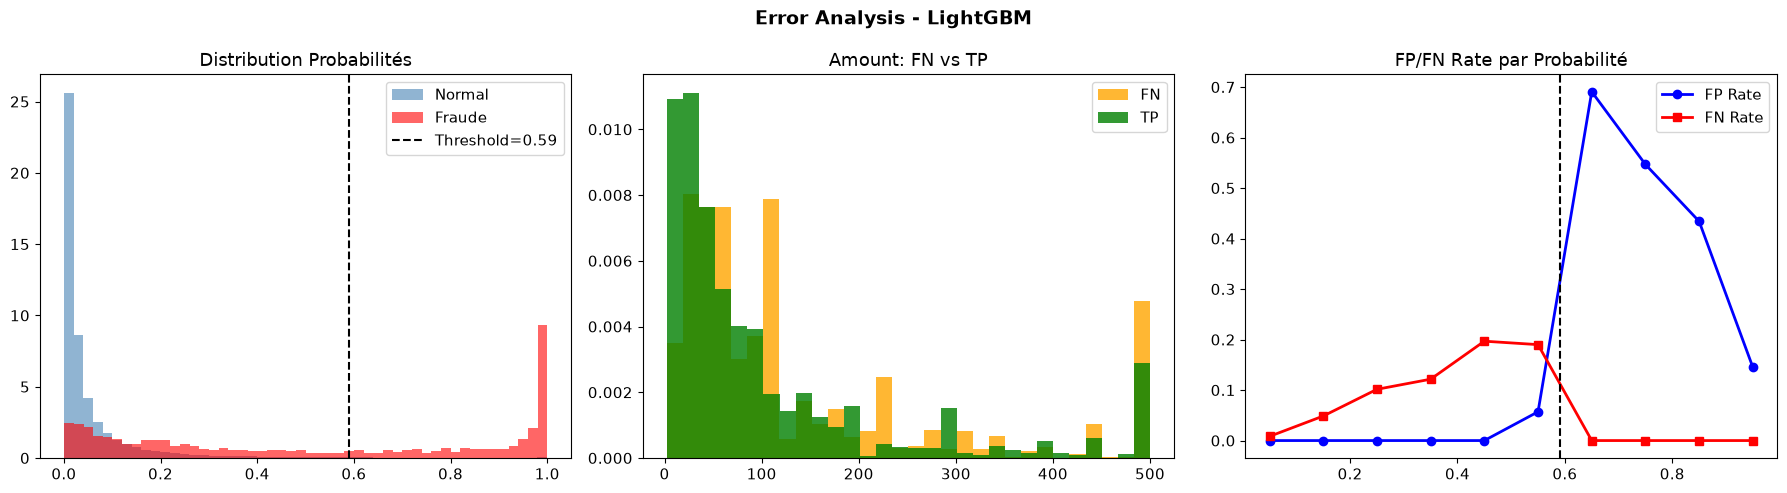


2. Probability Calibration...


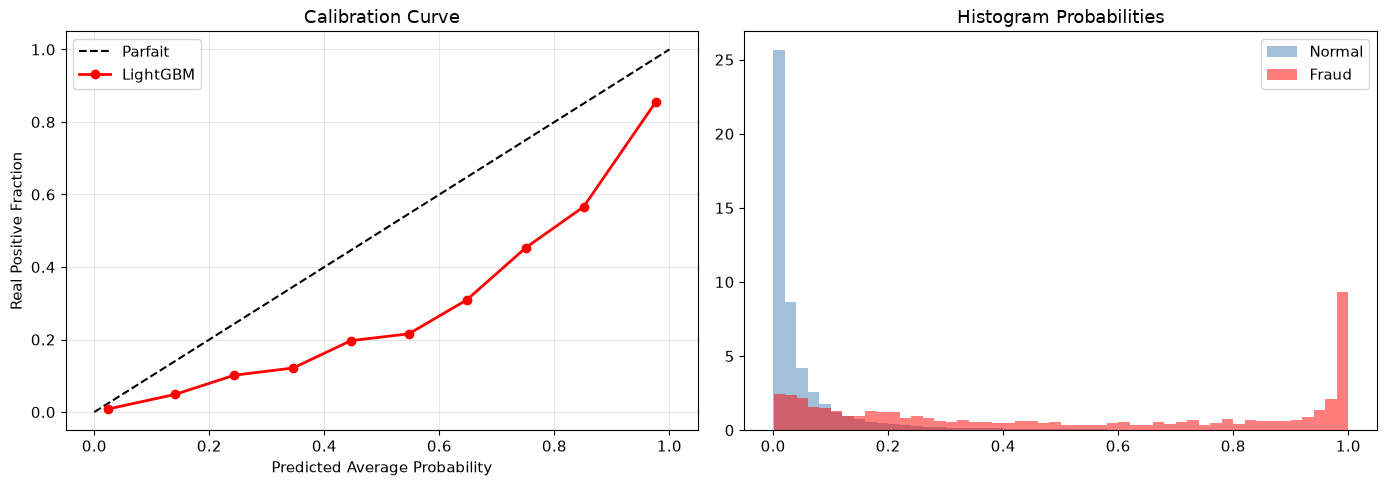

  Brier Score: 0.0272 (0=parfait)

3. Feature Selection...
  Features importance=0: 38
  Features importance<10: 160


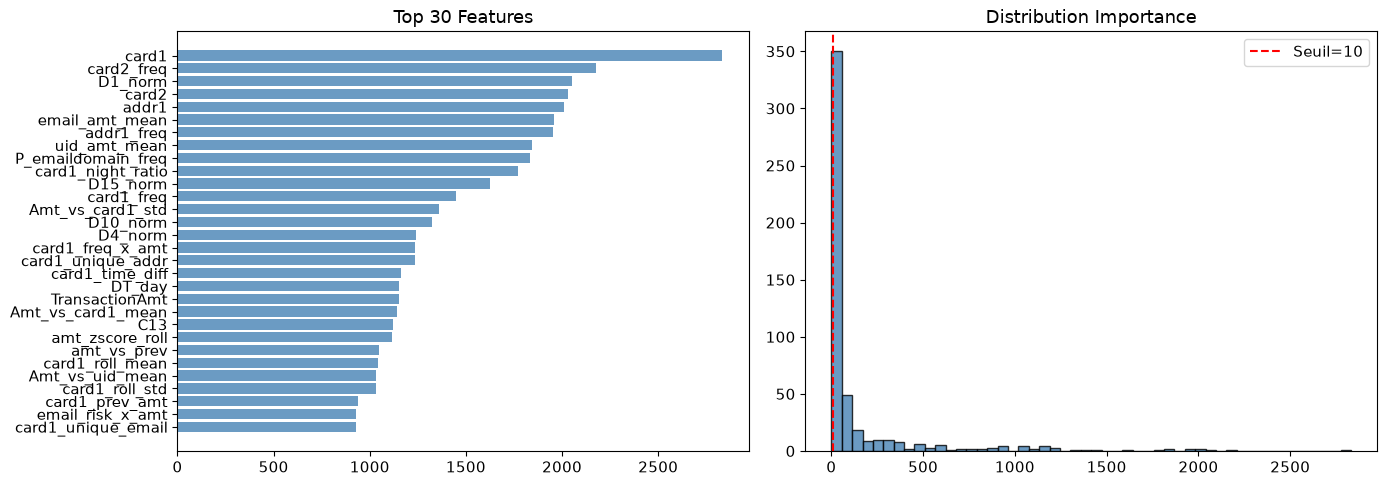


  Features sélectionnées: 351/511

✅ Error+Calibration+Selection complete!


In [120]:
# ============================================
# CELL 16B: Error Analysis + Calibration
#           + Feature Selection
# ============================================
print("="*60)
print("Error Analysis + Calibration + Selection")
print("="*60)

from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

# ===== 1. Error Analysis =====
print("1. Error Analysis...")

y_pred_best  = y_pred_lgb
y_proba_best = y_pred_proba_lgb

fn_mask = (y_test==1) & (y_pred_best==0)
fp_mask = (y_test==0) & (y_pred_best==1)
tp_mask = (y_test==1) & (y_pred_best==1)

fn_data = X_test[fn_mask]
fp_data = X_test[fp_mask]
tp_data = X_test[tp_mask]

print(f"\nConfusion Analysis:")
print(f"  True Positives  (TP): {tp_mask.sum():,}")
print(f"  False Positives (FP): {fp_mask.sum():,}")
print(f"  False Negatives (FN): {fn_mask.sum():,}")
print(f"  True Negatives  (TN): "
      f"{((y_test==0)&(y_pred_best==0)).sum():,}")

print(f"\nFN vs TP Analysis:")
for feat in ['TransactionAmt','card1_target_enc',
             'C13','week']:
    if feat in fn_data.columns:
        fn_mean = fn_data[feat].mean()
        tp_mean = tp_data[feat].mean()
        print(
            f"  {feat:25}: "
            f"FN={fn_mean:.3f} | "
            f"TP={tp_mean:.3f}"
        )

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].hist(
    y_proba_best[y_test==0],
    bins=50, color='steelblue',
    alpha=0.6, label='Normal', density=True
)
axes[0].hist(
    y_proba_best[y_test==1],
    bins=50, color='red',
    alpha=0.6, label='Fraude', density=True
)
axes[0].axvline(
    x=best_thresh_lgb, color='black',
    linestyle='--',
    label=f'Threshold={best_thresh_lgb:.2f}'
)
axes[0].set_title(
    'Distribution Probabilités'
)
axes[0].legend()

if 'TransactionAmt' in fn_data.columns:
    axes[1].hist(
        fn_data['TransactionAmt'].clip(0,500),
        bins=30, color='orange',
        alpha=0.8, label='FN', density=True
    )
    axes[1].hist(
        tp_data['TransactionAmt'].clip(0,500),
        bins=30, color='green',
        alpha=0.8, label='TP', density=True
    )
    axes[1].set_title('Amount: FN vs TP')
    axes[1].legend()

bins_prob = np.arange(0, 1.1, 0.1)
fp_rates, fn_rates = [], []
for i in range(len(bins_prob)-1):
    mask = (
        (y_proba_best >= bins_prob[i]) &
        (y_proba_best < bins_prob[i+1])
    )
    if mask.sum() > 0:
        fp_r = (
            (y_test[mask]==0) &
            (y_pred_best[mask]==1)
        ).sum() / max(mask.sum(),1)
        fn_r = (
            (y_test[mask]==1) &
            (y_pred_best[mask]==0)
        ).sum() / max(mask.sum(),1)
    else:
        fp_r, fn_r = 0, 0
    fp_rates.append(fp_r)
    fn_rates.append(fn_r)

x_bins = bins_prob[:-1] + 0.05
axes[2].plot(x_bins, fp_rates, color='blue',
    marker='o', label='FP Rate', linewidth=2)
axes[2].plot(x_bins, fn_rates, color='red',
    marker='s', label='FN Rate', linewidth=2)
axes[2].axvline(x=best_thresh_lgb,
    color='black', linestyle='--')
axes[2].set_title('FP/FN Rate par Probabilité')
axes[2].legend()

plt.suptitle('Error Analysis - LightGBM',
    fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ===== 2. Calibration =====
print("\n2. Probability Calibration...")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

fraction_pos, mean_pred = calibration_curve(
    y_test, y_pred_proba_lgb, n_bins=10
)

axes[0].plot([0,1],[0,1],'k--',label='Parfait')
axes[0].plot(mean_pred, fraction_pos, color='red',
    marker='o', linewidth=2, label='LightGBM')
axes[0].set_title('Calibration Curve')
axes[0].set_xlabel('Predicted Average Probability')
axes[0].set_ylabel('Real Positive Fraction')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].hist(
    y_pred_proba_lgb[y_test==0],
    bins=50, color='steelblue',
    alpha=0.5, label='Normal', density=True
)
axes[1].hist(
    y_pred_proba_lgb[y_test==1],
    bins=50, color='red',
    alpha=0.5, label='Fraud', density=True
)
axes[1].set_title('Histogram Probabilities')
axes[1].legend()

plt.tight_layout()
plt.show()

brier = brier_score_loss(y_test, y_pred_proba_lgb)
print(f"  Brier Score: {brier:.4f} (0=parfait)")

# ===== 3. Feature Selection =====
print("\n3. Feature Selection...")

feat_imp = pd.DataFrame({
    'Feature':    X_train.columns,
    'Importance': model_lgb_final
                  .feature_importances_
}).sort_values('Importance', ascending=False)

zero_imp = feat_imp[feat_imp['Importance']==0]
low_imp  = feat_imp[feat_imp['Importance']<10]

print(f"  Features importance=0: {len(zero_imp)}")
print(f"  Features importance<10: {len(low_imp)}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

top_30 = feat_imp.head(30)
axes[0].barh(top_30['Feature'], top_30['Importance'],
    color='steelblue', alpha=0.8)
axes[0].set_title('Top 30 Features')
axes[0].invert_yaxis()

axes[1].hist(feat_imp['Importance'], bins=50,
    color='steelblue', alpha=0.8, edgecolor='black')
axes[1].axvline(x=10, color='red',
    linestyle='--', label='Seuil=10')
axes[1].set_title('Distribution Importance')
axes[1].legend()

plt.tight_layout()
plt.show()

selected_features = feat_imp[
    feat_imp['Importance'] >= 10
]['Feature'].tolist()
print(f"\n  Features sélectionnées: "
      f"{len(selected_features)}/{len(feat_imp)}")

print("\n✅ Error+Calibration+Selection complete!")

## CELL 17: AutoEncoder

AutoEncoder - Anomaly Detection 100%
Data preparation...
✅ NaN Train: 0
✅ NaN Val:   0
✅ NaN Test:  0
✅ Train Normal: (398840, 511)
✅ Val Normal:   (56993, 511)

✅ Architecture:
   Input: 511
   Encoder: 128→64→32→16 (Bottleneck)
   Decoder: 16→32→64→128→511
✅ Settings: 153,295

Training AutoEncoder...
Epoch 1/50
779/779 ━━━━━━━━━━━━━━━━━━━━ 11s 10ms/step - loss: 0.5907 - val_loss: 0.7645 - learning_rate: 5.0000e-04
Epoch 2/50
779/779 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - loss: 0.4663 - val_loss: 0.8783 - learning_rate: 5.0000e-04
Epoch 3/50
779/779 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 0.4327 - val_loss: 0.7920 - learning_rate: 5.0000e-04
Epoch 4/50
779/779 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 0.4118 - val_loss: 0.7433 - learning_rate: 5.0000e-04
Epoch 5/50
779/779 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 0.3897 - val_loss: 0.7922 - learning_rate: 5.0000e-04
Epoch 6/50
779/779 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.3753 - val_loss: 0.7289 - learning_rate: 5.0000e-04
Epoch 7/50

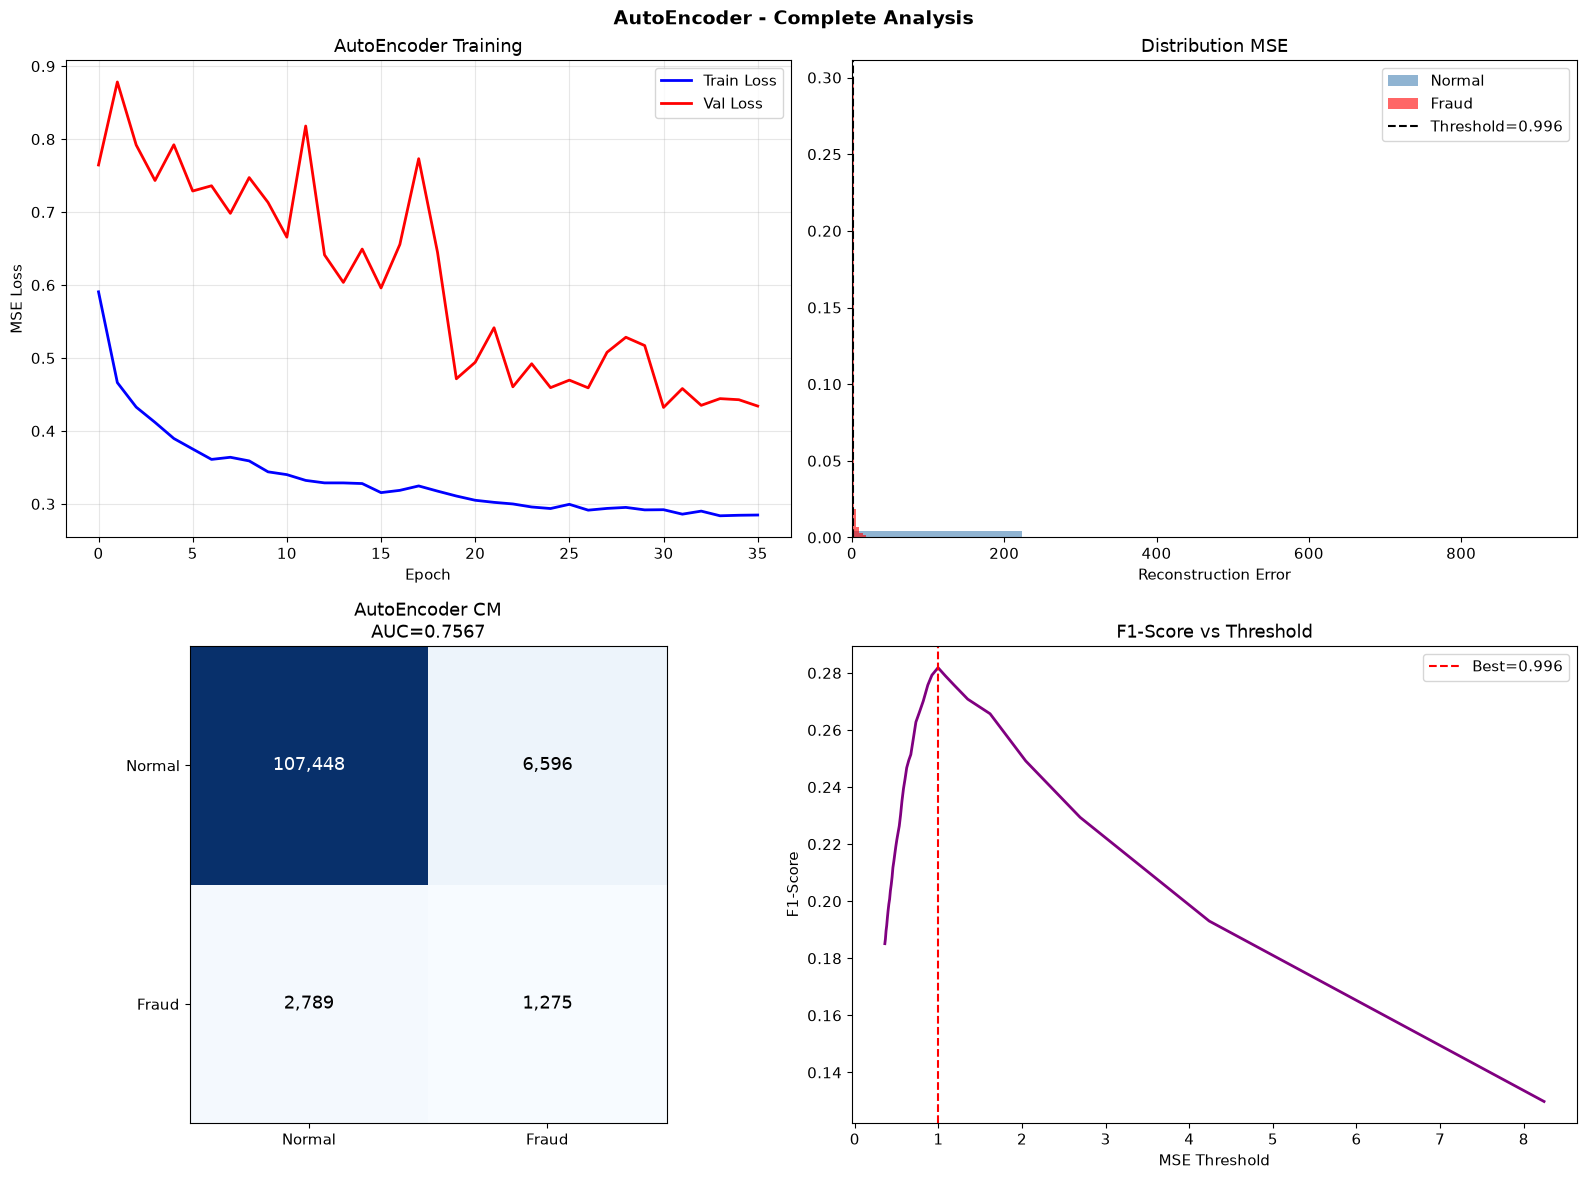

✅ AutoEncoder 100% complete!


In [121]:
# ============================================
# CELL 17 FIXED: AutoEncoder 100%
# ============================================
print("="*60)
print("AutoEncoder - Anomaly Detection 100%")
print("="*60)

# ===== 1. Data preparation===== 
print("Data preparation...")

medians_ae = X_train.median()

X_train_ae = X_train.copy().fillna(
    medians_ae
).fillna(0)
X_val_ae   = X_val.copy().fillna(
    medians_ae
).fillna(0)
X_test_ae  = X_test.copy().fillna(
    medians_ae
).fillna(0)

scaler_ae = StandardScaler()
X_train_ae_sc = scaler_ae.fit_transform(X_train_ae)
X_val_ae_sc   = scaler_ae.transform(X_val_ae)
X_test_ae_sc  = scaler_ae.transform(X_test_ae)

# ← Update: nan_to_num to ensure no NaN values
X_train_ae_sc = np.nan_to_num(
    X_train_ae_sc,
    nan=0.0, posinf=0.0, neginf=0.0
)
X_val_ae_sc   = np.nan_to_num(
    X_val_ae_sc,
    nan=0.0, posinf=0.0, neginf=0.0
)
X_test_ae_sc  = np.nan_to_num(
    X_test_ae_sc,
    nan=0.0, posinf=0.0, neginf=0.0
)

# verification
print(f"✅ NaN Train: {np.isnan(X_train_ae_sc).sum()}")
print(f"✅ NaN Val:   {np.isnan(X_val_ae_sc).sum()}")
print(f"✅ NaN Test:  {np.isnan(X_test_ae_sc).sum()}")

# Train on Normal mode only
normal_mask_train = (y_train == 0)
X_train_normal = X_train_ae_sc[
    normal_mask_train.values
]

normal_mask_val = (y_val == 0).values
X_val_normal = X_val_ae_sc[normal_mask_val]

print(f"✅ Train Normal: {X_train_normal.shape}")
print(f"✅ Val Normal:   {X_val_normal.shape}")

# ===== 2. Simpler architecture=====
# ← Major update: Less complex architecture
n_feat_ae = X_train_ae_sc.shape[1]

input_layer = Input(shape=(n_feat_ae,))

# Encoder - simpler than the old one
encoded = Dense(128, activation='relu')(
    input_layer
)
encoded = Dropout(0.2)(encoded)  
encoded = Dense(64, activation='relu')(encoded)
encoded = Dropout(0.2)(encoded)  
encoded = Dense(32, activation='relu')(encoded)

# Bottleneck
bottleneck = Dense(
    16, activation='relu'
)(encoded)

# Decoder - Similar to Encoder
decoded = Dense(32, activation='relu')(
    bottleneck
)
decoded = Dense(64, activation='relu')(decoded)
decoded = Dense(128, activation='relu')(decoded)
output_layer = Dense(
    n_feat_ae, activation='linear'
)(decoded)

autoencoder = tf.keras.models.Model(
    input_layer, output_layer
)

# ← Update: Learning_rate is smaller
autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(0.0005),
    loss='mse'
)

print(f"\n✅ Architecture:")
print(f"   Input: {n_feat_ae}")
print(f"   Encoder: 128→64→32→16 (Bottleneck)")
print(f"   Decoder: 16→32→64→128→{n_feat_ae}")
print(f"✅ Settings: {autoencoder.count_params():,}")

# ===== 3. Training =====
print("\nTraining AutoEncoder...")

callbacks_ae = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5, patience=3,
        min_lr=1e-6, verbose=1
    )
]

# ← Update: batch_size is smaller
history_ae = autoencoder.fit(
    X_train_normal, X_train_normal,
    validation_data=(
        X_val_normal, X_val_normal
    ),
    epochs=50,
    batch_size=512,
    callbacks=callbacks_ae,
    verbose=1
)

print(f"\n✅ Best epoch: "
      f"{np.argmin(history_ae.history['val_loss'])+1}")

# ===== 4. detection fraud =====
print("\nDetection of Fraud...")

X_test_pred = autoencoder.predict(
    X_test_ae_sc, verbose=0
)
mse = np.mean(
    np.power(X_test_ae_sc - X_test_pred, 2),
    axis=1
)

# ← Update: In-depth MSE analysis
print(f"\nMSE Statistics:")
print(f"  Normal - Mean: "
      f"{mse[y_test==0].mean():.4f}")
print(f"  Normal - Std:  "
      f"{mse[y_test==0].std():.4f}")
print(f"  Fraud - Mean: "
      f"{mse[y_test==1].mean():.4f}")
print(f"  Fraud - Std:  "
      f"{mse[y_test==1].std():.4f}")
print(f"  Separation:    "
      f"{mse[y_test==1].mean()/mse[y_test==0].mean():.2f}x")

# ← Update: Additional diagnosis: median is more robust than mean with outliers
print(f"\nMSE Statistics (Robuste - Median):")
print(f"  Normal - Median: {np.median(mse[y_test==0]):.4f}")
print(f"  Fraud - Median: {np.median(mse[y_test==1]):.4f}")
print(f"  Separation (median): "
      f"{np.median(mse[y_test==1])/np.median(mse[y_test==0]):.2f}x")
print(f"  Normal - P95: {np.percentile(mse[y_test==0], 95):.4f}")
print(f"  Normal - P99: {np.percentile(mse[y_test==0], 99):.4f}")
# Finding best threshold
# Threshold selected on VALIDATION reconstruction error (never on test)
X_val_pred_ae = autoencoder.predict(X_val_ae_sc, verbose=0)
mse_val = np.mean(
    np.power(X_val_ae_sc - X_val_pred_ae, 2),
    axis=1
)
thresholds_ae = np.percentile(
    mse_val, np.arange(80, 100, 0.5)
)
f1_ae = []
for t in thresholds_ae:
    y_pred_t = (mse_val > t).astype(int)
    f1_ae.append(f1_score(y_val, y_pred_t))

best_t_ae = thresholds_ae[np.argmax(f1_ae)]
y_pred_ae = (mse > best_t_ae).astype(int)
auc_ae    = roc_auc_score(y_test, mse)

print(f"\n🎯 AUC-ROC AutoEncoder: {auc_ae:.4f}")
print(f"🎯 Best Threshold: {best_t_ae:.4f}")
print(classification_report(
    y_test, y_pred_ae,
    target_names=['Normal','Fraud']
))

results['AutoEncoder'] = {
    'AUC':       auc_ae,
    'Recall':    recall_score(y_test, y_pred_ae),
    'Precision': precision_score(y_test, y_pred_ae),
    'F1':        f1_score(y_test, y_pred_ae)
}

# ===== 5. in-depth drawing=====
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Training History
axes[0,0].plot(
    history_ae.history['loss'],
    label='Train Loss',
    color='blue', linewidth=2
)
axes[0,0].plot(
    history_ae.history['val_loss'],
    label='Val Loss',
    color='red', linewidth=2
)
axes[0,0].set_title('AutoEncoder Training')
axes[0,0].set_xlabel('Epoch')
axes[0,0].set_ylabel('MSE Loss')
axes[0,0].legend()
axes[0,0].grid(True, alpha=0.3)

# MSE Distribution
axes[0,1].hist(
    mse[y_test==0],
    bins=100, color='steelblue',
    alpha=0.6, label='Normal', density=True
)
axes[0,1].hist(
    mse[y_test==1],
    bins=100, color='red',
    alpha=0.6, label='Fraud', density=True
)
axes[0,1].axvline(
    x=best_t_ae, color='black',
    linestyle='--',
    label=f'Threshold={best_t_ae:.3f}'
)
axes[0,1].set_title('Distribution MSE')
axes[0,1].set_xlabel('Reconstruction Error')
axes[0,1].legend()
axes[0,1].set_xlim(
    0, np.percentile(mse, 99)
)

# Confusion Matrix
cm_ae = confusion_matrix(y_test, y_pred_ae)
axes[1,0].imshow(cm_ae, cmap='Blues')
for i in range(2):
    for j in range(2):
        axes[1,0].text(
            j, i, f'{cm_ae[i,j]:,}',
            ha='center', va='center',
            fontsize=13,
            color='white'
            if cm_ae[i,j] > cm_ae.max()/2
            else 'black'
        )
axes[1,0].set_xticks([0,1])
axes[1,0].set_yticks([0,1])
axes[1,0].set_xticklabels(['Normal','Fraud'])
axes[1,0].set_yticklabels(['Normal','Fraud'])
axes[1,0].set_title(
    f'AutoEncoder CM\nAUC={auc_ae:.4f}'
)

# F1 vs Threshold
axes[1,1].plot(
    thresholds_ae, f1_ae,
    color='purple', linewidth=2
)
axes[1,1].axvline(
    x=best_t_ae, color='red',
    linestyle='--',
    label=f'Best={best_t_ae:.3f}'
)
axes[1,1].set_title('F1-Score vs Threshold')
axes[1,1].set_xlabel('MSE Threshold')
axes[1,1].set_ylabel('F1-Score')
axes[1,1].legend()

plt.suptitle(
    'AutoEncoder - Complete Analysis',
    fontsize=14, fontweight='bold'
)
plt.tight_layout()
plt.show()

print("✅ AutoEncoder 100% complete!")

## CELL 18: save the model 

In [ ]:
# ============================================
# CELL 18: Save form + final results(Windows-compatible)
# ============================================
from pathlib import Path

print("="*60)
print("Saving the model + complete results")
print("="*60)

# Local path that works on Windows/Mac/Linux automatically
MODELS_DIR = Path.cwd() / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
print(f"📁 the folder: {MODELS_DIR}")

# ===== the main model for production =====
model_cb.save_model(str(MODELS_DIR / "catboost_model.cbm"))
print("✅ catboost_model.cbm  (main production model)")

# ===== additional models (for comparison in the report only) =====
joblib.dump(model_lgb_final, str(MODELS_DIR / "lgb_model.pkl"))
print("✅ lgb_model.pkl")

joblib.dump(model_xgb, str(MODELS_DIR / "xgb_model.pkl"))
print("✅ xgb_model.pkl")

autoencoder.save(str(MODELS_DIR / "autoencoder.keras"))
print("✅ autoencoder.keras")

joblib.dump(scaler_ae, str(MODELS_DIR / "scaler.pkl"))
print("✅ scaler.pkl")

# Production model (CatBoost from CELL 13B) feature order,
# including uid_target_enc
feature_names = list(model_cb.feature_names_)
with open(MODELS_DIR / "feature_names.json", "w", encoding="utf-8") as f:
    json.dump(feature_names, f)
print("✅ feature_names.json  (CatBoost production features)")

# LightGBM / XGBoost (CELLS 11 / 13) use X_train columns WITHOUT target encoding
with open(MODELS_DIR / "feature_names_lgb_xgb.json", "w", encoding="utf-8") as f:
    json.dump(X_train.columns.tolist(), f)
print("✅ feature_names_lgb_xgb.json")

# Everything needed to rebuild model inputs at serving time
preprocessing = {
    "label_mappings": label_mappings,        # CELL 9 (train-only, unknown -> -1)
    "train_medians": train_medians,          # CELL 10 (train-only imputation)
    "nan_flag_cols": informative_cols,       # CELL 9 NaN indicators
    "uid_base_cols": uid_base_cols,          # CELL 7B (+ D1_norm rounded)
    "c13_p75": float(c13_p75),               # CELL 8C
    "te_cols": list(TE_COLS),                # CELL 13B
    "te_smoothing": float(TE_SMOOTHING),
    "te_encoders": full_encoders,            # (sum, count, global_mean) per column + 'uid'
}
joblib.dump(preprocessing, str(MODELS_DIR / "preprocessing.pkl"))
print("✅ preprocessing.pkl  (label mappings, medians, target encoders)")

# ------------------------------------------------------------
# Production CatBoost thresholds
# The threshold of CELL 15D was chosen on the 13B *fold* models;
# model_cb is the FULL model, whose scores are distributed
# differently. X_val was never used to train model_cb, so the
# thresholds are chosen on X_val with model_cb itself.
# ------------------------------------------------------------
X_val_prod = X_val.copy()
for col in TE_COLS:
    X_val_prod[col] = transform_te(X_val[col], full_encoders[col])
X_val_prod["uid_target_enc"] = transform_te(uid_raw_val, full_encoders["uid"])
X_val_prod = X_val_prod[model_cb.feature_names_]

val_proba_cb_prod = model_cb.predict_proba(X_val_prod)[:, 1]
y_val_arr = np.asarray(y_val)
_grid = np.arange(0.001, 0.999, 0.001)

# F1-optimal threshold (validation)
_f1s = [
    f1_score(y_val_arr, (val_proba_cb_prod >= t).astype(int), zero_division=0)
    for t in _grid
]
best_thresh_cb_production = float(_grid[int(np.argmax(_f1s))])

# Profit-optimal threshold with the 5% alert cap (validation)
_cost_fn, _cost_fp, _cap = 500, 10, 0.05
_profits = []
for t in _grid:
    _pred = val_proba_cb_prod >= t
    _tp = int((_pred & (y_val_arr == 1)).sum())
    _fp = int((_pred & (y_val_arr == 0)).sum())
    _profits.append(_tp * _cost_fn - _fp * _cost_fp if _pred.mean() <= _cap else -np.inf)
best_thresh_profit_cb_production = float(_grid[int(np.argmax(_profits))])

# Report only (test is NOT used to choose anything)
_y_test_arr = np.asarray(y_test)
_pred_test = y_pred_proba_cb_full >= best_thresh_profit_cb_production
_tp_t = int((_pred_test & (_y_test_arr == 1)).sum())
_fp_t = int((_pred_test & (_y_test_arr == 0)).sum())
print("\nProduction CatBoost (full 13B model), thresholds chosen on validation:")
print(f"  Val AUC                 : {roc_auc_score(y_val_arr, val_proba_cb_prod):.4f}")
print(f"  Test AUC                : {roc_auc_score(_y_test_arr, y_pred_proba_cb_full):.4f}")
print(f"  F1 threshold            : {best_thresh_cb_production:.3f}")
print(f"  Profit threshold (≤5%)  : {best_thresh_profit_cb_production:.3f}")
print(f"  Test alert rate         : {_pred_test.mean()*100:.2f}%")
print(f"  Test TP / FP / FN       : {_tp_t:,} / {_fp_t:,} / {int((_y_test_arr == 1).sum()) - _tp_t:,}")
print(f"  Test net benefit        : ${_tp_t*_cost_fn - _fp_t*_cost_fp:,}")

thresholds_dict = {
    "production_model": "catboost",
    "catboost": best_thresh_cb_production,                       # val F1, full model
    "catboost_profit_optimized": best_thresh_profit_cb_production,  # val profit, cap 5%, full model
    "catboost_profit_optimized_cv_oof": float(best_thresh_profit_cb),  # CELL 15D (fold models), reference only
    "lgb": float(best_thresh_lgb),
    "lgb_profit_optimized": float(best_thresh_profit),
    "xgb": float(best_thresh_xgb),
    "autoencoder": float(best_t_ae),
}
# ===== deployable stacking (V2, CELL 13B section 23B) =====
# Base models = FULL 13B models (same inputs as CatBoost:
# feature_names.json, built with preprocessing.pkl).
# NOTE: lgb_model.pkl / xgb_model.pkl above are the CELL 11 / 13
# models WITHOUT target encoding; they are NOT stacking inputs.
joblib.dump(final_lgb_model, str(MODELS_DIR / "stack_lgb_model.pkl"))
joblib.dump(final_xgb_model, str(MODELS_DIR / "stack_xgb_model.pkl"))
joblib.dump(meta_model_full, str(MODELS_DIR / "stack_meta_model.pkl"))
print("✅ stack_lgb_model.pkl / stack_xgb_model.pkl / stack_meta_model.pkl")

stacking_config = {
    "base_models": {
        "lgb": "stack_lgb_model.pkl",
        "xgb": "stack_xgb_model.pkl",
        "catboost": "catboost_model.cbm",
    },
    "meta_model": "stack_meta_model.pkl",
    # meta-model input = [P_lgb, P_xgb, P_catboost] (fraud probabilities) in this order
    "meta_input_order": ["lgb", "xgb", "catboost"],
    "feature_names": "feature_names.json",
    "preprocessing": "preprocessing.pkl",
    "threshold_key": "stacking_profit_optimized",
}
with open(MODELS_DIR / "stacking_config.json", "w", encoding="utf-8") as f:
    json.dump(stacking_config, f, indent=2)
print("✅ stacking_config.json")

thresholds_dict["stacking_profit_optimized"] = float(best_thresh_profit_stack)

# Stacking F1 threshold (upper "auto_block" level of the API),
# chosen on the SAME val 2nd half as the profit threshold (CELL 15G)
_y_thr = np.asarray(y_val)[n_val_meta:]
_s_thr = np.asarray(final_stack_v2_val)[n_val_meta:]
_f1s_stack = [
    f1_score(_y_thr, (_s_thr >= t).astype(int), zero_division=0)
    for t in _grid
]
thresholds_dict["stacking"] = float(_grid[int(np.argmax(_f1s_stack))])
print(f"Stacking F1 threshold (val 2nd half): {thresholds_dict['stacking']:.3f}")

# Production model = deployable stacking (V2): +$67k vs CatBoost
# at the same 5% alert cap (CELL 15H, bootstrap CI > 0)
thresholds_dict["production_model"] = "stacking"

with open(MODELS_DIR / "thresholds.json", "w", encoding="utf-8") as f:
    json.dump(thresholds_dict, f)
print("✅ thresholds.json")

# ===== Metrics for the Streamlit dashboard =====
# Single source of truth: the dashboard reads this file instead of
# hard-coded numbers. All metrics are on the TEST set; every
# threshold was chosen on validation/OOF (never on test).
from datetime import datetime, timezone

_y_test_np = np.asarray(y_test)
_n_test = int(len(_y_test_np))
_n_frauds = int(_y_test_np.sum())


def _row_metrics(pred_bool):
    pred_bool = np.asarray(pred_bool, dtype=bool)
    tp = int((pred_bool & (_y_test_np == 1)).sum())
    fp = int((pred_bool & (_y_test_np == 0)).sum())
    fn = _n_frauds - tp
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / _n_frauds
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return tp, fp, fn, precision, recall, f1


_business_inputs = [
    # name, role, threshold, boolean predictions on test
    ("Stacking_V2", "production", best_thresh_profit_stack,
     np.asarray(final_stack_v2_test) >= best_thresh_profit_stack),
    ("CatBoost_TE", "alternative", best_thresh_profit_cb_production,
     np.asarray(y_pred_proba_cb_full) >= best_thresh_profit_cb_production),
    ("LightGBM", "reference", best_thresh_profit, np.asarray(y_pred_profit) == 1),
    ("XGBoost", "reference", best_thresh_profit_xgb, np.asarray(y_pred_profit_xgb) == 1),
]
_business, _deployable_metrics = [], {}
for _name, _role, _thr, _pred in _business_inputs:
    _tp, _fp, _fn, _p, _r, _f1 = _row_metrics(_pred)
    _business.append({
        "name": _name, "role": _role, "threshold": float(_thr),
        "alert_rate": float(_pred.mean()),
        "tp": _tp, "fp": _fp, "fn": _fn,
        "net_benefit": int(_tp * 500 - _fp * 10),
    })
    _deployable_metrics[_name] = (_p, _r, _f1)

_models = []
for _name, _auc in [
    ("Stacking_V2", stack_v2_test_auc),
    ("CatBoost_TE", roc_auc_score(_y_test_np, y_pred_proba_cb_full)),
]:
    _p, _r, _f1 = _deployable_metrics[_name]
    _models.append({
        "name": _name,
        "role": "production" if _name == "Stacking_V2" else "alternative",
        "threshold_type": "profit (val, ≤5%)",
        "AUC": float(_auc), "Recall": float(_r),
        "Precision": float(_p), "F1": float(_f1),
    })
# Comparison models from `results` (fold/diagnostic entries excluded)
_excluded = {"Stacking_CV", "Stacking_Full_Diagnostic", "Stacking_V2",
             "CatBoost_ProfitOptimized"}
for _name, _vals in results.items():
    if _name in _excluded or not all(k in _vals for k in ("AUC", "Recall", "Precision", "F1")):
        continue
    _models.append({
        "name": _name, "role": "reference",
        "threshold_type": "profit (val, ≤5%)" if "ProfitOptimized" in _name else "F1 (val)",
        "AUC": float(_vals["AUC"]), "Recall": float(_vals["Recall"]),
        "Precision": float(_vals["Precision"]), "F1": float(_vals["F1"]),
    })

_diff_boot = np.asarray(profits_stack_boot) - np.asarray(profits_cb_boot)
dashboard_metrics = {
    "source": "notebook CELL 18",
    "generated_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "production_model": thresholds_dict["production_model"],
    "production_label": "Stacking V2 (LightGBM + XGBoost + CatBoost)",
    "costs": {"fraud_caught": 500, "false_alert": 10, "max_alert_rate": 0.05},
    "test_set": {"n_transactions": _n_test, "n_frauds": _n_frauds},
    "decision_thresholds": {
        "auto_approve_below": float(thresholds_dict["stacking_profit_optimized"]),
        "auto_block_at_or_above": float(thresholds_dict["stacking"]),
    },
    "models": _models,
    "business": _business,
    "bootstrap_vs_alternative": {
        "alternative": "CatBoost_TE",
        "n_resamples": int(len(_diff_boot)),
        "mean_diff": float(_diff_boot.mean()),
        "ci_low": float(np.percentile(_diff_boot, 2.5)),
        "ci_high": float(np.percentile(_diff_boot, 97.5)),
    },
}
with open(MODELS_DIR / "dashboard_metrics.json", "w", encoding="utf-8") as f:
    json.dump(dashboard_metrics, f, indent=2, ensure_ascii=False)
print("✅ dashboard_metrics.json  (numbers shown by the Streamlit dashboard)")

# ===== Real example transactions for the dashboard =====
# One REAL test transaction per decision level (approve / review /
# block), as the exact 512-feature vector the API expects (same
# encoding as X_test_shap). Lets the dashboard demo each level with
# real data instead of made-up values.
assert list(X_test_shap.columns) == list(model_cb.feature_names_)
_scores = np.asarray(final_stack_v2_test, dtype=np.float64)
_lo = thresholds_dict["stacking_profit_optimized"]
_hi = thresholds_dict["stacking"]
_levels = [
    # name, decision, zone, true label to pick
    ("Approved example", "auto_approve", (0.0, _lo), 0),
    ("Review example", "manual_review", (_lo, _hi), 1),
    ("Blocked example", "auto_block", (_hi, 1.01), 1),
]
_examples = []
for _name, _decision, (_a, _b), _label in _levels:
    _cand = np.where((_scores >= _a) & (_scores < _b) & (_y_test_np == _label))[0]
    if len(_cand) == 0:
        print(f"⚠️ no test transaction for {_decision} with label {_label}")
        continue
    # deterministic: the candidate closest to the median score of its zone
    _pick = int(_cand[np.argmin(np.abs(_scores[_cand] - np.median(_scores[_cand])))])
    _examples.append({
        "name": _name,
        "expected_decision": _decision,
        "true_label": int(_y_test_np[_pick]),
        "score": float(_scores[_pick]),
        "test_row": _pick,
        "features": {k: float(v) for k, v in X_test_shap.iloc[_pick].items()},
    })
with open(MODELS_DIR / "example_transactions.json", "w", encoding="utf-8") as f:
    json.dump({"source": "notebook CELL 18 (test set)", "examples": _examples}, f)
print(f"✅ example_transactions.json  ({len(_examples)} real test transactions)")

print("\n" + "="*60)
print("🏆 COMPLETE FINAL RESULTS")
print("="*60)
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values("AUC", ascending=False)
print(results_df.round(4))

auc_models = [m for m in results if pd.notna(results[m].get("AUC", np.nan))]
best_m = max(auc_models, key=lambda x: results[x]["AUC"])
print(f"\n🏆 Best model (AUC): {best_m} "
      f"(AUC={results[best_m]['AUC']:.4f})")
print(f"🏆 Production model chosen: Stacking V2 "
      f"(profit-optimized threshold = {best_thresh_profit_stack:.3f}, "
      f"F1 threshold = {thresholds_dict['stacking']:.3f})")

print(f"\n✅ All models saved in: {MODELS_DIR}")
print("   Use this path directly in your FastAPI project (MODELS_DIR)")